In [1]:
from IPython.display import display, HTML

NOTEBOOK_ID = "PASTE_YOUR_GOOGLE_DRIVE_FILE_ID"

display(HTML(f"""
<a href="https://colab.research.google.com/drive/1aiBmEmUleoERuWoWuoy30ASjPhys4Ly6"
   target="_blank">
  <img src="https://colab.research.google.com/assets/colab-badge.svg"
       alt="Open in Colab">
</a>
"""))

# Search Performance & Discoverability Intelligence
FlyRank AI Internship — Machine Learning Engineering Track Capstone

---

# Capstone: **Forecasting Search-Performance Change and Validating Content Archetypes**

*Built on the FlyRank ML Internship dataset — <https://flyrank.ai>*

## Lane
**Freestyle — two co-primary research pillars:**

1. **Pillar 01 — Out-of-time forecast and ranking-signal analysis.** Test whether observable Google Search Console (GSC), history and GA4 signals improve forecasts of next-month impression change beyond persistence and a trailing-market baseline. Compare a broader set of tree-based regressors, quantify uncertainty and explain the selected model without causal or proprietary-algorithm claims.
2. **Pillar 02 — Structured content archetypes and outcome validation.** Discover reproducible performance groups using training-only clustering; compare K-means with a Gaussian Mixture Model (GMM); test stability, held-out separation and next-month forecast value; then test whether archetype indicators add information beyond continuous features.

**Integrated deliverable:** An auditable, baseline-aware forecasting study, a statistically tested archetype framework, and a reason-coded per-client content-review workflow for human decision support.

## Main research question
**To what extent can a time-aware, data-quality-aware framework using observable search-performance signals improve out-of-time forecasts of next-month impression change beyond persistence and market-trend baselines, and do training-derived content archetypes add stable, interpretable information for prioritizing human review?**

### Sub-questions
- **RQ1 — Forecast:** Which candidate model achieves the best validation performance, and does it demonstrate a statistically credible improvement over both persistence and the trailing-market baseline on the untouched chronological test months?
- **RQ2 — Signals:** Which GSC, lag/history and GA4 feature groups add incremental out-of-time information, and how sensitive are those findings to coverage shift and market regime changes?
- **RQ3 — Archetypes:** Are the discovered groups sufficiently stable and separated, do they explain next-month outcomes after preserving client structure in the permutation null, and can their training-derived medians forecast outcomes better than simple baselines?
- **RQ4 — Incremental utility:** Do archetype indicators improve a continuous-feature forecast on a held-out comparison, and does the resulting decision-support workflow concentrate future at-stake outcomes beyond transparent alternatives?

### Pre-specified interpretation rules
1. Select the primary forecast model using **validation MAE only**. Report every candidate and baseline on the same test rows; do not choose a model using test performance.
2. Call an improvement statistically distinguishable only when the paired client-clustered 95% interval for the MAE difference excludes zero. Family-wise adjusted client-level sign-flip tests are reported as a complementary inference check.
3. Treat K-means as the primary clustering replication because it is already present in the original study. GMM is a challenger selected using training-only fit, stability and held-out-within-training likelihood; do not select a clustering method based on test outcomes.
4. Archetypes become outcome evidence only if the predeclared stability, held-out separation, within-client-month permutation and baseline-forecast criteria pass. Otherwise they remain descriptive review context.
5. The archetype-augmented forecasting experiment is **post-hoc/exploratory** because it is added after the original test results were available. It cannot replace the primary model selection or rewrite the live queue's forecast model.

## Scope
This is observational decision support. It does not reverse-engineer Google's ranking algorithm, establish causal ranking factors, or estimate the causal effect of editing or refreshing a page. Model forecasts and opportunity scores are review prompts, not guaranteed outcomes.

## Notebook roadmap

0. Setup, execution configuration and data-release access
1. Research question, objectives and hypotheses
2. Data construction, validity audits, benchmark checks and chronological splits
3. Forecast estimands, baselines, candidate models and statistical protocol
4. Forecast results, paired inference, ranking quality, drift, ablation and explainability
5. K-means/GMM discovery, stability, outcome tests, cluster-median forecasts and exploratory augmentation
6. Per-client review queue, reason-code evidence, backtest and live scoring
7. Limitations and interpretation boundaries
8. Evidence-led recommendations
9. Conclusion and future research
10. Reproducibility, environment lock and academic references
11–12. Acknowledgment and generated research-paper assets


## Upgrade note — versioned research extension

This notebook is the upgraded working copy of the supplied `capstone.ipynb`. The original data release, monthly panel, engineered features, target, chronological splits and transparent baselines are retained. The forecast candidate set is expanded; Pillar 02 now compares K-means and GMM, applies client-preserving outcome tests and includes a post-hoc archetype-augmentation experiment. **New and downstream dependent code has not been run in this delivery copy** because the warehouse is gated and requires the user's authorized `HF_TOKEN` in the target Colab runtime. To avoid stale outputs being mistaken for new evidence, dependent outputs are cleared and must be regenerated with Runtime → Run all.

## Standard-Colab execution and memory notes

This notebook is configured for a standard Colab runtime:
- DuckDB uses a 3 GB memory budget, two threads and a disk spill directory.
- Monthly DuckDB aggregates are written directly to Parquet before loading into Pandas.
- The six XGBoost grid candidates are fitted sequentially; only the validation-best XGBoost fit is retained, alongside the fitted Random Forest, CatBoost and LightGBM candidates needed for the common comparison.
- Tree models use two workers; walk-forward estimators and intermediate audit frames are released after use.
- Historical labelled split data remain intact; only redundant combined frames are compacted.

**Run from a fresh runtime in order.** The Parquet aggregation cache lives under `outputs_private/cache/` in the repository/runtime filesystem. If Colab disconnects and its local disk is reset, the cache may need to be rebuilt. Do not skip modelling or validation cells: the paper's figures and claims are generated from those results.


## 0. Setup and configuration

In [2]:
# One install cell (no scattered !pip calls). Exact versions are recorded in §8.
%pip install -q "duckdb>=1.2" xgboost shap pyarrow scikit-learn matplotlib scipy catboost lightgbm

In [3]:
import os, re, gc, json, math, hashlib, base64, warnings, platform, textwrap, html
from pathlib import Path
from importlib import metadata

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress.*")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 60
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

# ------------------------------------------------------------------ configuration
SEED = 42
np.random.seed(SEED)

# Data release. FLYRANK_RELEASE can point to a local copy of the release (same folder layout).
RELEASE = os.environ.get("FLYRANK_RELEASE", "hf://datasets/FlyRank/internship-warehouse")
FACT_GLOB = f"{RELEASE}/fact_content_daily_performance/**/*.parquet"

# A client-month is "healthy" when the GSC feed reported on at least this share of the calendar days.
MIN_CLIENT_COVERAGE = 0.85
ROBUSTNESS_COVERAGE = 0.95          # stricter threshold used only in the §4 robustness check

# Data-validity rules (all fixed before looking at any model result)
POSITION_SOURCE = "auto"            # "auto" | "sum" | "weighted": see §2.3 for the decision rule
DUP_MIN_IMPR = 100                  # a metric block is "duplicated" only for items with at least this many impressions ...
DUP_MIN_GROUP = 5                   # ... when >= this many items of one client share identical (impressions, clicks, position) in a month
EXCLUDE_DUPLICATE_BLOCKS = True
MIN_BUCKET_IMPR = 5_000             # a client contributes to the pooled CTR-by-position curve only with this many impressions in a bucket
CTR_PRIOR_STRENGTH = 2_000          # pseudo-impressions of the pooled curve blended into each client-month CTR expectation
# Near-duplicate rule: >= DUP_NEAR_MIN_GROUP items of one client-month whose impressions agree within DUP_NEAR_REL_TOL (log scale)
# and whose average positions agree within DUP_NEAR_POS_TOL, for items with at least DUP_NEAR_MIN_IMPR impressions (replicated blocks with jitter).
DUP_NEAR_MIN_IMPR, DUP_NEAR_MIN_GROUP, DUP_NEAR_REL_TOL, DUP_NEAR_POS_TOL = 1_000, 6, 0.01, 0.10
# Reason-code selectivity: change codes need volume; CTR-gap codes need enough EXPECTED clicks for the gap to exceed Poisson noise.
MIN_IMPR_CODES = 100
OBS_CHANGE = 0.5                    # |month-over-month log change| for OBSERVED_* codes (about +65% / -39%)
MIN_EXPECTED_CLICKS = 5
GATE_MIN_LIFT = 1.15                # routing gate: a predicted-change code must beat unflagged items by this lift, repeatedly
GATE_MIN_FLAGGED = 200              # a month only counts toward the gate when at least this many items were flagged (else its lift is noise)
CLUSTER_MIN_IMPR = 30               # items below this volume form a separate "micro-volume" bucket outside the clustering

# Chronological split, defined by FEATURE month (the label is the following month).
def month_range(start, end):
    return [str(p) for p in pd.period_range(start, end, freq="M")]

SPLITS = {
    "train":      month_range("2025-01", "2025-12"),
    "validation": month_range("2026-01", "2026-03"),
    "test":       month_range("2026-04", "2026-05"),
}

# Paper metadata -- fill these in before running §9 (the HTML builder warns about placeholders; the paper_url.txt writer refuses them).
AUTHOR_NAME = "Priyanka Goswami"
REPO_URL    = "https://github.com/ReposofPriyanka/flyrank-ai-internship-ml-track"
PAPER_URL   = "https://<your-username>.github.io/<your-repo>/"
NOTEBOOK_PATH_IN_REPO = "work/notebooks/capstone.ipynb"

# ------------------------------------------------------------------ paths
def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / ".git").exists():
            return cand
    return p

REPO_ROOT      = Path(os.environ.get("REPO_ROOT", find_repo_root()))
PAPER_DIR      = REPO_ROOT / "docs"                 # GitHub Pages: Settings -> Pages -> /docs
FIG_DIR        = PAPER_DIR / "figures"
PUBLIC_DIR     = REPO_ROOT / "outputs_public"       # aggregate, shareable artifacts
PRIVATE_DIR    = REPO_ROOT / "outputs_private"      # raw-ish: ID-level queue, cache. NEVER commit.
SUBMISSION_DIR = REPO_ROOT / "submission"
for d in (FIG_DIR, PUBLIC_DIR, PRIVATE_DIR / "cache", SUBMISSION_DIR):
    d.mkdir(parents=True, exist_ok=True)

gitignore = REPO_ROOT / ".gitignore"
existing = gitignore.read_text() if gitignore.exists() else ""
if "outputs_private/" not in existing:
    gitignore.write_text(existing.rstrip("\n") + "\noutputs_private/\n")

# ------------------------------------------------------------------ run-wide containers and helpers
RESULTS = {}                       # everything the paper reports lives here
ID_COLS = ["client_hash_id", "content_hash_id"]

PALETTE = {"Persistence": "#6B7280", "Constant": "#9CA3AF", "Decile": "#A78BFA", "Ridge": "#3B82F6",
           "Random Forest": "#8B5CF6", "XGBoost": "#EC4899", "CatBoost": "#D97706", "LightGBM": "#0F766E", "accent": "#EC4899", "ink": "#111827"}

def show(df, n=None):
    """Display a frame without identifier columns (public-safe by construction)."""
    out = df.drop(columns=[c for c in ID_COLS if c in df.columns])
    display(out if n is None else out.head(n))

def savefig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close("all")  # prevent saved figures accumulating in Colab RAM

def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, float):
        return None if not np.isfinite(o) else o
    if isinstance(o, (pd.Timestamp, pd.Period)):
        return str(o)
    if isinstance(o, pd.DataFrame):
        return to_jsonable(o.to_dict(orient="records"))
    return o

def month_idx(m):
    p = pd.Period(m, freq="M")
    return p.year * 12 + p.month

print(f"Repo root : {REPO_ROOT}\nRelease   : {RELEASE}\nSeed      : {SEED}")

Repo root : /content
Release   : hf://datasets/FlyRank/internship-warehouse
Seed      : 42


## Research design — two co-primary pillars

This **Freestyle** capstone contains two connected but independently evaluated research pillars. Forecasting is the primary analytical priority; clustering is a full research pillar rather than a decorative segmentation exercise.

**Pillar 01 — Month-ahead forecast and ranking-signal analysis.** The target is next-month impression movement on the log scale. Models receive only current-month and historical features available at forecast time. The four candidate regressors (XGBoost, Random Forest, CatBoost and LightGBM) are compared with the original transparent baselines: persistence, trailing-market change, training-median change, training-median level, current-impression deciles and Ridge. Selection remains validation-only; the untouched test is used for final paired comparisons.

**Pillar 02 — Structured content archetypes and outcome validation.** K-means remains the primary reference method. A GMM challenger is fitted and selected using training data only. Both approaches are evaluated for cluster size, silhouette, stability and out-of-time cluster composition. Next-month outcome association is assessed using a client-month-preserving permutation null, and cluster-median forecasts are compared with persistence and the market-trend baseline. A separate post-hoc experiment tests whether one-hot archetype indicators improve a continuous-feature XGBoost model.

**Integrated decision-support application.** The per-client review queue combines the selected forecast, observable under-capture and reason codes. Archetypes provide profile context; they do not automatically dictate edits. The queue is evaluated against no-model and simple-ranking controls.

## 1. Introduction and problem statement

**Decision supported.** Content and SEO teams cannot review every page every month. The practical question is which content items deserve human review first, why they are flagged, and what kind of investigation is reasonable.

**Main research question.** To what extent can a time-aware, data-quality-aware framework using observable search-performance signals improve out-of-time forecasts of next-month impression change beyond persistence and market-trend baselines, and do training-derived content archetypes add stable, interpretable information for prioritizing human review?

**Primary forecasting estimand.** The main target is `y_delta = log1p(next-month impressions) − log1p(current-month impressions)`. A prediction of zero is the persistence forecast. Predicting change rather than the next-month level avoids giving a model free credit for the strong autocorrelation of impression levels.

**Pillar 01 hypotheses.** (H1) At least one boosted-tree challenger may reduce validation MAE relative to the original XGBoost/Random Forest candidates; this is a model-selection hypothesis, not a claim that complexity guarantees skill. (H2) A candidate is operationally persuasive only if its test error is lower than both persistence and trailing-market change with client-clustered uncertainty supporting the difference. (H3) feature-group additions may contribute unequally, especially because GA4 availability varies over time.

**Pillar 02 hypotheses.** (H4) Training-derived clusters should be large enough and reproducible across independent training subsamples. (H5) If cluster membership captures meaningful next-month structure, group labels should separate held-out outcomes beyond a within-client-month permutation null and cluster-median forecasts should add skill over both simple baselines. (H6) Archetype indicators may capture nonlinear interactions not represented by individual continuous features; this is evaluated in a clearly labelled exploratory model.

**Scope and public-safe framing.** All findings are observational. The panel does not expose page text, query semantics or Google's internal ranking features. No client names, domains, URLs, private queries, credentials or raw exports are published. Neither predictive association nor a review recommendation establishes that a page edit caused a later change.

## 2. Data, preprocessing and data-quality audits

**Release.** FlyRank ML Internship warehouse (Hugging Face, gated), table `fact_content_daily_performance` — one row per client × content item × day, with GSC (impressions, clicks, summed position) and GA4 (pageviews, sessions, users, engagement, traffic-source and AI-source sessions, scroll events) fields plus availability flags.

**Unit of analysis.** Client × content item × calendar month.

This section audits the schema and — importantly — **data availability**, because availability, not modeling, is where this kind of panel most often goes wrong.

In [4]:
def connect(release=RELEASE):
    con = duckdb.connect()
    if release.startswith("hf://"):
        token = os.environ.get("HF_TOKEN")
        if not token:
            try:
                from google.colab import userdata          # Colab Secrets
                token = userdata.get("HF_TOKEN")
            except Exception:
                token = None
        if not token:
            raise RuntimeError("HF_TOKEN not found. Export HF_TOKEN or add a READ token to Colab Secrets.")
        escaped = token.replace("'", "''")
        try:
            con.execute(f"CREATE SECRET hf_read (TYPE huggingface, TOKEN '{escaped}')")
        except duckdb.Error:
            # Statement intentionally not echoed: it contains the token.
            raise RuntimeError("Could not create the Hugging Face secret; check the token and its dataset access.") from None
    return con

con = connect()
# Standard-Colab memory budget; larger DuckDB intermediates spill to local disk.
DUCKDB_TMP = Path("/content/duckdb_tmp") if Path("/content").exists() else (Path.cwd() / "duckdb_tmp")
DUCKDB_TMP.mkdir(parents=True, exist_ok=True)
con.execute("SET memory_limit='3GB'")
con.execute("SET threads=2")
con.execute("SET preserve_insertion_order=false")
con.execute(f"SET temp_directory='{DUCKDB_TMP.as_posix()}'")

REQUIRED_COLS = ["report_date", "client_hash_id", "content_hash_id", "gsc_data_available", "ga4_data_available",
                 "gsc_impressions", "gsc_clicks", "gsc_sum_position", "ga4_pageviews", "ga4_sessions", "ga4_users",
                 "ga4_engaged_sessions", "ga4_total_engagement_sec", "gsc_avg_position", "sessions_organic", "sessions_direct",
                 "sessions_referral", "sessions_social", "sessions_paid", "sessions_ai", "scroll_events"]

schema_df = con.sql(f"DESCRIBE SELECT * FROM read_parquet('{FACT_GLOB}', hive_partitioning = true)").df()
missing_cols = sorted(set(REQUIRED_COLS) - set(schema_df["column_name"]))
assert not missing_cols, f"Release is missing expected columns: {missing_cols}"
print(f"Schema OK: {len(schema_df)} columns; all {len(REQUIRED_COLS)} required fields present.")
display(schema_df[["column_name", "column_type"]])      # schema only — no data rows are displayed anywhere in this notebook

overview = con.sql(f"""
    SELECT COUNT(*) AS daily_rows, MIN(report_date) AS first_date, MAX(report_date) AS last_date
    FROM read_parquet('{FACT_GLOB}', hive_partitioning = true)""").df().iloc[0]
RESULTS["data"] = {"release": "FlyRank ML Internship warehouse (Hugging Face: FlyRank/internship-warehouse)",
                   "table": "fact_content_daily_performance", "daily_rows": int(overview["daily_rows"]),
                   "first_date": str(pd.Timestamp(overview["first_date"]).date()),
                   "last_date": str(pd.Timestamp(overview["last_date"]).date())}
print(RESULTS["data"])

Schema OK: 31 columns; all 21 required fields present.


,column_name,column_type
0,report_date,DATE
1,client_hash_id,VARCHAR
2,content_hash_id,VARCHAR
3,client_has_gsc,BOOLEAN
4,client_has_ga4,BOOLEAN
5,gsc_data_available,BOOLEAN
6,ga4_data_available,BOOLEAN
7,gsc_impressions,BIGINT
8,gsc_clicks,BIGINT
9,gsc_sum_position,BIGINT


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

{'release': 'FlyRank ML Internship warehouse (Hugging Face: FlyRank/internship-warehouse)', 'table': 'fact_content_daily_performance', 'daily_rows': 78835655, 'first_date': '2025-01-27', 'last_date': '2026-06-30'}


### 2.1 Monthly aggregation (with availability-aware sums)

Two scans of the warehouse:

1. **Item-month table** — GSC sums are taken **only over days where `gsc_data_available` is true**; GA4 fields are summed as-is; we also keep `gsc_days` / `ga4_days` (days with a row from each source).
2. **Client-month coverage table** — the number of *distinct calendar days on which the client's GSC feed reported anything*. This is the right unit for feed health: GSC typically emits an item-day row only when the item had impressions, so item-level day counts measure *activity*, not coverage. A client-month with large gaps in feed days has **under-counted** impressions, and a "next month" built from it is an artifact, not a demand change.

Results are cached under `outputs_private/` (git-ignored).

In [5]:
GSC_FIELDS = {"impressions": "gsc_impressions", "clicks": "gsc_clicks", "sum_position": "gsc_sum_position"}
GA4_FIELDS = {"pageviews": "ga4_pageviews", "sessions": "ga4_sessions", "users": "ga4_users",
              "engaged_sessions": "ga4_engaged_sessions", "engagement_sec": "ga4_total_engagement_sec",
              "sessions_organic": "sessions_organic", "sessions_direct": "sessions_direct",
              "sessions_referral": "sessions_referral", "sessions_social": "sessions_social",
              "sessions_paid": "sessions_paid", "sessions_ai": "sessions_ai", "scroll_events": "scroll_events"}

def item_month_sql(glob):
    gsc = ",\n    ".join(f"CAST(SUM(CASE WHEN gsc_data_available IS TRUE THEN COALESCE({s}, 0) ELSE 0 END) AS DOUBLE) AS {d}"
                         for d, s in GSC_FIELDS.items())
    ga4 = ",\n    ".join(f"CAST(SUM(COALESCE({s}, 0)) AS DOUBLE) AS {d}" for d, s in GA4_FIELDS.items())
    # impression-weighted sum of the warehouse's OWN daily average position, used to cross-check gsc_sum_position (§2.3)
    pos_w = ("CAST(SUM(CASE WHEN gsc_data_available IS TRUE THEN COALESCE(gsc_avg_position, 0) * COALESCE(gsc_impressions, 0) "
             "ELSE 0 END) AS DOUBLE) AS pos_w")
    return f"""
SELECT client_hash_id, content_hash_id, strftime(report_date, '%Y-%m') AS month,
    CAST(SUM(CASE WHEN gsc_data_available IS TRUE THEN 1 ELSE 0 END) AS INTEGER) AS gsc_days,
    CAST(SUM(CASE WHEN ga4_data_available IS TRUE THEN 1 ELSE 0 END) AS INTEGER) AS ga4_days,
    {gsc},
    {pos_w},
    {ga4}
FROM read_parquet('{glob}', hive_partitioning = true)
GROUP BY client_hash_id, content_hash_id, strftime(report_date, '%Y-%m')
"""

def client_month_sql(glob):
    return f"""
SELECT client_hash_id, strftime(report_date, '%Y-%m') AS month,
    CAST(COUNT(DISTINCT CASE WHEN gsc_data_available IS TRUE THEN report_date END) AS INTEGER) AS client_gsc_days,
    CAST(COUNT(DISTINCT CASE WHEN ga4_data_available IS TRUE THEN report_date END) AS INTEGER) AS client_ga4_days,
    CAST(COUNT(DISTINCT content_hash_id) AS INTEGER) AS client_items
FROM read_parquet('{glob}', hive_partitioning = true)
GROUP BY client_hash_id, strftime(report_date, '%Y-%m')
"""

def cached_query(name, sql):
    key = hashlib.sha1((RELEASE + sql).encode()).hexdigest()[:10]
    path = PRIVATE_DIR / "cache" / f"{name}_{key}.parquet"
    if path.exists():
        print(f"[cache] {name}")
        return pd.read_parquet(path)
    print(f"[scan ] {name} ...")
    safe_path = str(path).replace("'", "''")
    con.execute(f"COPY ({sql}) TO '{safe_path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    return pd.read_parquet(path)

monthly    = cached_query("item_month",   item_month_sql(FACT_GLOB))
client_cov = cached_query("client_month", client_month_sql(FACT_GLOB))

def add_month_fields(df):
    period = pd.PeriodIndex(df["month"].astype(str), freq="M")
    df["month_idx"] = np.asarray(period.year * 12 + period.month)
    df["days_in_month"] = np.asarray(period.days_in_month)
    return df

monthly, client_cov = add_month_fields(monthly), add_month_fields(client_cov)
client_cov["gsc_cov"] = (client_cov["client_gsc_days"] / client_cov["days_in_month"]).clip(0, 1)
client_cov["ga4_cov"] = (client_cov["client_ga4_days"] / client_cov["days_in_month"]).clip(0, 1)
LAST_IDX = int(monthly["month_idx"].max())
LAST_MONTH = str(pd.Period(year=(LAST_IDX - 1) // 12, month=(LAST_IDX - 1) % 12 + 1, freq="M"))
print(f"Item-month rows: {len(monthly):,} | client-month rows: {len(client_cov):,} | last month in release: {LAST_MONTH}")

[scan ] item_month ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[scan ] client_month ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Item-month rows: 2,871,202 | client-month rows: 540 | last month in release: 2026-06


### 2.2 Coverage audit — is the feed healthy, and is it comparable across time?

Median item-level active-day share (days with a GSC row / days in month): 0.742
  Interpretation: if this is well below 1, GSC emits item-day rows mostly for days with impressions, so a missing
  next-month row under a HEALTHY client feed is a true zero (§2.3); if it is close to 1, items report almost daily and
  true zeros are rarer. Either way, an UNHEALTHY client feed makes the month unusable as a label.


,month,clients,healthy_gsc_clients,clients_with_ga4,median_gsc_coverage,healthy_share
0,2025-01,2,0,0,0.1613,0.0000
1,2025-02,3,2,0,1.0000,0.6667
2,2025-03,4,2,0,0.9194,0.5000
3,2025-04,4,4,0,1.0000,1.0000
4,2025-05,4,4,0,1.0000,1.0000
5,2025-06,9,4,0,0.8000,0.4444
6,2025-07,16,9,0,1.0000,0.5625
7,2025-08,15,14,0,1.0000,0.9333
8,2025-09,23,15,0,1.0000,0.6522
9,2025-10,31,19,4,1.0000,0.6129


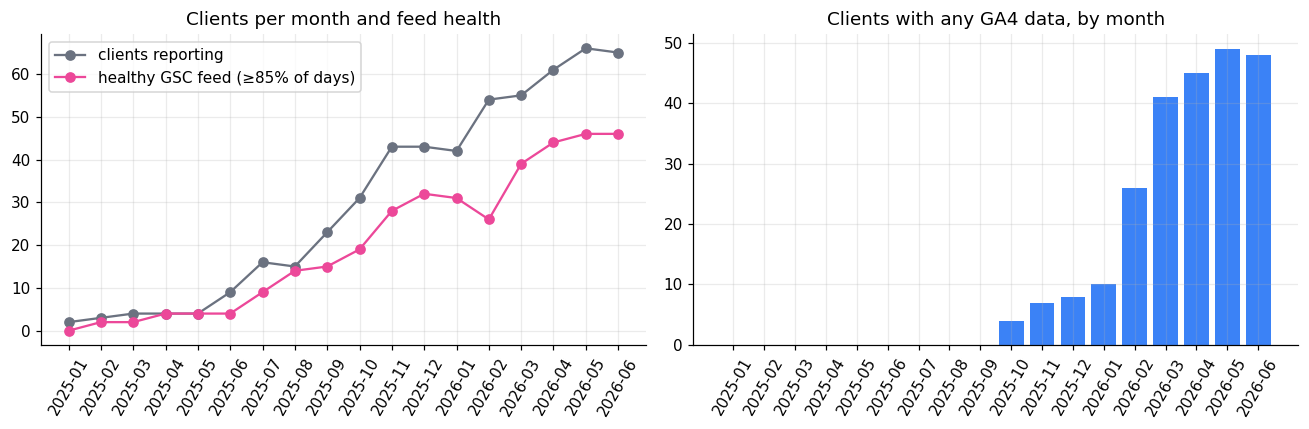

In [6]:
cov_summary = (client_cov.assign(healthy=client_cov["gsc_cov"] >= MIN_CLIENT_COVERAGE,
                                 ga4_any=client_cov["client_ga4_days"] > 0)
               .groupby("month", as_index=False)
               .agg(clients=("client_hash_id", "nunique"), healthy_gsc_clients=("healthy", "sum"),
                    clients_with_ga4=("ga4_any", "sum"), median_gsc_coverage=("gsc_cov", "median")))
cov_summary["healthy_share"] = cov_summary["healthy_gsc_clients"] / cov_summary["clients"]

# Item-level sparsity: do items report on every day, or only on days with impressions?
sparsity = monthly.loc[monthly["gsc_days"] > 0].assign(active_share=lambda d: d["gsc_days"] / d["days_in_month"])
print("Median item-level active-day share (days with a GSC row / days in month):",
      round(float(sparsity["active_share"].median()), 3))
print("  Interpretation: if this is well below 1, GSC emits item-day rows mostly for days with impressions, so a missing\n"
      "  next-month row under a HEALTHY client feed is a true zero (§2.3); if it is close to 1, items report almost daily and\n"
      "  true zeros are rarer. Either way, an UNHEALTHY client feed makes the month unusable as a label.")
display(cov_summary)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(cov_summary["month"], cov_summary["clients"], marker="o", color=PALETTE["Persistence"], label="clients reporting")
ax[0].plot(cov_summary["month"], cov_summary["healthy_gsc_clients"], marker="o", color=PALETTE["accent"],
           label=f"healthy GSC feed (≥{MIN_CLIENT_COVERAGE:.0%} of days)")
ax[0].set_title("Clients per month and feed health"); ax[0].tick_params(axis="x", rotation=60); ax[0].legend()
ax[1].bar(cov_summary["month"], cov_summary["clients_with_ga4"], color=PALETTE["Ridge"])
ax[1].set_title("Clients with any GA4 data, by month"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
savefig("fig01_coverage")

RESULTS["coverage"] = {"min_client_coverage": MIN_CLIENT_COVERAGE,
                       "median_item_active_share": float(sparsity["active_share"].median()),
                       "client_months": int(len(client_cov)),
                       "client_months_healthy": int((client_cov["gsc_cov"] >= MIN_CLIENT_COVERAGE).sum())}

### 2.3 Is the position field trustworthy?

Average position is `gsc_sum_position / impressions` — *if* `gsc_sum_position` is an impression-weighted sum. The warehouse also ships its own `gsc_avg_position`. Both are aggregated per item-month and **cross-checked**:

* If the two **agree** (≥ 95% of rows within one position, on rows where both exist), the sum-based field is used.
* If they **disagree**, the **impression-weighted warehouse average position** is used instead.
* Independently of that choice, rows with **no position reported** (numerator 0) or an **impossible position between 0 and 1** are counted separately and dropped as an explicit data-quality exclusion in §2.4 — they are not evidence that the fields disagree.

This rule is fixed in advance (`POSITION_SOURCE = "auto"`); the decision, its *code* (`agree` / `disagree` / `sparse`) and the evidence are printed and saved.

In [7]:
from scipy.stats import spearmanr

def audit_position_fields(monthly):
    m = monthly.loc[(monthly["gsc_days"] > 0) & (monthly["impressions"] > 0), ["client_hash_id", "impressions", "sum_position", "pos_w"]]
    a = m["sum_position"] / m["impressions"]
    has_w = m["pos_w"] > 0
    b = (m["pos_w"] / m["impressions"]).where(has_w)
    diff = (a - b).abs()
    stats = {"rows": int(len(m)),
             "share_sum_based_below_1": float((a < 0.999).mean()),
             "share_sum_based_zero": float((m["sum_position"] <= 0).mean()),
             "share_sum_based_between_0_and_1": float(((a > 0) & (a < 0.999)).mean()),
             "median_impressions_of_rows_without_position": float(m.loc[m["sum_position"] <= 0, "impressions"].median()) if (m["sum_position"] <= 0).any() else float("nan"),
             "share_weighted_below_1": float((b[has_w] < 0.999).mean()) if has_w.any() else float("nan"),
             "weighted_field_coverage": float(has_w.mean()),
             "median_abs_diff": float(diff[has_w].median()) if has_w.any() else float("nan"),
             "share_within_1_position": float((diff[has_w] <= 1.0).mean()) if has_w.any() else float("nan"),
             "rank_corr": float(spearmanr(a[has_w], b[has_w]).statistic) if has_w.sum() > 10 else float("nan")}
    return stats, m.assign(mismatch=(diff > 1.0) & has_w)


def choose_position_source(stats):
    """Returns (source, code, reason). The reason text matches the code, so it can never contradict the evidence."""
    if POSITION_SOURCE in ("sum", "weighted"):
        return POSITION_SOURCE, "configured", "set in the config cell"
    if not stats["weighted_field_coverage"] >= 0.9:
        return "sum", "sparse", f"the warehouse average-position field covers only {stats['weighted_field_coverage']:.0%} of rows; keeping the sum-based field (inspect manually)"
    if stats["share_within_1_position"] >= 0.95:
        return "sum", "agree", f"the two fields agree on rows where both exist ({stats['share_within_1_position']:.1%} within one position)"
    return "weighted", "disagree", f"the sum-based position is within one position of the warehouse's own average on only {stats['share_within_1_position']:.1%} of rows"


pos_stats, pos_rows = audit_position_fields(monthly)
POS_CHOICE, POS_CODE, POS_REASON = choose_position_source(pos_stats)
display(pd.Series(pos_stats, name="value").to_frame())
mm = (pos_rows.groupby("client_hash_id").agg(rows=("mismatch", "size"), mismatch_share=("mismatch", "mean"))
      .sort_values("mismatch_share", ascending=False))
mm.index = [f"Client {i + 1}" for i in range(len(mm))]            # anonymised, ordered by mismatch
print("Clients with the highest share of rows where the two position fields disagree by > 1:")
display(mm.head(5))
print(f"\nDECISION → position source = '{POS_CHOICE}' (code: {POS_CODE}): {POS_REASON}.")
print(f"Rows with NO position reported (numerator 0): {pos_stats['share_sum_based_zero']:.2%} (median impressions {pos_stats['median_impressions_of_rows_without_position']:,.0f}); "
      f"rows with an impossible position between 0 and 1: {pos_stats['share_sum_based_between_0_and_1']:.2%}  → dropped as a data-quality exclusion in §2.4.")
monthly["sum_position_raw"] = monthly["sum_position"]
if POS_CHOICE == "weighted":
    monthly["sum_position"] = monthly["pos_w"]
RESULTS["position_audit"] = {**pos_stats, "decision": POS_CHOICE, "code": POS_CODE, "reason": POS_REASON,
                             "clients_with_mismatch_over_20pct": int((mm["mismatch_share"] > 0.2).sum())}

,value
rows,"1,546,456.0000"
share_sum_based_below_1,0.0370
share_sum_based_zero,0.0294
share_sum_based_between_0_and_1,0.0076
median_impressions_of_rows_without_position,1.0000
share_weighted_below_1,0.0079
weighted_field_coverage,0.9706
median_abs_diff,0.0000
share_within_1_position,1.0000
rank_corr,1.0000


Clients with the highest share of rows where the two position fields disagree by > 1:


,rows,mismatch_share
Client 1,3634,0.0000
Client 2,374,0.0000
Client 3,153247,0.0000
Client 4,1573,0.0000
Client 5,2089,0.0000



DECISION → position source = 'sum' (code: agree): the two fields agree on rows where both exist (100.0% within one position).
Rows with NO position reported (numerator 0): 2.94% (median impressions 1); rows with an impossible position between 0 and 1: 0.76%  → dropped as a data-quality exclusion in §2.4.


### 2.4 Panel construction, label definition, exclusions ledger and duplicate audit

**Observation row:** an item-month with GSC impressions > 0 in a month whose client feed is healthy.

**Label (target).** `y = log1p(next-month impressions) − log1p(current-month impressions)`, the log change. Two different things can make the next month's impressions zero, and both are tracked:

* the item has **no next-month row** under a healthy client feed (*absent row*), or
* the item **has** a next-month row but with zero GSC impressions (*present-but-zero*, e.g. a GA4-only row).

Both are kept as legitimate zero outcomes (dropping them would silently remove every page that fell out of search) and reported by split. If the client's next-month feed is **unhealthy**, the label is an availability artifact and the row is excluded.

**Implausible rows** are dropped *and broken down by reason* — clicks > impressions; **no position reported** (numerator 0); **impossible position** between 0 and 1; non-finite — with the median impressions of dropped vs. kept rows (a hint of selection bias).

**Duplicated metric blocks.** Two rules, because replication is often *almost* exact:

* **Exact:** ≥ `DUP_MIN_GROUP` items of one client share *identical* impressions, clicks and position (4 decimals) in a month (impressions ≥ `DUP_MIN_IMPR`).
* **Near-duplicate:** ≥ `DUP_NEAR_MIN_GROUP` items of one client-month have impressions within ~1% and positions within 0.1 of each other (impressions ≥ `DUP_NEAR_MIN_IMPR`). Impressions and positions are binned on four offset lattices so a block that straddles a bin edge is still caught.

Metrics replicated across content IDs are not independent observations. Flagged rows are audited — with the **largest blocks printed** so you can verify them by eye — and excluded from modeling and from the queue (`EXCLUDE_DUPLICATE_BLOCKS`).

The release's **final month** has no next month: its rows are never used for training or evaluation, but §6 scores them to produce the *current* queue.

In [8]:
KEYS = ["client_hash_id", "content_hash_id", "month_idx"]
LOOKUP = ["impressions", "clicks", "sum_position"]

# Feature groups (used for the ablation in §4)
G_GSC  = ["log_impr", "log_clicks", "ctr", "avg_position", "active_day_share"]
G_LAGS = ["mom_change", "prev_known", "prev_absent", "ctr_change", "pos_change", "item_age_months"]
G_GA4  = ["log_pageviews", "log_sessions", "log_users", "log_engaged_sessions", "log_engagement_sec", "eng_rate",
          "log_sessions_organic", "log_sessions_direct", "log_sessions_referral", "log_sessions_social",
          "log_sessions_paid", "log_sessions_ai", "log_scroll_events", "ga4_day_share", "has_ga4"]
FEATURES = G_GSC + G_LAGS + G_GA4


def shift_months(df, k):
    out = df.copy()
    out["month_idx"] = out["month_idx"] + k
    return out


def engineer_features(d):
    """Current-month features, lags from the previous month, GA4 block, and the log-change label."""
    d["ctr"] = d["clicks"] / d["impressions"]
    d["avg_position"] = d["sum_position"] / d["impressions"]
    d["active_day_share"] = (d["gsc_days"] / d["days_in_month"]).clip(0, 1)
    d["log_impr"] = np.log1p(d["impressions"])
    d["log_clicks"] = np.log1p(d["clicks"])

    pi = d["prev_impressions"].to_numpy(float)
    known = d["prev_ok"].to_numpy(bool)
    pi0 = np.nan_to_num(pi, nan=0.0)
    safe = np.where(pi0 > 0, pi0, 1.0)
    pos_prev = np.nan_to_num(d["prev_sum_position"].to_numpy(float)) / safe
    ctr_prev = np.nan_to_num(d["prev_clicks"].to_numpy(float)) / safe
    d["prev_known"] = known.astype(int)
    d["prev_absent"] = (known & (pi0 == 0)).astype(int)
    d["mom_change"] = np.where(known, d["log_impr"].to_numpy() - np.log1p(pi0), 0.0)
    d["ctr_change"] = np.where(known & (pi0 > 0), d["ctr"].to_numpy() - ctr_prev, 0.0)
    d["pos_change"] = np.where(known & (pi0 > 0), d["avg_position"].to_numpy() - pos_prev, 0.0)
    d["item_age_months"] = (d["month_idx"] - d["first_idx"]).astype(float)

    for c in GA4_FIELDS:
        d[f"log_{c}"] = np.log1p(d[c])
    d["eng_rate"] = np.where(d["sessions"] > 0, (d["engaged_sessions"] / d["sessions"].where(d["sessions"] > 0, 1.0)).clip(0, 1), 0.0)
    d["ga4_day_share"] = (d["ga4_days"] / d["days_in_month"]).clip(0, 1)
    d["has_ga4"] = (d["ga4_days"] > 0).astype(int)

    # label: log change in impressions (a prediction of 0 == persistence)
    d["y_level"] = np.log1p(d["next_impressions"])
    d["y_delta"] = d["y_level"] - d["log_impr"]
    return d


def flag_exact_duplicates(obs):
    """True for items whose (impressions, clicks, position) are identical to those of >= DUP_MIN_GROUP items of the same client-month."""
    flag = pd.Series(False, index=obs.index)
    big = obs.loc[obs["impressions"] >= DUP_MIN_IMPR, ["client_hash_id", "month_idx", "impressions", "clicks", "avg_position"]].copy()
    big["pos_r"] = big["avg_position"].round(4)
    size = big.groupby(["client_hash_id", "month_idx", "impressions", "clicks", "pos_r"])["impressions"].transform("size")
    flag.loc[big.index] = size >= DUP_MIN_GROUP
    return flag


def flag_near_duplicates(obs):
    """True for items sharing a client-month with >= DUP_NEAR_MIN_GROUP others whose impressions agree within ~DUP_NEAR_REL_TOL (log scale)
    and positions within ~DUP_NEAR_POS_TOL. Four offset lattices catch blocks that straddle a bin edge."""
    flag = pd.Series(False, index=obs.index)
    big = obs.loc[obs["impressions"] >= DUP_NEAR_MIN_IMPR, ["client_hash_id", "month_idx", "impressions", "avg_position"]]
    if big.empty:
        return flag
    li = np.log(big["impressions"].to_numpy(float)) / DUP_NEAR_REL_TOL
    pp = big["avg_position"].to_numpy(float) / DUP_NEAR_POS_TOL
    hit = np.zeros(len(big), bool)
    for oi in (0.0, 0.5):
        for op in (0.0, 0.5):
            key = pd.DataFrame({"c": big["client_hash_id"].to_numpy(), "m": big["month_idx"].to_numpy(),
                                "i": np.floor(li + oi).astype(np.int64), "p": np.floor(pp + op).astype(np.int64)})
            hit |= key.groupby(["c", "m", "i", "p"])["i"].transform("size").to_numpy() >= DUP_NEAR_MIN_GROUP
    flag.loc[big.index] = hit
    return flag


def build_panel(monthly, client_cov, min_cov):
    ledger = {"item_months_total": int(len(monthly))}
    obs = monthly[(monthly["gsc_days"] > 0) & (monthly["impressions"] > 0)].copy()
    ledger["no_gsc_impressions"] = int(len(monthly) - len(obs))
    n0 = len(obs)

    nxt = shift_months(monthly[KEYS + LOOKUP], -1).rename(columns={c: f"next_{c}" for c in LOOKUP})
    prv = shift_months(monthly[KEYS + LOOKUP], +1).rename(columns={c: f"prev_{c}" for c in LOOKUP})
    obs = obs.merge(nxt, on=KEYS, how="left").merge(prv, on=KEYS, how="left")

    ckey = ["client_hash_id", "month_idx"]
    cov = client_cov[ckey + ["gsc_cov"]]
    obs = (obs.merge(cov.rename(columns={"gsc_cov": "cur_cov"}), on=ckey, how="left")
              .merge(shift_months(cov, -1).rename(columns={"gsc_cov": "next_cov"}), on=ckey, how="left")
              .merge(shift_months(cov, +1).rename(columns={"gsc_cov": "prev_cov"}), on=ckey, how="left"))
    assert len(obs) == n0, "join fan-out: keys are not unique"

    first = (monthly[monthly["impressions"] > 0].groupby(["client_hash_id", "content_hash_id"], as_index=False)["month_idx"]
             .min().rename(columns={"month_idx": "first_idx"}))
    obs = obs.merge(first, on=["client_hash_id", "content_hash_id"], how="left")

    obs["is_last_month"] = obs["month_idx"] == LAST_IDX
    obs["cur_ok"] = obs["cur_cov"].fillna(0) >= min_cov
    obs["next_ok"] = (~obs["is_last_month"]) & (obs["next_cov"].fillna(0) >= min_cov)
    obs["prev_ok"] = obs["prev_cov"].fillna(0) >= min_cov
    obs["next_missing"] = obs["next_impressions"].isna()                  # absent row
    for c in LOOKUP:
        obs[f"next_{c}"] = obs[f"next_{c}"].fillna(0.0)                    # absent row + healthy feed == zero
        obs[f"prev_{c}"] = obs[f"prev_{c}"].fillna(0.0).where(obs["prev_ok"])
    obs["label_ok"] = obs["cur_ok"] & obs["next_ok"]
    obs["next_zero"] = obs["label_ok"] & (obs["next_impressions"] == 0)   # absent OR present-but-zero

    obs = engineer_features(obs)

    m_clicks = obs["clicks"] > obs["impressions"]
    m_nopos = obs["sum_position"] <= 0                                          # no position reported at all
    m_pos = (obs["avg_position"] > 0) & (obs["avg_position"] < 0.999)          # impossible position between 0 and 1
    m_other = (obs["clicks"] < 0) | ~np.isfinite(obs["ctr"]) | ~np.isfinite(obs["avg_position"])
    bad = m_clicks | m_nopos | m_pos | m_other
    ledger["invalid_breakdown"] = {"clicks_gt_impressions": int(m_clicks.sum()), "position_missing": int(m_nopos.sum()),
                                   "position_between_0_and_1": int(m_pos.sum()), "position_lt_1": int((m_nopos | m_pos).sum()),
                                   "non_finite_or_negative": int(m_other.sum()), "any_reason": int(bad.sum()),
                                   "median_impressions_dropped": float(obs.loc[bad, "impressions"].median()) if bad.any() else float("nan"),
                                   "median_impressions_kept": float(obs.loc[~bad, "impressions"].median())}
    ledger["invalid_values_dropped"] = int(bad.sum())
    obs = obs.loc[~bad].reset_index(drop=True)

    obs["dup_exact"] = flag_exact_duplicates(obs)
    obs["dup_near"] = flag_near_duplicates(obs)
    obs["dup_block"] = obs["dup_exact"] | obs["dup_near"]
    return obs, ledger


def ledger_counts(obs_all, ledger):
    excl = obs_all["dup_block"] & EXCLUDE_DUPLICATE_BLOCKS
    main = obs_all.loc[~excl]
    ledger["observations"] = int(len(obs_all))
    ledger["duplicate_blocks_excluded"] = int(excl.sum())
    ledger["current_feed_unhealthy"] = int((~main["cur_ok"]).sum())
    ledger["final_month_scoring_only"] = int((main["cur_ok"] & main["is_last_month"]).sum())
    ledger["next_feed_unhealthy"] = int((main["cur_ok"] & ~main["is_last_month"] & ~main["next_ok"]).sum())
    ledger["labeled_rows"] = int(main["label_ok"].sum())
    assert ledger["observations"] == (ledger["duplicate_blocks_excluded"] + ledger["current_feed_unhealthy"] + ledger["final_month_scoring_only"]
                                      + ledger["next_feed_unhealthy"] + ledger["labeled_rows"]), "ledger does not reconcile"
    ledger["labeled_zero_target"] = int(main["next_zero"].sum())
    ledger["labeled_absent_next_row"] = int((main["label_ok"] & main["next_missing"]).sum())
    return main.reset_index(drop=True)


panel_all, ledger = build_panel(monthly, client_cov, MIN_CLIENT_COVERAGE)
panel = ledger_counts(panel_all, ledger)
assert not panel.loc[panel["cur_ok"], FEATURES].isna().any().any(), "NaN in features"
assert np.isfinite(panel.loc[panel["cur_ok"], FEATURES].to_numpy(float)).all(), "non-finite feature"
RESULTS["ledger"] = ledger

ledger_df = pd.DataFrame([
    ("Item-months in the release", ledger["item_months_total"]),
    ("− without GSC impressions (not an observation)", -ledger["no_gsc_impressions"]),
    ("− implausible values (see breakdown below)", -ledger["invalid_values_dropped"]),
    ("= Observations", ledger["observations"]),
    ("− duplicated metric blocks" + ("" if EXCLUDE_DUPLICATE_BLOCKS else " (flagged, NOT excluded)"), -ledger["duplicate_blocks_excluded"]),
    ("− current-month client feed unhealthy", -ledger["current_feed_unhealthy"]),
    (f"− final month ({LAST_MONTH}): no next month; scored in §6 only", -ledger["final_month_scoring_only"]),
    ("− next-month client feed unhealthy", -ledger["next_feed_unhealthy"]),
    ("= Labeled rows (modeling set)", ledger["labeled_rows"]),
    ("   of which: zero next-month impressions (absent row + present-but-zero)", ledger["labeled_zero_target"]),
    ("      of which: item absent next month", ledger["labeled_absent_next_row"]),
], columns=["step", "rows"])
display(ledger_df)

ib = ledger["invalid_breakdown"]
display(pd.DataFrame({"reason (non-exclusive)": ["clicks > impressions", "no position reported (numerator 0)", "impossible position (between 0 and 1)",
                                                   "non-finite / negative", "ANY (exclusive total)"],
                      "rows": [ib["clicks_gt_impressions"], ib["position_missing"], ib["position_between_0_and_1"], ib["non_finite_or_negative"], ib["any_reason"]]}))
print(f"Median impressions — dropped rows: {ib['median_impressions_dropped']:,.0f} | kept rows: {ib['median_impressions_kept']:,.0f}"
      "  (a large gap would mean the filter is removing a particular kind of item).")

# ---- duplicate-block audit (all flagged rows, whether or not excluded)
dups = panel_all[panel_all["dup_block"]]
by_m = (panel_all.groupby("month").agg(observations=("impressions", "size"), total_impressions=("impressions", "sum"))
        .join(dups.groupby("month").agg(flagged_rows=("impressions", "size"), flagged_impressions=("impressions", "sum")), how="left").fillna(0))
by_m["share_of_rows"] = by_m["flagged_rows"] / by_m["observations"]
by_m["share_of_impressions"] = by_m["flagged_impressions"] / by_m["total_impressions"]
print(f"\nDuplicated-metric blocks flagged: {len(dups):,} rows ({len(dups) / len(panel_all):.2%} of observations) — "
      f"exact rule: {int(panel_all['dup_exact'].sum()):,}; near-duplicate rule: {int(panel_all['dup_near'].sum()):,}; "
      f"caught ONLY by the near rule: {int((panel_all['dup_near'] & ~panel_all['dup_exact']).sum()):,}")
display(by_m.loc[by_m["flagged_rows"] > 0, ["flagged_rows", "share_of_rows", "share_of_impressions"]])
rank_by_size = panel_all["client_hash_id"].value_counts().index
anon_all = {cid: f"Client {i + 1}" for i, cid in enumerate(rank_by_size)}
dup_clients = dups["client_hash_id"].map(anon_all).value_counts(normalize=True).head(5).rename("share_of_flagged_rows")
if len(dups):
    display(dup_clients.to_frame())
    # the largest flagged blocks, printed so they can be verified by eye (anonymised client labels, no content identifiers)
    top_blocks = (dups.groupby(["client_hash_id", "month"])
                  .agg(flagged_items=("impressions", "size"), impressions_min=("impressions", "min"), impressions_max=("impressions", "max"),
                       position_min=("avg_position", "min"), position_max=("avg_position", "max")).reset_index()
                  .sort_values("flagged_items", ascending=False).head(8))
    top_blocks["client"] = top_blocks["client_hash_id"].map(anon_all)
    top_blocks = top_blocks[["client", "month", "flagged_items", "impressions_min", "impressions_max", "position_min", "position_max"]].reset_index(drop=True)
    print("Largest flagged client-months (verify these by eye; a client-month can hold more than one block):")
    display(top_blocks)
lab_pa = panel_all[panel_all["label_ok"]]
zero_dup = float(lab_pa.loc[lab_pa["dup_block"], "next_zero"].mean()) if lab_pa["dup_block"].any() else float("nan")
zero_non = float(lab_pa.loc[~lab_pa["dup_block"], "next_zero"].mean())
print(f"Share of zero next-month labels — duplicated blocks: {zero_dup:.1%} | all other rows: {zero_non:.1%}")
RESULTS["duplicates"] = {"flagged_rows": int(len(dups)), "share_of_observations": float(len(dups) / len(panel_all)),
                         "excluded": EXCLUDE_DUPLICATE_BLOCKS, "zero_label_share_in_blocks": zero_dup, "zero_label_share_elsewhere": zero_non,
                         "clients_affected": int(dups["client_hash_id"].nunique()),
                         "exact_rows": int(panel_all["dup_exact"].sum()), "near_rows": int(panel_all["dup_near"].sum()),
                         "near_only_rows": int((panel_all["dup_near"] & ~panel_all["dup_exact"]).sum()),
                         "largest_block_items": int(top_blocks["flagged_items"].iloc[0]) if len(dups) else 0,
                         "top_client_share_of_flagged": float(dup_clients.iloc[0]) if len(dups) else 0.0}

# Release temporary duplicate-audit copies after all audit statistics are recorded.
del panel_all, dups, lab_pa, rank_by_size, anon_all
if "dup_clients" in globals(): del dup_clients
if "top_blocks" in globals(): del top_blocks
gc.collect()
print("Released temporary panel and duplicate-audit copies.")

if "client_cov" in globals():
    del client_cov
gc.collect()


,step,rows
0,Item-months in the release,2871202
1,− without GSC impressions (not an observation),-1324746
2,− implausible values (see breakdown below),-57253
3,= Observations,1489203
4,− duplicated metric blocks,-6122
5,− current-month client feed unhealthy,-65867
6,− final month (2026-06): no next month; scored...,-194174
7,− next-month client feed unhealthy,-14358
8,= Labeled rows (modeling set),1208682
9,of which: zero next-month impressions (abse...,110674


,reason (non-exclusive),rows
0,clicks > impressions,0
1,no position reported (numerator 0),45431
2,impossible position (between 0 and 1),11822
3,non-finite / negative,0
4,ANY (exclusive total),57253


Median impressions — dropped rows: 1 | kept rows: 118  (a large gap would mean the filter is removing a particular kind of item).

Duplicated-metric blocks flagged: 6,122 rows (0.41% of observations) — exact rule: 5,424; near-duplicate rule: 5,934; caught ONLY by the near rule: 698


,flagged_rows,share_of_rows,share_of_impressions
month,,,
2025-11,795.0000,0.0082,0.0508
2025-12,833.0000,0.0078,0.1365
2026-01,833.0000,0.0070,0.0451
2026-02,833.0000,0.0056,0.0117
2026-03,858.0000,0.0049,0.0151
2026-04,839.0000,0.0043,0.0454
2026-05,764.0000,0.0037,0.0132
2026-06,367.0000,0.0018,0.0093


,share_of_flagged_rows
client_hash_id,
Client 3,0.9178
Client 22,0.0343
Client 2,0.0232
Client 40,0.0136
Client 1,0.0046


Largest flagged client-months (verify these by eye; a client-month can hold more than one block):


,client,month,flagged_items,impressions_min,impressions_max,position_min,position_max
0,Client 3,2025-12,833,"18,183.0000","18,183.0000",6.2430,6.2430
1,Client 3,2026-01,833,"7,694.0000","7,694.0000",6.8417,6.8417
2,Client 3,2026-03,833,"4,991.0000","4,991.0000",6.3586,6.3586
3,Client 3,2026-02,833,"2,482.0000","2,482.0000",7.3662,7.3662
4,Client 3,2026-04,833,"15,860.0000","15,860.0000",5.2896,5.2896
5,Client 3,2025-11,795,"5,284.0000","5,370.0000",4.5547,4.8017
6,Client 3,2026-05,659,"5,219.0000","5,585.0000",5.3527,6.6969
7,Client 2,2026-06,129,"8,584.0000","8,584.0000",4.8442,4.8442


Share of zero next-month labels — duplicated blocks: 4.0% | all other rows: 9.2%
Released temporary panel and duplicate-audit copies.


0

### 2.5 Chronological splits and what each split looks like

Labeled rows outside the configured splits: 0


,split,months,rows,clients,share_rows_unseen_clients,share_rows_with_ga4,share_zero_impression_labels,share_absent_next_row,median_impressions
0,train,2025-01 → 2025-12,416675,31,0.0000,0.0789,0.0909,0.0255,93.0000
1,validation,2026-01 → 2026-03,402754,39,0.1018,0.2835,0.0882,0.0000,155.0000
2,test,2026-04 → 2026-05,389253,46,0.2681,0.5015,0.0957,0.0000,140.0000


,split,zero_label_share,of_which_absent_row,of_which_present_but_zero,clients_with_zero_labels,top_client_share_of_zeros
0,train,0.0909,0.0255,0.0655,31,0.1787
1,validation,0.0882,0.0000,0.0882,38,0.3795
2,test,0.0957,0.0000,0.0957,42,0.1375


Share of training rows in its final 3 months: 61.0%
GA4 coverage — train: 7.9%  |  test: 50.1%


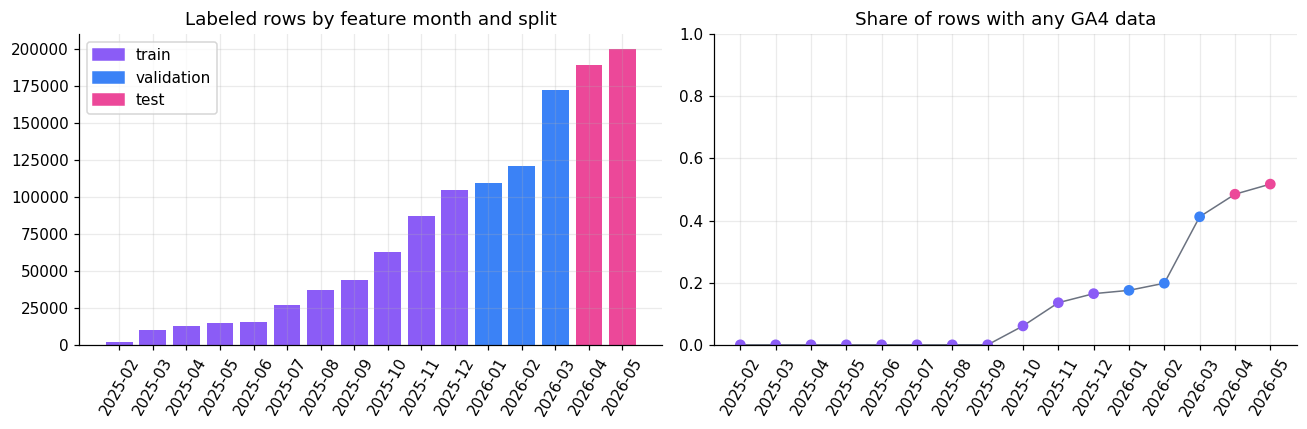

Retained 194,174 final-month scoring rows in panel; historical splits remain unchanged in D.
Compacted shared lab frame to 33 columns; split-specific D frames are unchanged.


In [9]:
split_of = {m: s for s, ms in SPLITS.items() for m in ms}
panel["split"] = panel["month"].astype(str).map(split_of).fillna("unassigned")

for s, ms in SPLITS.items():
    absent = [m for m in ms if m not in set(monthly["month"].astype(str))]
    assert not absent, f"{s}: months not in release: {absent}"

# ---- pooled CTR-by-position prior + peer-relative expected CTR (§2.6) are attached to `panel` BEFORE the split tables
def bucket_of(pos, max_pos=50):
    return np.clip(np.floor(np.asarray(pos, float)), 1, max_pos).astype(int)


from sklearn.isotonic import IsotonicRegression

def fit_prior_curve(df, max_pos=50):
    """Pooled CTR by integer position: the MEDIAN ACROSS CLIENTS (each client weighted equally, so one giant client cannot dominate),
    forced monotone non-increasing by isotonic regression."""
    d = pd.DataFrame({"client": df["client_hash_id"].to_numpy(), "b": bucket_of(df["avg_position"], max_pos),
                      "clicks": df["clicks"].to_numpy(), "impr": df["impressions"].to_numpy()})
    cb_all = d.groupby(["client", "b"], as_index=False)[["clicks", "impr"]].sum()
    for min_impr in (MIN_BUCKET_IMPR, 1_000, 100, 0):
        cb = cb_all[cb_all["impr"] >= max(min_impr, 1)].copy()
        cb["ctr"] = cb["clicks"] / cb["impr"]
        stats = cb.groupby("b")["ctr"].agg(median="median", n_clients="size").reindex(range(1, max_pos + 1))
        if stats["median"].notna().sum() >= 5:
            break
    vals = stats["median"].interpolate(limit_direction="both")
    w = stats["n_clients"].fillna(1).clip(lower=1)
    iso = IsotonicRegression(increasing=False, out_of_bounds="clip").fit(np.arange(1, max_pos + 1), vals.to_numpy(), sample_weight=w.to_numpy())
    curve = pd.Series(iso.predict(np.arange(1, max_pos + 1)), index=range(1, max_pos + 1), name="prior_ctr")
    return curve, stats["n_clients"].fillna(0).astype(int), cb


def peer_expected_ctr(df, prior, strength=CTR_PRIOR_STRENGTH):
    """Expected CTR of each item = CTR of the SAME client's OTHER items at the same position bucket in the SAME month
    (leave-one-out), shrunk toward the pooled prior. Uses only information available at the end of the observation month."""
    b = bucket_of(df["avg_position"])
    tmp = pd.DataFrame({"client": df["client_hash_id"].to_numpy(), "m": df["month_idx"].to_numpy(), "b": b,
                        "clicks": df["clicks"].to_numpy(), "impr": df["impressions"].to_numpy()})
    tot = tmp.groupby(["client", "m", "b"])[["clicks", "impr"]].transform("sum")
    loo_c, loo_i = tot["clicks"].to_numpy() - tmp["clicks"].to_numpy(), tot["impr"].to_numpy() - tmp["impr"].to_numpy()
    pri = prior.reindex(b).to_numpy()
    return (loo_c + strength * pri) / (loo_i + strength)


is_train = (panel["split"] == "train") & panel["cur_ok"]
BENCH_PRIOR, BENCH_NCLIENTS, BENCH_CB = fit_prior_curve(panel[is_train])
panel["expected_ctr"] = peer_expected_ctr(panel, BENCH_PRIOR)

lab = panel[panel["label_ok"] & panel["split"].isin(list(SPLITS))].reset_index(drop=True)
stray = int((panel["label_ok"] & (panel["split"] == "unassigned")).sum())
print(f"Labeled rows outside the configured splits: {stray:,}" + ("  (months not assigned to any split)" if stray else ""))

D = {s: lab[lab["split"] == s].reset_index(drop=True) for s in SPLITS}
train_clients = set(D["train"]["client_hash_id"])
for s in SPLITS:
    D[s]["seen_client"] = D[s]["client_hash_id"].isin(train_clients)

split_table = pd.DataFrame([{
    "split": s, "months": f"{min(SPLITS[s])} → {max(SPLITS[s])}", "rows": len(D[s]),
    "clients": D[s]["client_hash_id"].nunique(),
    "share_rows_unseen_clients": 1 - D[s]["seen_client"].mean(),
    "share_rows_with_ga4": D[s]["has_ga4"].mean(),
    "share_zero_impression_labels": D[s]["next_zero"].mean(),
    "share_absent_next_row": D[s]["next_missing"].mean(),
    "median_impressions": D[s]["impressions"].median()} for s in SPLITS])
display(split_table)
RESULTS["splits"] = split_table.to_dict(orient="records")

# zero-target audit by split: how many are "present-but-zero", and are they concentrated in a few clients?
zrows = []
for s in SPLITS:
    z = D[s][D[s]["next_zero"]]
    top = z["client_hash_id"].value_counts(normalize=True)
    zrows.append({"split": s, "zero_label_share": D[s]["next_zero"].mean(), "of_which_absent_row": float(D[s]["next_missing"].mean()),
                  "of_which_present_but_zero": float(D[s]["next_zero"].mean() - D[s]["next_missing"].mean()),
                  "clients_with_zero_labels": int(z["client_hash_id"].nunique()),
                  "top_client_share_of_zeros": float(top.iloc[0]) if len(top) else 0.0})
zero_df = pd.DataFrame(zrows)
display(zero_df)
RESULTS["zero_targets"] = zero_df.to_dict(orient="records")

tr = D["train"]
last3 = sorted(SPLITS["train"])[-3:]
RESULTS["train_composition"] = {
    "share_rows_in_last_3_train_months": float(tr["month"].astype(str).isin(last3).mean()),
    "share_train_rows_with_ga4": float(tr["has_ga4"].mean()),
    "share_test_rows_with_ga4": float(D["test"]["has_ga4"].mean())}
print(f"Share of training rows in its final 3 months: {RESULTS['train_composition']['share_rows_in_last_3_train_months']:.1%}")
print(f"GA4 coverage — train: {RESULTS['train_composition']['share_train_rows_with_ga4']:.1%}  |  test: {RESULTS['train_composition']['share_test_rows_with_ga4']:.1%}")

comp = (lab.groupby(["month", "split"], as_index=False).agg(rows=("log_impr", "size"), ga4=("has_ga4", "mean"))
        .assign(month=lambda d: d["month"].astype(str)).sort_values("month").reset_index(drop=True))
split_colors = {"train": "#8B5CF6", "validation": "#3B82F6", "test": "#EC4899"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xpos = np.arange(len(comp))
ax[0].bar(xpos, comp["rows"], color=[split_colors[s] for s in comp["split"]])
ax[1].plot(xpos, comp["ga4"], color="#6B7280", lw=1, zorder=1)
ax[1].scatter(xpos, comp["ga4"], c=[split_colors[s] for s in comp["split"]], zorder=2)
for a_, ttl in zip(ax, ["Labeled rows by feature month and split", "Share of rows with any GA4 data"]):
    a_.set_xticks(xpos); a_.set_xticklabels(comp["month"], rotation=60); a_.set_title(ttl)
ax[1].set_ylim(0, 1)
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=c_, label=s_) for s_, c_ in split_colors.items()])
plt.tight_layout()
savefig("fig02_split_composition")

# Keep full historical observations in D; panel is only needed for final-month scoring later.
panel = panel.loc[panel["is_last_month"] & panel["cur_ok"]].copy()
gc.collect()
print(f"Retained {len(panel):,} final-month scoring rows in panel; historical splits remain unchanged in D.")


# Keep only fields used by later regime diagnostics and walk-forward fitting in the
# combined `lab` frame. The full split-specific DataFrames D remain untouched.
LAB_KEEP = list(dict.fromkeys(FEATURES + [
    "month", "month_idx", "y_delta", "client_hash_id",
    "impressions", "next_impressions", "next_zero"
]))
lab = lab[LAB_KEEP].copy()
gc.collect()
print(f"Compacted shared lab frame to {len(LAB_KEEP)} columns; split-specific D frames are unchanged.")


### 2.6 Expected CTR — a peer benchmark, sanity-checked before it is trusted

"Missed clicks" needs an *expected CTR* for an item at its position. A single pooled curve can be dominated by one or two huge clients, so two safeguards are used:

1. A **pooled prior**: CTR by integer position bucket as the **median across clients** (each client counts once; buckets need ≥ `MIN_BUCKET_IMPR` impressions per client), made monotone with isotonic regression, from **training months only**.
2. A **peer expectation** per item: the CTR of the *same client's other items* at the same position bucket in the *same month* (leave-one-out, shrunk toward the prior with `CTR_PRIOR_STRENGTH` pseudo-impressions). This asks the question a content team actually cares about — *"is this page getting fewer clicks than the site's other pages at the same rank?"* — and cannot be distorted by cross-client differences in brand mix or SERP features.

**Sanity checks printed below.** (i) The pooled curve should fall steeply with position (position-1 CTR several times position-10 CTR, and in the tens of percent for organic web search). (ii) Within a client-month, expected clicks must match actual clicks (calibration ≈ 1). If (i) fails, the position/click fields may not behave like standard web-search metrics: the *peer-relative* ranking remains usable, but "missed clicks" must **not** be read as clicks relative to a typical SERP.

,position,pooled_prior_CTR,clients_in_bucket
0,1,0.0058,11
1,2,0.0058,13
2,3,0.0058,15
3,5,0.0058,18
4,10,0.0034,15
5,20,0.0023,11
6,30,0.0016,10
7,50,0.0003,16


CTR@1 = 0.58%, CTR@3 = 0.58%, CTR@10 = 0.34%; CTR@1 / CTR@10 = 1.7×
Pooled-curve plausibility: NOT PLAUSIBLE — treat 'missed clicks' as peer-relative only (see §7)
Calibration (expected clicks / actual clicks, within client-month): {'train': 0.998, 'validation': 1.0, 'test': 1.003}


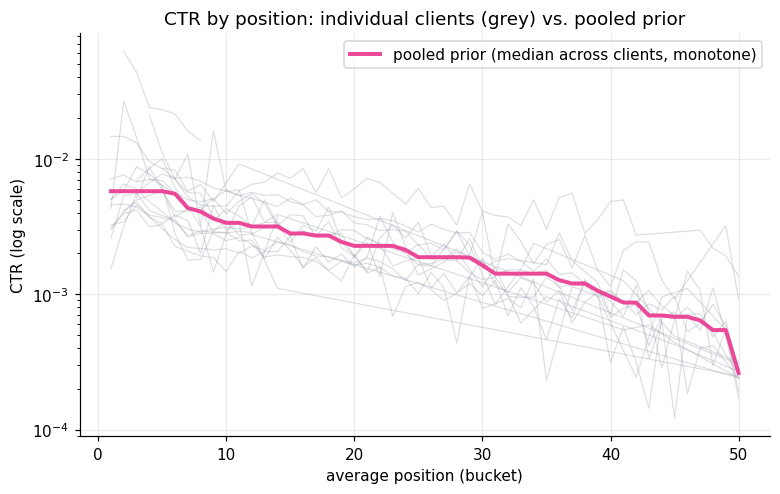

In [10]:
pts = [1, 2, 3, 5, 10, 20, 30, 50]
bench_tbl = pd.DataFrame({"position": pts, "pooled_prior_CTR": [float(BENCH_PRIOR[p]) for p in pts],
                          "clients_in_bucket": [int(BENCH_NCLIENTS[p]) for p in pts]})
display(bench_tbl)
ctr1, ctr3, ctr10 = float(BENCH_PRIOR[1]), float(BENCH_PRIOR[3]), float(BENCH_PRIOR[10])
bench_plausible = bool(ctr1 >= 0.03 and ctr1 >= 3 * ctr10)
print(f"CTR@1 = {ctr1:.2%}, CTR@3 = {ctr3:.2%}, CTR@10 = {ctr10:.2%}; CTR@1 / CTR@10 = {ctr1 / max(ctr10, 1e-12):.1f}×")
print("Pooled-curve plausibility:", "PLAUSIBLE" if bench_plausible else
      "NOT PLAUSIBLE — treat 'missed clicks' as peer-relative only (see §7)")

calib = {}
for s in list(SPLITS):
    d = D[s]
    calib[s] = float((d["expected_ctr"] * d["impressions"]).sum() / max(d["clicks"].sum(), 1e-9))
print("Calibration (expected clicks / actual clicks, within client-month):", {k: round(v, 3) for k, v in calib.items()})
RESULTS["benchmark"] = {"prior_at_positions": {int(p): float(BENCH_PRIOR[p]) for p in pts}, "plausible": bench_plausible,
                        "ctr1_over_ctr10": float(ctr1 / max(ctr10, 1e-12)), "calibration": calib,
                        "prior_strength": CTR_PRIOR_STRENGTH, "min_bucket_impressions": MIN_BUCKET_IMPR}

fig, ax = plt.subplots(figsize=(7.2, 4.6))
cl = BENCH_CB.groupby("client").filter(lambda g: len(g) >= 4)
for _, g in list(cl.groupby("client"))[:40]:
    g = g.sort_values("b")
    ax.plot(g["b"], g["ctr"], color="#9CA3AF", alpha=0.35, lw=0.8)
ax.plot(BENCH_PRIOR.index, BENCH_PRIOR.values, color=PALETTE["accent"], lw=2.6, label="pooled prior (median across clients, monotone)")
ax.set_yscale("log"); ax.set_xlabel("average position (bucket)"); ax.set_ylabel("CTR (log scale)")
ax.set_title("CTR by position: individual clients (grey) vs. pooled prior"); ax.legend()
plt.tight_layout()
savefig("fig12_ctr_benchmark")

### 2.7 Is the panel stationary? A market-wide regime diagnostic

A model trained on one regime and tested on another will look unskilled whatever its features. For every feature month the diagnostic reports, over the **same items** in month *t* and *t+1*:

* the **portfolio log change** `log(Σ impressions_{t+1} / Σ impressions_t)`,
* the **share of items that fell**, and the **median item change**.

If these differ sharply between training and test months, errors are dominated by the regime, not by item-level signal, and any model that learned the training regime will carry a persistent bias.

,month,split,items,clients,portfolio_log_change,median_item_change,share_fell,share_zero_label
0,2025-02,train,1616,1,0.9456,0.7479,0.0668,0.0031
1,2025-03,train,10046,2,0.7378,0.6931,0.2639,0.0266
2,2025-04,train,13013,4,0.4730,0.3194,0.2706,0.0325
3,2025-05,train,14837,4,0.1173,-0.1439,0.5848,0.0618
4,2025-06,train,15240,4,0.0307,-0.1001,0.5536,0.0877
5,2025-07,train,27033,9,0.2574,0.1427,0.4098,0.0694
6,2025-08,train,36787,14,0.0929,-0.2425,0.6033,0.0869
7,2025-09,train,43751,15,0.2232,0.0757,0.4448,0.0726
8,2025-10,train,62429,18,0.2406,0.2196,0.3595,0.0934
9,2025-11,train,86973,28,0.1136,0.0541,0.4423,0.1107


,mean_portfolio_log_change,mean_share_fell,mean_median_item_change
split,,,
train,0.3226,0.3993,0.1765
validation,0.1469,0.4750,0.0044
test,-0.1829,0.6957,-0.4627


Share of items falling: test − train = +29.6%  →  REGIME SHIFT between training and test months.


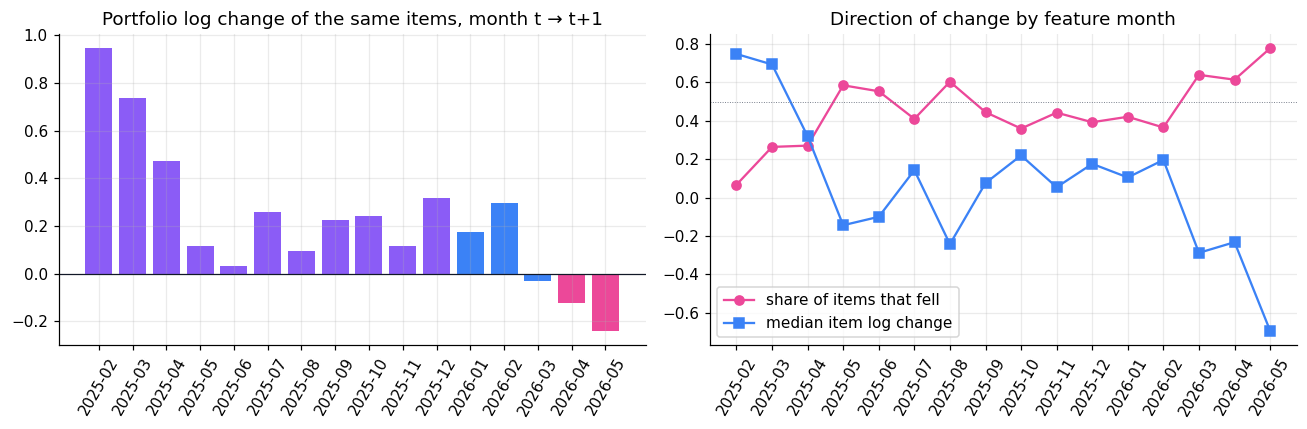

In [11]:
reg = (lab.assign(month=lab["month"].astype(str)).groupby("month")
       .agg(items=("y_delta", "size"), clients=("client_hash_id", "nunique"), impr=("impressions", "sum"), next_impr=("next_impressions", "sum"),
            median_item_change=("y_delta", "median"), share_fell=("y_delta", lambda s: float((s < 0).mean())),
            share_zero_label=("next_zero", "mean")).reset_index())
reg["portfolio_log_change"] = np.log(reg["next_impr"] / reg["impr"])
reg["split"] = reg["month"].map(split_of)
display(reg[["month", "split", "items", "clients", "portfolio_log_change", "median_item_change", "share_fell", "share_zero_label"]])

reg_split = reg.groupby("split").agg(mean_portfolio_log_change=("portfolio_log_change", "mean"), mean_share_fell=("share_fell", "mean"),
                                     mean_median_item_change=("median_item_change", "mean")).reindex(list(SPLITS))
display(reg_split)
shift_gap = float(reg_split.loc["test", "mean_share_fell"] - reg_split.loc["train", "mean_share_fell"])
regime_shift = abs(shift_gap) >= 0.15
print(f"Share of items falling: test − train = {shift_gap:+.1%}  →  " + ("REGIME SHIFT between training and test months." if regime_shift else "no large regime shift."))
RESULTS["regime"] = {"by_split": reg_split.reset_index().to_dict(orient="records"), "share_fell_gap_test_minus_train": shift_gap,
                     "shift_flag": bool(regime_shift), "by_month": reg[["month", "split", "portfolio_log_change", "share_fell", "median_item_change"]].to_dict(orient="records")}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xr = np.arange(len(reg))
ax[0].bar(xr, reg["portfolio_log_change"], color=[split_colors[s] for s in reg["split"]])
ax[0].axhline(0, color=PALETTE["ink"], lw=0.8)
ax[0].set_title("Portfolio log change of the same items, month t → t+1")
ax[1].plot(xr, reg["share_fell"], marker="o", color=PALETTE["accent"], label="share of items that fell")
ax[1].plot(xr, reg["median_item_change"], marker="s", color=PALETTE["Ridge"], label="median item log change")
ax[1].axhline(0.5, color=PALETTE["Persistence"], lw=0.6, ls=":")
ax[1].set_title("Direction of change by feature month"); ax[1].legend()
for a_ in ax:
    a_.set_xticks(xr); a_.set_xticklabels(reg["month"], rotation=60)
plt.tight_layout()
savefig("fig13_regime")

### 2.8 What the audit means for modeling

* **Position, zeros, duplicates and the benchmark were checked, not assumed.** The decisions (position source, duplicate exclusion, peer-based CTR expectation) and their evidence are printed above and saved to `RESULTS`.
* **GA4 is not present uniformly over time.** The share of training rows with any GA4 data is far below the test share, so GA4/engagement features are mostly zeros in training; GA4 findings describe *this release*, not GA4.
* **The panel is unbalanced across time and clients, and may be non-stationary.** §4 reports seen-vs-unseen clients, per-client macro averages and an explicit **market-trend baseline** so that a regime shift cannot masquerade as model error or model skill.
* **Zero outcomes are kept** (absent *and* present-but-zero rows), and §4 reports results with and without them.

# RESEARCH PILLAR 1
## **Ranking Signal Analysis**
### *Which search and engagement signals help explain and predict changes in search performance?*

## 3. Methodology

### 3.1 Data assumptions, target and feature engineering

A client-month is usable only when its GSC feed meets the configured coverage rule. A missing next-month item row under a healthy client feed is treated as zero impressions; an unhealthy next-month feed produces an unavailable label, not a presumed decline. Duplicate metric blocks are treated as replicated observations and excluded under the pre-set rule.

The target is `y_delta = log1p(next impressions) − log1p(current impressions)`. Prediction error on this change scale is equivalent to error on the next-month log level after adding the known current-month offset. The unchanged feature matrix contains 5 GSC features, 6 lag/history features and 15 GA4 / traffic-source features. The existing feature names, engineering rules and leakage assertions remain in force.

### 3.2 Forecast baselines and candidate regressors

**Original baselines retained unchanged:** persistence (`Δ = 0`); trailing-market median change using the previous feature month; training-median change; training-median level; training-decile median change by current impressions; and Ridge on standardized features.

**Candidate regressors:** XGBoost (existing validation grid and early stopping), Random Forest (existing regularized configuration), CatBoost (MAE objective with validation early stopping), and LightGBM (L1 objective with validation early stopping). CatBoost and LightGBM are additive challengers: they do not change the target, row eligibility, feature columns or chronological split. The primary model is the candidate with the lowest validation MAE. All candidate models and baselines are then reported on the identical test rows.

### 3.3 Chronological validation and uncertainty

Feature-month splits remain: train January–December 2025; validation January–March 2026; test April–May 2026. A forecast made after month *t* uses only features available through *t* and labels already resolved before the next forecast window. Client-clustered bootstrap confidence intervals resample whole clients (the original 1,000-replicate protocol is retained). Paired MAE differences use identical rows and client resamples.

A complementary client-level sign-flip test evaluates the mean per-client paired MAE difference. Holm adjustment controls family-wise error across the planned model-versus-persistence and model-versus-trend comparisons. The pooled row-weighted estimand and the equal-client estimand are labelled separately; they answer different operational questions.

### 3.4 Leakage controls and experimental integrity

Identifiers, target fields and `next_*` columns are excluded from features. The notebook asserts walk-forward timing, runs a shuffled-label canary, checks finite feature values and reports the strongest single-feature target correlation. Validation is used for model selection and early stopping; test outcomes are not used to choose primary model hyperparameters.

### 3.5 Unsupervised archetype design

K-means remains the primary clustering reference, using the original five transformed performance features and a scaler fitted only to training, non-micro-volume rows. A GMM with diagonal covariance is added as a challenger. GMM component count is chosen using training-only minimum cluster share, agreement on a separate training holdout and held-out-within-training log likelihood; BIC is recorded as a fit diagnostic rather than used alone as proof of cluster quality. Test rows are projected into the already-fitted scaler and cluster models; no test outcomes enter cluster fitting or component selection.

Items below the existing impression threshold remain a distinct micro-volume monitoring bucket. This bucket is not described as an unsupervised cluster. Cluster quality uses silhouette on a random held-out sample and stability uses adjusted Rand index across disjoint training subsamples.

### 3.6 Outcome tests for archetypes

For each clustering method, the analysis reports test-set η² for next-month change, a within-client-month permutation p-value (outcomes are permuted only within each client × feature-month stratum, preserving both client-specific distributions and monthly market shocks), and a cluster-median forecast trained only on the train split. That forecast is paired against persistence and the trailing-market baseline using the existing client-clustered bootstrap. The primary K-means gate requires pre-set training stability and minimum-size criteria, test silhouette ≥ 0.10, η² ≥ 0.02, Holm-adjusted within-client-month permutation p < 0.01, and a cluster-median forecast that beats both baselines. GMM is judged against the same criteria but is a sensitivity challenger; test performance is not used to switch the queue's clustering method.

### 3.7 Incremental value of archetype indicators

A secondary post-hoc experiment appends one-hot K-means or GMM membership indicators to the unchanged continuous feature set and fits XGBoost using the already-selected XGBoost configuration and validation early stopping. The question is whether cluster membership adds predictive information beyond the continuous inputs. These experiments are reported separately, cannot change the primary model selection or operational queue, and are explicitly labelled exploratory because they were designed after the original test evaluation.

### 3.8 Practical application and visual evidence

The per-client queue is evaluated on realized next-month outcomes against persistence, a market-trend-only forecast, current impressions and the alternative base model. **Per-client macro capture@10% is the primary client-generalization view**: each eligible client-month contributes equally, and uncertainty is estimated by resampling whole clients. **Pooled global capture@10% is the secondary total-exposure view**, because large clients contribute more rows and more total opportunity. Both views are compared with persistence, the market-trend-only forecast and current-impression ranking. Figures are placed beside the calculations they explain: paired forecast differences near the model comparison, feature-group ablation near the signal analysis, archetype profiles/PCA/radar near clustering description, and cluster-outcome/augmentation evidence beside the new outcome tests.

In [12]:
from xgboost import XGBRegressor

def assert_walk_forward(splits):
    """Training labels (month t+1) must be resolved by the first feature month of every later split."""
    order = ["train", "validation", "test"]
    for a, b in zip(order, order[1:]):
        last_label_a = max(month_idx(m) for m in splits[a]) + 1
        first_feature_b = min(month_idx(m) for m in splits[b])
        assert last_label_a <= first_feature_b, f"{a} labels ({last_label_a}) not resolved before {b} starts ({first_feature_b})"
    all_months = [m for s in order for m in splits[s]]
    assert len(all_months) == len(set(all_months)), "a month appears in two splits"
    assert max(month_idx(m) for m in splits["test"]) + 1 <= LAST_IDX, "test label month is beyond the release"

tests = []
assert_walk_forward(SPLITS); tests.append(("Walk-forward timing: labels resolved before next split begins", "PASS"))

forbidden = set(ID_COLS) | {"month", "month_idx", "split", "y_delta", "y_level", "next_zero", "next_missing", "dup_block", "expected_ctr"}
bad_feats = [f for f in FEATURES if f in forbidden or f.startswith("next_") or "next" in f.split("_")]
assert not bad_feats, f"forbidden columns used as features: {bad_feats}"
tests.append(("No identifiers, label, next_* or benchmark column among features", "PASS"))

rs = np.random.default_rng(SEED)
canary = XGBRegressor(n_estimators=150, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=2, random_state=SEED)
canary.fit(D["train"][FEATURES], rs.permutation(D["train"]["y_delta"].to_numpy()))
canary_mae = float(np.abs(canary.predict(D["validation"][FEATURES]) - D["validation"]["y_delta"]).mean())
const_mae = float(np.abs(D["train"]["y_delta"].median() - D["validation"]["y_delta"]).mean())
assert canary_mae > 0.98 * const_mae, "canary beat the constant by >2%: possible leakage or bug"
tests.append((f"Shuffled-label canary cannot beat constant (canary {canary_mae:.3f} vs constant {const_mae:.3f})", "PASS"))

samp = D["train"].sample(min(60_000, len(D["train"])), random_state=SEED)
rho = {f: abs(spearmanr(samp[f], samp["y_delta"]).statistic) for f in FEATURES if samp[f].nunique() > 1}
top_f = max(rho, key=rho.get)
assert rho[top_f] < 0.9, f"feature {top_f} has |rho|={rho[top_f]:.2f} with the label — investigate"
tests.append((f"Max single-feature |Spearman| with label = {rho[top_f]:.2f} ({top_f}); below 0.90 alarm", "PASS"))

assert np.isfinite(D["train"][FEATURES].to_numpy(float)).all()
tests.append(("All features finite; no NaN imputation required", "PASS"))

leak_df = pd.DataFrame(tests, columns=["leakage / integrity test", "result"])
display(leak_df)
RESULTS["leakage_tests"] = leak_df.to_dict(orient="records")

,leakage / integrity test,result
0,Walk-forward timing: labels resolved before ne...,PASS
1,"No identifiers, label, next_* or benchmark col...",PASS
2,Shuffled-label canary cannot beat constant (ca...,PASS
3,Max single-feature |Spearman| with label = 0.1...,PASS
4,All features finite; no NaN imputation required,PASS


## 4. Results & Analytics

### 4.1 Evaluation utilities and baselines

All errors are on the log-change scale. A **typical multiplicative error** of `exp(MAE)` is also reported, because "MAE 0.9 in log units" is not intuitive on its own. Confidence intervals come from a **client-clustered bootstrap** (resample whole clients, 1,000 replicates); differences between two methods are **paired** (same rows, same resampled clients).

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

MIN_ROWS_MACRO = 50
XY = {s: dict(X=D[s][FEATURES], y=D[s]["y_delta"].to_numpy(float), base=D[s]["log_impr"].to_numpy(float),
              groups=D[s]["client_hash_id"].to_numpy(), month_idx=D[s]["month_idx"].to_numpy(),
              impr=D[s]["impressions"].to_numpy(float)) for s in SPLITS}


def cluster_bootstrap(values, groups, B=1000, seed=SEED):
    """Client-clustered bootstrap CI for a mean: resample whole clients with replacement."""
    codes, uniques = pd.factorize(pd.Series(groups))
    g = len(uniques)
    sums = np.bincount(codes, weights=values, minlength=g)
    cnt = np.bincount(codes, minlength=g).astype(float)
    draws = np.random.default_rng(seed).integers(0, g, size=(B, g))
    boot = sums[draws].sum(1) / cnt[draws].sum(1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return float(np.mean(values)), float(lo), float(hi)


def score_split(pred, split):
    d = XY[split]
    y, base, g = d["y"], d["base"], d["groups"]
    err = pred - y
    ae = np.abs(err)
    mae, mae_lo, mae_hi = cluster_bootstrap(ae, g)
    mse, mse_lo, mse_hi = cluster_bootstrap(err ** 2, g)
    lvl = y + base
    sse = float((err ** 2).sum())
    pc = pd.Series(ae).groupby(g).agg(["mean", "size"])
    macro = pc.loc[pc["size"] >= MIN_ROWS_MACRO, "mean"].mean()
    rho = spearmanr(pred, y).statistic if np.ptp(pred) > 0 else np.nan
    return {"MAE": mae, "MAE_lo": mae_lo, "MAE_hi": mae_hi, "RMSE": math.sqrt(mse),
            "RMSE_lo": math.sqrt(mse_lo), "RMSE_hi": math.sqrt(mse_hi),
            "R2_change": 1 - sse / float(((y - y.mean()) ** 2).sum()),
            "R2_level": 1 - sse / float(((lvl - lvl.mean()) ** 2).sum()),
            "MedAE": float(np.median(ae)), "Macro_MAE": float(macro), "Spearman": float(rho),
            "typical_factor": math.exp(mae)}


def paired_diff(pred_a, pred_b, split_or_mask, split=None):
    """MAE(A) − MAE(B) with a client-clustered paired bootstrap CI. Negative => A is better."""
    if split is None:
        d, sel = XY[split_or_mask], slice(None)
    else:
        d, sel = XY[split], split_or_mask
    y, g = d["y"][sel], d["groups"][sel]
    diff = np.abs(pred_a[sel] - y) - np.abs(pred_b[sel] - y)
    return cluster_bootstrap(diff, g)


def verdict(lo, hi):
    """Interpret a paired MAE difference CI (model minus comparator)."""
    return "better" if hi < 0 else ("worse" if lo > 0 else "indistinguishable")


def fmt_ci(p, lo, hi, nd=3):
    return f"{p:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"


# ---------------------------------------------------------------- baselines
tr_y, tr_base = XY["train"]["y"], XY["train"]["base"]
med_delta = float(np.median(tr_y))
med_level = float(np.median(tr_y + tr_base))
edges = np.unique(np.quantile(tr_base, np.linspace(0, 1, 11)[1:-1]))
bin_med = pd.Series(tr_y).groupby(np.digitize(tr_base, edges)).median()
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(XY["train"]["X"], tr_y)

PERSIST = "Persistence (Δ = 0)"
TREND = "Trailing market Δ (previous month's median change)"
# Model-free, regime-aware forecast: every item moves by the median change of the PREVIOUS feature month (its labels are
# resolved by the end of the current month, so this is known at forecast time).
trail_by_month = lab.groupby("month_idx")["y_delta"].median()

def baseline_predictions(split):
    d = XY[split]
    return {PERSIST: np.zeros(len(d["y"])),
            TREND: trail_by_month.reindex(d["month_idx"] - 1).fillna(med_delta).to_numpy(),
            "Constant median Δ": np.full(len(d["y"]), med_delta),
            "Constant median level (earlier baseline)": med_level - d["base"],
            "Decile median Δ (by current impressions)": bin_med.reindex(np.digitize(d["base"], edges)).fillna(med_delta).to_numpy(),
            "Ridge (all features)": ridge.predict(d["X"])}

BASELINES = list(baseline_predictions("validation"))
print("Baselines:", BASELINES)

Baselines: ['Persistence (Δ = 0)', "Trailing market Δ (previous month's median change)", 'Constant median Δ', 'Constant median level (earlier baseline)', 'Decile median Δ (by current impressions)', 'Ridge (all features)']


### 4.2 Model fitting, tuning and validation-only selection

The original XGBoost grid and regularized Random Forest are retained. Two gradient-boosted challengers are added: **CatBoost** (MAE objective) and **LightGBM** (L1 objective). CatBoost and LightGBM use early stopping against the same validation months; both use only the existing numeric feature matrix. The experiment does not alter the target, split, eligible rows or baselines.

**Selection rule:** the lowest validation MAE across all four model families. All validation-selected candidates are then scored on the exact same held-out test rows. Test scores are reported for comparison, but never used to revise the selected model or its hyperparameters. Because validation drives early stopping and selection, it is not an unbiased final estimate.

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor, early_stopping, log_evaluation


def fit_xgb(params, Xtr, ytr, Xva=None, yva=None, n_estimators=1500, early=True):
    kw = dict(n_estimators=n_estimators, learning_rate=0.06, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
              tree_method="hist", n_jobs=2, random_state=SEED, **params)
    if early:
        m = XGBRegressor(eval_metric="mae", early_stopping_rounds=50, **kw)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    else:
        m = XGBRegressor(**kw)
        m.fit(Xtr, ytr, verbose=False)
    return m


def xgb_predict(m, X):
    """Use the best iteration when early stopping was enabled."""
    try:
        it = int(m.best_iteration)
    except Exception:
        return m.predict(X)
    return m.predict(X, iteration_range=(0, it + 1))


XGB_GRID = [dict(objective=o, max_depth=d) for o in ("reg:squarederror", "reg:absoluteerror") for d in (4, 6, 8)]
Xtr, ytr, Xva, yva = XY["train"]["X"], XY["train"]["y"], XY["validation"]["X"], XY["validation"]["y"]

# Original XGBoost grid — unchanged.
tuning, best_xgb, best_val_xgb = [], None, np.inf
for params in XGB_GRID:
    m = fit_xgb(params, Xtr, ytr, Xva, yva)
    pv = xgb_predict(m, Xva)
    score = float(np.abs(pv - yva).mean())
    tuning.append({"objective": params["objective"], "max_depth": params["max_depth"],
                   "best_round": int(m.best_iteration) + 1, "val_MAE": score,
                   "val_RMSE": float(np.sqrt(((pv - yva) ** 2).mean()))})
    if score < best_val_xgb:
        if best_xgb is not None:
            del best_xgb
        best_xgb, best_val_xgb, best_i = m, score, len(tuning) - 1
    else:
        del m
    del pv
    gc.collect()
tuning_df = pd.DataFrame(tuning)
xgb_best_round = int(tuning_df.loc[best_i, "best_round"])
display(tuning_df.assign(chosen=lambda d: np.where(d.index == best_i, "◄ chosen", "")))

# Original regularized Random Forest — unchanged.
RF_PARAMS = dict(n_estimators=150, max_depth=16, min_samples_leaf=20, max_features=0.33, max_samples=0.5,
                 n_jobs=2, random_state=SEED)
rf = RandomForestRegressor(**RF_PARAMS).fit(Xtr, ytr)

# New challenger 1: CatBoost with MAE loss and validation-only early stopping.
CATBOOST_PARAMS = dict(iterations=1800, depth=7, learning_rate=0.04, loss_function="MAE", eval_metric="MAE",
                       l2_leaf_reg=8, random_seed=SEED, thread_count=2, verbose=False, allow_writing_files=False)
cat_model = CatBoostRegressor(**CATBOOST_PARAMS)
cat_model.fit(Xtr, ytr, eval_set=(Xva, yva), early_stopping_rounds=100, verbose=False)
cat_best_iter = int(cat_model.get_best_iteration())
cat_best_round = cat_best_iter + 1 if cat_best_iter >= 0 else CATBOOST_PARAMS["iterations"]

# New challenger 2: LightGBM with an L1 objective and validation-only early stopping.
LIGHTGBM_PARAMS = dict(objective="regression_l1", n_estimators=2400, learning_rate=0.03, num_leaves=31,
                       max_depth=-1, min_child_samples=120, subsample=0.80, subsample_freq=1,
                       colsample_bytree=0.80, reg_lambda=8.0, random_state=SEED, n_jobs=2, verbosity=-1)
lgb_model = LGBMRegressor(**LIGHTGBM_PARAMS)
lgb_model.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="l1",
               callbacks=[early_stopping(100, verbose=False), log_evaluation(0)])
lgb_best_round = max(1, int(getattr(lgb_model, "best_iteration_", 0) or LIGHTGBM_PARAMS["n_estimators"]))

MODELS = {"XGBoost": best_xgb, "Random Forest": rf, "CatBoost": cat_model, "LightGBM": lgb_model}
MODEL_BEST_ITERATIONS = {"XGBoost": xgb_best_round, "Random Forest": RF_PARAMS["n_estimators"],
                         "CatBoost": cat_best_round, "LightGBM": lgb_best_round}


def predict_fitted(name, model, X):
    if name == "XGBoost":
        return xgb_predict(model, X)
    if name == "LightGBM":
        iteration = getattr(model, "best_iteration_", None)
        return model.predict(X, num_iteration=iteration) if iteration else model.predict(X)
    return model.predict(X)


def predict_model(name, X):
    return predict_fitted(name, MODELS[name], X)


def refit_model(name, X, y):
    """Refit the validation-selected model family on all resolved labels for the live queue."""
    if name == "XGBoost":
        return fit_xgb(XGB_GRID[best_i], X, y, n_estimators=MODEL_BEST_ITERATIONS[name], early=False)
    if name == "Random Forest":
        return RandomForestRegressor(**RF_PARAMS).fit(X, y)
    if name == "CatBoost":
        params = {**CATBOOST_PARAMS, "iterations": MODEL_BEST_ITERATIONS[name]}
        model = CatBoostRegressor(**params)
        model.fit(X, y, verbose=False)
        return model
    if name == "LightGBM":
        params = {**LIGHTGBM_PARAMS, "n_estimators": MODEL_BEST_ITERATIONS[name]}
        model = LGBMRegressor(**params)
        model.fit(X, y)
        return model
    raise ValueError(f"Unknown model family: {name}")

val_mae = {n: float(np.abs(predict_model(n, Xva) - yva).mean()) for n in MODELS}
SELECTED = min(val_mae, key=val_mae.get)
val_model_table = (pd.DataFrame([{"model": n, "validation_MAE": v, "selected": n == SELECTED,
                                 "best_iterations": MODEL_BEST_ITERATIONS[n]} for n, v in val_mae.items()])
                   .sort_values("validation_MAE"))
display(val_model_table)
print(f"Selected by validation MAE only: {SELECTED}")
print("Test months remain untouched until the common evaluation cell.")

,objective,max_depth,best_round,val_MAE,val_RMSE,chosen
0,reg:squarederror,4,36,0.7539,1.0681,
1,reg:squarederror,6,31,0.7537,1.0637,
2,reg:squarederror,8,28,0.7553,1.0626,
3,reg:absoluteerror,4,64,0.7519,1.0805,
4,reg:absoluteerror,6,65,0.7499,1.0748,◄ chosen
5,reg:absoluteerror,8,36,0.7501,1.0733,


,model,validation_MAE,selected,best_iterations
0,XGBoost,0.7499,True,65
3,LightGBM,0.7534,False,74
2,CatBoost,0.7543,False,74
1,Random Forest,0.7664,False,150


Selected by validation MAE only: XGBoost
Test months remain untouched until the common evaluation cell.


### 4.3 Models vs. baselines on the same held-out test months

,model,val_MAE,test_MAE,test_MAE_CI,test_RMSE,R2_change,R2_level,macro_MAE_per_client,Spearman,typical_×error
0,Persistence (Δ = 0),0.7729,0.9536,"0.954 [0.855, 1.085]",1.3056,-0.2085,0.7508,1.1699,NaN,2.5949
1,Trailing market Δ (previous month's median cha...,0.7994,0.8836,"0.884 [0.796, 1.006]",1.2268,-0.0670,0.7800,1.1038,-0.2316,2.4195
2,Constant median Δ,0.7816,1.0020,"1.002 [0.900, 1.135]",1.3521,-0.2960,0.7328,1.2122,NaN,2.7237
3,Constant median level (earlier baseline),2.2642,2.1809,"2.181 [2.028, 2.439]",2.6466,-3.9657,-0.0238,2.5280,-0.0511,8.8547
4,Decile median Δ (by current impressions),0.7793,1.0119,"1.012 [0.909, 1.146]",1.3668,-0.3243,0.7270,1.2141,-0.0167,2.7508
5,Ridge (all features),0.8272,0.9334,"0.933 [0.832, 1.056]",1.2649,-0.1342,0.7661,1.1653,0.0958,2.5431
6,XGBoost,0.7499,0.9422,"0.942 [0.837, 1.076]",1.2861,-0.1725,0.7583,1.1703,0.0965,2.5657
7,Random Forest,0.7664,0.9166,"0.917 [0.821, 1.040]",1.2345,-0.0803,0.7773,1.1429,0.1664,2.5008
8,CatBoost,0.7543,0.9537,"0.954 [0.847, 1.091]",1.3026,-0.2028,0.7520,1.1814,0.0933,2.5953
9,LightGBM,0.7534,0.9487,"0.949 [0.842, 1.086]",1.2981,-0.1945,0.7537,1.1776,0.0945,2.5823


XGBoost  −  Persistence (Δ = 0):  ΔMAE = -0.011 [-0.039, 0.017]  → XGBoost is INDISTINGUISHABLE on the test months
XGBoost  −  Trailing market Δ (previous month's median change):  ΔMAE = 0.059 [0.026, 0.089]  → XGBoost is WORSE on the test months
XGBoost  −  Decile median Δ (by current impressions):  ΔMAE = -0.070 [-0.099, -0.039]  → XGBoost is BETTER on the test months
XGBoost  −  LightGBM:  ΔMAE = -0.006 [-0.013, -0.000]  → XGBoost is BETTER on the test months
(The 'best baseline' above is Decile median Δ (by current impressions), chosen on VALIDATION MAE by a rule fixed in advance; the trend baseline is compared separately because it is the strongest on test.)

Every model and baseline versus persistence (paired, same test rows; negative = lower error than persistence):


,model,test_MAE,ΔMAE vs persistence [95% CI],verdict vs persistence
0,Trailing market Δ (previous month's median cha...,0.8836,"-0.070 [-0.090, -0.051]",better
1,Constant median Δ,1.0020,"0.048 [0.042, 0.055]",worse
2,Constant median level (earlier baseline),2.1809,"1.227 [1.088, 1.451]",worse
3,Decile median Δ (by current impressions),1.0119,"0.058 [0.048, 0.068]",worse
4,Ridge (all features),0.9334,"-0.020 [-0.057, 0.019]",indistinguishable
5,XGBoost,0.9422,"-0.011 [-0.039, 0.017]",indistinguishable
6,Random Forest,0.9166,"-0.037 [-0.071, -0.006]",better
7,CatBoost,0.9537,"0.000 [-0.024, 0.025]",indistinguishable
8,LightGBM,0.9487,"-0.005 [-0.031, 0.021]",indistinguishable



Every model and baseline versus the TRAILING-MARKET baseline (paired, same test rows; negative = lower error than the trend):


,model,test_MAE,ΔMAE vs trend baseline [95% CI],verdict vs trend baseline
0,Persistence (Δ = 0),0.9536,"0.070 [0.051, 0.090]",worse
1,Constant median Δ,1.0020,"0.118 [0.093, 0.144]",worse
2,Constant median level (earlier baseline),2.1809,"1.297 [1.164, 1.518]",worse
3,Decile median Δ (by current impressions),1.0119,"0.128 [0.101, 0.156]",worse
4,Ridge (all features),0.9334,"0.050 [0.019, 0.082]",worse
5,XGBoost,0.9422,"0.059 [0.026, 0.089]",worse
6,Random Forest,0.9166,"0.033 [0.004, 0.060]",worse
7,CatBoost,0.9537,"0.070 [0.038, 0.100]",worse
8,LightGBM,0.9487,"0.065 [0.032, 0.095]",worse



Selection disclosure: On the test months Random Forest had lower MAE than the pre-selected XGBoost (paired ΔMAE, XGBoost minus Random Forest: -0.0065 [-0.0125, -0.0004]). Selection followed the pre-set validation-MAE rule and is not revised after seeing test results; both models are reported against persistence, and the queue (§6) uses XGBoost.

Validation → test MAE ratio:  persistence 1.23×   |   XGBoost 1.26×
Relative MAE reduction vs persistence on test: 1.2% (typical multiplicative error 2.57× vs 2.59× for persistence)


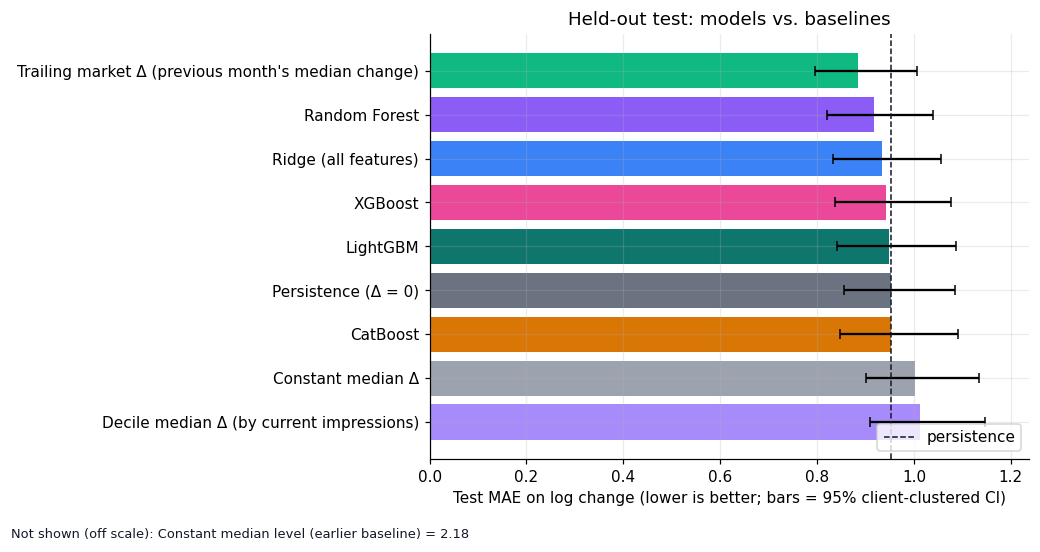

In [15]:
preds = {s: {**baseline_predictions(s), **{n: predict_model(n, XY[s]["X"]) for n in MODELS}} for s in ("validation", "test")}
rows = []
for name in preds["test"]:
    v, t = score_split(preds["validation"][name], "validation"), score_split(preds["test"][name], "test")
    rows.append({"model": name, "val_MAE": v["MAE"], "test_MAE": t["MAE"], "test_MAE_CI": fmt_ci(t["MAE"], t["MAE_lo"], t["MAE_hi"]),
                 "test_RMSE": t["RMSE"], "R2_change": t["R2_change"], "R2_level": t["R2_level"],
                 "macro_MAE_per_client": t["Macro_MAE"], "Spearman": t["Spearman"], "typical_×error": t["typical_factor"],
                 "_t": t, "_v": v})
results_df = pd.DataFrame(rows)
display(results_df.drop(columns=["_t", "_v"]))
RESULTS["models"] = {r["model"]: {"validation": r["_v"], "test": r["_t"]} for r in rows}

# paired comparisons on the test months
persist_mae = RESULTS["models"][PERSIST]["test"]["MAE"]
sel_mae = RESULTS["models"][SELECTED]["test"]["MAE"]
best_baseline = min([b for b in BASELINES if b != PERSIST], key=lambda b: RESULTS["models"][b]["validation"]["MAE"])
other = min((n for n in MODELS if n != SELECTED), key=lambda n: val_mae[n])
comparisons = {}
for label, a, b in [("selected_vs_persistence", SELECTED, PERSIST), ("selected_vs_trend", SELECTED, TREND),
                    ("selected_vs_best_baseline", SELECTED, best_baseline), ("selected_vs_other_model", SELECTED, other)]:
    d, lo, hi = paired_diff(preds["test"][a], preds["test"][b], "test")
    comparisons[label] = {"a": a, "b": b, "diff": d, "lo": lo, "hi": hi, "verdict": verdict(lo, hi)}
    print(f"{a}  −  {b}:  ΔMAE = {fmt_ci(d, lo, hi)}  → {a} is {verdict(lo, hi).upper()} on the test months")
print(f"(The 'best baseline' above is {best_baseline}, chosen on VALIDATION MAE by a rule fixed in advance; the trend baseline is compared separately because it is the strongest on test.)")
RESULTS["comparisons"] = comparisons

# every model and baseline, paired with persistence on the same test rows
paired_rows = []
for name in preds["test"]:
    if name == PERSIST:
        continue
    d_, lo_, hi_ = paired_diff(preds["test"][name], preds["test"][PERSIST], "test")
    paired_rows.append({"model": name, "test_MAE": RESULTS["models"][name]["test"]["MAE"],
                        "ΔMAE vs persistence [95% CI]": fmt_ci(d_, lo_, hi_), "verdict vs persistence": verdict(lo_, hi_),
                        "diff": d_, "lo": lo_, "hi": hi_})
paired_df = pd.DataFrame(paired_rows)
print("\nEvery model and baseline versus persistence (paired, same test rows; negative = lower error than persistence):")
display(paired_df[["model", "test_MAE", "ΔMAE vs persistence [95% CI]", "verdict vs persistence"]])
RESULTS["paired_vs_persistence"] = paired_rows

trend_rows = []
for name in preds["test"]:
    if name == TREND:
        continue
    d_, lo_, hi_ = paired_diff(preds["test"][name], preds["test"][TREND], "test")
    trend_rows.append({"model": name, "test_MAE": RESULTS["models"][name]["test"]["MAE"],
                       "ΔMAE vs trend baseline [95% CI]": fmt_ci(d_, lo_, hi_), "verdict vs trend baseline": verdict(lo_, hi_),
                       "diff": d_, "lo": lo_, "hi": hi_})
trend_df = pd.DataFrame(trend_rows)
print("\nEvery model and baseline versus the TRAILING-MARKET baseline (paired, same test rows; negative = lower error than the trend):")
display(trend_df[["model", "test_MAE", "ΔMAE vs trend baseline [95% CI]", "verdict vs trend baseline"]])
RESULTS["paired_vs_trend"] = trend_rows

# selection disclosure: the rule was fixed before looking at the test months, and is NOT revised after seeing them
test_mae_models = {n: RESULTS["models"][n]["test"]["MAE"] for n in MODELS}
test_best = min(test_mae_models, key=test_mae_models.get)
if test_best != SELECTED:
    c_o = comparisons["selected_vs_other_model"]
    disclosure = (f"On the test months {test_best} had lower MAE than the pre-selected {SELECTED} (paired ΔMAE, {SELECTED} minus {test_best}: "
                  f"{fmt_ci(c_o['diff'], c_o['lo'], c_o['hi'], 4)}). Selection followed the pre-set validation-MAE rule and is not revised after "
                  f"seeing test results; both models are reported against persistence, and the queue (§6) uses {SELECTED}.")
else:
    disclosure = f"The pre-selected {SELECTED} was also the better model on the test months."
print("\nSelection disclosure:", disclosure)
RESULTS["selection"] = {"selected": SELECTED, "validation_mae": val_mae, "best_baseline_by_validation": best_baseline,
                        "xgb_params": XGB_GRID[best_i], "xgb_best_round": int(tuning_df.loc[best_i, "best_round"]),
                        "rf_params": RF_PARAMS, "catboost_params": CATBOOST_PARAMS, "lightgbm_params": LIGHTGBM_PARAMS,
                        "model_best_iterations": MODEL_BEST_ITERATIONS, "candidate_validation_mae": val_mae,
                        "other_model": other, "test_best_model": test_best, "disclosure": disclosure}

drift = {n: RESULTS["models"][n]["test"]["MAE"] / RESULTS["models"][n]["validation"]["MAE"] for n in (PERSIST, SELECTED)}
RESULTS["val_to_test_mae_ratio"] = drift
print(f"\nValidation → test MAE ratio:  persistence {drift[PERSIST]:.2f}×   |   {SELECTED} {drift[SELECTED]:.2f}×")
print(f"Relative MAE reduction vs persistence on test: {(persist_mae - sel_mae) / persist_mae:.1%} "
      f"(typical multiplicative error {RESULTS['models'][SELECTED]['test']['typical_factor']:.2f}× vs {math.exp(persist_mae):.2f}× for persistence)")

# Figure: test MAE with client-clustered CIs (bars far off scale are listed in a footnote instead of crushing the axis)
order = results_df.sort_values("test_MAE")
shown, hidden = order[order["test_MAE"] <= 1.5 * persist_mae], order[order["test_MAE"] > 1.5 * persist_mae]
TREND_COLOR = "#10B981"
fig, ax = plt.subplots(figsize=(9.5, 4.8))
colors = [PALETTE["XGBoost"] if m == "XGBoost" else PALETTE["Random Forest"] if m == "Random Forest"
          else PALETTE["CatBoost"] if m == "CatBoost" else PALETTE["LightGBM"] if m == "LightGBM"
          else PALETTE["Persistence"] if m == PERSIST else TREND_COLOR if m == TREND else PALETTE["Ridge"] if m.startswith("Ridge")
          else PALETTE["Decile"] if m.startswith("Decile") else PALETTE["Constant"] for m in shown["model"]]
lo = [r["_t"]["MAE"] - r["_t"]["MAE_lo"] for _, r in shown.iterrows()]
hi = [r["_t"]["MAE_hi"] - r["_t"]["MAE"] for _, r in shown.iterrows()]
ax.barh(shown["model"], shown["test_MAE"], xerr=[lo, hi], color=colors, capsize=3)
ax.axvline(persist_mae, color=PALETTE["ink"], ls="--", lw=1, label="persistence")
ax.set_xlim(0, float((shown["_t"].apply(lambda t: t["MAE_hi"])).max()) * 1.08)
ax.set_xlabel("Test MAE on log change (lower is better; bars = 95% client-clustered CI)")
ax.set_title("Held-out test: models vs. baselines"); ax.legend(loc="lower right"); ax.invert_yaxis()
if len(hidden):
    fig.text(0.01, -0.03, "Not shown (off scale): " + "; ".join(f"{r['model']} = {r['test_MAE']:.2f}" for _, r in hidden.iterrows()),
             fontsize=8.5, color=PALETTE["ink"])
plt.tight_layout()
savefig("fig03_model_comparison")

### 4.3a Statistical validation across candidate models

The existing paired client-clustered bootstrap intervals remain the primary uncertainty display. This additional check changes the estimand deliberately: it first averages each model's paired absolute-error difference within each client, then performs a two-sided client-level sign-flip test. This avoids treating multiple rows from the same client as independent inferential units. Holm adjustment controls family-wise error across the planned candidate-versus-persistence and candidate-versus-trend tests. Read the pooled paired interval and equal-client test together; they answer different weighting questions.

In [16]:
def client_signflip_pvalue(pred_a, pred_b, split="test", B=9999, seed=SEED):
    """Two-sided sign-flip test on per-client mean paired MAE differences."""
    d = XY[split]
    row_diff = np.abs(pred_a - d["y"]) - np.abs(pred_b - d["y"])
    tmp = pd.DataFrame({"client": d["groups"], "diff": row_diff})
    client_diff = tmp.groupby("client", sort=False)["diff"].mean().to_numpy(float)
    client_diff = client_diff[np.isfinite(client_diff)]
    if len(client_diff) < 2:
        return float("nan"), float(np.mean(client_diff)) if len(client_diff) else float("nan"), int(len(client_diff))
    observed = float(client_diff.mean())
    rng = np.random.default_rng(seed)
    signs = rng.choice(np.array([-1.0, 1.0]), size=(B, len(client_diff)))
    null = (signs * client_diff[None, :]).mean(axis=1)
    p = float((1 + np.sum(np.abs(null) >= abs(observed))) / (B + 1))
    return p, observed, int(len(client_diff))


def holm_adjust(p_values):
    """Holm step-down family-wise p-value adjustment."""
    p_values = np.asarray(p_values, dtype=float)
    out = np.full(len(p_values), np.nan, dtype=float)
    valid = np.flatnonzero(np.isfinite(p_values))
    if not len(valid):
        return out
    order = valid[np.argsort(p_values[valid])]
    running = 0.0
    m = len(order)
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p_values[idx])
        out[idx] = min(1.0, running)
    return out


infer_rows = []
for model_name in MODELS:
    for comparator in (PERSIST, TREND):
        d_hat, lo_hat, hi_hat = paired_diff(preds["test"][model_name], preds["test"][comparator], "test")
        p_raw, macro_diff, n_clients = client_signflip_pvalue(
            preds["test"][model_name], preds["test"][comparator], seed=SEED + len(infer_rows)
        )
        infer_rows.append({"model": model_name, "comparator": comparator,
                           "pooled_ΔMAE [95% client bootstrap CI]": fmt_ci(d_hat, lo_hat, hi_hat),
                           "pooled_CI_verdict": verdict(lo_hat, hi_hat),
                           "equal-client mean ΔMAE": macro_diff, "client_signflip_p": p_raw,
                           "clients": n_clients, "_lo": lo_hat, "_hi": hi_hat})

inference_df = pd.DataFrame(infer_rows)
inference_df["Holm_adjusted_p"] = holm_adjust(inference_df["client_signflip_p"].to_numpy())
inference_df["Holm_significant_0.05"] = inference_df["Holm_adjusted_p"] < 0.05
show(inference_df.drop(columns=["_lo", "_hi"]))
RESULTS["model_inference"] = inference_df.drop(columns=["_lo", "_hi"]).to_dict(orient="records")

,model,comparator,pooled_ΔMAE [95% client bootstrap CI],pooled_CI_verdict,equal-client mean ΔMAE,client_signflip_p,clients,Holm_adjusted_p,Holm_significant_0.05
0,XGBoost,Persistence (Δ = 0),"-0.011 [-0.039, 0.017]",indistinguishable,0.0042,0.7807,46,1.0000,False
1,XGBoost,Trailing market Δ (previous month's median cha...,"0.059 [0.026, 0.089]",worse,0.0696,0.0020,46,0.0120,True
2,Random Forest,Persistence (Δ = 0),"-0.037 [-0.071, -0.006]",better,-0.0177,0.2983,46,1.0000,False
3,Random Forest,Trailing market Δ (previous month's median cha...,"0.033 [0.004, 0.060]",worse,0.0478,0.0303,46,0.1515,False
4,CatBoost,Persistence (Δ = 0),"0.000 [-0.024, 0.025]",indistinguishable,0.0143,0.2998,46,1.0000,False
5,CatBoost,Trailing market Δ (previous month's median cha...,"0.070 [0.038, 0.100]",worse,0.0798,0.0003,46,0.0024,True
6,LightGBM,Persistence (Δ = 0),"-0.005 [-0.031, 0.021]",indistinguishable,0.0097,0.4619,46,1.0000,False
7,LightGBM,Trailing market Δ (previous month's median cha...,"0.065 [0.032, 0.095]",worse,0.0752,0.0006,46,0.0042,True


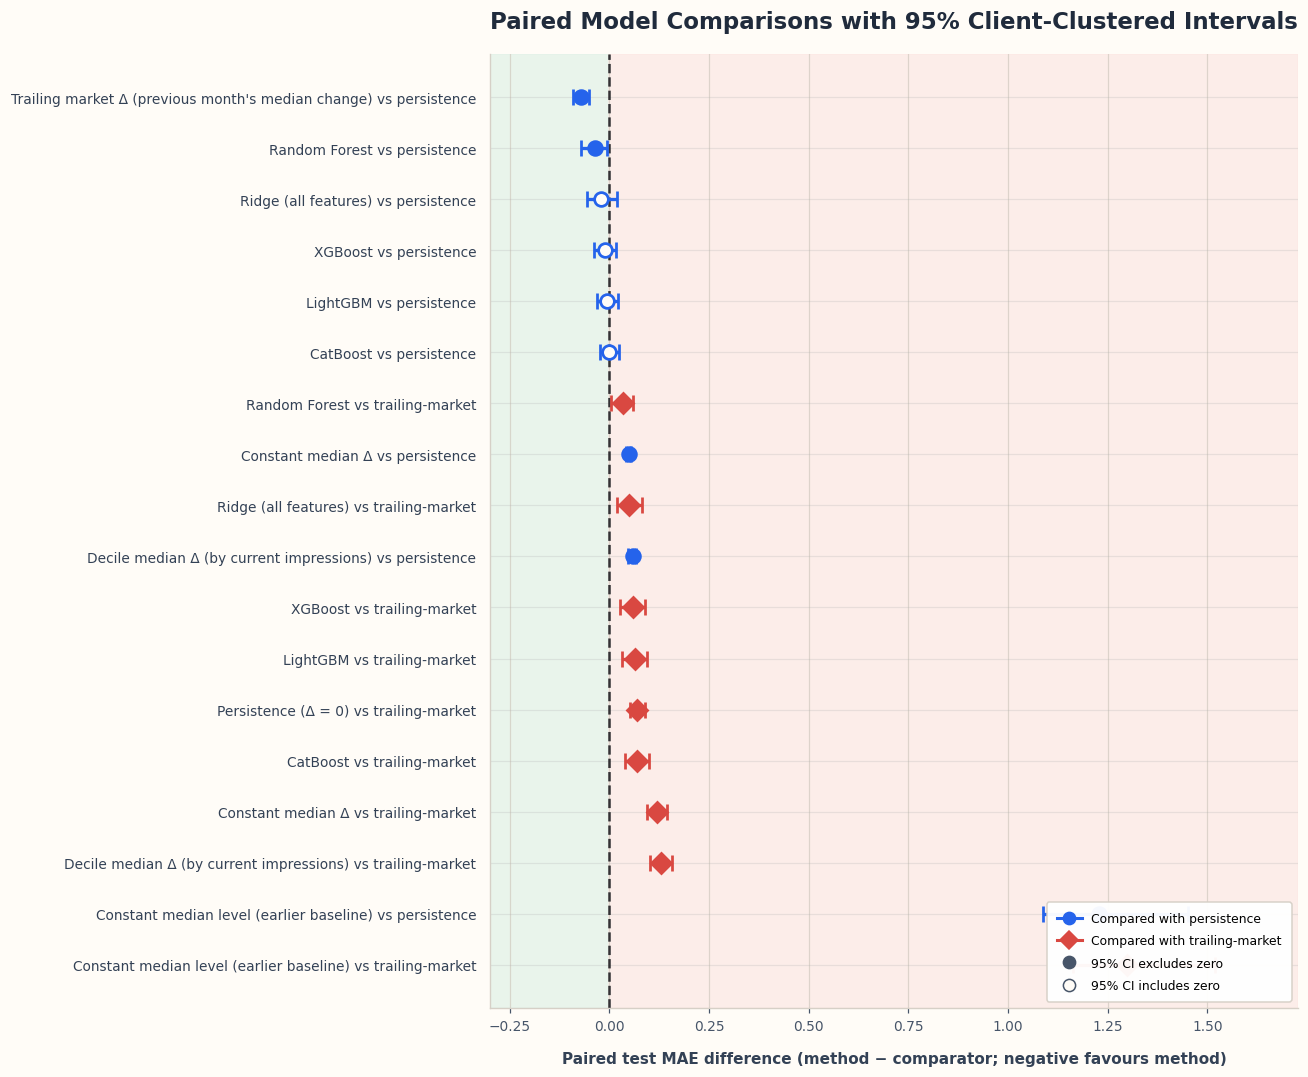

Saved paired comparison forest plot: /content/docs/figures/fig19_paired_difference_forest.png


In [17]:

# Figure 19 — Paired-difference forest plot; negative ΔMAE favours the named method.

from matplotlib.lines import Line2D

forest_rows = []

# Comparisons against persistence
for r in RESULTS["paired_vs_persistence"]:

    forest_rows.append({
        "comparison": f'{r["model"]} vs persistence',
        "diff": float(r["diff"]),
        "lo": float(r["lo"]),
        "hi": float(r["hi"]),
        "comparator": "Persistence",
    })

# Comparisons against trailing-market baseline
for r in RESULTS["paired_vs_trend"]:

    forest_rows.append({
        "comparison": f'{r["model"]} vs trailing-market',
        "diff": float(r["diff"]),
        "lo": float(r["lo"]),
        "hi": float(r["hi"]),
        "comparator": "Trailing-market",
    })

forest_df = (
    pd.DataFrame(forest_rows)
    .sort_values("diff", ascending=True)
    .reset_index(drop=True)
)

if not forest_df.empty:

    # Consistent comparison colors
    comparator_colors = {
        "Persistence": "#2563EB",
        "Trailing-market": "#D94841",
    }

    comparator_markers = {
        "Persistence": "o",
        "Trailing-market": "D",
    }

    # Confidence intervals determine filled versus hollow markers.
    forest_df["excludes_zero"] = (
        (forest_df["hi"] < 0)
        | (forest_df["lo"] > 0)
    )

    # Determine balanced horizontal axis limits.
    raw_min = min(
        float(forest_df["lo"].min()),
        0.0
    )

    raw_max = max(
        float(forest_df["hi"].max()),
        0.0
    )

    span = max(raw_max - raw_min, 0.05)
    padding = span * 0.13

    x_min = raw_min - padding
    x_max = raw_max + padding

    fig, ax = plt.subplots(
        figsize=(12, max(5.2, 0.55 * len(forest_df)))
    )

    fig.patch.set_facecolor("#FFFCF7")
    ax.set_facecolor("#FFFDF9")

    # Interpretation zones
    ax.axvspan(
        x_min,
        0,
        color="#E3F2E8",
        alpha=0.78,
        zorder=0
    )

    ax.axvspan(
        0,
        x_max,
        color="#FCE8E4",
        alpha=0.72,
        zorder=0
    )

    yy = np.arange(len(forest_df))

    # Draw each comparison with its own color and marker.
    for y, row in forest_df.iterrows():

        color = comparator_colors[row["comparator"]]

        marker = comparator_markers[row["comparator"]]

        marker_face = (
            color
            if row["excludes_zero"]
            else "#FFFCF7"
        )

        left_error = max(
            0.0,
            row["diff"] - row["lo"]
        )

        right_error = max(
            0.0,
            row["hi"] - row["diff"]
        )

        ax.errorbar(
            row["diff"],
            y,
            xerr=[
                [left_error],
                [right_error]
            ],
            fmt=marker,
            markersize=9,
            markerfacecolor=marker_face,
            markeredgecolor=color,
            markeredgewidth=1.8,
            ecolor=color,
            elinewidth=2.15,
            capsize=5,
            capthick=1.8,
            zorder=4
        )

    # Zero-difference reference
    ax.axvline(
        0,
        color="#202124",
        linestyle="--",
        linewidth=1.65,
        alpha=0.9,
        zorder=2,
        label="No difference"
    )

    ax.set_xlim(x_min, x_max)

    ax.set_yticks(yy)

    ax.set_yticklabels(
        forest_df["comparison"],
        fontsize=9,
        color="#334155"
    )

    # Most favorable differences appear at the top.
    ax.invert_yaxis()

    ax.set_xlabel(
        "Paired test MAE difference "
        "(method − comparator; negative favours method)",
        fontsize=10,
        fontweight="bold",
        color="#334155",
        labelpad=12
    )

    ax.set_title(
        "Paired Model Comparisons with 95% Client-Clustered Intervals",
        fontsize=15,
        fontweight="bold",
        color="#202B3C",
        pad=17
    )

    ax.grid(
        axis="x",
        color="#CFC8BD",
        alpha=0.68,
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    # Custom legend: comparison types
    legend_handles = [

        Line2D(
            [0], [0],
            marker="o",
            color="#2563EB",
            markersize=8,
            linewidth=2,
            label="Compared with persistence"
        ),

        Line2D(
            [0], [0],
            marker="D",
            color="#D94841",
            markersize=8,
            linewidth=2,
            label="Compared with trailing-market"
        ),

        Line2D(
            [0], [0],
            marker="o",
            color="#475569",
            markerfacecolor="#475569",
            markeredgecolor="#475569",
            linestyle="none",
            markersize=8,
            label="95% CI excludes zero"
        ),

        Line2D(
            [0], [0],
            marker="o",
            color="#475569",
            markerfacecolor="#FFFCF7",
            markeredgecolor="#475569",
            linestyle="none",
            markersize=8,
            label="95% CI includes zero"
        ),
    ]

    legend = ax.legend(
        handles=legend_handles,
        loc="lower right",
        fontsize=8.1,
        frameon=True,
        facecolor="#FFFFFF",
        edgecolor="#D6D0C7",
        borderpad=0.8,
        labelspacing=0.75
    )

    legend.get_frame().set_alpha(0.96)

    ax.tick_params(
        axis="x",
        labelsize=9,
        colors="#475569"
    )

    ax.tick_params(
        axis="y",
        length=0,
        pad=9
    )

    for spine in ax.spines.values():
        spine.set_color("#D6D0C7")
        spine.set_linewidth(0.9)

    fig.tight_layout()

    fig.savefig(
        FIG_DIR / "fig19_paired_difference_forest.png",
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close(fig)

else:

    print(
        "Forest plot skipped: "
        "no paired model comparisons were available."
    )

print(
    "Saved paired comparison forest plot:",
    FIG_DIR / "fig19_paired_difference_forest.png"
)



### 4.3b Volume-weighted evaluation — the queue is about volume, not about 1-impression items

Row-weighted MAE gives a 1-impression item the same weight as a 100,000-impression item, and tiny items are mostly Poisson noise. Two volume-aware views are reported for **every** model and baseline on the same test rows, each paired with persistence **and** with the trend baseline (client-clustered intervals):

* **Impression-weighted MAE** — each row weighted by its current-month impressions.
* **MAE on items with ≥ 100 impressions** — where the log change is not dominated by counting noise.

In [18]:
def cluster_bootstrap_ratio(num, den, groups, B=1000, seed=SEED):
    """Client-clustered bootstrap CI for sum(num) / sum(den)."""
    codes, uniques = pd.factorize(pd.Series(groups))
    g = len(uniques)
    sn, sd = np.bincount(codes, weights=num, minlength=g), np.bincount(codes, weights=den, minlength=g)
    draws = np.random.default_rng(seed).integers(0, g, size=(B, g))
    lo, hi = np.percentile(sn[draws].sum(1) / sd[draws].sum(1), [2.5, 97.5])
    return float(sn.sum() / sd.sum()), float(lo), float(hi)


y_w, w_w, g_w = XY["test"]["y"], XY["test"]["impr"], XY["test"]["groups"]
big_mask = w_w >= 100
ae_all = {n: np.abs(p_ - y_w) for n, p_ in preds["test"].items()}
w_rows = []
for name, ae in ae_all.items():
    wm, wlo, whi = cluster_bootstrap_ratio(ae * w_w, w_w, g_w)
    bm_, blo, bhi = cluster_bootstrap(ae[big_mask], g_w[big_mask])
    row = {"model": name, "weighted_MAE [95% CI]": fmt_ci(wm, wlo, whi), "MAE items ≥100 impr [95% CI]": fmt_ci(bm_, blo, bhi), "_w": wm, "_big": bm_}
    for tag, ref in (("persistence", PERSIST), ("trend", TREND)):
        if name == ref:
            row[f"weighted Δ vs {tag}"], row[f"≥100 Δ vs {tag}"] = "–", "–"
            continue
        dw, dwlo, dwhi = cluster_bootstrap_ratio((ae - ae_all[ref]) * w_w, w_w, g_w)
        db, dblo, dbhi = cluster_bootstrap((ae - ae_all[ref])[big_mask], g_w[big_mask])
        row[f"weighted Δ vs {tag}"] = f"{dw:+.3f} ({verdict(dwlo, dwhi)})"
        row[f"≥100 Δ vs {tag}"] = f"{db:+.3f} ({verdict(dblo, dbhi)})"
        row[f"_w_{tag}"] = (dw, dwlo, dwhi)
        row[f"_big_{tag}"] = (db, dblo, dbhi)
    w_rows.append(row)
weighted_df = pd.DataFrame(w_rows)
print(f"Items with ≥ 100 impressions: {big_mask.mean():.1%} of test rows, {w_w[big_mask].sum() / w_w.sum():.1%} of test impressions.")
display(weighted_df[[c for c in weighted_df.columns if not c.startswith("_")]])
RESULTS["weighted"] = {"share_rows_ge_100": float(big_mask.mean()), "share_impressions_ge_100": float(w_w[big_mask].sum() / w_w.sum()), "rows": w_rows}

Items with ≥ 100 impressions: 55.2% of test rows, 99.1% of test impressions.


,model,weighted_MAE [95% CI],MAE items ≥100 impr [95% CI],weighted Δ vs persistence,≥100 Δ vs persistence,weighted Δ vs trend,≥100 Δ vs trend
0,Persistence (Δ = 0),"0.582 [0.512, 0.711]","0.778 [0.694, 0.922]",–,–,+0.069 (worse),+0.077 (worse)
1,Trailing market Δ (previous month's median cha...,"0.513 [0.462, 0.614]","0.701 [0.631, 0.830]",-0.069 (better),-0.077 (better),–,–
2,Constant median Δ,"0.642 [0.568, 0.772]","0.831 [0.741, 0.980]",+0.060 (worse),+0.053 (worse),+0.129 (worse),+0.130 (worse)
3,Constant median level (earlier baseline),"3.872 [3.514, 4.095]","1.783 [1.614, 1.906]",+3.290 (worse),+1.005 (worse),+3.359 (worse),+1.082 (worse)
4,Decile median Δ (by current impressions),"0.633 [0.559, 0.765]","0.848 [0.755, 1.002]",+0.051 (worse),+0.070 (worse),+0.121 (worse),+0.146 (worse)
5,Ridge (all features),"0.649 [0.586, 0.782]","0.746 [0.657, 0.881]",+0.068 (indistinguishable),-0.032 (indistinguishable),+0.137 (worse),+0.044 (worse)
6,XGBoost,"0.578 [0.528, 0.695]","0.764 [0.679, 0.904]",-0.004 (indistinguishable),-0.014 (indistinguishable),+0.065 (worse),+0.063 (worse)
7,Random Forest,"0.597 [0.544, 0.676]","0.742 [0.671, 0.868]",+0.015 (indistinguishable),-0.037 (indistinguishable),+0.084 (worse),+0.040 (indistinguishable)
8,CatBoost,"0.585 [0.533, 0.711]","0.777 [0.688, 0.922]",+0.003 (indistinguishable),-0.001 (indistinguishable),+0.073 (worse),+0.075 (worse)
9,LightGBM,"0.580 [0.526, 0.704]","0.769 [0.680, 0.912]",-0.002 (indistinguishable),-0.009 (indistinguishable),+0.067 (worse),+0.068 (worse)


### 4.4 Is the model useful for *ranking*, not just for regression error?

A prioritization tool lives or dies on rank quality. Pooled Spearman is dominated by between-client differences, so we also report the **within-client** mean Spearman (what a single client's team would experience) and decile hit-rates.

In [19]:
def within_client_spearman(pred, split, min_rows=200):
    d = XY[split]
    df = pd.DataFrame({"g": d["groups"], "p": pred, "y": d["y"]})
    vals = [spearmanr(s["p"], s["y"]).statistic for _, s in df.groupby("g") if len(s) >= min_rows and s["p"].nunique() > 1]
    return (float(np.mean(vals)) if vals else float("nan")), len(vals)


def decile_hit_rates(pred, y):
    hi_thr, lo_thr = np.quantile(pred, 0.9), np.quantile(pred, 0.1)
    return {"top_decile_growth_rate": float((y[pred >= hi_thr] > 0).mean()), "base_growth_rate": float((y > 0).mean()),
            "bottom_decile_decline_rate": float((y[pred <= lo_thr] < 0).mean()), "base_decline_rate": float((y < 0).mean())}


rank_rows = []
for name in [SELECTED, other, "Decile median Δ (by current impressions)", "Ridge (all features)"]:
    wc, n_cl = within_client_spearman(preds["test"][name], "test")
    hr = decile_hit_rates(preds["test"][name], XY["test"]["y"])
    rank_rows.append({"model": name, "pooled_Spearman": RESULTS["models"][name]["test"]["Spearman"],
                      "within_client_Spearman": wc, "clients_in_mean": n_cl, **hr})
rank_df = pd.DataFrame(rank_rows)
display(rank_df)
RESULTS["ranking_metrics"] = rank_df.to_dict(orient="records")

,model,pooled_Spearman,within_client_Spearman,clients_in_mean,top_decile_growth_rate,base_growth_rate,bottom_decile_decline_rate,base_decline_rate
0,XGBoost,0.0965,0.0816,41,0.5279,0.2844,0.7432,0.6980
1,LightGBM,0.0945,0.0488,41,0.5298,0.2844,0.7509,0.6980
2,Decile median Δ (by current impressions),-0.0167,-0.1144,41,0.3149,0.2844,0.6153,0.6980
3,Ridge (all features),0.0958,0.1175,41,0.3838,0.2844,0.7901,0.6980


### 4.5 Where does it work? Per month, seen vs. unseen clients, and drift

Validation→test degradation is only meaningful relative to how much the *baseline* degrades. We also compare the selected model with persistence for clients **seen** in training vs. **new** clients, month by month, and run an **adversarial validation** (can a classifier tell training rows from test rows? how, and with what features?).

,segment,rows,clients,MAE_selected,MAE_persistence,ΔMAE_vs_persistence [95% CI],verdict
0,all test rows,389253,46,0.9422,0.9536,"-0.011 [-0.039, 0.017]",indistinguishable
1,clients seen in training,284913,24,0.8957,0.9001,"-0.004 [-0.041, 0.033]",indistinguishable
2,new clients (not in training),104340,22,1.0694,1.0994,"-0.030 [-0.066, 0.001]",indistinguishable
3,month 2026-04,189305,42,0.8221,0.8151,"0.007 [-0.025, 0.033]",indistinguishable
4,month 2026-05,199948,42,1.0559,1.0846,"-0.029 [-0.077, 0.019]",indistinguishable


Adversarial-validation AUC (train vs test rows): 0.882   (0.5 = indistinguishable)


,importance
ga4_day_share,0.4695
prev_known,0.0754
pos_change,0.0473
ctr,0.0465
item_age_months,0.0459
mom_change,0.0342


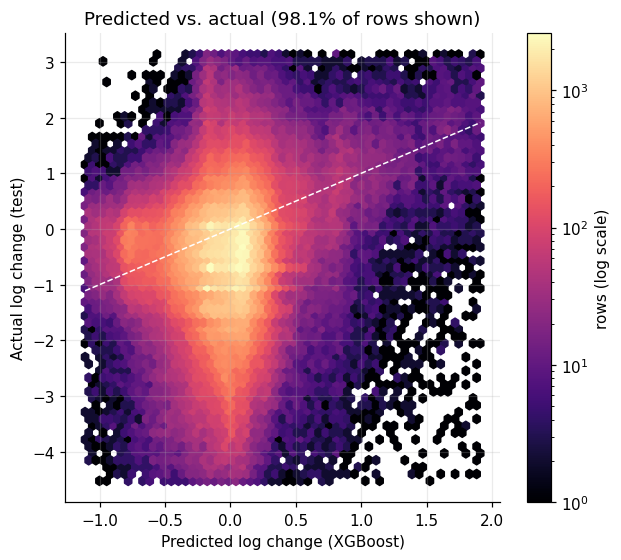

In [20]:
dt = D["test"]
subsets = {"all test rows": np.ones(len(dt), bool),
           "clients seen in training": dt["seen_client"].to_numpy(),
           "new clients (not in training)": ~dt["seen_client"].to_numpy()}
for m in sorted(dt["month"].astype(str).unique()):
    subsets[f"month {m}"] = (dt["month"].astype(str) == m).to_numpy()

seg_rows = []
for label, mask in subsets.items():
    if mask.sum() < 30 or len(np.unique(XY["test"]["groups"][mask])) < 2:
        continue
    y, g = XY["test"]["y"][mask], XY["test"]["groups"][mask]
    d, lo_, hi_ = paired_diff(preds["test"][SELECTED], preds["test"][PERSIST], mask, split="test")
    seg_rows.append({"segment": label, "rows": int(mask.sum()), "clients": len(np.unique(g)),
                     "MAE_selected": float(np.abs(preds["test"][SELECTED][mask] - y).mean()),
                     "MAE_persistence": float(np.abs(y).mean()), "ΔMAE_vs_persistence [95% CI]": fmt_ci(d, lo_, hi_),
                     "verdict": verdict(lo_, hi_)})
seg_df = pd.DataFrame(seg_rows)
display(seg_df)
RESULTS["segments"] = seg_df.to_dict(orient="records")

# adversarial validation: train (label 0) vs test (label 1)
adv_n = min(60_000, len(D["train"]), len(D["test"]))
adv = pd.concat([D["train"][FEATURES].sample(adv_n, random_state=SEED).assign(_is_test=0),
                 D["test"][FEATURES].sample(adv_n, random_state=SEED).assign(_is_test=1)], ignore_index=True)
cut = np.random.default_rng(SEED).random(len(adv)) < 0.7
adv_clf = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=SEED)
adv_clf.fit(adv.loc[cut, FEATURES], adv.loc[cut, "_is_test"])
auc = float(roc_auc_score(adv.loc[~cut, "_is_test"], adv_clf.predict_proba(adv.loc[~cut, FEATURES])[:, 1]))
adv_imp = pd.Series(adv_clf.feature_importances_, index=FEATURES).sort_values(ascending=False).head(6)
print(f"Adversarial-validation AUC (train vs test rows): {auc:.3f}   (0.5 = indistinguishable)")
display(adv_imp.rename("importance").to_frame())
RESULTS["drift"] = {"adversarial_auc": auc, "top_drift_features": adv_imp.round(4).to_dict()}

# Figure: predicted vs actual change (extreme rows are omitted, not clipped, so no artificial edge pile-ups appear)
sel_pred, y_t = preds["test"][SELECTED], XY["test"]["y"]
xlim, ylim = np.percentile(sel_pred, [0.5, 99.5]), np.percentile(y_t, [0.5, 99.5])
inside = (sel_pred >= xlim[0]) & (sel_pred <= xlim[1]) & (y_t >= ylim[0]) & (y_t <= ylim[1])
fig, ax = plt.subplots(figsize=(5.8, 5.2))
hb = ax.hexbin(sel_pred[inside], y_t[inside], gridsize=55, bins="log", cmap="magma", mincnt=1, extent=(xlim[0], xlim[1], ylim[0], ylim[1]))
dl, dh = max(xlim[0], ylim[0]), min(xlim[1], ylim[1])
ax.plot([dl, dh], [dl, dh], color="white", lw=1, ls="--")
ax.set_xlabel(f"Predicted log change ({SELECTED})"); ax.set_ylabel("Actual log change (test)")
ax.set_title(f"Predicted vs. actual ({inside.mean():.1%} of rows shown)")
fig.colorbar(hb, label="rows (log scale)")
plt.tight_layout()
savefig("fig04_pred_vs_actual")

### 4.6 Signal report: what adds predictive information *beyond persistence*?

This is the **ranking-signal analysis**. Because the label is the change relative to persistence, each feature group is evaluated by how much *out-of-time* error it removes **on top of the previous group**. All steps use XGBoost with the tuned hyperparameters and validation early stopping; the full model (D) is the selected tree model's XGBoost fit.

* **A** — current impression level only (regression to the mean by level)
* **B** — + clicks, CTR, position, active-day share (GSC signals)
* **C** — + month-over-month history (lags, item age)
* **D** — + GA4 / traffic-source / engagement / AI-source features

Differences are **paired** (same rows) with client-clustered 95% intervals. A verdict of *indistinguishable* means the data cannot separate the two — not that the feature group is useless.

,step,n_features,test_MAE [95% CI],ΔMAE vs persistence,verdict vs persistence,ΔMAE vs previous step,incremental verdict
0,A. level only,1,"0.994 [0.892, 1.129]","0.040 [0.031, 0.048]",worse,"0.040 [0.031, 0.048]",worse
1,B. + GSC signals,5,"0.967 [0.865, 1.100]","0.014 [-0.001, 0.025]",indistinguishable,"-0.027 [-0.040, -0.015]",better
2,C. + lag / history,11,"0.958 [0.858, 1.093]","0.005 [-0.008, 0.018]",indistinguishable,"-0.009 [-0.017, 0.004]",indistinguishable
3,D. + GA4 / traffic (full),26,"0.942 [0.837, 1.076]","-0.011 [-0.039, 0.017]",indistinguishable,"-0.016 [-0.038, 0.007]",indistinguishable


GA4-covered test rows only (n=195,208): ΔMAE (D − C) = -0.049 [-0.068, -0.027] → better


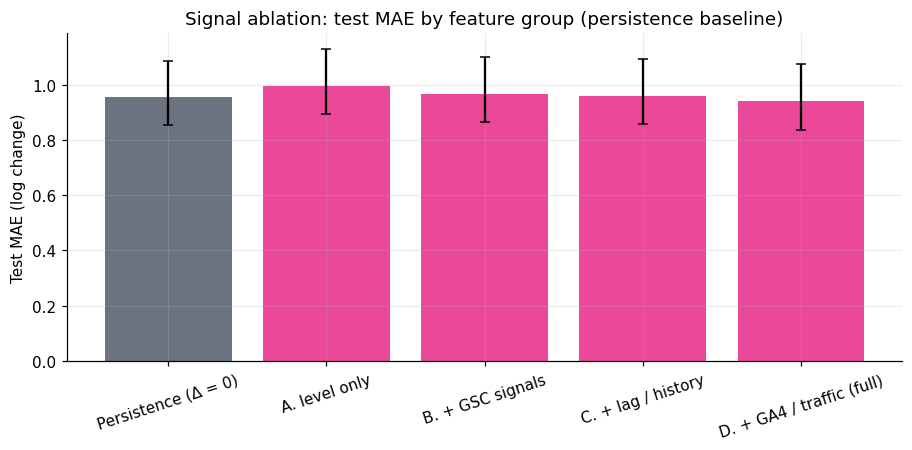

In [22]:

import xgboost as xgb
import gc

# Feature-group ablation
ABLATION = [
    ("A. level only", ["log_impr"]),
    ("B. + GSC signals", G_GSC),
    ("C. + lag / history", G_GSC + G_LAGS),
    ("D. + GA4 / traffic (full)", FEATURES)
]

# Use the hyperparameters selected during validation
best_params = XGB_GRID[best_i]

abl_preds = {}

# Fit each ablation model using the same selected hyperparameters
for label, feats in ABLATION:

    m = fit_xgb(
        best_params,
        D["train"][feats],
        ytr,
        D["validation"][feats],
        yva
    )

    abl_preds[label] = xgb_predict(m, D["test"][feats])

    del m
    gc.collect()


# Compare each feature group against persistence
zero = preds["test"][PERSIST]

abl_rows = []
prev_label = PERSIST
prev_pred = zero

for label, feats in ABLATION:

    p = abl_preds[label]

    mae_, lo_, hi_ = cluster_bootstrap(
        np.abs(p - XY["test"]["y"]),
        XY["test"]["groups"]
    )

    dv, dlo, dhi = paired_diff(p, zero, "test")
    di, ilo, ihi = paired_diff(p, prev_pred, "test")

    abl_rows.append({
        "step": label,
        "n_features": len(feats),
        "test_MAE [95% CI]": fmt_ci(mae_, lo_, hi_),
        "ΔMAE vs persistence": fmt_ci(dv, dlo, dhi),
        "verdict vs persistence": verdict(dlo, dhi),
        "ΔMAE vs previous step": fmt_ci(di, ilo, ihi),
        "incremental verdict": verdict(ilo, ihi),
        "_mae": mae_,
        "_lo": lo_,
        "_hi": hi_,
        "_inc": (di, ilo, ihi)
    })

    prev_label = label
    prev_pred = p

abl_df = pd.DataFrame(abl_rows)

display(
    abl_df.drop(
        columns=["_mae", "_lo", "_hi", "_inc"]
    )
)


# GA4-covered subset:
# Does GA4 improve performance where GA4 data actually exists?

ga4_mask = D["test"]["has_ga4"].to_numpy(bool)

if (
    ga4_mask.sum() >= 100
    and len(np.unique(XY["test"]["groups"][ga4_mask])) >= 3
):

    dd, dlo, dhi = paired_diff(
        abl_preds["D. + GA4 / traffic (full)"],
        abl_preds["C. + lag / history"],
        ga4_mask,
        split="test"
    )

    ga4_subset = {
        "rows": int(ga4_mask.sum()),
        "diff": dd,
        "lo": dlo,
        "hi": dhi,
        "verdict": verdict(dlo, dhi)
    }

    print(
        f"GA4-covered test rows only (n={ga4_mask.sum():,}): "
        f"ΔMAE (D − C) = {fmt_ci(dd, dlo, dhi)} "
        f"→ {verdict(dlo, dhi)}"
    )

else:
    ga4_subset = None
    print(
        "Too few GA4-covered test rows / clients "
        "for a subset comparison."
    )


# Save ablation results
RESULTS["ablation"] = {
    "rows": abl_rows,
    "ga4_subset": ga4_subset,
    "persistence_mae": persist_mae
}


# Visualize signal ablation
fig, ax = plt.subplots(figsize=(8.4, 4.2))

labels = [PERSIST] + [r["step"] for r in abl_rows]

maes = (
    [persist_mae]
    + [r["_mae"] for r in abl_rows]
)

los = (
    [persist_mae - RESULTS["models"][PERSIST]["test"]["MAE_lo"]]
    + [r["_mae"] - r["_lo"] for r in abl_rows]
)

his = (
    [RESULTS["models"][PERSIST]["test"]["MAE_hi"] - persist_mae]
    + [r["_hi"] - r["_mae"] for r in abl_rows]
)

ax.bar(
    labels,
    maes,
    yerr=[los, his],
    capsize=3,
    color=[
        PALETTE["Persistence"]
    ] + [
        PALETTE["XGBoost"]
    ] * len(abl_rows)
)

ax.set_ylabel("Test MAE (log change)")
ax.set_title(
    "Signal ablation: test MAE by feature group "
    "(persistence baseline)"
)

ax.tick_params(axis="x", rotation=18)

plt.tight_layout()

savefig("fig05_signal_ablation")


### 4.7 Explainability: three complementary views of the selected model

1. **Model-native feature importance** (`feature_importances_`) — fast, but the exact definition is algorithm-specific across XGBoost, Random Forest, CatBoost and LightGBM. Normalize within the selected model; do not compare raw importance scales across model families.
2. **Permutation importance** on 30k validation rows — increase in MAE when a feature is shuffled; use it as a model-agnostic sensitivity check, especially where correlated inputs can share importance.
3. **SHAP** (TreeSHAP) on a fixed random sample of test rows. For XGBoost, use the booster’s native `pred_contribs`; for other tree candidates, use `shap.TreeExplainer` where supported by the installed SHAP/model versions. Explainability is model-specific and does not establish causality.

Clicks, impressions and CTR are mathematically linked and several lag/level features are correlated, so importance is **shared among correlated features**; none of these measures is causal.

,model_native_%,permutation_%,mean_|SHAP|_%,mean_rank
active_day_share,6.3393,37.2200,14.5836,2.0000
mom_change,6.2540,18.0926,14.0548,3.3333
avg_position,7.0951,4.0873,12.5726,3.6667
log_impr,3.5700,28.8674,11.9853,5.6667
item_age_months,5.6847,7.8581,11.6048,5.6667
ctr,6.1931,2.1884,6.7462,6.3333
log_clicks,5.0555,0.9978,3.2303,8.6667
log_scroll_events,11.2660,0.0000,5.6482,10.3333
log_sessions,5.8065,0.0000,6.8740,11.3333
pos_change,1.5058,0.3001,1.8833,11.6667


Rank agreement between importance methods (Spearman): {'native_vs_permutation': 0.33, 'native_vs_shap': 0.83, 'permutation_vs_shap': 0.63}
Combined share of importance carried by the 15 GA4/traffic features: {'model_native': '51.2%', 'permutation': '0.3%', 'shap': '21.2%'}
Spearman(has_ga4, calendar month) in training = 0.25; Spearman(ga4_day_share, month) = 0.25  → values well above 0 mean GA4 features can act as time indicators rather than as behavioural signals.


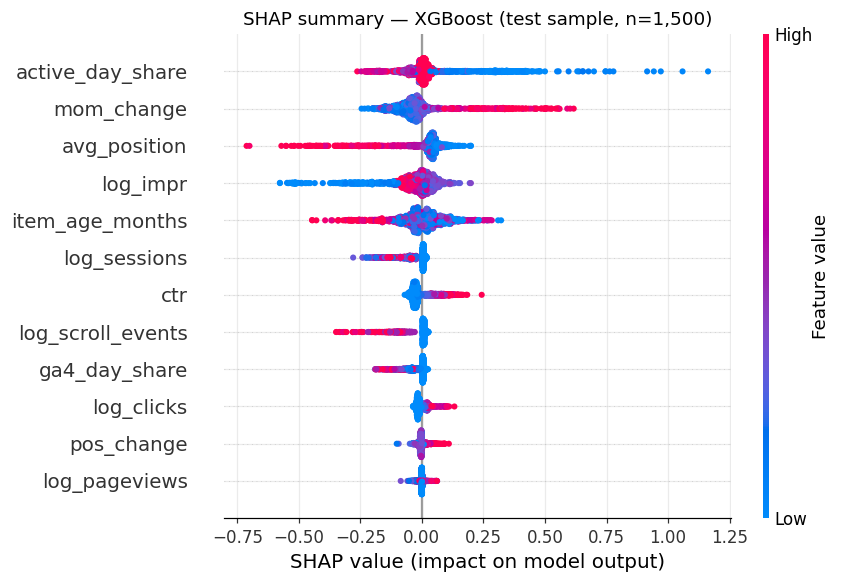

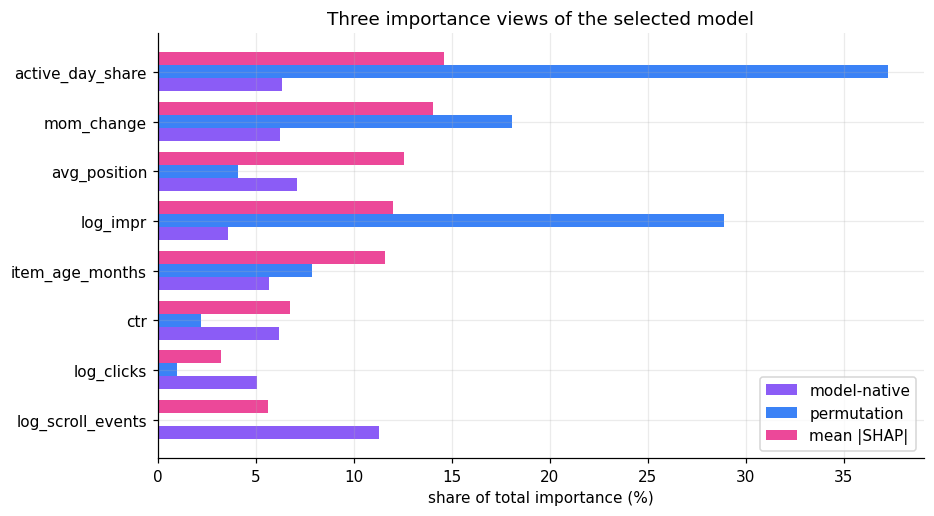

In [23]:
sel_model = MODELS[SELECTED]
native = pd.Series(sel_model.feature_importances_, index=FEATURES)
native_pct = 100 * native / native.sum()

def perm_importance(name, X, y, n_repeats=3, seed=SEED):
    rs = np.random.default_rng(seed)
    base_mae = float(np.abs(predict_model(name, X) - y).mean())
    out = {}
    for f in FEATURES:
        deltas = []
        for _ in range(n_repeats):
            # Shallow base + one temporary permuted column; avoid an extra full matrix copy.
            Xp = X.assign(**{f: rs.permutation(X[f].to_numpy())})
            deltas.append(float(np.abs(predict_model(name, Xp) - y).mean()) - base_mae)
            del Xp
        out[f] = float(np.mean(deltas))
    return pd.Series(out)

vs = D["validation"].sample(min(30_000, len(D["validation"])), random_state=SEED)
perm = perm_importance(SELECTED, vs[FEATURES], vs["y_delta"].to_numpy())
perm_pct = 100 * perm.clip(lower=0) / max(perm.clip(lower=0).sum(), 1e-12)

n_shap = 1500 if SELECTED == "XGBoost" else 400
Xs = D["test"][FEATURES].sample(min(n_shap, len(D["test"])), random_state=SEED).reset_index(drop=True)
if SELECTED == "XGBoost":
    it = int(sel_model.best_iteration)
    contrib = sel_model.get_booster().predict(xgb.DMatrix(Xs), pred_contribs=True, iteration_range=(0, it + 1))
    shap_vals = contrib[:, :-1]
else:
    import shap as _shap
    shap_vals = _shap.TreeExplainer(sel_model).shap_values(Xs)
shap_abs = pd.Series(np.abs(shap_vals).mean(axis=0), index=FEATURES)
shap_pct = 100 * shap_abs / shap_abs.sum()

imp = pd.DataFrame({"model_native_%": native_pct, "permutation_%": perm_pct, "mean_|SHAP|_%": shap_pct})
imp["mean_rank"] = imp.rank(ascending=False).mean(axis=1)
imp = imp.sort_values("mean_rank")
display(imp.head(12))

agree = {"native_vs_permutation": spearmanr(imp["model_native_%"], imp["permutation_%"]).statistic,
         "native_vs_shap": spearmanr(imp["model_native_%"], imp["mean_|SHAP|_%"]).statistic,
         "permutation_vs_shap": spearmanr(imp["permutation_%"], imp["mean_|SHAP|_%"]).statistic}
print("Rank agreement between importance methods (Spearman):", {k: round(float(v), 2) for k, v in agree.items()})
ga4_share = {"model_native": float(imp.loc[G_GA4, "model_native_%"].sum()), "permutation": float(imp.loc[G_GA4, "permutation_%"].sum()),
             "shap": float(imp.loc[G_GA4, "mean_|SHAP|_%"].sum())}
print("Combined share of importance carried by the 15 GA4/traffic features:", {k: f"{v:.1f}%" for k, v in ga4_share.items()})
# Are the GA4 features acting as a calendar proxy? (GA4 coverage rises over time, so "has GA4" can simply mean "late in training".)
_tr = D["train"]
ga4_time_rho = float(spearmanr(_tr["has_ga4"], _tr["month_idx"]).statistic)
ga4_time_rho_share = float(spearmanr(_tr["ga4_day_share"], _tr["month_idx"]).statistic)
print(f"Spearman(has_ga4, calendar month) in training = {ga4_time_rho:.2f}; Spearman(ga4_day_share, month) = {ga4_time_rho_share:.2f}  "
      "→ values well above 0 mean GA4 features can act as time indicators rather than as behavioural signals.")
RESULTS["importance"] = {"top_features": imp.head(10).round(3).reset_index().rename(columns={"index": "feature"}).to_dict(orient="records"),
                         "rank_agreement": {k: float(v) for k, v in agree.items()}, "ga4_importance_share": ga4_share,
                         "shap_sample_size": int(len(Xs)), "model_explained": SELECTED,
                         "ga4_time_proxy_rho": ga4_time_rho}

try:
    import shap
    plt.figure(figsize=(8, 5.4))
    shap.summary_plot(shap_vals, Xs, max_display=12, show=False, plot_size=None)
    plt.title(f"SHAP summary — {SELECTED} (test sample, n={len(Xs):,})")
    plt.tight_layout()
    savefig("fig06_shap_beeswarm")
except Exception as exc:                                          # plotting must never break the run
    print(f"[note] SHAP beeswarm skipped ({type(exc).__name__}); falling back to a bar chart.")
    top = shap_abs.sort_values().tail(12)
    plt.figure(figsize=(8, 5)); plt.barh(top.index, top.values, color=PALETTE["accent"])
    plt.xlabel("mean |SHAP|"); plt.title(f"Mean |SHAP| — {SELECTED}"); plt.tight_layout()
    savefig("fig06_shap_beeswarm")

top8 = imp.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.6, 4.8))
h = 0.26
yy = np.arange(len(top8))
ax.barh(yy - h, top8["model_native_%"], h, label="model-native", color=PALETTE["Random Forest"])
ax.barh(yy, top8["permutation_%"], h, label="permutation", color=PALETTE["Ridge"])
ax.barh(yy + h, top8["mean_|SHAP|_%"], h, label="mean |SHAP|", color=PALETTE["XGBoost"])
ax.set_yticks(yy); ax.set_yticklabels(top8.index); ax.set_xlabel("share of total importance (%)")
ax.set_title("Three importance views of the selected model"); ax.legend()
plt.tight_layout()
savefig("fig07_importance_agreement")

### 4.8 Error analysis — where is the model unreliable?

Error is broken down by current-impression quartile, **with the signed bias** (does it systematically over- or under-predict?) and the comparison against persistence in each band. The largest errors are then inspected to see whether they are zero-impression labels (an absent next-month row *or* a present row with zero impressions).

,current_impressions,rows,median_impressions,MAE_selected,MAE_persistence,bias (mean signed err),ΔMAE vs persistence [95% CI],verdict
0,"(0.999, 23.0]",99098,6.0000,1.1374,1.1422,0.5195,"-0.005 [-0.029, 0.010]",indistinguishable
1,"(23.0, 140.0]",95854,61.0000,1.1628,1.1739,0.7297,"-0.011 [-0.049, 0.024]",indistinguishable
2,"(140.0, 756.0]",97021,315.0000,0.8481,0.8570,0.5235,"-0.009 [-0.041, 0.027]",indistinguishable
3,"(756.0, 799358.0]",97280,"2,280.0000",0.6199,0.6406,0.3189,"-0.021 [-0.076, 0.029]",indistinguishable


Absolute error distribution: {'MAE': 0.942, 'median': 0.694, 'p90': 2.101, 'p95': 2.738, 'max': 9.152, 'mean_signed_error': 0.522}
Worst 1% of errors: 63.9% have zero next-month impressions (vs 9.6% of all test rows); 90.9% are over-predictions.


,impressions,next_impressions,pred_next_impr,avg_position,next_zero,next_missing,cur_cov,next_cov,abs_err
10015,"3,867.0000",0.0000,"9,432.9106",5.8477,True,False,1.0000,1.0000,9.1521
300634,"16,527.0000",2.0000,"9,596.6141",77.2702,False,False,1.0000,1.0000,8.0707
354879,"2,738.0000",0.0000,"2,902.8657",2.2075,True,False,1.0000,1.0000,7.9738
89022,"3,329.0000",0.0000,"2,864.8245",9.2691,True,False,1.0000,1.0000,7.9606
112103,"4,971.0000",0.0000,"2,507.8361",77.0760,True,False,1.0000,1.0000,7.8276
17659,"5,380.0000",1.0000,"4,549.8964",7.3810,False,False,1.0000,1.0000,7.7299
204536,"8,932.0000",3.0000,"8,998.2730",6.8071,False,False,1.0000,1.0000,7.7186
5209,"2,655.0000",0.0000,"2,191.0966",2.1608,True,False,1.0000,1.0000,7.6926
187210,471.0000,0.0000,"2,120.0984",30.4607,True,False,1.0000,1.0000,7.6597
174505,"2,471.0000",1.0000,"3,914.5165",2.1234,False,False,1.0000,1.0000,7.5796


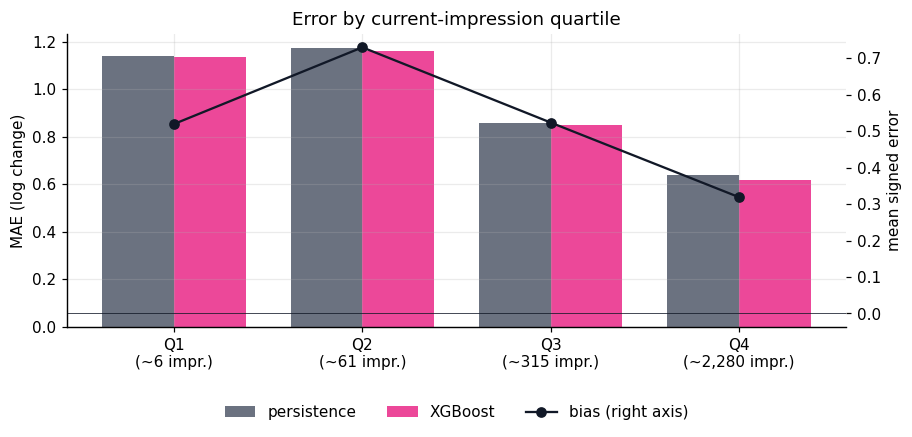

In [24]:
d_t = D["test"].copy()
d_t["pred_delta"] = preds["test"][SELECTED]
d_t["err"] = d_t["pred_delta"] - d_t["y_delta"]
d_t["abs_err"] = d_t["err"].abs()
d_t["abs_err_persist"] = d_t["y_delta"].abs()
d_t["pred_next_impr"] = np.expm1(d_t["log_impr"] + d_t["pred_delta"]).clip(lower=0)
d_t["band"] = pd.qcut(d_t["impressions"], 4, duplicates="drop")

band_rows = []
for b, g in d_t.groupby("band", observed=True):
    mask = (d_t["band"] == b).to_numpy()
    dd, lo_, hi_ = paired_diff(preds["test"][SELECTED], zero, mask, split="test")
    band_rows.append({"current_impressions": str(b), "rows": len(g), "median_impressions": g["impressions"].median(),
                      "MAE_selected": g["abs_err"].mean(), "MAE_persistence": g["abs_err_persist"].mean(),
                      "bias (mean signed err)": g["err"].mean(), "ΔMAE vs persistence [95% CI]": fmt_ci(dd, lo_, hi_),
                      "verdict": verdict(lo_, hi_)})
band_df = pd.DataFrame(band_rows)
display(band_df)

ae = d_t["abs_err"]
overall_err = {"MAE": float(ae.mean()), "median": float(ae.median()), "p90": float(ae.quantile(.9)),
               "p95": float(ae.quantile(.95)), "max": float(ae.max()), "mean_signed_error": float(d_t["err"].mean())}
print("Absolute error distribution:", {k: round(v, 3) for k, v in overall_err.items()})

top_cut = ae.quantile(0.99)
worst = d_t[ae >= top_cut]
tz_all, tz_worst = float(d_t["next_zero"].mean()), float(worst["next_zero"].mean())
over_worst = float((worst["err"] > 0).mean())
print(f"Worst 1% of errors: {tz_worst:.1%} have zero next-month impressions (vs {tz_all:.1%} of all test rows); "
      f"{over_worst:.1%} are over-predictions.")
show(worst.sort_values("abs_err", ascending=False)[["impressions", "next_impressions", "pred_next_impr", "avg_position",
                                                    "next_zero", "next_missing", "cur_cov", "next_cov", "abs_err"]], n=10)
RESULTS["error_analysis"] = {"bands": band_df.to_dict(orient="records"), "overall": overall_err,
                             "worst1pct_zero_label_share": tz_worst, "all_zero_label_share": tz_all,
                             "worst1pct_overprediction_share": over_worst}

fig, ax = plt.subplots(figsize=(8.4, 4.2))
xx = np.arange(len(band_df)); w = 0.38
ax.bar(xx - w / 2, band_df["MAE_persistence"], w, color=PALETTE["Persistence"], label="persistence")
ax.bar(xx + w / 2, band_df["MAE_selected"], w, color=PALETTE["XGBoost"], label=SELECTED)
ax2 = ax.twinx(); ax2.plot(xx, band_df["bias (mean signed err)"], color=PALETTE["ink"], marker="o", label="bias (right axis)")
ax2.axhline(0, color=PALETTE["ink"], lw=0.5); ax2.grid(False)
ax.set_xticks(xx); ax.set_xticklabels([f"Q{i + 1}\n(~{int(m):,} impr.)" for i, m in enumerate(band_df["median_impressions"])])
ax.set_ylabel("MAE (log change)"); ax2.set_ylabel("mean signed error"); ax.set_title("Error by current-impression quartile")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
plt.tight_layout()
savefig("fig08_error_by_band")

### 4.9 Robustness checks (no refitting — same predictions, stricter evaluation sets)

In [25]:
rob_rows = []
checks = {"all test rows": np.ones(len(d_t), bool),
          f"strict feed health (≥{ROBUSTNESS_COVERAGE:.0%} in current and next month)": ((d_t["cur_cov"] >= ROBUSTNESS_COVERAGE) & (d_t["next_cov"] >= ROBUSTNESS_COVERAGE)).to_numpy(),
          "excluding zero-impression labels (absent or present-but-zero)": (~d_t["next_zero"]).to_numpy(),
          "excluding the largest client": (d_t["client_hash_id"] != d_t["client_hash_id"].value_counts().index[0]).to_numpy(),
          "items with ≥ 2 prior months of history": (d_t["item_age_months"] >= 2).to_numpy(),
          "items with ≥ 100 impressions": (d_t["impressions"] >= 100).to_numpy()}
trend_t = preds["test"][TREND]
for label, mask in checks.items():
    if mask.sum() < 100 or len(np.unique(XY["test"]["groups"][mask])) < 2:
        continue
    dd, lo_, hi_ = paired_diff(preds["test"][SELECTED], zero, mask, split="test")
    dt_, tlo_, thi_ = paired_diff(preds["test"][SELECTED], trend_t, mask, split="test")
    rob_rows.append({"evaluation set": label, "rows": int(mask.sum()),
                     "MAE_selected": float(d_t.loc[mask, "abs_err"].mean()), "MAE_persistence": float(d_t.loc[mask, "abs_err_persist"].mean()),
                     "MAE_trend": float(np.abs(trend_t[mask] - XY["test"]["y"][mask]).mean()),
                     "ΔMAE vs persistence [95% CI]": fmt_ci(dd, lo_, hi_), "verdict vs persistence": verdict(lo_, hi_),
                     "ΔMAE vs trend [95% CI]": fmt_ci(dt_, tlo_, thi_), "verdict vs trend": verdict(tlo_, thi_)})
rob_df = pd.DataFrame(rob_rows)
display(rob_df)
RESULTS["robustness"] = rob_df.to_dict(orient="records")

,evaluation set,rows,MAE_selected,MAE_persistence,MAE_trend,ΔMAE vs persistence [95% CI],verdict vs persistence,ΔMAE vs trend [95% CI],verdict vs trend
0,all test rows,389253,0.9422,0.9536,0.8836,"-0.011 [-0.039, 0.017]",indistinguishable,"0.059 [0.026, 0.089]",worse
1,strict feed health (≥95% in current and next m...,389247,0.9422,0.9536,0.8836,"-0.011 [-0.039, 0.017]",indistinguishable,"0.059 [0.027, 0.088]",worse
2,excluding zero-impression labels (absent or pr...,351990,0.8235,0.8329,0.7819,"-0.009 [-0.039, 0.022]",indistinguishable,"0.042 [0.010, 0.072]",worse
3,excluding the largest client,329765,0.9899,0.9969,0.9214,"-0.007 [-0.041, 0.021]",indistinguishable,"0.069 [0.032, 0.094]",worse
4,items with ≥ 2 prior months of history,284129,0.8714,0.8720,0.7888,"-0.001 [-0.038, 0.031]",indistinguishable,"0.083 [0.053, 0.114]",worse
5,items with ≥ 100 impressions,214738,0.7643,0.7781,0.7013,"-0.014 [-0.053, 0.026]",indistinguishable,"0.063 [0.025, 0.102]",worse


### 4.10 Walk-forward retraining — the deployment protocol *(added after the first test evaluation)*

The single train/validation/test split asks a model trained once on 2025 to forecast 2026 — which cannot adapt when the market changes direction (§2.7). In deployment a forecast made at the end of month *t* would be produced by a model retrained on **every label already resolved by then**. This section evaluates exactly that, month by month across the validation **and** test months:

* **Walk-forward XGBoost:** for each forecast month *t*, fit on all labeled rows with feature month ≤ *t* − 1 (their labels are resolved by the end of *t*), predict month *t*.
* **Walk-forward XGBoost on the trend residual:** the same, but the model learns `y − trailing market change` and the prediction is `trend + model`. It asks whether **item-level signals add anything on top of the trend**.

**Honest labelling.** This protocol was added *after* the single-split test results were seen, so it is a **post-hoc design**: hyperparameters are exactly those tuned on the validation months (no new tuning), it is reported *alongside* — never instead of — the pre-registered single-split results of §4.3, and it should be read as a hypothesis for the next data window, not as a replacement verdict. Comparators are the same persistence and trend baselines.

Walk-forward retraining: 5 forecast months, 65 boosting rounds, hyperparameters from §4.2 (no new tuning).

Test months only:


,window,method,MAE [95% CI],weighted MAE,Δ vs persistence [95% CI],verdict vs persistence,Δ vs trend [95% CI],verdict vs trend
0,test months,Persistence (Δ = 0),"0.954 [0.855, 1.085]",0.5819,–,–,"0.070 [0.051, 0.090]",worse
1,test months,Trailing market Δ (previous month's median cha...,"0.884 [0.796, 1.006]",0.5126,"-0.070 [-0.090, -0.051]",better,–,–
2,test months,Static XGBoost (trained once on 2025),"0.942 [0.837, 1.076]",0.5780,"-0.011 [-0.039, 0.017]",indistinguishable,"0.059 [0.026, 0.089]",worse
3,test months,Walk-forward XGBoost,"0.905 [0.807, 1.037]",0.5500,"-0.048 [-0.067, -0.034]",better,"0.022 [0.000, 0.041]",worse
4,test months,Walk-forward XGBoost on trend residual,"0.856 [0.780, 0.957]",0.5466,"-0.098 [-0.144, -0.057]",better,"-0.028 [-0.058, 0.000]",indistinguishable



All out-of-sample months (validation + test):


,window,method,MAE [95% CI],weighted MAE,Δ vs persistence [95% CI],verdict vs persistence,Δ vs trend [95% CI],verdict vs trend
0,validation + test months,Persistence (Δ = 0),"0.862 [0.767, 1.013]",0.5106,–,–,"0.021 [0.002, 0.037]",worse
1,validation + test months,Trailing market Δ (previous month's median cha...,"0.841 [0.750, 0.992]",0.5012,"-0.021 [-0.037, -0.002]",better,–,–
2,validation + test months,Static XGBoost (trained once on 2025),"0.844 [0.744, 1.000]",0.5178,"-0.017 [-0.039, 0.007]",indistinguishable,"0.004 [-0.016, 0.024]",indistinguishable
3,validation + test months,Walk-forward XGBoost,"0.829 [0.732, 0.984]",0.5034,"-0.033 [-0.047, -0.015]",better,"-0.012 [-0.028, 0.004]",indistinguishable
4,validation + test months,Walk-forward XGBoost on trend residual,"0.813 [0.731, 0.955]",0.5167,"-0.048 [-0.074, -0.027]",better,"-0.028 [-0.043, -0.016]",better



Best walk-forward variant on the test months: Walk-forward XGBoost on trend residual (vs persistence: better; vs trend: indistinguishable).


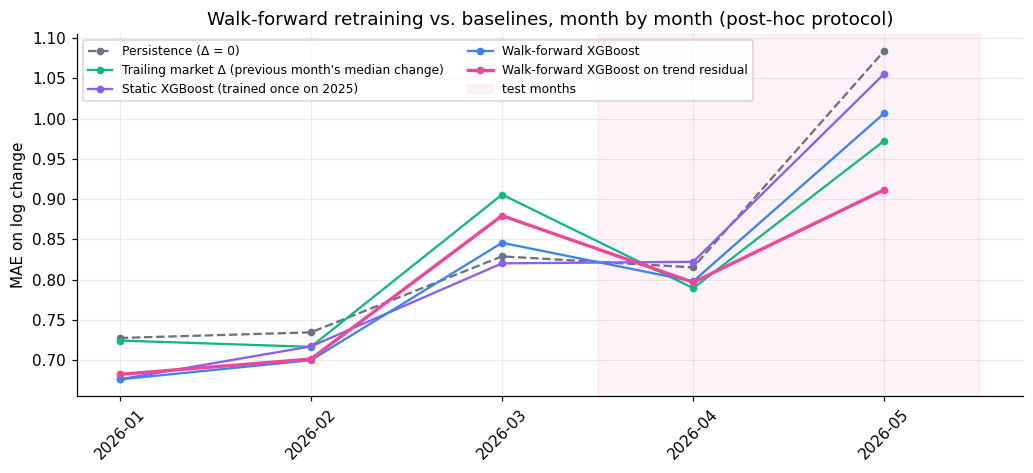

In [26]:
oos = pd.concat([D["validation"], D["test"]], ignore_index=True)
oos_months = sorted(oos["month_idx"].unique())
y_o, g_o, m_o = oos["y_delta"].to_numpy(float), oos["client_hash_id"].to_numpy(), oos["month_idx"].to_numpy()
w_o = oos["impressions"].to_numpy(float)
trend_o = trail_by_month.reindex(m_o - 1).fillna(med_delta).to_numpy()
WF_ROUNDS = max(int(RESULTS["selection"]["xgb_best_round"]), 50)

wf_level, wf_resid = np.zeros(len(oos)), np.zeros(len(oos))
for m in oos_months:
    tr_m = lab[lab["month_idx"] <= m - 1]                       # labels of these rows are resolved by the end of month m
    assert tr_m["month_idx"].max() <= m - 1, "walk-forward training set contains an unresolved label"
    te = m_o == m
    X_te = oos.loc[te, FEATURES]
    mdl = fit_xgb(XGB_GRID[best_i], tr_m[FEATURES], tr_m["y_delta"].to_numpy(float), n_estimators=WF_ROUNDS, early=False)
    wf_level[te] = xgb_predict(mdl, X_te)
    del mdl
    tr_trend = trail_by_month.reindex(tr_m["month_idx"] - 1).fillna(med_delta).to_numpy()
    mdl_r = fit_xgb(XGB_GRID[best_i], tr_m[FEATURES], tr_m["y_delta"].to_numpy(float) - tr_trend, n_estimators=WF_ROUNDS, early=False)
    wf_resid[te] = trend_o[te] + xgb_predict(mdl_r, X_te)
    del mdl_r, tr_m, X_te
    gc.collect()

STATIC = f"Static {SELECTED} (trained once on 2025)"
WF_LEVEL, WF_RESID = "Walk-forward XGBoost", "Walk-forward XGBoost on trend residual"          # always XGBoost (tuned hyperparameters), whichever model was selected
methods = {PERSIST: np.zeros(len(oos)), TREND: trend_o,
           STATIC: np.concatenate([preds["validation"][SELECTED], preds["test"][SELECTED]]),
           WF_LEVEL: wf_level, WF_RESID: wf_resid}
ae_o = {n: np.abs(p_ - y_o) for n, p_ in methods.items()}
test_idx = {month_idx(m) for m in SPLITS["test"]}
is_test_o = np.isin(m_o, list(test_idx))


def wf_table(mask, label):
    rows = []
    for n in methods:
        mae_, lo_, hi_ = cluster_bootstrap(ae_o[n][mask], g_o[mask])
        wm, wlo, whi = cluster_bootstrap_ratio(ae_o[n][mask] * w_o[mask], w_o[mask], g_o[mask])
        row = {"window": label, "method": n, "MAE [95% CI]": fmt_ci(mae_, lo_, hi_), "weighted MAE": wm, "_mae": mae_}
        for tag, ref in (("persistence", PERSIST), ("trend", TREND)):
            if n == ref:
                row[f"Δ vs {tag} [95% CI]"], row[f"verdict vs {tag}"] = "–", "–"
                continue
            d_, dlo, dhi = cluster_bootstrap((ae_o[n] - ae_o[ref])[mask], g_o[mask])
            row[f"Δ vs {tag} [95% CI]"], row[f"verdict vs {tag}"], row[f"_d_{tag}"] = fmt_ci(d_, dlo, dhi), verdict(dlo, dhi), (d_, dlo, dhi)
        rows.append(row)
    return pd.DataFrame(rows)


wf_test, wf_all = wf_table(is_test_o, "test months"), wf_table(np.ones(len(oos), bool), "validation + test months")
show_cols = lambda d: d[[c for c in d.columns if not c.startswith("_")]]
print(f"Walk-forward retraining: {len(oos_months)} forecast months, {WF_ROUNDS} boosting rounds, hyperparameters from §4.2 (no new tuning).")
print("\nTest months only:"); display(show_cols(wf_test))
print("\nAll out-of-sample months (validation + test):"); display(show_cols(wf_all))

by_month = (pd.DataFrame({"month_idx": m_o, **{n: a for n, a in ae_o.items()}}).groupby("month_idx").mean().reset_index())
by_month["month"] = [str(pd.Period(year=(i - 1) // 12, month=(i - 1) % 12 + 1, freq="M")) for i in by_month["month_idx"]]
wf_best = wf_test.loc[wf_test["method"].isin([WF_LEVEL, WF_RESID])].sort_values("_mae").iloc[0]
RESULTS["walk_forward"] = {"rounds": WF_ROUNDS, "months": [str(m) for m in by_month["month"]],
                           "test_table": wf_test.to_dict(orient="records"), "all_table": wf_all.to_dict(orient="records"),
                           "best_walk_forward_on_test": wf_best["method"], "post_hoc": True,
                           "by_month_mae": by_month.drop(columns="month_idx").to_dict(orient="records")}
print(f"\nBest walk-forward variant on the test months: {wf_best['method']} (vs persistence: {wf_best['verdict vs persistence']}; vs trend: {wf_best['verdict vs trend']}).")

fig, ax = plt.subplots(figsize=(9.5, 4.4))
styl = {PERSIST: (PALETTE["Persistence"], "--"), TREND: ("#10B981", "-"), STATIC: (PALETTE["Random Forest"], "-"),
        WF_LEVEL: (PALETTE["Ridge"], "-"), WF_RESID: (PALETTE["accent"], "-")}
for n, (c_, ls_) in styl.items():
    ax.plot(by_month["month"], by_month[n], color=c_, ls=ls_, marker="o", ms=4, lw=2.2 if n == WF_RESID else 1.5, label=n)
first_test = min(test_idx)
ax.axvspan(by_month.index[by_month["month_idx"] == first_test][0] - 0.5, len(by_month) - 0.5, color="#EC4899", alpha=0.07, label="test months")
ax.set_ylabel("MAE on log change"); ax.set_title("Walk-forward retraining vs. baselines, month by month (post-hoc protocol)")
ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
savefig("fig14_walk_forward")

# RESEARCH PILLAR 2
## **Structured Content Archetype Clustering**
### *Can content items be grouped into stable archetypes that separate next-month outcomes and add predictive value for human review?*

## 5. Performance archetypes → actions (and a test of whether they mean anything)

**Design.** Archetypes group content items by *how they currently perform*, using five transformed signals: `log1p(impressions)`, `log1p(clicks)`, `sqrt(CTR)`, `log(position)` and clipped month-over-month change. (Raw counts are heavy-tailed; log/sqrt transforms stop a handful of outliers from defining the clusters. GA4 features are excluded because they are mostly zeros in training — see §2.8.)

**Micro-volume items are not clustered.** Items with fewer than `CLUSTER_MIN_IMPR` impressions have a CTR and a month-over-month change that are counting noise (one click on 20 impressions is a 5% "CTR"), and in earlier runs they formed spurious "performer" clusters. They form an explicit micro-volume bucket mapped to *Monitor*.

**How *k* is chosen (rule fixed in advance).** Candidates k = 3…8. A candidate is *eligible* if (i) its smallest cluster holds ≥ 3% of rows and (ii) clustering is **stable** — two models fit on disjoint halves of the training data agree on a hold-out sample (adjusted Rand index ≥ 0.60). Among eligible candidates the best silhouette wins; if none is eligible the notebook says so and falls back to the most stable candidate.

**Names are behavioural, not semantic.** Each cluster is named by rules applied to its **training-set medians** (volume, momentum, position, CTR relative to the client's *peer expectation* from §2.6) — never by page type, which the release does not contain. Each name maps to a playbook action. *Merge* needs query- or text-level overlap the release does not contain, so consolidation appears only as a monitored "review" note.

**Validation gate (fixed in advance).** Archetypes are only used as *evidence* if, on the **held-out test months**, (a) the archetype label explains at least 2% of the variance of next-month change (η²) beyond a permutation null (p < 0.01), **and** (b) predicting each item's change by its archetype's training-median change **beats persistence** (paired, client-clustered). Otherwise they are reported as **descriptive only** and the action map is presented as a review heuristic, not a validated policy.

In [27]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

for s_ in SPLITS:
    exp_ = D[s_]["expected_ctr"].to_numpy()
    D[s_]["ctr_ratio"] = np.where(exp_ > 0, D[s_]["ctr"].to_numpy() / np.where(exp_ > 0, exp_, 1.0), np.nan)

CLUSTER_FEATS = ["log impressions", "log clicks", "sqrt CTR", "log position", "momentum (clipped)"]

def cluster_matrix(df):
    return np.column_stack([df["log_impr"], df["log_clicks"], np.sqrt(df["ctr"].clip(0, 1)),
                            np.log(df["avg_position"].clip(lower=1)), df["mom_change"].clip(-3, 3)])

fit_tr = (D["train"]["impressions"] >= CLUSTER_MIN_IMPR).to_numpy()          # micro-volume items are NOT clustered (counting noise)
scaler_c = StandardScaler().fit(cluster_matrix(D["train"])[fit_tr])
Z = {s: scaler_c.transform(cluster_matrix(D[s])) for s in SPLITS}
Z_tr = Z["train"][fit_tr]

rs = np.random.default_rng(SEED)
n_tr = len(Z_tr)
idx_fit  = rs.choice(n_tr, size=min(100_000, n_tr), replace=False)
idx_sil  = rs.choice(n_tr, size=min(15_000, n_tr), replace=False)
idx_hold = rs.choice(n_tr, size=min(30_000, n_tr), replace=False)
perm_idx = rs.permutation(n_tr)
half_a, half_b = perm_idx[: n_tr // 2][:50_000], perm_idx[n_tr // 2:][:50_000]

sel_rows = []
for k in range(3, 9):
    km = MiniBatchKMeans(n_clusters=k, random_state=SEED, batch_size=4096, n_init=5).fit(Z_tr[idx_fit])
    sil = float(silhouette_score(Z_tr[idx_sil], km.predict(Z_tr[idx_sil])))
    ka = MiniBatchKMeans(n_clusters=k, random_state=SEED, batch_size=4096, n_init=5).fit(Z_tr[half_a])
    kb = MiniBatchKMeans(n_clusters=k, random_state=SEED + 1, batch_size=4096, n_init=5).fit(Z_tr[half_b])
    ari = float(adjusted_rand_score(ka.predict(Z_tr[idx_hold]), kb.predict(Z_tr[idx_hold])))
    min_share = float(np.bincount(km.predict(Z_tr[idx_hold]), minlength=k).min() / len(idx_hold))
    sel_rows.append({"k": k, "silhouette": sil, "stability_ARI": ari, "smallest_cluster_share": min_share,
                     "eligible": (min_share >= 0.03) and (ari >= 0.60)})
sel_df = pd.DataFrame(sel_rows)
elig = sel_df[sel_df["eligible"]]
if len(elig):
    K = int(elig.loc[elig["silhouette"].idxmax(), "k"]); caveat = None
else:
    K = int(sel_df.loc[sel_df["stability_ARI"].idxmax(), "k"])
    caveat = "No candidate met the stability / minimum-size rule; the most stable k was used and archetypes should be read as indicative."
display(sel_df.assign(chosen=lambda d: np.where(d["k"] == K, "◄ chosen", "")))
print(f"Selected k = {K}" + (f"   ⚠ {caveat}" if caveat else ""))

archetype_model = MiniBatchKMeans(n_clusters=K, random_state=SEED, batch_size=4096, n_init=10).fit(Z_tr)
MICRO_NAME = f"Micro-volume (< {CLUSTER_MIN_IMPR} impressions)"


def assign_archetypes(df):
    """Cluster id 0..K-1 for items with enough volume; id K (the micro-volume bucket) for the rest."""
    ids = archetype_model.predict(scaler_c.transform(cluster_matrix(df)))
    return np.where(df["impressions"].to_numpy() >= CLUSTER_MIN_IMPR, ids, K)


for s_ in SPLITS:
    D[s_]["arch_id"] = assign_archetypes(D[s_])
print(f"Micro-volume bucket (< {CLUSTER_MIN_IMPR} impressions, not clustered): "
      + ", ".join(f"{s}: {(D[s]['arch_id'] == K).mean():.1%} of rows" for s in SPLITS))

,k,silhouette,stability_ARI,smallest_cluster_share,eligible,chosen
0,3,0.2772,0.5040,0.2344,False,
1,4,0.2856,0.4671,0.1699,False,
2,5,0.2782,0.5507,0.0795,False,
3,6,0.2769,0.5580,0.0960,False,
4,7,0.2859,0.5982,0.0857,False,
5,8,0.2843,0.7304,0.0430,True,◄ chosen


Selected k = 8
Micro-volume bucket (< 30 impressions, not clustered): train: 35.3% of rows, validation: 30.4% of rows, test: 28.1% of rows


### 5.1a Alternative clustering model — Gaussian Mixture Model

K-means remains the primary reference so the original study stays auditable. A diagonal-covariance GMM is added as a probabilistic challenger over the same five standardized features and the same training-only non-micro population. Component count is selected **without test outcomes**: candidates must meet the same minimum-share and stability thresholds, then the best held-out-within-training average log likelihood is preferred; BIC is retained as an additional training-fit diagnostic. Independent training halves are compared on a shared training holdout with adjusted Rand index. The final GMM is fitted on a training-only sample and then used only to assign validation/test observations. The micro-volume bucket remains separate.

In [28]:
from sklearn.mixture import GaussianMixture

GMM_COVARIANCE = "diag"
gmm_rng = np.random.default_rng(SEED + 220)
all_train_nonmicro = np.arange(len(Z_tr))
gmm_fit_idx = gmm_rng.choice(all_train_nonmicro, size=min(60_000, len(all_train_nonmicro)), replace=False)
remaining_gmm = np.setdiff1d(all_train_nonmicro, gmm_fit_idx, assume_unique=False)
gmm_eval_idx = gmm_rng.choice(remaining_gmm, size=min(12_000, len(remaining_gmm)), replace=False)
perm_gmm = gmm_rng.permutation(all_train_nonmicro)
half_n = min(25_000, len(perm_gmm) // 3)
half_a_gmm, half_b_gmm = perm_gmm[:half_n], perm_gmm[half_n:2 * half_n]
hold_gmm = perm_gmm[2 * half_n:2 * half_n + min(10_000, len(perm_gmm) - 2 * half_n)]


def make_gmm(k, seed):
    return GaussianMixture(n_components=k, covariance_type=GMM_COVARIANCE, reg_covar=1e-4,
                           n_init=2, max_iter=250, random_state=seed, init_params="kmeans")


gmm_candidates = []
for k in range(3, 9):
    model_fit = make_gmm(k, SEED + k).fit(Z_tr[gmm_fit_idx])
    heldout_ll = float(model_fit.score(Z_tr[gmm_eval_idx]))
    bic_train = float(model_fit.bic(Z_tr[gmm_fit_idx]))

    model_a = make_gmm(k, SEED + 100 + k).fit(Z_tr[half_a_gmm])
    model_b = make_gmm(k, SEED + 200 + k).fit(Z_tr[half_b_gmm])
    labels_a = model_a.predict(Z_tr[hold_gmm])
    labels_b = model_b.predict(Z_tr[hold_gmm])
    ari = float(adjusted_rand_score(labels_a, labels_b))
    shares_a = np.bincount(labels_a, minlength=k) / max(1, len(labels_a))
    shares_b = np.bincount(labels_b, minlength=k) / max(1, len(labels_b))
    min_share = float(min(shares_a.min(), shares_b.min()))
    gmm_candidates.append({"k": k, "heldout_train_loglik_per_row": heldout_ll,
                           "training_BIC": bic_train, "stability_ARI": ari,
                           "smallest_cluster_share": min_share,
                           "eligible": bool(ari >= 0.60 and min_share >= 0.03)})
    del model_fit, model_a, model_b
    gc.collect()

gmm_selection_df = pd.DataFrame(gmm_candidates)
gmm_eligible = gmm_selection_df[gmm_selection_df["eligible"]]
if len(gmm_eligible):
    GMM_K = int(gmm_eligible.sort_values(["heldout_train_loglik_per_row", "stability_ARI"], ascending=False).iloc[0]["k"])
    GMM_CAVEAT = None
else:
    GMM_K = int(gmm_selection_df.sort_values(["stability_ARI", "heldout_train_loglik_per_row"], ascending=False).iloc[0]["k"])
    GMM_CAVEAT = "No GMM component count met both pre-set training stability and minimum-share rules; treat this challenger as indicative."

display(gmm_selection_df.assign(chosen=lambda d: np.where(d["k"] == GMM_K, "◄ chosen", "")))

# Final GMM uses training data only. It never sees validation/test outcomes.
gmm_final_idx = gmm_rng.choice(all_train_nonmicro, size=min(100_000, len(all_train_nonmicro)), replace=False)
gmm_model = make_gmm(GMM_K, SEED + 500).fit(Z_tr[gmm_final_idx])
GMM_MICRO_ID = GMM_K
for split_name in SPLITS:
    is_clusterable = (D[split_name]["impressions"].to_numpy(float) >= CLUSTER_MIN_IMPR)
    assigned = np.full(len(D[split_name]), GMM_MICRO_ID, dtype=int)
    if is_clusterable.any():
        assigned[is_clusterable] = gmm_model.predict(Z[split_name][is_clusterable])
    D[split_name]["gmm_arch_id"] = assigned

print(f"GMM selected components: {GMM_K}; covariance={GMM_COVARIANCE}; micro-volume remains cluster {GMM_MICRO_ID}.")
if GMM_CAVEAT:
    print("Caveat:", GMM_CAVEAT)
RESULTS["gmm_selection"] = {"k": GMM_K, "covariance_type": GMM_COVARIANCE,
                            "selection": gmm_selection_df.to_dict(orient="records"), "caveat": GMM_CAVEAT,
                            "fit_sample_rows": int(len(gmm_final_idx)),
                            "selection_rule": "training-only stability/minimum share; held-out-within-training log likelihood; BIC diagnostic"}

,k,heldout_train_loglik_per_row,training_BIC,stability_ARI,smallest_cluster_share,eligible,chosen
0,3,-1.9292,"233,354.4220",1.0000,0.0519,True,
1,4,-1.6902,"203,309.5175",0.9787,0.0519,True,
2,5,-1.3683,"166,531.0624",0.9541,0.0062,False,
3,6,-1.2269,"149,578.5040",0.4615,0.0517,False,
4,7,-1.0901,"132,497.8847",0.9714,0.0519,True,
5,8,-0.7035,"87,141.7673",0.9767,0.0507,True,◄ chosen


GMM selected components: 8; covariance=diag; micro-volume remains cluster 8.


### 5.2 Name and profile the primary K-means archetypes

Names are based on the training-set medians of the five clustering signals and are intentionally behavioural, not semantic. The release does not contain page type, page text or query-level intent. The associated action map is therefore a human-review heuristic. GMM labels are evaluated separately and are not substituted into the operational queue based on test results.

In [29]:
ACTION_MAP = {
    "Page-one performer":           ("Protect",           "Keep stable; monitor for decline; avoid unnecessary rewrites."),
    "Visible but under-clicked":    ("Improve",           "Review title / meta description and snippet fit for the dominant queries."),
    "Low-volume, under-clicked":    ("Monitor",           "Low volume: monitor before investing; consider consolidation if it stays flat."),
    "Mid-pack / striking distance": ("Improve",           "Review content depth, internal links and intent match to move toward page one."),
    "Buried (deep positions)":      ("Rewrite",           "Review intent match; consider re-targeting or a substantive rewrite."),
    "Declining":                    ("Refresh / rewrite", "Review for staleness, intent drift or competitor changes."),
    "Growing":                      ("Protect",           "Protect momentum: avoid disruptive edits; review internal linking to reinforce."),
    "New / re-emerging":            ("Monitor",           "Monitor early performance; confirm the gain is durable before investing."),
    "Long-tail / low-signal":       ("Monitor",           "Monitor; if no recovery over several months, review for consolidation or pruning."),
    MICRO_NAME:                     ("Monitor",           "Too few impressions for a reliable monthly change: monitor, do not edit; consolidate if it stays flat."),
}
impr_p25 = float(D["train"].loc[fit_tr, "impressions"].quantile(0.25))      # reference = the clustered (non-micro) population
impr_p50 = float(D["train"].loc[fit_tr, "impressions"].quantile(0.50))

def name_cluster(st):
    if st["median_impressions"] <= impr_p25:        return "Long-tail / low-signal"
    if st["median_mom_change"] <= -0.30:            return "Declining"
    if st["median_mom_change"] >= 1.00:             return "New / re-emerging"
    if st["median_mom_change"] >= 0.30:             return "Growing"
    if st["median_position"] > 30:                  return "Buried (deep positions)"
    if st["median_ctr_ratio"] < 0.5:                return "Visible but under-clicked" if st["median_impressions"] >= impr_p50 else "Low-volume, under-clicked"
    if st["median_position"] <= 10 and st["median_ctr_ratio"] >= 1.0: return "Page-one performer"
    return "Mid-pack / striking distance"

tr_stats = (D["train"][D["train"]["arch_id"] < K].groupby("arch_id")
            .agg(median_impressions=("impressions", "median"), median_position=("avg_position", "median"),
                 median_ctr_ratio=("ctr_ratio", "median"), median_mom_change=("mom_change", "median")))
raw_names = {cid: name_cluster(row) for cid, row in tr_stats.iterrows()}
name_counts = pd.Series(raw_names).value_counts()
names, running = {}, {}
for cid, base in raw_names.items():
    if name_counts[base] > 1:                      # several clusters share a behavioural name -> (A), (B), ...
        running[base] = running.get(base, 0) + 1
        names[cid] = f"{base} ({chr(64 + running[base])})"
    else:
        names[cid] = base
names[K] = MICRO_NAME

def base_of(name):
    return re.sub(r" \([A-Z]\)$", "", name)

for s_ in SPLITS:
    D[s_]["archetype"] = D[s_]["arch_id"].map(names)

tr_med = D["train"].groupby("archetype").agg(median_impressions_train=("impressions", "median"), median_position_train=("avg_position", "median"))
prof = (D["test"].groupby("archetype")
        .agg(rows=("log_impr", "size"), median_impressions=("impressions", "median"), median_ctr=("ctr", "median"),
             median_position=("avg_position", "median"), median_ctr_vs_peers=("ctr_ratio", "median"),
             median_mom_change=("mom_change", "median"), median_actual_change=("y_delta", "median"),
             share_fell_40pct=("y_delta", lambda s: float((s <= np.log(0.6)).mean())),
             share_zero_label=("next_zero", "mean")).reset_index()
        .merge(tr_med.reset_index(), on="archetype", how="left"))
prof["share_of_test_rows"] = prof["rows"] / prof["rows"].sum()
prof["action"] = prof["archetype"].map(lambda n: ACTION_MAP[base_of(n)][0])
prof["what_to_review"] = prof["archetype"].map(lambda n: ACTION_MAP[base_of(n)][1])
prof = prof.sort_values("share_of_test_rows", ascending=False).reset_index(drop=True)
display(prof.drop(columns=["what_to_review"]))

te_fit = (D["test"]["arch_id"] < K).to_numpy()
te_idx_all = np.flatnonzero(te_fit)
te_sil_idx = np.random.default_rng(SEED + 51).choice(te_idx_all, size=min(15_000, len(te_idx_all)), replace=False)
sil_test = float(silhouette_score(Z["test"][te_sil_idx], D["test"]["arch_id"].to_numpy()[te_sil_idx])) if K > 1 and len(te_sil_idx) > K else float("nan")
print(f"Silhouette on a random held-out non-micro sample (n={len(te_sil_idx):,}): {sil_test:.3f}")

,archetype,rows,median_impressions,median_ctr,median_position,median_ctr_vs_peers,median_mom_change,median_actual_change,share_fell_40pct,share_zero_label,median_impressions_train,median_position_train,share_of_test_rows,action
0,Micro-volume (< 30 impressions),109563,7.0000,0.0000,10.3333,0.0000,0.0000,-0.6931,0.5381,0.2918,5.0000,10.0000,0.2815,Monitor
1,Buried (deep positions),74817,155.0000,0.0000,33.7882,0.0000,-0.2382,-0.5008,0.4951,0.0219,160.0000,42.6562,0.1922,Rewrite
2,Mid-pack / striking distance (B),56288,849.0000,0.0024,10.8726,1.0036,-0.2009,-0.4568,0.4679,0.0012,677.0000,8.0451,0.1446,Improve
3,"Low-volume, under-clicked",50686,132.0000,0.0000,8.8421,0.0000,-0.2231,-0.6457,0.5568,0.0425,126.0000,7.4752,0.1302,Monitor
4,Mid-pack / striking distance (A),34673,"3,429.0000",0.0028,7.4290,0.9939,-0.0016,-0.3321,0.3845,0.0001,"2,475.0000",5.7575,0.0891,Improve
5,Long-tail / low-signal,18562,94.0000,0.0000,27.4014,0.0000,3.8918,-0.3728,0.4613,0.0544,100.0000,35.2130,0.0477,Monitor
6,Page-one performer (B),15773,"9,101.0000",0.0056,6.0029,1.4275,0.0600,-0.1711,0.2447,0.0000,"6,296.5000",5.2683,0.0405,Protect
7,Page-one performer (A),15504,113.0000,0.0146,11.8447,5.7187,0.0000,-0.2094,0.3696,0.0193,118.0000,9.4524,0.0398,Protect
8,New / re-emerging,13387,434.0000,0.0032,7.2160,1.0632,5.2558,0.0129,0.3341,0.0087,320.0000,5.1571,0.0344,Monitor


Silhouette on a random held-out non-micro sample (n=15,000): 0.232


### 5.3 Do archetypes separate and forecast next-month outcomes?

This is the key inferential step for Pillar 02. Test outcomes are not used to fit either cluster model or select its component count. For each method, report (1) η² on all held-out non-micro rows, (2) a within-client-month permutation p-value computed on a deterministic client-capped test sample, (3) the MAE of cluster-median forecasts whose medians are learned from training outcomes only, and (4) paired client-clustered comparisons against persistence **and** trailing-market change. The within-client-month permutation preserves both the client and feature-month strata, controlling for client-specific level differences and market-wide monthly shocks when testing whether cluster membership aligns with next-month outcomes.

The primary K-means gate is deliberately strict: training stability and cluster-size rules, held-out silhouette ≥ 0.10, η² ≥ 0.02, Holm-adjusted permutation p < 0.01, and a cluster-median forecast that beats both baselines. Failing a gate means “descriptive only,” not “no useful exploratory pattern.” GMM is judged by the same criteria as a replication/challenger; it does not change the pre-existing K-means queue labels.

,method,k,train stability ARI,minimum train holdout share,test silhouette,test η² (non-micro),within-client-month permutation p (Holm),cluster-median MAE,ΔMAE vs persistence,vs persistence verdict,ΔMAE vs trend,vs trend verdict,passed full gate
0,K-means,8,0.7304,0.0430,0.2315,0.0354,0.0010,0.9927,"0.039 [0.030, 0.046]",worse,"0.109 [0.087, 0.131]",worse,False
1,GMM,8,0.9767,0.0507,0.1865,0.0482,0.0010,0.9981,"0.045 [0.033, 0.054]",worse,"0.115 [0.089, 0.139]",worse,False


Primary K-means gate: NOT PASSED — use as descriptive review context only
GMM challenger gate: NOT PASSED — use as descriptive/sensitivity evidence only


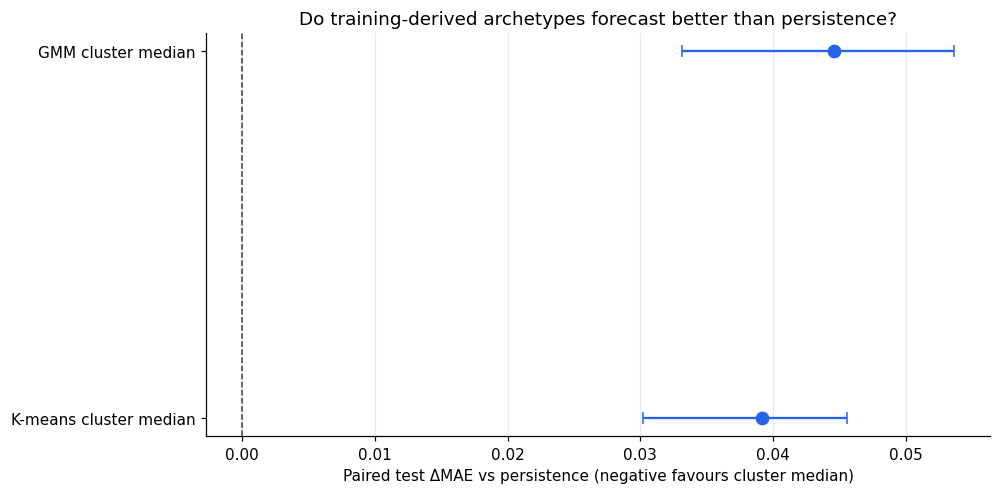

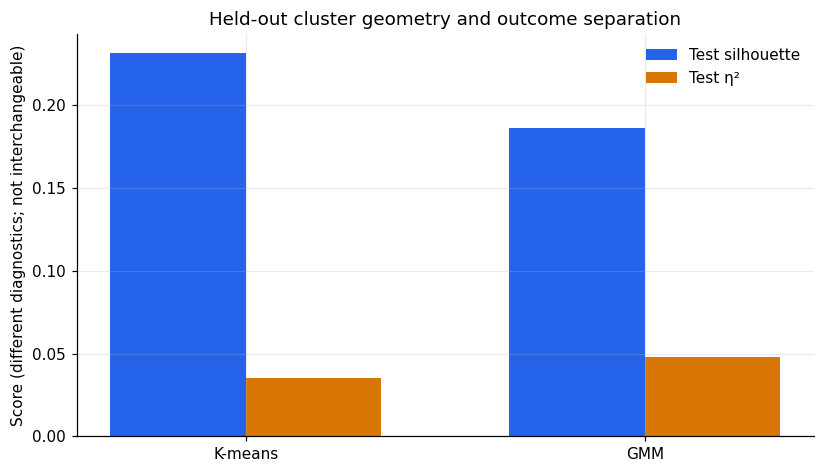

In [30]:
def eta_squared(y, codes, n_groups):
    y = np.asarray(y, dtype=float)
    codes = np.asarray(codes, dtype=int)
    n_k = np.bincount(codes, minlength=n_groups).astype(float)
    mean_k = np.bincount(codes, weights=y, minlength=n_groups) / np.maximum(n_k, 1)
    ss_between = float((n_k * (mean_k - y.mean()) ** 2).sum())
    ss_total = float(((y - y.mean()) ** 2).sum())
    return ss_between / ss_total if ss_total > 0 else 0.0


def client_capped_indices(df, max_per_client=100, max_total=30_000, seed=SEED):
    rng = np.random.default_rng(seed)
    picked = []
    for idx in df.groupby("client_hash_id", sort=False).indices.values():
        idx = np.asarray(idx, dtype=int)
        take = min(max_per_client, len(idx))
        picked.extend(rng.choice(idx, size=take, replace=False).tolist())
    picked = np.asarray(picked, dtype=int)
    if len(picked) > max_total:
        picked = rng.choice(picked, size=max_total, replace=False)
    return np.sort(picked)


def within_client_permutation_eta(df, code_col, n_groups, B=1999, seed=SEED):
    """Permute outcomes within client-month strata; report the sampled eta² and Monte Carlo p-value."""
    idx = client_capped_indices(df, max_per_client=100, max_total=30_000, seed=seed)
    sample = df.iloc[idx]
    y = sample["y_delta"].to_numpy(float)
    codes = sample[code_col].to_numpy(int)
    # Preserve both client and feature-month strata, so market-wide monthly shocks
    # and the within-client outcome distribution are fixed under the null.
    strata = pd.MultiIndex.from_frame(sample[["client_hash_id", "month"]])
    stratum_codes, unique_strata = pd.factorize(strata, sort=False)
    observed = eta_squared(y, codes, n_groups)
    groups = [np.flatnonzero(stratum_codes == g) for g in range(len(unique_strata))]
    groups = [g for g in groups if len(g) > 1]
    if len(groups) < 2:
        return observed, float("nan"), int(len(idx)), int(len(groups))
    rng = np.random.default_rng(seed + 1)
    null = np.empty(B, dtype=float)
    for b in range(B):
        yp = y.copy()
        for positions in groups:
            yp[positions] = rng.permutation(yp[positions])
        null[b] = eta_squared(yp, codes, n_groups)
    p = float((1 + np.sum(null >= observed)) / (B + 1))
    return observed, p, int(len(idx)), int(len(groups))


def cluster_median_prediction(train_df, test_df, code_col):
    medians = train_df.groupby(code_col)["y_delta"].median()
    return test_df[code_col].map(medians).fillna(med_delta).to_numpy(float)


def test_silhouette_random(split, code_col, seed, max_n=12_000):
    mask = D[split]["impressions"].to_numpy(float) >= CLUSTER_MIN_IMPR
    positions = np.flatnonzero(mask)
    rng = np.random.default_rng(seed)
    take = rng.choice(positions, size=min(max_n, len(positions)), replace=False)
    labels = D[split][code_col].to_numpy(int)[take]
    if len(np.unique(labels)) < 2 or len(take) <= len(np.unique(labels)):
        return float("nan"), int(len(take))
    return float(silhouette_score(Z[split][take], labels)), int(len(take))


# Non-micro held-out rows are used for cluster-outcome separation so that the
# explicit monitoring bucket cannot create a spurious cluster effect.
nonmicro_test = D["test"][D["test"]["impressions"] >= CLUSTER_MIN_IMPR].copy().reset_index(drop=True)
method_specs = [
    ("K-means", "arch_id", K, float(sel_df.loc[sel_df["k"] == K, "stability_ARI"].iloc[0]),
     float(sel_df.loc[sel_df["k"] == K, "smallest_cluster_share"].iloc[0])),
    ("GMM", "gmm_arch_id", GMM_K,
     float(gmm_selection_df.loc[gmm_selection_df["k"] == GMM_K, "stability_ARI"].iloc[0]),
     float(gmm_selection_df.loc[gmm_selection_df["k"] == GMM_K, "smallest_cluster_share"].iloc[0]))
]

method_results = {}
for method_name, code_col, n_clusters, stability_ari, min_share in method_specs:
    codes_non = nonmicro_test[code_col].to_numpy(int)
    y_non = nonmicro_test["y_delta"].to_numpy(float)
    eta_full = eta_squared(y_non, codes_non, n_clusters)
    eta_sample, p_raw, perm_rows, perm_clients = within_client_permutation_eta(
        nonmicro_test, code_col, n_clusters, B=1999, seed=SEED + (0 if method_name == "K-means" else 10)
    )
    cluster_pred = cluster_median_prediction(D["train"], D["test"], code_col)
    d_p, lo_p, hi_p = paired_diff(cluster_pred, preds["test"][PERSIST], "test")
    d_t, lo_t, hi_t = paired_diff(cluster_pred, preds["test"][TREND], "test")
    mae = float(np.abs(cluster_pred - XY["test"]["y"]).mean())
    macro_mae = score_split(cluster_pred, "test")["Macro_MAE"]
    sil, sil_n = test_silhouette_random("test", code_col, SEED + (51 if method_name == "K-means" else 52))
    method_results[method_name] = {
        "code_col": code_col, "n_clusters": int(n_clusters), "stability_ARI": stability_ari,
        "smallest_training_holdout_share": min_share, "test_silhouette": sil, "silhouette_rows": sil_n,
        "eta_squared_nonmicro_test": eta_full, "within_client_permutation_eta_sample": eta_sample,
        "within_client_month_permutation_p_raw": p_raw, "permutation_rows": perm_rows,
        "permutable_client_month_strata": perm_clients, "cluster_median_MAE_all_test": mae,
        "cluster_median_macro_client_MAE": macro_mae,
        "vs_persistence": {"diff": d_p, "lo": lo_p, "hi": hi_p, "verdict": verdict(lo_p, hi_p)},
        "vs_trend": {"diff": d_t, "lo": lo_t, "hi": hi_t, "verdict": verdict(lo_t, hi_t)},
        "prediction": cluster_pred
    }

cluster_p = [method_results[m]["within_client_month_permutation_p_raw"] for m in ("K-means", "GMM")]
cluster_p_adj = holm_adjust(cluster_p)
for j, method_name in enumerate(("K-means", "GMM")):
    method_results[method_name]["within_client_permutation_p_holm"] = float(cluster_p_adj[j])

km_sel = sel_df.loc[sel_df["k"] == K].iloc[0]
gmm_sel = gmm_selection_df.loc[gmm_selection_df["k"] == GMM_K].iloc[0]

def cluster_gate_pass(m):
    return bool(
        m["stability_ARI"] >= 0.60
        and m["smallest_training_holdout_share"] >= 0.03
        and np.isfinite(m["test_silhouette"]) and m["test_silhouette"] >= 0.10
        and m["eta_squared_nonmicro_test"] >= 0.02
        and np.isfinite(m["within_client_permutation_p_holm"]) and m["within_client_permutation_p_holm"] < 0.01
        and m["vs_persistence"]["verdict"] == "better"
        and m["vs_trend"]["verdict"] == "better"
    )

for method_name in ("K-means", "GMM"):
    method_results[method_name]["validated"] = cluster_gate_pass(method_results[method_name])

ARCHETYPES_VALIDATED = method_results["K-means"]["validated"]
GMM_ARCHETYPES_VALIDATED = method_results["GMM"]["validated"]

cluster_comparison = pd.DataFrame([
    {"method": name, "k": m["n_clusters"], "train stability ARI": m["stability_ARI"],
     "minimum train holdout share": m["smallest_training_holdout_share"],
     "test silhouette": m["test_silhouette"], "test η² (non-micro)": m["eta_squared_nonmicro_test"],
     "within-client-month permutation p (Holm)": m["within_client_permutation_p_holm"],
     "cluster-median MAE": m["cluster_median_MAE_all_test"],
     "ΔMAE vs persistence": fmt_ci(m["vs_persistence"]["diff"], m["vs_persistence"]["lo"], m["vs_persistence"]["hi"]),
     "vs persistence verdict": m["vs_persistence"]["verdict"],
     "ΔMAE vs trend": fmt_ci(m["vs_trend"]["diff"], m["vs_trend"]["lo"], m["vs_trend"]["hi"]),
     "vs trend verdict": m["vs_trend"]["verdict"], "passed full gate": m["validated"]}
    for name, m in method_results.items()
])
display(cluster_comparison)
print("Primary K-means gate:", "PASSED" if ARCHETYPES_VALIDATED else "NOT PASSED — use as descriptive review context only")
print("GMM challenger gate:", "PASSED" if GMM_ARCHETYPES_VALIDATED else "NOT PASSED — use as descriptive/sensitivity evidence only")

# Figures: cluster-median forecast errors, and held-out η² / silhouette comparison.
fig, ax = plt.subplots(figsize=(9.2, 4.6))
xx = np.arange(2)
vals_p = [method_results[n]["vs_persistence"]["diff"] for n in ("K-means", "GMM")]
los_p = [vals_p[j] - method_results[n]["vs_persistence"]["lo"] for j, n in enumerate(("K-means", "GMM"))]
his_p = [method_results[n]["vs_persistence"]["hi"] - vals_p[j] for j, n in enumerate(("K-means", "GMM"))]
ax.errorbar(vals_p, xx, xerr=[los_p, his_p], fmt="o", capsize=4, color="#2563EB", markersize=8)
ax.axvline(0, color="#334155", linestyle="--", linewidth=1)
ax.set_yticks(xx); ax.set_yticklabels(["K-means cluster median", "GMM cluster median"])
ax.set_xlabel("Paired test ΔMAE vs persistence (negative favours cluster median)")
ax.set_title("Do training-derived archetypes forecast better than persistence?")
ax.grid(axis="y", visible=False); fig.tight_layout(); savefig("fig22_cluster_median_forecast")

fig, ax = plt.subplots(figsize=(7.6, 4.4))
xx = np.arange(2)
width = 0.34
ax.bar(xx - width/2, [method_results[n]["test_silhouette"] for n in ("K-means", "GMM")], width, label="Test silhouette", color="#2563EB")
ax.bar(xx + width/2, [method_results[n]["eta_squared_nonmicro_test"] for n in ("K-means", "GMM")], width, label="Test η²", color="#D97706")
ax.set_xticks(xx); ax.set_xticklabels(["K-means", "GMM"]); ax.set_ylabel("Score (different diagnostics; not interchangeable)")
ax.set_title("Held-out cluster geometry and outcome separation")
ax.legend(frameon=False); fig.tight_layout(); savefig("fig23_cluster_quality_outcomes")

gate = cluster_comparison.copy()  # consumed by the generated HTML research-paper table
RESULTS["archetypes"] = {
    "k": K, "selection": sel_df.to_dict(orient="records"), "caveat": caveat,
    "profiles_test": prof.to_dict(orient="records"), "test_silhouette": sil_test,
    "naming_rules": "rule-based on training medians (volume, momentum, position, CTR vs peer expectation)",
    "validation": {"eta_squared": method_results["K-means"]["eta_squared_nonmicro_test"],
                    "permutation_p": method_results["K-means"]["within_client_permutation_p_holm"],
                    "archetype_median_mae": method_results["K-means"]["cluster_median_MAE_all_test"],
                    "vs_persistence": method_results["K-means"]["vs_persistence"],
                    "vs_trend": method_results["K-means"]["vs_trend"],
                    "gate": cluster_comparison.to_dict(orient="records"), "validated": ARCHETYPES_VALIDATED},
    "gmm": {"k": GMM_K, "selection": gmm_selection_df.to_dict(orient="records"), "caveat": GMM_CAVEAT,
            "validated": GMM_ARCHETYPES_VALIDATED},
    "comparison": cluster_comparison.to_dict(orient="records"),
    "method_tests": {name: {k: v for k, v in metrics.items() if k != "prediction"}
                      for name, metrics in method_results.items()},
    "visuals": ["fig22_cluster_median_forecast.png", "fig23_cluster_quality_outcomes.png"]
}

### 5.4 Exploratory incremental forecast test — do archetype indicators add information?

A cluster can be visually interpretable yet add no predictive information once its underlying continuous features are already available. This experiment adds one-hot K-means or GMM membership indicators to the unchanged continuous feature matrix and trains a separate XGBoost model using the already-selected XGBoost configuration with validation early stopping. Validation MAE is reported, then the frozen experiment is evaluated on the same test rows and paired against (a) continuous-feature XGBoost, (b) persistence and (c) trailing-market change.

**Important design label:** this is a post-hoc exploratory analysis added after the original test results were examined. It is not used to select `SELECTED`, change the official queue or revise the pre-existing primary conclusions. A positive result is a replication hypothesis for a future untouched period, not a prospective confirmation.

,archetype method,validation_MAE,test_MAE,ΔMAE vs continuous XGBoost,verdict vs continuous XGBoost,ΔMAE vs trailing market,verdict vs trailing market,client sign-flip p vs continuous XGBoost,equal-client ΔMAE vs XGBoost,clients,Holm adjusted p vs continuous XGBoost
0,K-means,0.7515,0.9488,"0.007 [0.002, 0.012]",worse,"0.065 [0.034, 0.093]",worse,0.2177,0.0038,46,0.2177
1,GMM,0.7529,0.9478,"0.006 [0.003, 0.009]",worse,"0.064 [0.031, 0.094]",worse,0.0698,0.0042,46,0.1396


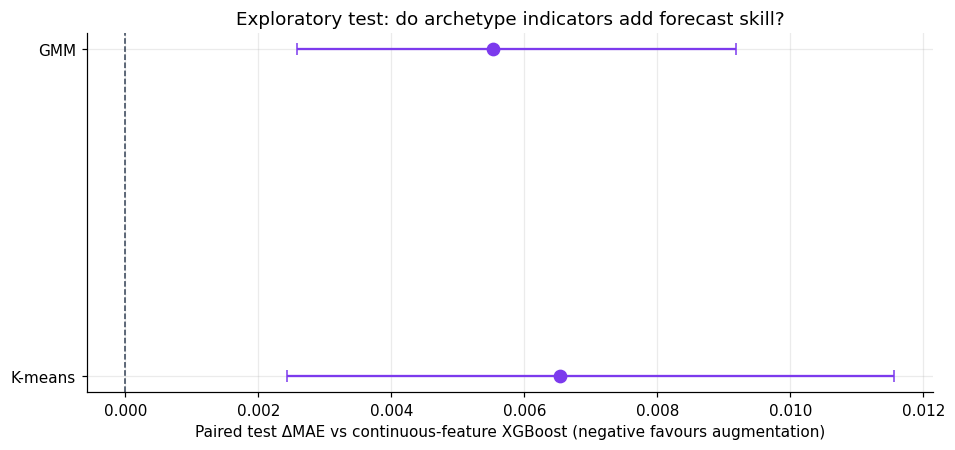

In [31]:
def add_cluster_onehot(split, code_col, n_codes, prefix):
    base = D[split][FEATURES].reset_index(drop=True)
    codes = D[split][code_col].to_numpy(int)
    onehot = pd.DataFrame(np.eye(n_codes, dtype=np.float32)[codes],
                          columns=[f"{prefix}_{j}" for j in range(n_codes)])
    return pd.concat([base, onehot], axis=1)


PILLAR2_AUGMENTED = {}
aug_specs = [("K-means", "arch_id", K + 1, "km_arch"),
             ("GMM", "gmm_arch_id", GMM_K + 1, "gmm_arch")]
for method_name, code_col, n_codes, prefix in aug_specs:
    Xtr_aug = add_cluster_onehot("train", code_col, n_codes, prefix)
    Xva_aug = add_cluster_onehot("validation", code_col, n_codes, prefix)
    Xte_aug = add_cluster_onehot("test", code_col, n_codes, prefix)
    aug_model = fit_xgb(XGB_GRID[best_i], Xtr_aug, ytr, Xva_aug, yva,
                        n_estimators=max(MODEL_BEST_ITERATIONS["XGBoost"], 100), early=True)
    p_val = xgb_predict(aug_model, Xva_aug)
    p_test = xgb_predict(aug_model, Xte_aug)
    PILLAR2_AUGMENTED[method_name] = {"model": aug_model, "validation_prediction": p_val,
                                     "test_prediction": p_test,
                                     "validation_MAE": float(np.abs(p_val - yva).mean()),
                                     "test_MAE": float(np.abs(p_test - XY["test"]["y"]).mean()),
                                     "best_iteration": int(aug_model.best_iteration) + 1}
    del Xtr_aug, Xva_aug, Xte_aug
    gc.collect()

aug_rows = []
aug_pvalues = []
for method_name in ("K-means", "GMM"):
    p_test = PILLAR2_AUGMENTED[method_name]["test_prediction"]
    d_xgb, lo_xgb, hi_xgb = paired_diff(p_test, preds["test"]["XGBoost"], "test")
    d_trend, lo_trend, hi_trend = paired_diff(p_test, preds["test"][TREND], "test")
    p_xgb, macro_xgb, n_clients_xgb = client_signflip_pvalue(p_test, preds["test"]["XGBoost"], seed=SEED + 71 + len(aug_rows))
    aug_rows.append({"archetype method": method_name,
                     "validation_MAE": PILLAR2_AUGMENTED[method_name]["validation_MAE"],
                     "test_MAE": PILLAR2_AUGMENTED[method_name]["test_MAE"],
                     "ΔMAE vs continuous XGBoost": fmt_ci(d_xgb, lo_xgb, hi_xgb),
                     "verdict vs continuous XGBoost": verdict(lo_xgb, hi_xgb),
                     "ΔMAE vs trailing market": fmt_ci(d_trend, lo_trend, hi_trend),
                     "verdict vs trailing market": verdict(lo_trend, hi_trend),
                     "client sign-flip p vs continuous XGBoost": p_xgb,
                     "equal-client ΔMAE vs XGBoost": macro_xgb,
                     "clients": n_clients_xgb,
                     "_xgb_diff": d_xgb, "_xgb_lo": lo_xgb, "_xgb_hi": hi_xgb})

aug_results_df = pd.DataFrame(aug_rows)
aug_results_df["Holm adjusted p vs continuous XGBoost"] = holm_adjust(aug_results_df["client sign-flip p vs continuous XGBoost"].to_numpy())
display(aug_results_df.drop(columns=["_xgb_diff", "_xgb_lo", "_xgb_hi"]))

fig, ax = plt.subplots(figsize=(8.8, 4.2))
xx = np.arange(len(aug_results_df))
centres = aug_results_df["_xgb_diff"].to_numpy(float)
left = centres - aug_results_df["_xgb_lo"].to_numpy(float)
right = aug_results_df["_xgb_hi"].to_numpy(float) - centres
ax.errorbar(centres, xx, xerr=[left, right], fmt="o", capsize=4, color="#7C3AED", markersize=8)
ax.axvline(0, color="#334155", linestyle="--", linewidth=1)
ax.set_yticks(xx); ax.set_yticklabels(aug_results_df["archetype method"])
ax.set_xlabel("Paired test ΔMAE vs continuous-feature XGBoost (negative favours augmentation)")
ax.set_title("Exploratory test: do archetype indicators add forecast skill?")
fig.tight_layout(); savefig("fig24_archetype_incremental_forecast")

RESULTS["archetypes"]["augmented_forecasts"] = {
    "post_hoc": True,
    "design": "One-hot training-derived K-means or GMM labels appended to original continuous features; XGBoost fit with validation early stopping.",
    "models": aug_results_df.drop(columns=["_xgb_diff", "_xgb_lo", "_xgb_hi"]).to_dict(orient="records"),
    "figure": "fig24_archetype_incremental_forecast.png",
    "do_not_use_for_primary_selection_or_live_queue": True
}

### 5.5 Visual interpretation — PCA, profile heatmap, prevalence and radar

The PCA transformation is fitted on the training non-micro population and only projects held-out test items. PCA is a projection for visual inspection, not a clustering validation score. The robust-standardized profile heatmap is the primary archetype comparison view because each feature is scaled separately and labelled. PCA is the geometry view; prevalence and outcome distributions describe composition; radar is supplementary because polygon area and overlapping spokes can overstate differences. The held-out silhouette and outcome/permutation tests in §5.3, not the appearance of these figures, determine whether a cluster is treated as validated evidence.

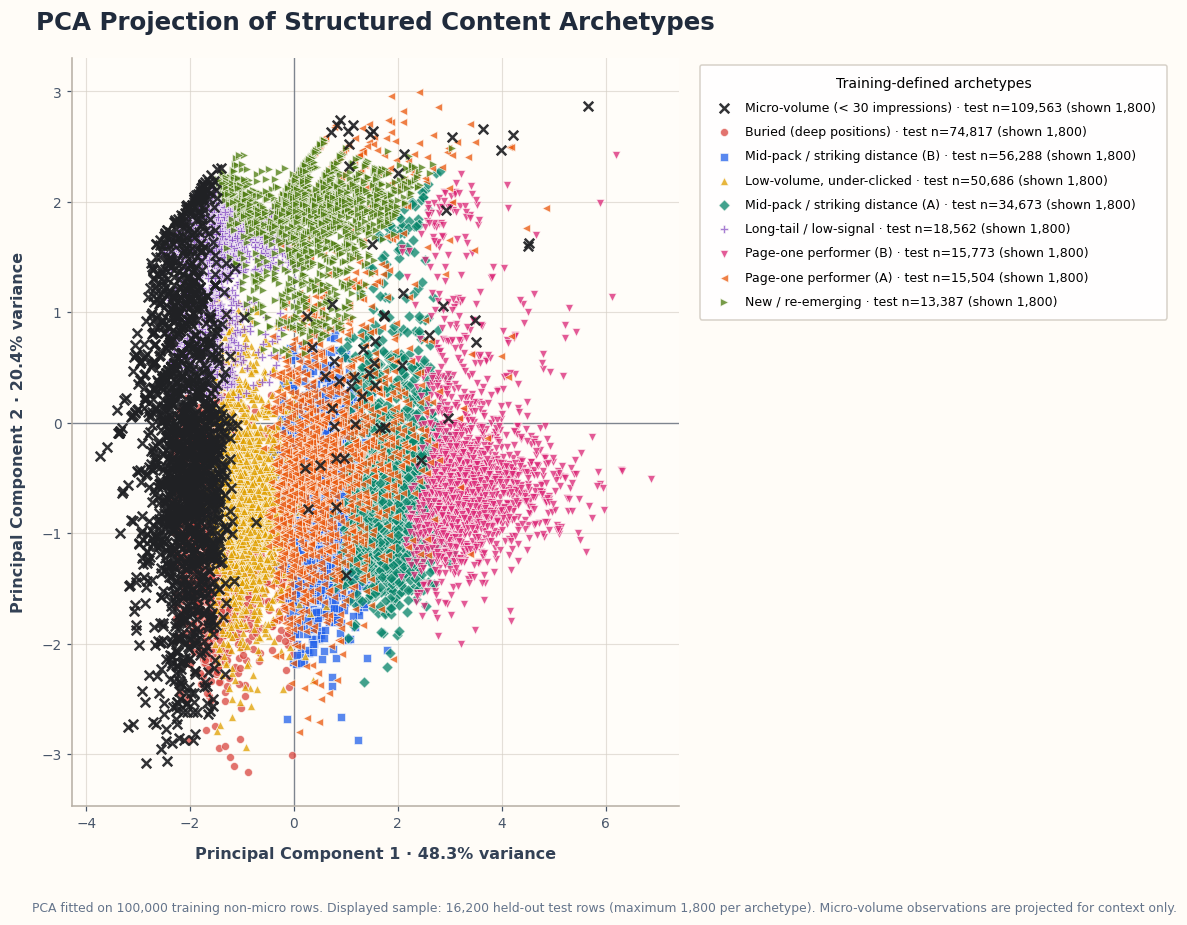

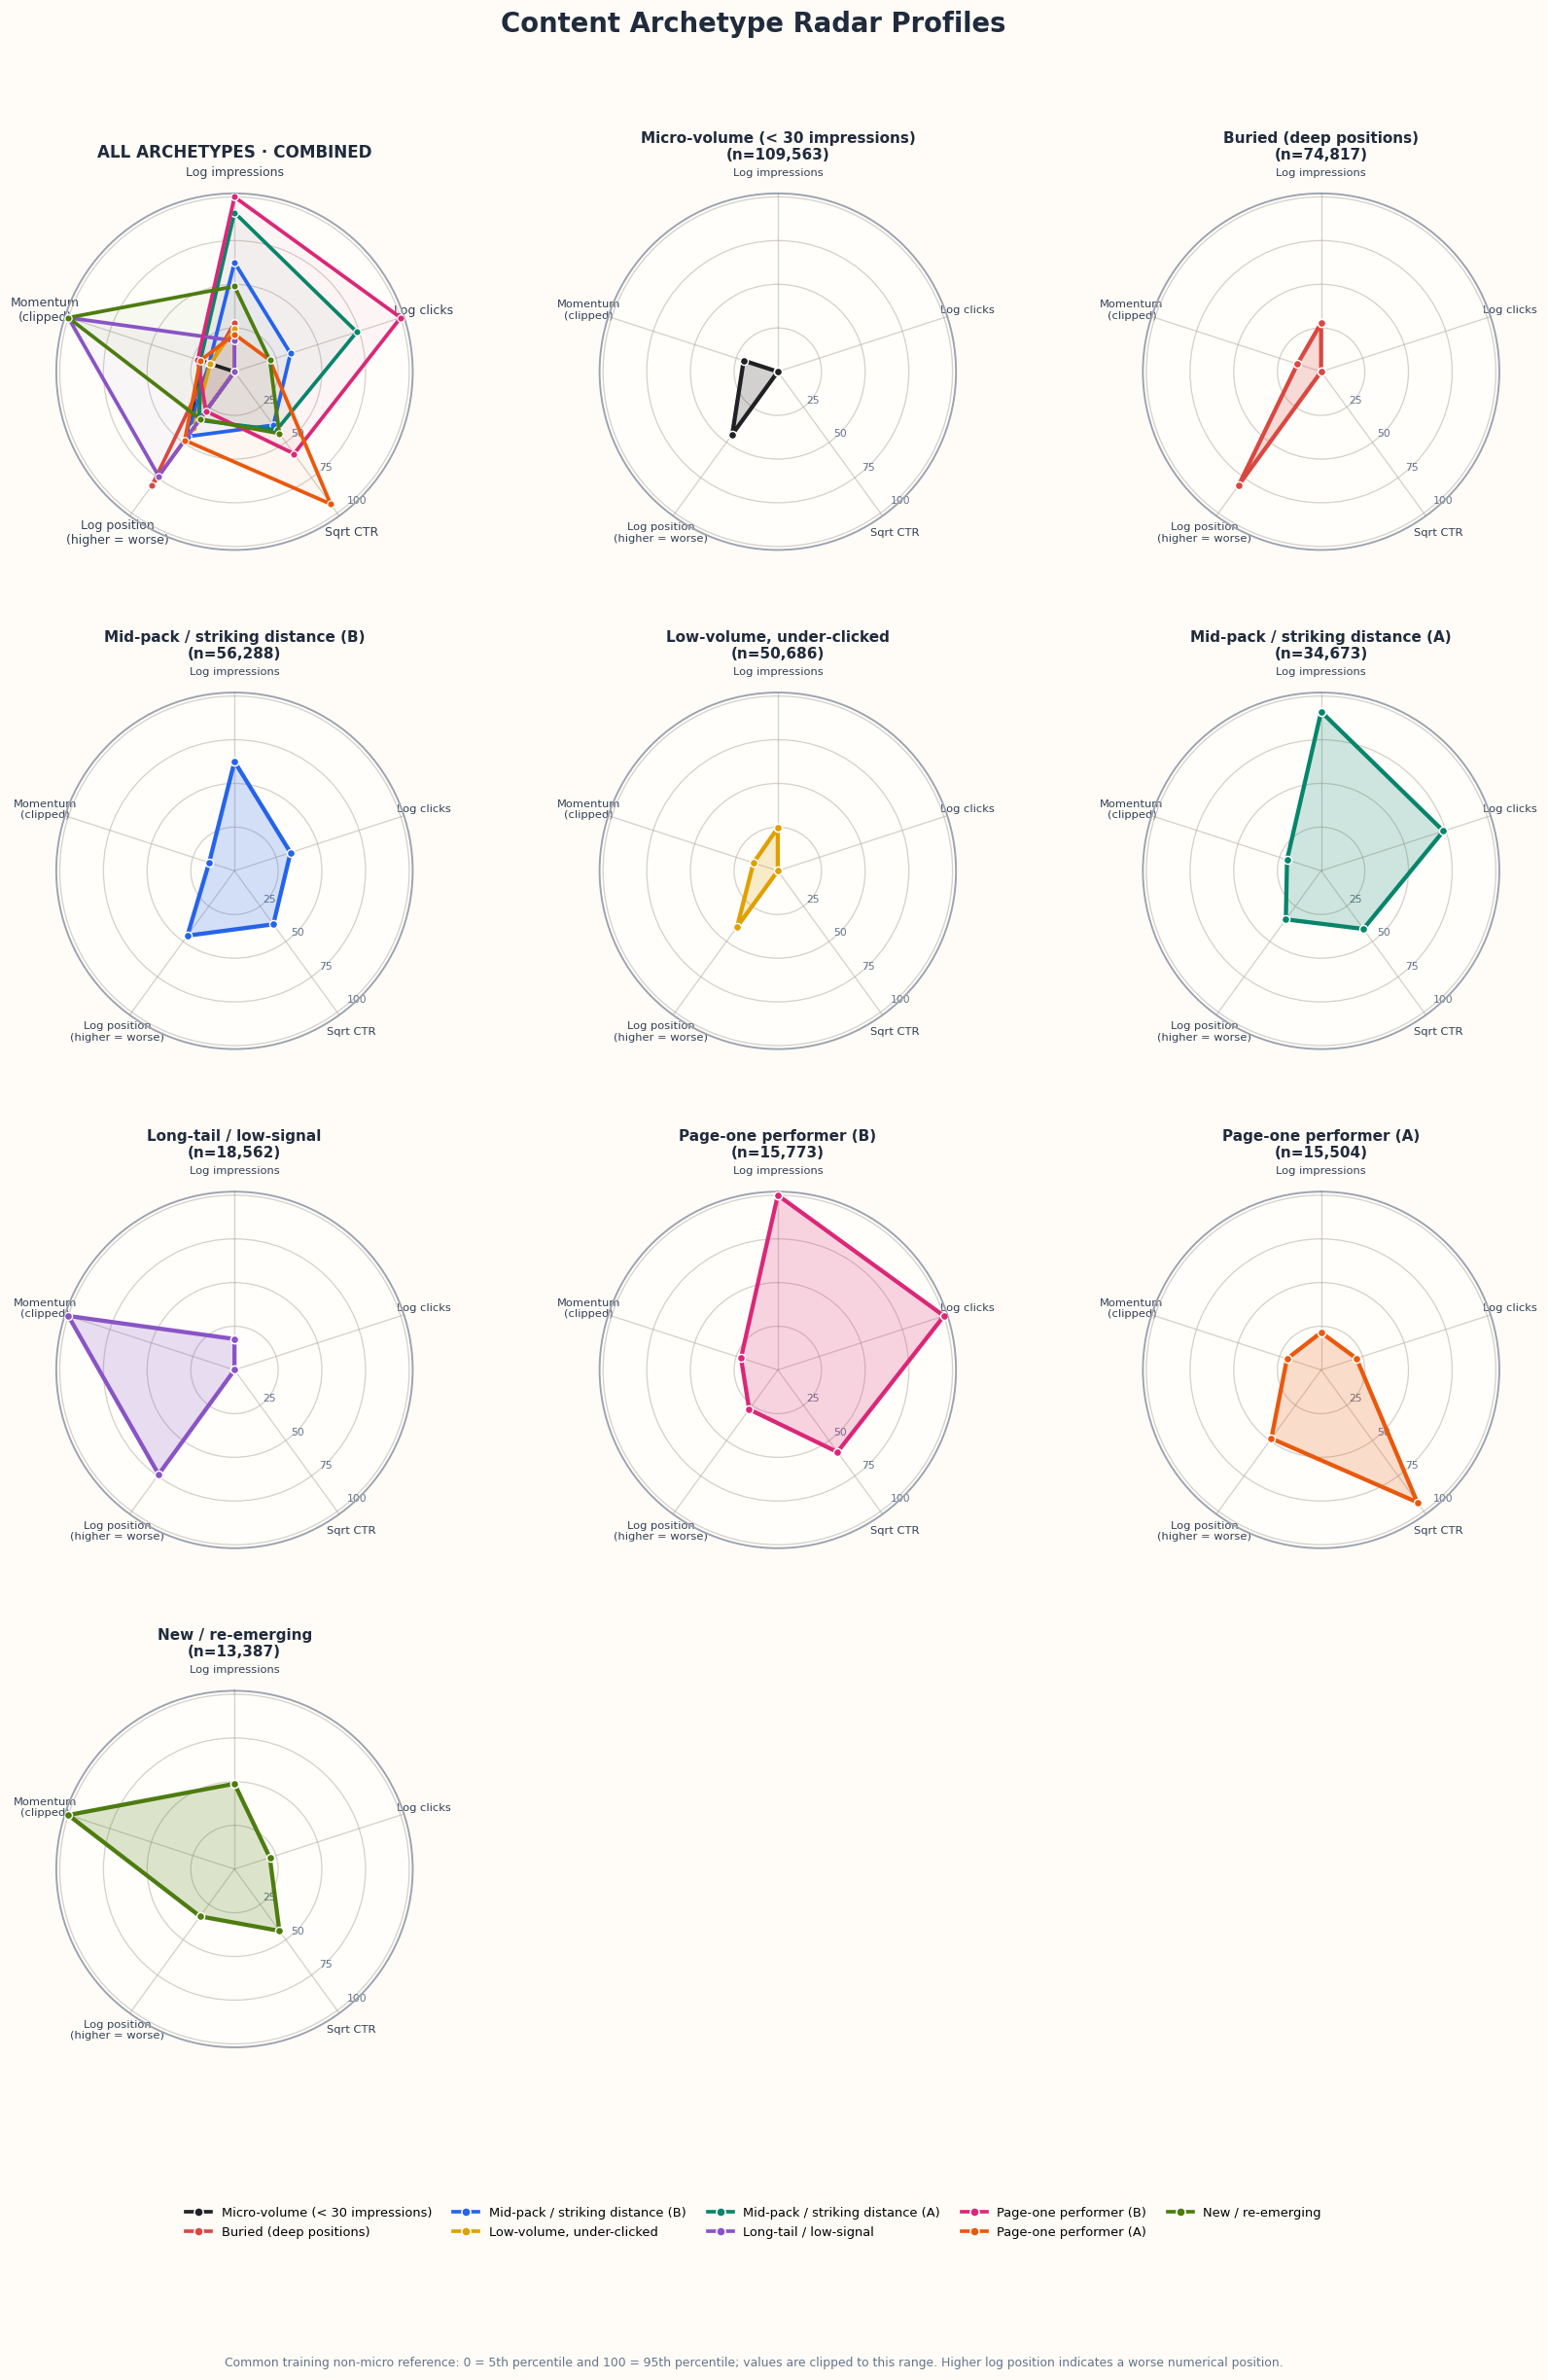

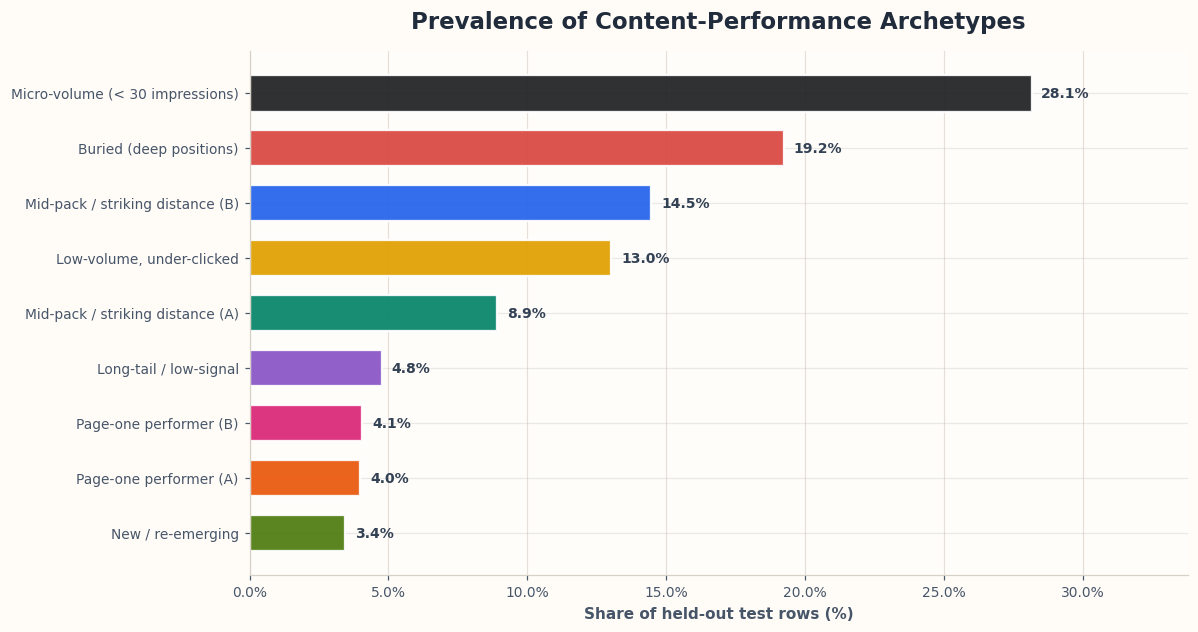

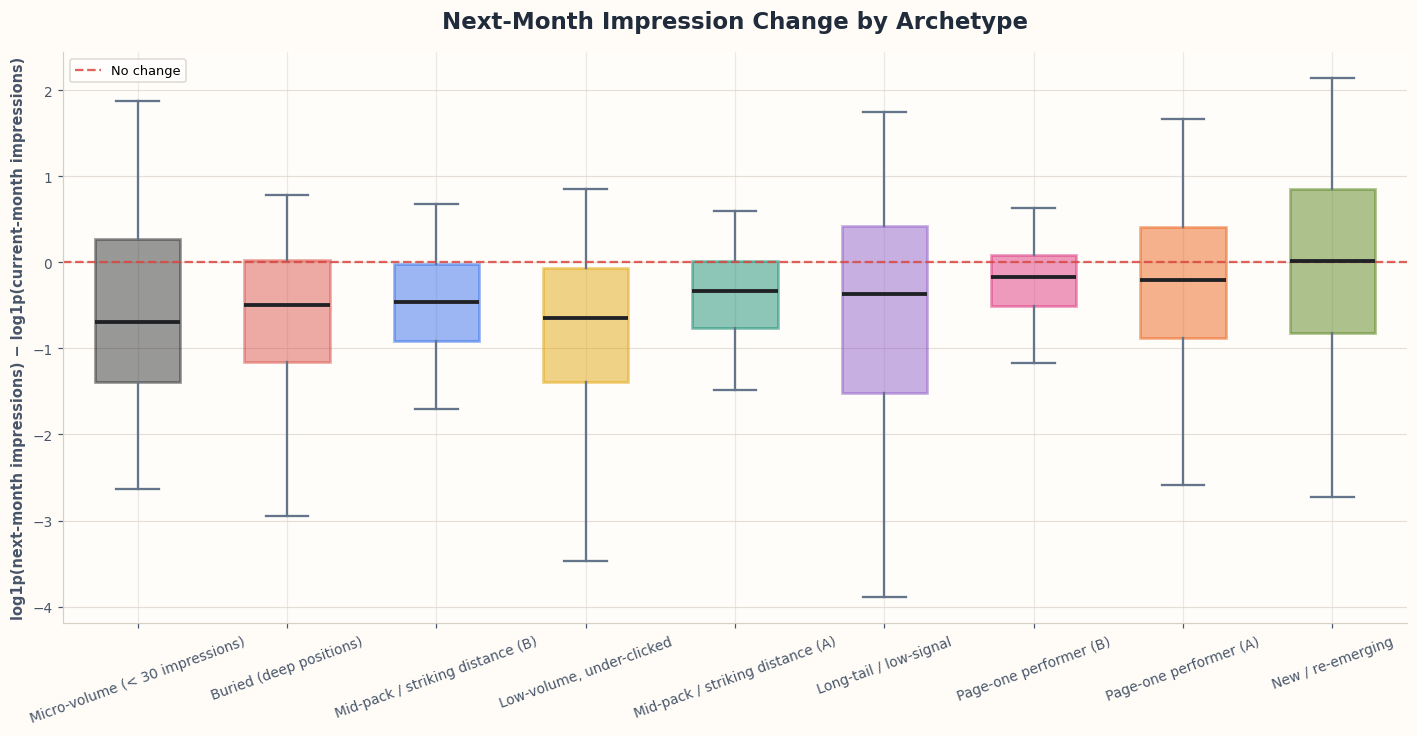

Research Pillar 02 visuals saved:
  ✓ /content/docs/figures/fig15_archetype_pca.png
  ✓ /content/docs/figures/fig16_archetype_radar.png
  ✓ /content/docs/figures/fig17_archetype_prevalence.png
  ✓ /content/docs/figures/fig18_archetype_outcomes.png


In [32]:

# Research Pillar 02 — redesigned PCA + combined radar + small multiples
# Figures 15–18
#
# The same archetype colors are retained across every visualization.
# All PCA and radar calculations remain based on the original data.

from sklearn.decomposition import PCA
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

FIG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. CONSISTENT ARCHETYPE COLOR SYSTEM
# ------------------------------------------------------------

arch_order = list(
    prof.sort_values(
        "share_of_test_rows",
        ascending=False
    )["archetype"]
)

# Bold, distinct colors with a warm academic appearance.
cluster_palette = [
    "#D94841",  # Vermilion red
    "#2563EB",  # Cobalt blue
    "#E0A000",  # Golden yellow
    "#07856A",  # Emerald teal
    "#8954C6",  # Violet
    "#DB2777",  # Magenta
    "#EA580C",  # Orange
    "#4D7C0F",  # Olive green
    "#0E7490",  # Deep cyan
    "#6D28D9",  # Deep purple
]

# Dark charcoal is reserved for micro-volume cross markers.
MICRO_COLOR = "#202124"

arch_colors = {}
cluster_color_idx = 0

for label in arch_order:

    if label == MICRO_NAME:
        arch_colors[label] = MICRO_COLOR

    else:
        arch_colors[label] = cluster_palette[
            cluster_color_idx % len(cluster_palette)
        ]
        cluster_color_idx += 1

# Different marker shapes add another layer of visual distinction.
marker_cycle = ["o", "s", "^", "D", "P", "v", "<", ">"]

arch_markers = {}
marker_idx = 0

for label in arch_order:

    if label == MICRO_NAME:
        arch_markers[label] = "x"

    else:
        arch_markers[label] = marker_cycle[
            marker_idx % len(marker_cycle)
        ]
        marker_idx += 1


# ------------------------------------------------------------
# 2. FIGURE 15 — PCA PROJECTION
# ------------------------------------------------------------

# PCA is fitted only on training non-micro rows.
# Test observations are projected into the fitted PCA space.

pca_arch = PCA(
    n_components=2,
    random_state=SEED
)

pca_arch.fit(Z_tr[idx_fit])

# A slightly lower cap reduces excessive marker overlap.
# Sampling remains deterministic and does not modify the data.

PCA_MAX_PER_ARCHETYPE = 1800

rng_pca = np.random.default_rng(SEED + 15)

test_archetype_labels = (
    D["test"]["archetype"].astype(str).to_numpy()
)

plot_parts = []

for label in arch_order:

    members = np.flatnonzero(
        test_archetype_labels == label
    )

    if members.size:

        take = min(
            PCA_MAX_PER_ARCHETYPE,
            members.size
        )

        plot_parts.append(
            rng_pca.choice(
                members,
                size=take,
                replace=False
            )
        )

plot_idx = (
    np.concatenate(plot_parts)
    if plot_parts
    else np.array([], dtype=int)
)

if len(plot_idx):

    coords = pca_arch.transform(
        Z["test"][plot_idx]
    )

    labels_plot = test_archetype_labels[plot_idx]

    fig, ax = plt.subplots(figsize=(13.5, 8.5))

    fig.patch.set_facecolor("#FFFCF7")
    ax.set_facecolor("#FFFDF9")

    # Draw micro-volume observations first, so the fitted clusters
    # remain visually prominent.

    draw_order = (
        [x for x in arch_order if x == MICRO_NAME]
        + [x for x in arch_order if x != MICRO_NAME]
    )

    for label in draw_order:

        mask = labels_plot == label

        if not mask.any():
            continue

        n_total = int(
            (test_archetype_labels == label).sum()
        )

        n_shown = int(mask.sum())

        is_micro = label == MICRO_NAME

        if is_micro:

            # Black cross markers, explicitly more visible.
            ax.scatter(
                coords[mask, 0],
                coords[mask, 1],
                s=39,
                alpha=0.92,
                marker="x",
                c=MICRO_COLOR,
                linewidths=1.65,
                label=(
                    f"{label} · test n={n_total:,} "
                    f"(shown {n_shown:,})"
                ),
                rasterized=True,
                zorder=4,
            )

        else:

            ax.scatter(
                coords[mask, 0],
                coords[mask, 1],
                s=27,
                alpha=0.76,
                marker=arch_markers[label],
                color=arch_colors[label],
                edgecolors="#FFFDF9",
                linewidths=0.48,
                label=(
                    f"{label} · test n={n_total:,} "
                    f"(shown {n_shown:,})"
                ),
                rasterized=True,
                zorder=3,
            )

    # Reference axes
    ax.axhline(
        0,
        color="#475569",
        linewidth=0.9,
        alpha=0.65,
        zorder=1
    )

    ax.axvline(
        0,
        color="#475569",
        linewidth=0.9,
        alpha=0.65,
        zorder=1
    )

    ax.grid(
        True,
        color="#D6D0C7",
        linewidth=0.75,
        alpha=0.65
    )

    ax.set_axisbelow(True)

    # Clear labels and title
    ax.set_title(
        "PCA Projection of Structured Content Archetypes",
        fontsize=16,
        fontweight="bold",
        color="#202B3C",
        pad=19
    )

    ax.set_xlabel(
        f"Principal Component 1 · "
        f"{pca_arch.explained_variance_ratio_[0]:.1%} variance",
        fontsize=10.5,
        fontweight="bold",
        color="#334155",
        labelpad=10
    )

    ax.set_ylabel(
        f"Principal Component 2 · "
        f"{pca_arch.explained_variance_ratio_[1]:.1%} variance",
        fontsize=10.5,
        fontweight="bold",
        color="#334155",
        labelpad=10
    )

    ax.tick_params(
        axis="both",
        labelsize=9,
        colors="#475569"
    )

    for spine in ax.spines.values():
        spine.set_color("#B8B1A7")
        spine.set_linewidth(1.05)

    # Strong, visible legend
    legend = ax.legend(
        title="Training-defined archetypes",
        bbox_to_anchor=(1.025, 1),
        loc="upper left",
        frameon=True,
        fontsize=8.2,
        title_fontsize=9.2,
        labelspacing=0.9,
        handletextpad=0.7,
        borderpad=0.9,
    )

    legend.get_frame().set_facecolor("#FFFFFF")
    legend.get_frame().set_edgecolor("#D6D0C7")
    legend.get_frame().set_linewidth(1.0)
    legend.get_frame().set_alpha(0.97)

    fig.text(
        0.025,
        0.016,
        (
            f"PCA fitted on {len(idx_fit):,} training non-micro rows. "
            f"Displayed sample: {len(plot_idx):,} held-out test rows "
            f"(maximum {PCA_MAX_PER_ARCHETYPE:,} per archetype). "
            "Micro-volume observations are projected for context only."
        ),
        ha="left",
        va="bottom",
        fontsize=8.1,
        color="#64748B"
    )

    fig.tight_layout(
        rect=(0, 0.055, 0.81, 1)
    )

    fig.savefig(
        FIG_DIR / "fig15_archetype_pca.png",
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close(fig)

else:

    print(
        "PCA scatter skipped: "
        "no held-out test archetypes were available."
    )


# ------------------------------------------------------------
# 3. FIGURE 16 — RADAR FEATURE SCALING
# ------------------------------------------------------------

# The same training reference is used for all individual and
# combined radar charts.

radar_feature_labels = [
    "Log impressions",
    "Log clicks",
    "Sqrt CTR",
    "Log position\n(higher = worse)",
    "Momentum\n(clipped)",
]

train_cluster_reference = cluster_matrix(
    D["train"].loc[fit_tr]
)

radar_low = np.nanquantile(
    train_cluster_reference,
    0.05,
    axis=0
)

radar_high = np.nanquantile(
    train_cluster_reference,
    0.95,
    axis=0
)

radar_span = np.where(
    (radar_high - radar_low) > 1e-9,
    radar_high - radar_low,
    1.0
)

radar_rows = []

for label in arch_order:

    sub = D["test"].loc[
        D["test"]["archetype"] == label
    ]

    if sub.empty:
        continue

    medians = np.nanmedian(
        cluster_matrix(sub),
        axis=0
    )

    scaled = np.clip(
        (medians - radar_low) / radar_span,
        0,
        1
    )

    radar_rows.append({
        "label": label,
        "n": int(len(sub)),
        "values": scaled,
        "color": arch_colors[label],
    })


# ------------------------------------------------------------
# 4. FIGURE 16 — COMBINED RADAR + FIVE SMALL MULTIPLES
# ------------------------------------------------------------

if radar_rows:

    # One overall comparison radar + one panel for every archetype.
    n_panels = len(radar_rows) + 1

    ncols = 3
    nrows = int(np.ceil(n_panels / ncols))

    fig = plt.figure(
        figsize=(18, 5.7 * nrows),
        facecolor="#FFFCF7"
    )

    axes = [
        fig.add_subplot(
            nrows,
            ncols,
            i + 1,
            projection="polar"
        )
        for i in range(n_panels)
    ]

    fig.suptitle(
        "Content Archetype Radar Profiles",
        fontsize=18,
        fontweight="bold",
        color="#202B3C",
        y=0.985
    )

    angles = np.linspace(
        0,
        2 * np.pi,
        len(radar_feature_labels),
        endpoint=False
    )

    closed_angles = np.r_[
        angles,
        angles[0]
    ]

    def style_radar_axis(ax, label_size=7.8):

        ax.set_theta_offset(np.pi / 2)
        ax.set_theta_direction(-1)

        ax.set_xticks(angles)

        ax.set_xticklabels(
            radar_feature_labels,
            fontsize=label_size,
            color="#334155",
            fontweight="medium"
        )

        ax.set_ylim(0, 1.02)

        ax.set_yticks([
            0.25,
            0.50,
            0.75,
            1.00
        ])

        ax.set_yticklabels(
            ["25", "50", "75", "100"],
            fontsize=7,
            color="#64748B"
        )

        ax.set_rlabel_position(140)

        ax.grid(
            color="#B9B1A6",
            alpha=0.58,
            linewidth=0.85
        )

        ax.spines["polar"].set_color("#9CA3AF")
        ax.spines["polar"].set_linewidth(1.25)

        ax.set_facecolor("#FFFEFB")

    # --------------------------------------------------------
    # Panel 1: FULL COMBINED RADAR CHART
    # --------------------------------------------------------

    ax_overview = axes[0]

    style_radar_axis(
        ax_overview,
        label_size=8.2
    )

    for item in radar_rows:

        values = np.asarray(
            item["values"],
            dtype=float
        )

        closed_values = np.r_[
            values,
            values[0]
        ]

        ax_overview.plot(
            closed_angles,
            closed_values,
            color=item["color"],
            linewidth=2.45,
            marker="o",
            markersize=4.8,
            markeredgecolor="#FFFFFF",
            markeredgewidth=0.8,
            label=item["label"],
            zorder=4
        )

        ax_overview.fill(
            closed_angles,
            closed_values,
            color=item["color"],
            alpha=0.045,
            zorder=2
        )

    ax_overview.set_title(
        "ALL ARCHETYPES · COMBINED",
        fontsize=11,
        fontweight="bold",
        color="#202B3C",
        pad=24
    )

    # --------------------------------------------------------
    # Panels 2 onward: INDIVIDUAL ARCHETYPE RADARS
    # --------------------------------------------------------

    for ax, item in zip(
        axes[1:],
        radar_rows
    ):

        style_radar_axis(
            ax,
            label_size=7.5
        )

        values = np.asarray(
            item["values"],
            dtype=float
        )

        closed_values = np.r_[
            values,
            values[0]
        ]

        ax.plot(
            closed_angles,
            closed_values,
            color=item["color"],
            linewidth=2.8,
            marker="o",
            markersize=5.3,
            markerfacecolor=item["color"],
            markeredgecolor="#FFFFFF",
            markeredgewidth=0.95,
            zorder=4
        )

        ax.fill(
            closed_angles,
            closed_values,
            color=item["color"],
            alpha=0.20,
            zorder=2
        )

        ax.set_title(
            f"{item['label']}\n(n={item['n']:,})",
            fontsize=10,
            fontweight="bold",
            color="#202B3C",
            pad=23
        )

    # Hide any remaining unused panels.
    for ax in axes[n_panels:]:
        ax.set_visible(False)

    # Legend shared by the combined comparison chart
    radar_legend_handles = [
        Line2D(
            [0], [0],
            color=item["color"],
            marker="o",
            linewidth=2.4,
            markersize=6,
            markeredgecolor="white",
            label=item["label"]
        )
        for item in radar_rows
    ]

    fig.subplots_adjust(
        hspace=0.40,
        wspace=0.34,
        top=0.91,
        bottom=0.15
    )

    fig.legend(
        handles=radar_legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.067),
        ncol=min(5, len(radar_rows)),
        frameon=False,
        fontsize=8.5,
        columnspacing=1.7
    )

    fig.text(
        0.5,
        0.018,
        (
            "Common training non-micro reference: "
            "0 = 5th percentile and 100 = 95th percentile; "
            "values are clipped to this range. "
            "Higher log position indicates a worse numerical position."
        ),
        ha="center",
        va="bottom",
        fontsize=8.1,
        color="#64748B"
    )

    fig.savefig(
        FIG_DIR / "fig16_archetype_radar.png",
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close(fig)

else:

    print(
        "Radar profiles skipped: "
        "no non-empty held-out test archetypes were available."
    )


# ------------------------------------------------------------
# 5. FIGURE 17 — ARCHETYPE PREVALENCE
# ------------------------------------------------------------

arch_share = (
    D["test"]["archetype"]
    .value_counts(normalize=True)
    .reindex(arch_order)
    .dropna()
    .sort_values()
)

if len(arch_share):

    fig, ax = plt.subplots(
        figsize=(11, max(4.8, 0.65 * len(arch_share)))
    )

    fig.patch.set_facecolor("#FFFCF7")
    ax.set_facecolor("#FFFDF9")

    bar_colors = [
        arch_colors[label]
        for label in arch_share.index
    ]

    bars = ax.barh(
        arch_share.index,
        arch_share.values * 100,
        color=bar_colors,
        alpha=0.93,
        edgecolor="#FFFFFF",
        linewidth=1.5,
        height=0.66
    )

    for y, value in enumerate(
        arch_share.values * 100
    ):

        ax.text(
            value + 0.35,
            y,
            f"{value:.1f}%",
            va="center",
            fontsize=9.2,
            fontweight="bold",
            color="#334155"
        )

    ax.set_title(
        "Prevalence of Content-Performance Archetypes",
        fontsize=15,
        fontweight="bold",
        color="#202B3C",
        pad=15
    )

    ax.set_xlabel(
        "Share of held-out test rows (%)",
        fontsize=10,
        fontweight="bold",
        color="#475569"
    )

    ax.set_xlim(
        0,
        max(arch_share.values * 100) * 1.20
    )

    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=100)
    )

    ax.grid(
        axis="x",
        color="#D6D0C7",
        alpha=0.65,
        linewidth=0.75
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_color("#D6D0C7")

    ax.tick_params(
        axis="both",
        labelsize=9,
        colors="#475569"
    )

    fig.tight_layout()

    fig.savefig(
        FIG_DIR / "fig17_archetype_prevalence.png",
        dpi=280,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 6. FIGURE 18 — NEXT-MONTH OUTCOME DISTRIBUTION
# ------------------------------------------------------------

box_data = []
box_labels = []

for label in arch_order:

    values = (
        D["test"]
        .loc[
            D["test"]["archetype"] == label,
            "y_delta"
        ]
        .dropna()
        .to_numpy()
    )

    if len(values):

        box_data.append(values)
        box_labels.append(label)

if box_data:

    fig, ax = plt.subplots(
        figsize=(13, 6.8)
    )

    fig.patch.set_facecolor("#FFFCF7")
    ax.set_facecolor("#FFFDF9")

    bp = ax.boxplot(
        box_data,
        tick_labels=box_labels,
        showfliers=False,
        whis=(5, 95),
        patch_artist=True,
        widths=0.57,
        medianprops={
            "color": "#202124",
            "linewidth": 2.5
        },
        whiskerprops={
            "color": "#64748B",
            "linewidth": 1.5
        },
        capprops={
            "color": "#64748B",
            "linewidth": 1.5
        },
        boxprops={
            "linewidth": 1.5
        }
    )

    for patch, label in zip(
        bp["boxes"],
        box_labels
    ):

        patch.set_facecolor(
            arch_colors[label]
        )

        patch.set_alpha(0.46)

        patch.set_edgecolor(
            arch_colors[label]
        )

        patch.set_linewidth(1.8)

    ax.axhline(
        0,
        color="#D94841",
        linestyle="--",
        linewidth=1.5,
        alpha=0.85,
        label="No change"
    )

    ax.set_title(
        "Next-Month Impression Change by Archetype",
        fontsize=15,
        fontweight="bold",
        color="#202B3C",
        pad=16
    )

    ax.set_ylabel(
        "log1p(next-month impressions) − log1p(current-month impressions)",
        fontsize=9.5,
        fontweight="bold",
        color="#475569"
    )

    ax.tick_params(
        axis="x",
        rotation=20,
        labelsize=9,
        colors="#475569"
    )

    ax.tick_params(
        axis="y",
        labelsize=9,
        colors="#475569"
    )

    ax.grid(
        axis="y",
        color="#D6D0C7",
        alpha=0.65,
        linewidth=0.75
    )

    ax.set_axisbelow(True)

    ax.legend(
        frameon=True,
        facecolor="white",
        edgecolor="#D6D0C7",
        fontsize=8.5
    )

    for spine in ax.spines.values():
        spine.set_color("#D6D0C7")

    fig.tight_layout()

    fig.savefig(
        FIG_DIR / "fig18_archetype_outcomes.png",
        dpi=280,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 7. UPDATE RESULTS METADATA
# ------------------------------------------------------------

RESULTS.setdefault(
    "archetypes", {}
)["visuals"] = [
    "fig15_archetype_pca.png",
    "fig16_archetype_radar.png",
    "fig17_archetype_prevalence.png",
    "fig18_archetype_outcomes.png",
]

RESULTS["archetypes"]["visual_details"] = {

    "pca_fit_rows": int(len(idx_fit)),

    "pca_test_rows_displayed": int(len(plot_idx)),

    "pca_max_per_archetype": int(PCA_MAX_PER_ARCHETYPE),

    "pca_explained_variance_pc1": float(
        pca_arch.explained_variance_ratio_[0]
    ),

    "pca_explained_variance_pc2": float(
        pca_arch.explained_variance_ratio_[1]
    ),

    "radar_reference": (
        "Training non-micro population; "
        "5th–95th percentile per feature; "
        "values clipped to [0, 1]"
    ),

    "radar_layout": (
        "One combined archetype comparison radar "
        "plus one individual radar panel per archetype"
    ),
}

print("Research Pillar 02 visuals saved:")

for filename in RESULTS["archetypes"]["visuals"]:

    path = FIG_DIR / filename

    print(
        f"  {'✓' if path.exists() else '⚠'} {path}"
    )


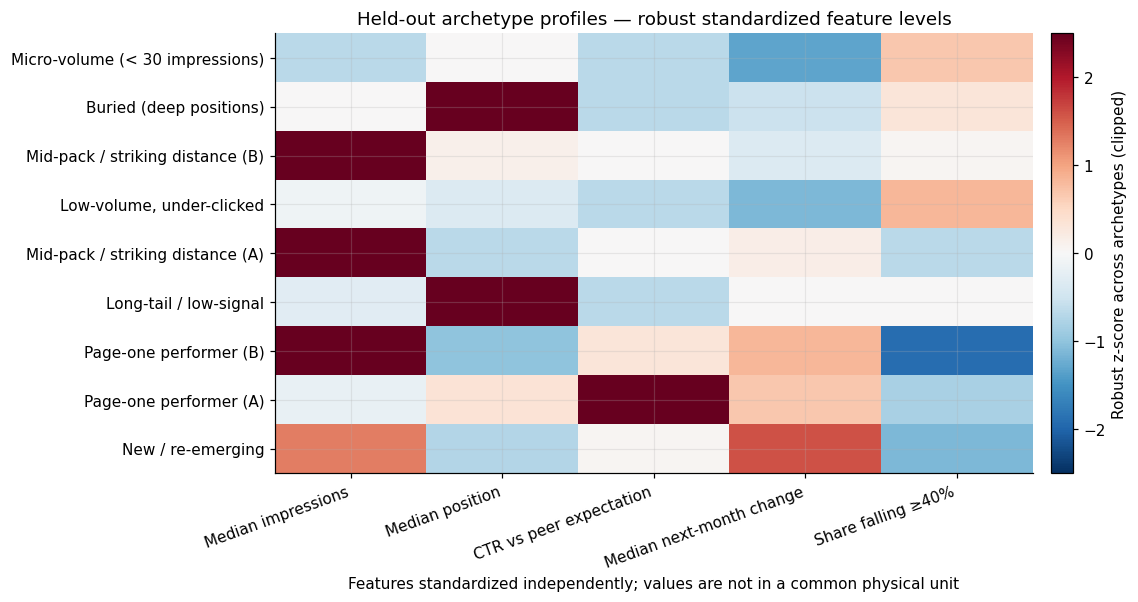

In [33]:

# Figure 21 — robust-standardized archetype profile heatmap.
# Primary comparison view; radar profiles remain supplementary.
heat_cols = [("median_impressions","Median impressions"),("median_position","Median position"),
             ("median_ctr_vs_peers","CTR vs peer expectation"),("median_actual_change","Median next-month change"),
             ("share_fell_40pct","Share falling ≥40%")]
available = [(c,label) for c,label in heat_cols if c in prof.columns]
if available and len(prof):
    H = prof.set_index("archetype")[[c for c,_ in available]].astype(float)
    HZ = H.copy()
    for c in HZ.columns:
        med = HZ[c].median()
        mad = (HZ[c]-med).abs().median()
        scale = 1.4826*mad if mad > 1e-9 else (HZ[c].std() if HZ[c].std() > 1e-9 else 1.0)
        HZ[c] = ((HZ[c]-med)/scale).clip(-2.5,2.5)
    fig, ax = plt.subplots(figsize=(11,max(4.5,.62*len(HZ))))
    im=ax.imshow(HZ.to_numpy(),aspect="auto",cmap="RdBu_r",vmin=-2.5,vmax=2.5)
    ax.set_yticks(np.arange(len(HZ))); ax.set_yticklabels(HZ.index)
    ax.set_xticks(np.arange(len(available))); ax.set_xticklabels([label for _,label in available],rotation=20,ha="right")
    ax.set_title("Held-out archetype profiles — robust standardized feature levels")
    cb=fig.colorbar(im,ax=ax,pad=.02); cb.set_label("Robust z-score across archetypes (clipped)")
    ax.set_xlabel("Features standardized independently; values are not in a common physical unit")
    fig.tight_layout()
    fig.savefig(FIG_DIR/"fig21_archetype_profile_heatmap.png",dpi=190,bbox_inches="tight",facecolor="white")
    plt.show(); plt.close(fig)
else:
    print("Heatmap skipped: expected archetype profile columns are unavailable.")


# Integrated Application

## 6. Ranked recommendations — per-client review queues
Combining insights from both pillars into a practical, human-reviewed content prioritization framework.

### 6.1 Scoring design

The score is in **estimated clicks per month at stake**, so volume is preserved (a rank-percentile blend discards magnitude and cannot beat "sort by impressions"). Every term uses only information available at the end of month *t*.

| Quantity | Definition |
|---|---|
| Peer-expected CTR | CTR of the **same client's other items** at the same position bucket in the same month, shrunk to the pooled prior (§2.6) |
| CTR gap | `max(peer-expected CTR − CTR, 0)` |
| **Predicted missed clicks** | `CTR gap × predicted next-month impressions` |
| **Decline exposure** | `max(impressions − predicted next-month impressions, 0) × peer-expected CTR` |
| **At-stake clicks** | `predicted missed clicks + λ × decline exposure`, λ = 1 |
| Position headroom | 0 for positions ≤ 3; 0.8 for 4–10; **1.0 for 11–20** (striking distance); 0.5 for 21–30; 0.2 for 31–50; 0 beyond |
| **Score** | `at-stake clicks × (1 + β × headroom)`, β = 0.5 |

λ and β are judgement calls, stress-tested in §6.5. These are **screening estimates**, not forecasts of clicks gained from any action. The peer benchmark makes "under-capture" a statement *within* a client ("fewer clicks than this site's other pages at the same rank"), not against a universal CTR curve.

**Per-client queues are the primary output.** A content team works one client's inventory, so tiers are fixed shares of *each client's* items each month: top 5% *Immediate review*, next 15% *High priority*, next 30% *Review*, the rest *Monitor*. A global rank (`priority_rank`, `global_tier`) is kept only to compare across clients — and §6.4 shows how concentrated it is.

**Reason codes** are multi-valued flags and are kept **selective**: change codes need at least `MIN_IMPR_CODES` impressions (a ±50% move on 3 impressions is counting noise), and `LOW_CTR_FOR_POSITION` needs at least `MIN_EXPECTED_CLICKS` *expected* clicks so a CTR gap can exceed Poisson noise. Predicted-change codes are *relative* (bottom / top decile of the preceding period's out-of-time predictions) and are paired with **observed** counterparts (`OBSERVED_DECLINE` / `OBSERVED_GROWTH`: a month-over-month log change beyond ±0.5, about −39% / +65%). The share of items each code flags is printed, and codes flagging more than 35% of items are called out as non-selective.

**Evidence-gated routing (rolling, not one-window).** A *predicted* decline or growth code may drive the primary action only if it (i) identified the realized change at ≥ 1.15× the unflagged rate on the pooled validation months, (ii) did so (lift > 1.05) in at least two thirds of the months that count (a month counts only when ≥ `GATE_MIN_FLAGGED` items were flagged — a lift computed from a handful of items is noise), **and** (iii) had lift > 1 in the *most recent* counted month, the regime closest to the test period. A one-window gate can pass on a regime that then reverses. Otherwise the action is routed on the observed counterpart. The backtest uses the validation-only gate; for the **live** queue the same rule is re-applied to the last three labeled months (validation + test), all of which are out-of-time.

In [34]:
from functools import reduce

LAMBDA, BETA = 1.0, 0.5
ACTIONS = ["Refresh review (decline risk)", "Metadata / snippet review", "Content improvement review (page-1 push)",
           "Rewrite / re-target review", "Protect & amplify (monitor growth)", "Monitor"]
TIERS = ["Monitor", "Review", "High priority", "Immediate review"]
TIER_BINS = [0, 0.5, 0.8, 0.95, 1.0]


def position_headroom(pos):
    pos = np.asarray(pos, float)
    return np.select([pos <= 3, pos <= 10, pos <= 20, pos <= 30, pos <= 50], [0.0, 0.8, 1.0, 0.5, 0.2], default=0.0)


def make_context(df_ref, ref_pred, route_pred_decline=True, route_pred_growth=True):
    """Volume thresholds from df_ref; relative prediction thresholds from out-of-time predictions; routing switches."""
    ref_pred = np.asarray(ref_pred, float)
    return {"impr_p50": float(df_ref["impressions"].quantile(.50)), "impr_p75": float(df_ref["impressions"].quantile(.75)),
            "impr_p90": float(df_ref["impressions"].quantile(.90)),
            "pd_lo": float(np.quantile(ref_pred, 0.10)), "pd_hi": float(np.quantile(ref_pred, 0.90)),
            "pd_rebound": float(np.quantile(ref_pred, 0.75)),
            "route_pred_decline": bool(route_pred_decline), "route_pred_growth": bool(route_pred_growth)}


def score_queue(df, pred_delta, ctx, lam=LAMBDA, beta=BETA):
    """Score rows of `df` (must contain expected_ctr). Output rows are in the SAME ORDER as `df`."""
    keep = ID_COLS + ["month", "impressions", "clicks", "ctr", "avg_position", "mom_change", "log_impr", "expected_ctr"]
    q = df[keep + (["archetype"] if "archetype" in df.columns else [])].copy().reset_index(drop=True)
    q["month"] = q["month"].astype(str)
    q["pred_delta"] = np.asarray(pred_delta, float)
    q["pred_next_impr"] = np.expm1(q["log_impr"] + q["pred_delta"]).clip(lower=0)
    gap = np.maximum(q["expected_ctr"] - q["ctr"], 0)
    q["missed_clicks_est"] = gap * q["impressions"]
    q["pred_missed_clicks"] = gap * q["pred_next_impr"]
    q["decline_exposure"] = np.maximum(q["impressions"] - q["pred_next_impr"], 0) * q["expected_ctr"]
    q["at_stake_clicks"] = q["pred_missed_clicks"] + lam * q["decline_exposure"]
    q["headroom"] = position_headroom(q["avg_position"])
    q["score"] = q["at_stake_clicks"] * (1 + beta * q["headroom"])

    pos, impr, pdl, mom = q["avg_position"].to_numpy(), q["impressions"].to_numpy(), q["pred_delta"].to_numpy(), q["mom_change"].to_numpy()
    ratio = np.where(q["expected_ctr"] > 0, q["ctr"] / np.where(q["expected_ctr"] > 0, q["expected_ctr"], 1.0), np.nan)
    exp_clicks = q["expected_ctr"].to_numpy() * impr
    vol = impr >= MIN_IMPR_CODES
    flags = {"LOW_CTR_FOR_POSITION": (((ratio < 0.5) & (impr >= ctx["impr_p50"])) | ((ratio < 0.8) & (impr >= ctx["impr_p90"]))) & (exp_clicks >= MIN_EXPECTED_CLICKS),
             "STRIKING_DISTANCE": (pos > 3) & (pos <= 20),
             "BURIED_BUT_VISIBLE": (pos > 20) & (impr >= ctx["impr_p75"]),
             "OBSERVED_DECLINE": (mom <= -OBS_CHANGE) & vol, "OBSERVED_GROWTH": (mom >= OBS_CHANGE) & vol,
             "PREDICTED_DECLINE": (pdl <= ctx["pd_lo"]) & (pdl < 0) & vol, "PREDICTED_GROWTH": (pdl >= ctx["pd_hi"]) & (pdl > 0) & vol,
             "RECOVERY_SIGNAL": (mom <= -0.25) & (pdl >= ctx["pd_rebound"]) & vol,
             "HIGH_VISIBILITY": impr >= ctx["impr_p90"]}
    joined = reduce(np.char.add, [np.where(f, code + ";", "") for code, f in flags.items()])
    q["reason_codes"] = pd.Series(joined).str.rstrip(";").replace("", "NONE").to_numpy()

    decline = flags["OBSERVED_DECLINE"] | (flags["PREDICTED_DECLINE"] if ctx["route_pred_decline"] else False)
    growth = flags["OBSERVED_GROWTH"] | (flags["PREDICTED_GROWTH"] if ctx["route_pred_growth"] else False)
    q["recommended_action"] = np.select(
        [decline & (impr >= ctx["impr_p75"]), flags["LOW_CTR_FOR_POSITION"], flags["STRIKING_DISTANCE"],
         flags["BURIED_BUT_VISIBLE"], growth], ACTIONS[:5], default=ACTIONS[5])

    grp = q.groupby(["month", "client_hash_id"])["score"]
    q["tier"] = pd.cut(grp.rank(pct=True, method="first"), bins=TIER_BINS, labels=TIERS, include_lowest=True)          # per client (primary)
    q["priority_rank_in_client"] = grp.rank(ascending=False, method="first").astype(int)
    q["global_tier"] = pd.cut(q.groupby("month")["score"].rank(pct=True, method="first"), bins=TIER_BINS, labels=TIERS, include_lowest=True)
    q["priority_rank"] = q.groupby("month")["score"].rank(ascending=False, method="first").astype(int)
    return q


def code_validation(q, d):
    """For each reason code: realised next-month outcome among flagged items vs. unflagged items (rows of q and d aligned)."""
    y = d["y_delta"].to_numpy(float)
    fell, grew = y <= np.log(0.6), y >= np.log(1.25)
    n_imp, n_clk = d["next_impressions"].to_numpy(float), d["next_clicks"].to_numpy(float)
    still_low = (n_imp > 0) & (n_clk < 0.5 * q["expected_ctr"].to_numpy() * n_imp)
    spec = {"PREDICTED_DECLINE": ("impressions fell ≥ 40% next month", fell, np.ones(len(y), bool)),
            "OBSERVED_DECLINE": ("impressions fell ≥ 40% next month", fell, np.ones(len(y), bool)),
            "PREDICTED_GROWTH": ("impressions grew ≥ 25% next month", grew, np.ones(len(y), bool)),
            "OBSERVED_GROWTH": ("impressions grew ≥ 25% next month", grew, np.ones(len(y), bool)),
            "RECOVERY_SIGNAL": ("impressions grew ≥ 25% next month", grew, np.ones(len(y), bool)),
            "LOW_CTR_FOR_POSITION": ("CTR still < 0.5× peer expectation next month", still_low, n_imp > 0)}
    rows = []
    for code, (what, outcome, universe) in spec.items():
        fl = q["reason_codes"].str.contains(code).to_numpy() & universe
        un = ~q["reason_codes"].str.contains(code).to_numpy() & universe
        r_f, r_u = (float(outcome[fl].mean()) if fl.any() else np.nan), float(outcome[un].mean())
        rows.append({"reason_code": code, "items_flagged": int(fl.sum()), "share_flagged": float(fl.mean()), "outcome": what,
                     "rate_flagged": r_f, "rate_unflagged": r_u, "lift": r_f / r_u if r_u > 0 else np.nan})
    return pd.DataFrame(rows)


def code_validation_by_month(q, d):
    """Per-month lift of every reason code (q and d are row-aligned)."""
    parts = []
    months = q["month"].astype(str).to_numpy()
    for m in sorted(set(months)):
        mk = months == m
        cv_m = code_validation(q[mk].reset_index(drop=True), d[mk].reset_index(drop=True))
        parts.append(cv_m.assign(month=m))
    return pd.concat(parts, ignore_index=True)


def routing_gate(cv_pooled, cv_month, code):
    """Rolling evidence gate. Only months with >= GATE_MIN_FLAGGED flagged items count. Passes when the pooled lift >= GATE_MIN_LIFT,
    the lift exceeds 1.05 in at least two thirds of the counted months (and at least two), and the latest counted month's lift exceeds 1."""
    sub = cv_month[(cv_month["reason_code"] == code) & (cv_month["items_flagged"] >= GATE_MIN_FLAGGED)].sort_values("month")
    lifts = sub["lift"].to_numpy(float)
    pooled = float(cv_pooled.set_index("reason_code")["lift"].get(code, np.nan))
    need = max(2, int(np.ceil(2 * len(lifts) / 3)))
    n_ok = int((lifts > 1.05).sum())
    last = float(lifts[-1]) if len(lifts) else float("nan")
    passed = bool(len(lifts) >= 2 and pooled >= GATE_MIN_LIFT and last > 1.0 and n_ok >= need)
    return passed, {"pooled_lift": pooled, "monthly_lifts": [float(x) for x in lifts], "months_counted": int(len(lifts)),
                    "last_month_lift": last, "months_above_1.05": n_ok, "needed": need}


# ---- validation-period backtest decides the routing (label-free thresholds; outcomes only used to evaluate the codes)
CTX_VAL = make_context(D["train"], preds["validation"][SELECTED])
Q_VAL = score_queue(D["validation"], preds["validation"][SELECTED], CTX_VAL)
cv_val = code_validation(Q_VAL, D["validation"])
cv_val_m = code_validation_by_month(Q_VAL, D["validation"])
ROUTE_DECLINE, gate_dec = routing_gate(cv_val, cv_val_m, "PREDICTED_DECLINE")
ROUTE_GROWTH, gate_gro = routing_gate(cv_val, cv_val_m, "PREDICTED_GROWTH")
display(cv_val)
broad = cv_val.loc[cv_val["share_flagged"] > 0.35, "reason_code"].tolist()
print("Selectivity: " + ", ".join(f"{r.reason_code} {r.share_flagged:.0%}" for r in cv_val.itertuples())
      + (f"   ⚠ non-selective (>35% of items): {broad}" if broad else "   → all codes selective (≤ 35% of items)."))
for tag, ok, g in (("PREDICTED_DECLINE", ROUTE_DECLINE, gate_dec), ("PREDICTED_GROWTH", ROUTE_GROWTH, gate_gro)):
    print(f"Rolling gate (validation months) — {tag}: pooled lift {g['pooled_lift']:.2f}×; monthly lifts "
          f"{[round(x, 2) for x in g['monthly_lifts']]} ({g['months_counted']} month(s) with ≥ {GATE_MIN_FLAGGED} flagged items); latest {g['last_month_lift']:.2f}×; "
          f"months > 1.05: {g['months_above_1.05']}/{g['months_counted']} (need {g['needed']}) → "
          f"{'ROUTES actions' if ok else 'flag only; actions use the OBSERVED counterpart (or too little evidence)'}.")

# ---- backtest queue on the held-out test months (model, prior and thresholds from earlier periods only)
CTX_BT = make_context(D["train"], preds["validation"][SELECTED], ROUTE_DECLINE, ROUTE_GROWTH)
dq = D["test"].reset_index(drop=True)
Q_BT = score_queue(dq, preds["test"][SELECTED], CTX_BT)
assert len(Q_BT) == len(dq) and (Q_BT["client_hash_id"].to_numpy() == dq["client_hash_id"].to_numpy()).all()
action_counts = Q_BT["recommended_action"].value_counts()
dead = [a for a in ACTIONS if action_counts.get(a, 0) == 0]
print("\nPrimary-action counts (backtest):"); display(action_counts.rename("items").to_frame())
print("Unreachable (dead) action branches:", dead if dead else "none")
RESULTS["queue"] = {"lambda": LAMBDA, "beta": BETA, "dead_action_branches": dead, "action_counts_backtest": action_counts.to_dict(),
                    "prediction_thresholds": {k: CTX_BT[k] for k in ("pd_lo", "pd_rebound", "pd_hi")},
                    "route_pred_decline": ROUTE_DECLINE, "route_pred_growth": ROUTE_GROWTH,
                    "gate_validation": {"PREDICTED_DECLINE": gate_dec, "PREDICTED_GROWTH": gate_gro},
                    "non_selective_codes": broad, "code_share_flagged": dict(zip(cv_val["reason_code"], cv_val["share_flagged"])),
                    "code_validation_validation": cv_val.to_dict(orient="records")}

,reason_code,items_flagged,share_flagged,outcome,rate_flagged,rate_unflagged,lift
0,PREDICTED_DECLINE,28198,0.0700,impressions fell ≥ 40% next month,0.2923,0.2813,1.0393
1,OBSERVED_DECLINE,12531,0.0311,impressions fell ≥ 40% next month,0.2478,0.2832,0.8751
2,PREDICTED_GROWTH,21084,0.0523,impressions grew ≥ 25% next month,0.6423,0.3561,1.8038
3,OBSERVED_GROWTH,89636,0.2226,impressions grew ≥ 25% next month,0.4042,0.3616,1.1179
4,RECOVERY_SIGNAL,2880,0.0072,impressions grew ≥ 25% next month,0.4042,0.3708,1.0898
5,LOW_CTR_FOR_POSITION,35672,0.0886,CTR still < 0.5× peer expectation next month,0.6575,0.7026,0.9359


Selectivity: PREDICTED_DECLINE 7%, OBSERVED_DECLINE 3%, PREDICTED_GROWTH 5%, OBSERVED_GROWTH 22%, RECOVERY_SIGNAL 1%, LOW_CTR_FOR_POSITION 9%   → all codes selective (≤ 35% of items).
Rolling gate (validation months) — PREDICTED_DECLINE: pooled lift 1.04×; monthly lifts [1.37, 0.47, 0.83] (3 month(s) with ≥ 200 flagged items); latest 0.83×; months > 1.05: 1/3 (need 2) → flag only; actions use the OBSERVED counterpart (or too little evidence).
Rolling gate (validation months) — PREDICTED_GROWTH: pooled lift 1.80×; monthly lifts [1.8, 1.55, 2.28] (3 month(s) with ≥ 200 flagged items); latest 2.28×; months > 1.05: 3/3 (need 2) → ROUTES actions.

Primary-action counts (backtest):


,items
recommended_action,
Content improvement review (page-1 push),205823
Monitor,108581
Refresh review (decline risk),23562
Metadata / snippet review,21338
Rewrite / re-target review,17935
Protect & amplify (monitor growth),12014


Unreachable (dead) action branches: none


### 6.2 Reason codes: do they identify what they claim?

On the held-out test months each code is checked against what *actually* happened next month: flagged vs. unflagged items, and the lift. A code with lift ≈ 1 is a **label**, not evidence.

In [35]:
cv_test = code_validation(Q_BT, dq)
display(cv_test)
RESULTS["queue"]["code_validation_test"] = cv_test.to_dict(orient="records")

,reason_code,items_flagged,share_flagged,outcome,rate_flagged,rate_unflagged,lift
0,PREDICTED_DECLINE,58686,0.1508,impressions fell ≥ 40% next month,0.4463,0.4850,0.9203
1,OBSERVED_DECLINE,51611,0.1326,impressions fell ≥ 40% next month,0.4959,0.4766,1.0405
2,PREDICTED_GROWTH,15763,0.0405,impressions grew ≥ 25% next month,0.5334,0.1947,2.7397
3,OBSERVED_GROWTH,50865,0.1307,impressions grew ≥ 25% next month,0.2657,0.1998,1.3301
4,RECOVERY_SIGNAL,4743,0.0122,impressions grew ≥ 25% next month,0.1640,0.2090,0.7850
5,LOW_CTR_FOR_POSITION,25468,0.0654,CTR still < 0.5× peer expectation next month,0.4416,0.6683,0.6608


### 6.3 Backtest: does the queue concentrate what happened *next* — and does the model add anything?

On the held-out test months, items are ranked at month *t* and judged on **realized month *t+1*** quantities the score never saw. Realized outcomes use the *same* peer expectation fixed at month *t* (so no information from *t+1* enters the benchmark):

* **Realized at-stake clicks** (primary): `max(expected CTR × impressions_{t+1} − clicks_{t+1}, 0) + λ × max(impressions_t − impressions_{t+1}, 0) × expected CTR`.
* **Realized decline exposure** alone, **realized missed clicks** alone, and **realized clicks** (volume context).

**Fair controls.** The model's value cannot be judged against a rule that lacks the score's decline term, so the *same* score is also computed with (i) **no model** (predicted change = 0, i.e. persistence), (ii) a **market-trend-only** forecast (every item moves by last month's median change), and (iii) the **other** model's predictions. Control (i) is the *easy* test — persistence predicts no decline at all, so it forfeits a whole component of the score whenever the market is moving; control (ii) is the *decisive* one: it asks whether **item-level** predictions add anything to a market-wide trend. Naive triage rules (sort by impressions, by clicks, by worst position — the logic of the first iteration) complete the field.

Metrics: **capture@10%** — the share of the realized outcome inside the top 10% of each month's *global* ranking (0.10 = random) — plus the **per-client macro capture** (the same statistic computed inside each client-month's own top 10%, averaged over client-months with ≥ 100 items), which is what a client team experiences. Pooled global capture and paired ordering differences use client-clustered bootstrap intervals. The per-client macro estimate is accompanied by a whole-client bootstrap interval and paired score-minus-control intervals; this preserves repeated client-month dependence and directly tests whether the score improves client-level concentration. The per-client macro view is primary for client-generalization, while pooled capture is the secondary total-exposure view. The table reports whatever the data say — including orderings that beat the score.

,ordering,next_at_stake capture@10% [95% CI],next_at_stake lift×,next_decline_exposure capture@10% [95% CI],next_decline_exposure lift×,next_missed_clicks capture@10% [95% CI],next_missed_clicks lift×,next_clicks capture@10% [95% CI],next_clicks lift×,per-client macro capture@10% (at-stake),per-client macro capture@10% [95% client-bootstrap CI]
0,Opportunity score,"0.752 [0.673, 0.798]",7.5176,"0.726 [0.625, 0.779]",7.2622,"0.782 [0.712, 0.821]",7.8178,"0.535 [0.364, 0.640]",5.3463,0.6340,"0.634 [0.596, 0.669]"
1,Score using LightGBM predictions,"0.745 [0.671, 0.791]",7.4516,"0.716 [0.623, 0.769]",7.1647,"0.779 [0.712, 0.817]",7.7888,"0.503 [0.342, 0.607]",5.0349,0.6300,"0.630 [0.592, 0.666]"
2,"Score, no model (persistence: Δ = 0)","0.676 [0.648, 0.695]",6.7563,"0.602 [0.580, 0.621]",6.0231,"0.762 [0.721, 0.786]",7.6181,"0.261 [0.243, 0.275]",2.6130,0.6010,"0.601 [0.566, 0.633]"
3,"Score, market trend only (no item model)","0.786 [0.738, 0.816]",7.8629,"0.771 [0.715, 0.808]",7.7062,"0.805 [0.752, 0.835]",8.0471,"0.650 [0.583, 0.702]",6.4972,0.6625,"0.662 [0.626, 0.697]"
4,Predicted missed clicks only,"0.672 [0.650, 0.693]",6.7233,"0.596 [0.573, 0.622]",5.9596,"0.762 [0.730, 0.787]",7.6210,"0.261 [0.249, 0.268]",2.6078,0.5986,"0.599 [0.563, 0.630]"
5,Naive: current impressions,"0.751 [0.687, 0.791]",7.5089,"0.750 [0.683, 0.783]",7.4955,"0.752 [0.668, 0.803]",7.5247,"0.699 [0.618, 0.755]",6.9934,0.6363,"0.636 [0.593, 0.676]"
6,Naive: current clicks,"0.650 [0.577, 0.696]",6.4979,"0.649 [0.575, 0.690]",6.4945,"0.650 [0.566, 0.713]",6.5018,"0.780 [0.733, 0.815]",7.7957,0.4728,"0.473 [0.421, 0.522]"
7,Naive: worst position first (earlier logic),"0.004 [0.002, 0.006]",0.0392,"0.004 [0.002, 0.006]",0.0381,"0.004 [0.003, 0.007]",0.0406,"0.004 [0.002, 0.007]",0.0371,0.0242,"0.024 [0.018, 0.032]"


,ordering,per-client macro verdict,next_at_stake: verdict (score vs this),next_decline_exposure: verdict (score vs this),next_missed_clicks: verdict (score vs this),next_clicks: verdict (score vs this)
0,Opportunity score,reference,NaN,NaN,NaN,NaN
1,Score using LightGBM predictions,score better,score better,score better,indistinguishable,score better
2,"Score, no model (persistence: Δ = 0)",score better,score better,score better,indistinguishable,score better
3,"Score, market trend only (no item model)",score worse,score worse,score worse,score worse,score worse
4,Predicted missed clicks only,score better,score better,score better,indistinguishable,score better
5,Naive: current impressions,indistinguishable,indistinguishable,indistinguishable,indistinguishable,score worse
6,Naive: current clicks,score better,score better,score better,score better,score worse
7,Naive: worst position first (earlier logic),score better,score better,score better,score better,score better


Per-client macro capture computed over 75 client-months with ≥ 100 items (0.10 = random).


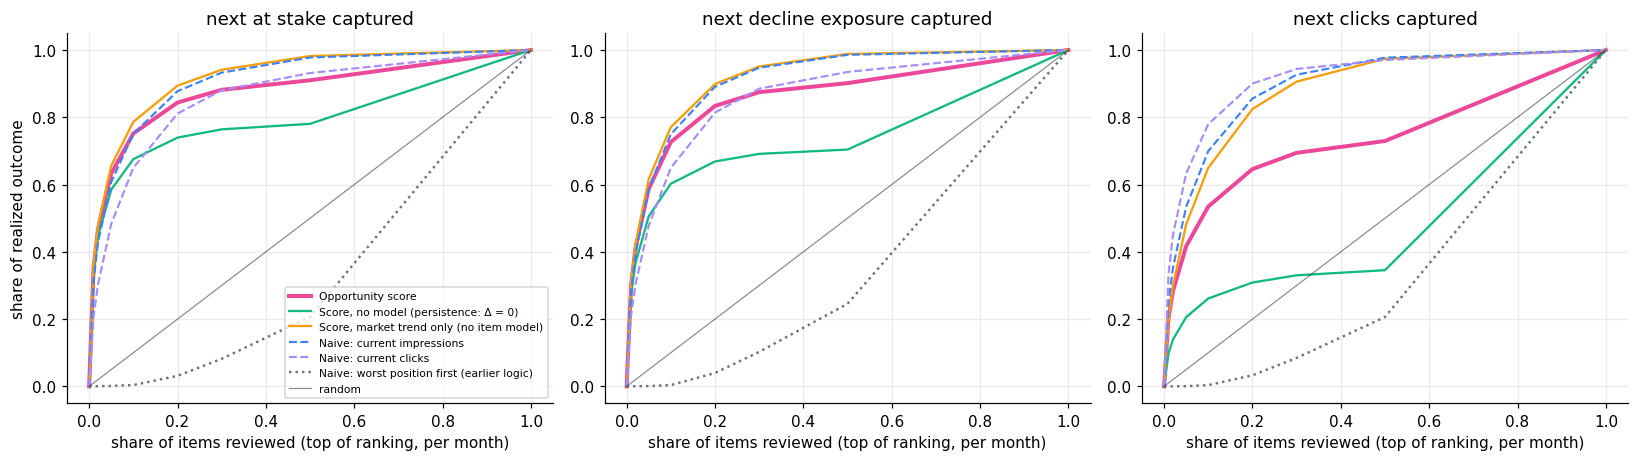

In [36]:
other = RESULTS["selection"]["other_model"]
Q_PERS = score_queue(dq, np.zeros(len(dq)), CTX_BT)
Q_TREND = score_queue(dq, preds["test"][TREND], CTX_BT)
Q_OTHER = score_queue(dq, preds["test"][other], CTX_BT)

bt = Q_BT.copy()
for c in ["next_impressions", "next_clicks", "next_sum_position", "y_delta"]:
    bt[c] = dq[c].to_numpy()
bt["next_missed_clicks"] = np.maximum(bt["expected_ctr"] * bt["next_impressions"] - bt["next_clicks"], 0)
bt["next_decline_exposure"] = np.maximum(bt["impressions"] - bt["next_impressions"], 0) * bt["expected_ctr"]
bt["next_at_stake"] = bt["next_missed_clicks"] + LAMBDA * bt["next_decline_exposure"]

SCORE = "Opportunity score"
ORDERINGS = {SCORE: bt["score"].to_numpy(),
             f"Score using {other} predictions": Q_OTHER["score"].to_numpy(),
             "Score, no model (persistence: Δ = 0)": Q_PERS["score"].to_numpy(),
             "Score, market trend only (no item model)": Q_TREND["score"].to_numpy(),
             "Predicted missed clicks only": bt["pred_missed_clicks"].to_numpy(),
             "Naive: current impressions": bt["impressions"].to_numpy(),
             "Naive: current clicks": bt["clicks"].to_numpy(),
             "Naive: worst position first (earlier logic)": bt["avg_position"].to_numpy()}
OUTCOMES = {"next_at_stake": bt["next_at_stake"].to_numpy(float), "next_decline_exposure": bt["next_decline_exposure"].to_numpy(float),
            "next_missed_clicks": bt["next_missed_clicks"].to_numpy(float), "next_clicks": bt["next_clicks"].to_numpy(float)}
months_arr, groups_arr = bt["month"].to_numpy(), bt["client_hash_id"].to_numpy()


def month_rank(values):
    return pd.Series(values).groupby(months_arr).rank(pct=True, method="first").to_numpy()


def top_mask(values, frac):
    return month_rank(values) > 1 - frac


def capture_boot(top, outcome, top_b=None, B=1000):
    """Capture (share of outcome inside `top`) with client-clustered CI; with top_b, the paired difference."""
    codes, uniq = pd.factorize(pd.Series(groups_arr))
    g = len(uniq)
    tot = np.bincount(codes, weights=outcome, minlength=g)
    a = np.bincount(codes, weights=outcome * top, minlength=g)
    draws = np.random.default_rng(SEED).integers(0, g, size=(B, g))
    cap_a = a[draws].sum(1) / tot[draws].sum(1)
    if top_b is None:
        return float(a.sum() / tot.sum()), *np.percentile(cap_a, [2.5, 97.5])
    b = np.bincount(codes, weights=outcome * top_b, minlength=g)
    diff = cap_a - b[draws].sum(1) / tot[draws].sum(1)
    return float(a.sum() / tot.sum() - b.sum() / tot.sum()), *np.percentile(diff, [2.5, 97.5])


def client_macro_capture(values, outcome, frac=0.10, min_items=100):
    """Mean over eligible client-months: share of realized outcome in that client's own top frac."""
    r = pd.Series(values).groupby([months_arr, groups_arr]).rank(pct=True, method="first").to_numpy()
    df = pd.DataFrame({"g": groups_arr, "m": months_arr, "out": outcome, "top_out": outcome * (r > 1 - frac)})
    a = df.groupby(["m", "g"]).agg(n=("out", "size"), tot=("out", "sum"), top=("top_out", "sum"))
    a = a[(a["n"] >= min_items) & (a["tot"] > 0)]
    return float((a["top"] / a["tot"]).mean()), int(len(a))


def client_macro_capture_ci(values, outcome, frac=0.10, min_items=100, B=1000, seed=SEED):
    """Client-clustered percentile CI for equal-weight client-month capture."""
    r = pd.Series(values).groupby([months_arr, groups_arr]).rank(pct=True, method="first").to_numpy()
    df = pd.DataFrame({"g": groups_arr, "m": months_arr, "out": outcome, "top_out": outcome * (r > 1 - frac)})
    a = df.groupby(["m", "g"]).agg(n=("out", "size"), tot=("out", "sum"), top=("top_out", "sum"))
    a = a[(a["n"] >= min_items) & (a["tot"] > 0)].copy()
    a["capture"] = a["top"] / a["tot"]
    codes, clients = pd.factorize(a.index.get_level_values("g"), sort=False)
    n_clients = len(clients)
    if not len(a) or n_clients < 2:
        point = float(a["capture"].mean()) if len(a) else float("nan")
        return point, float("nan"), float("nan"), int(len(a))
    sums = np.bincount(codes, weights=a["capture"].to_numpy(float), minlength=n_clients)
    counts = np.bincount(codes, minlength=n_clients).astype(float)
    draws = np.random.default_rng(seed).integers(0, n_clients, size=(B, n_clients))
    boot = sums[draws].sum(axis=1) / counts[draws].sum(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return float(a["capture"].mean()), float(lo), float(hi), int(len(a))


def client_macro_capture_diff_ci(values_a, values_b, outcome, frac=0.10, min_items=100, B=1000, seed=SEED):
    """Paired score-minus-comparator client-month macro capture, bootstrapping whole clients."""
    rank_a = pd.Series(values_a).groupby([months_arr, groups_arr]).rank(pct=True, method="first").to_numpy()
    rank_b = pd.Series(values_b).groupby([months_arr, groups_arr]).rank(pct=True, method="first").to_numpy()
    frame = pd.DataFrame({"g": groups_arr, "m": months_arr, "out": outcome,
                          "top_a": outcome * (rank_a > 1 - frac),
                          "top_b": outcome * (rank_b > 1 - frac)})
    a = frame.groupby(["m", "g"]).agg(n=("out", "size"), tot=("out", "sum"),
                                        top_a=("top_a", "sum"), top_b=("top_b", "sum"))
    a = a[(a["n"] >= min_items) & (a["tot"] > 0)].copy()
    a["diff"] = (a["top_a"] - a["top_b"]) / a["tot"]
    client_codes, clients = pd.factorize(a.index.get_level_values("g"), sort=False)
    n_clients = len(clients)
    if not len(a) or n_clients < 2:
        point = float(a["diff"].mean()) if len(a) else float("nan")
        return point, float("nan"), float("nan"), int(len(a))
    sums = np.bincount(client_codes, weights=a["diff"].to_numpy(float), minlength=n_clients)
    counts = np.bincount(client_codes, minlength=n_clients).astype(float)
    draws = np.random.default_rng(seed).integers(0, n_clients, size=(B, n_clients))
    boot = sums[draws].sum(axis=1) / counts[draws].sum(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return float(a["diff"].mean()), float(lo), float(hi), int(len(a))


TOP10 = {n: top_mask(v, 0.10) for n, v in ORDERINGS.items()}
bt_rows, bt_store, macro_store, macro_ci_store, macro_diff_store = [], {}, {}, {}, {}
for name, top in TOP10.items():
    row = {"ordering": name}
    for oname, out in OUTCOMES.items():
        cap, lo_, hi_ = capture_boot(top, out)
        row[f"{oname} capture@10% [95% CI]"] = fmt_ci(cap, lo_, hi_, 3)
        row[f"{oname} lift×"] = cap / 0.10
        bt_store[(name, oname)] = cap
        if name != SCORE:
            d_, dlo, dhi = capture_boot(TOP10[SCORE], out, top_b=top)
            row[f"{oname}: score − this [CI]"] = fmt_ci(d_, dlo, dhi, 3)
            row[f"{oname}: verdict (score vs this)"] = "score better" if dlo > 0 else ("score worse" if dhi < 0 else "indistinguishable")
    mc, mlo, mhi, n_cm = client_macro_capture_ci(ORDERINGS[name], OUTCOMES["next_at_stake"])
    row["per-client macro capture@10% (at-stake)"] = mc
    row["per-client macro capture@10% [95% client-bootstrap CI]"] = fmt_ci(mc, mlo, mhi, 3)
    macro_store[name] = mc
    macro_ci_store[name] = {"estimate": mc, "lo": mlo, "hi": mhi}
    if name != SCORE:
        md, mdlo, mdhi, n_macro_pairs = client_macro_capture_diff_ci(
            ORDERINGS[SCORE], ORDERINGS[name], OUTCOMES["next_at_stake"], seed=SEED + 200 + len(bt_rows)
        )
        macro_diff_store[name] = {"difference_score_minus_comparator": md, "lo": mdlo, "hi": mdhi,
                                  "client_months": n_macro_pairs,
                                  "verdict": "score better" if mdlo > 0 else ("score worse" if mdhi < 0 else "indistinguishable")}
        row["per-client macro Δ (score − this) [95% client-bootstrap CI]"] = fmt_ci(md, mdlo, mdhi, 3)
        row["per-client macro verdict"] = macro_diff_store[name]["verdict"]
    else:
        row["per-client macro Δ (score − this) [95% client-bootstrap CI]"] = "reference"
        row["per-client macro verdict"] = "reference"
    bt_rows.append(row)
bt_df = pd.DataFrame(bt_rows)
display(bt_df[["ordering"] + [c for c in bt_df.columns if "capture@10%" in c or c.endswith("lift×")]])
display(bt_df[["ordering"] + [c for c in bt_df.columns if "verdict" in c]])
print(f"Per-client macro capture computed over {n_cm} client-months with ≥ 100 items (0.10 = random).")
RESULTS["queue"]["backtest"] = bt_df.to_dict(orient="records")
RESULTS["queue"]["backtest_capture"] = {f"{n}|{o}": v for (n, o), v in bt_store.items()}
RESULTS["queue"]["per_client_macro_capture"] = macro_store
RESULTS["queue"]["per_client_macro_capture_ci"] = macro_ci_store
RESULTS["queue"]["per_client_macro_paired_differences"] = macro_diff_store
RESULTS["queue"]["per_client_macro_client_months"] = n_cm

fracs = [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50, 1.0]
rank_cache = {n: month_rank(v) for n, v in ORDERINGS.items()}
shown_orders = [SCORE, "Score, no model (persistence: Δ = 0)", "Score, market trend only (no item model)", "Naive: current impressions",
                "Naive: current clicks", "Naive: worst position first (earlier logic)"]
styles = {SCORE: (PALETTE["accent"], "-", 2.6), "Score, no model (persistence: Δ = 0)": ("#10B981", "-", 1.5),
          "Score, market trend only (no item model)": ("#F59E0B", "-", 1.5), "Naive: current impressions": (PALETTE["Ridge"], "--", 1.4),
          "Naive: current clicks": (PALETTE["Decile"], "--", 1.4), "Naive: worst position first (earlier logic)": (PALETTE["Persistence"], ":", 1.6)}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for k, oname in enumerate(["next_at_stake", "next_decline_exposure", "next_clicks"]):
    out = OUTCOMES[oname]
    for name in shown_orders:
        curve = [out[rank_cache[name] > 1 - f].sum() / out.sum() for f in fracs]
        c, ls, lw = styles[name]
        ax[k].plot([0] + fracs, [0] + curve, color=c, ls=ls, lw=lw, label=name)
    ax[k].plot([0, 1], [0, 1], color=PALETTE["ink"], lw=0.8, alpha=0.5, label="random")
    ax[k].set_xlabel("share of items reviewed (top of ranking, per month)")
    ax[k].set_title(oname.replace("_", " ") + " captured")
ax[0].set_ylabel("share of realized outcome"); ax[0].legend(fontsize=7, loc="lower right")
plt.tight_layout()
savefig("fig10_backtest_gain")

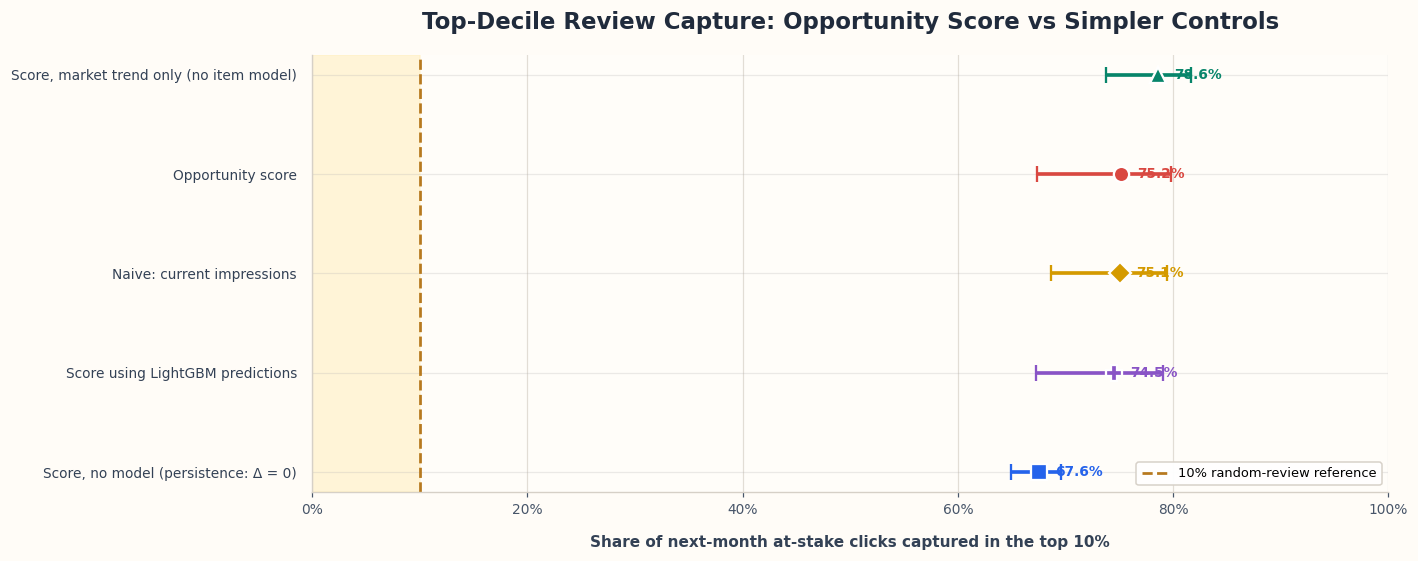

Saved redesigned queue capture plot: /content/docs/figures/fig20_queue_capture_dotplot.png


In [37]:

# Figure 20 — Top-decile review-capture dot plot

from matplotlib.ticker import PercentFormatter
from matplotlib.lines import Line2D
import textwrap

plot_order = [
    "Opportunity score",
    "Score, no model (persistence: Δ = 0)",
    "Score, market trend only (no item model)",
    "Naive: current impressions",
    "Score using " + RESULTS["selection"]["other_model"] + " predictions",
]

plot_order = [
    x for x in plot_order
    if x in ORDERINGS
]

dot_rows = []

for name in plot_order:

    val, lo, hi = capture_boot(
        TOP10[name],
        OUTCOMES["next_at_stake"],
        B=500
    )

    dot_rows.append({
        "ordering": name,
        "capture": float(val),
        "lo": float(lo),
        "hi": float(hi),
    })

dot_df = (
    pd.DataFrame(dot_rows)
    .sort_values("capture")
    .reset_index(drop=True)
)

if not dot_df.empty:

    # Distinct visual identity for each competing ranking strategy.
    def queue_style(name):

        name_lower = name.lower()

        if name == "Opportunity score":
            return "#D94841", "o"

        elif "market trend" in name_lower:
            return "#07856A", "^"

        elif "persistence" in name_lower:
            return "#2563EB", "s"

        elif "current impressions" in name_lower:
            return "#D49A00", "D"

        else:
            return "#8954C6", "P"

    fig, ax = plt.subplots(
        figsize=(13, max(5.2, 0.85 * len(dot_df)))
    )

    fig.patch.set_facecolor("#FFFCF7")
    ax.set_facecolor("#FFFDF9")

    yy = np.arange(len(dot_df))

    # Highlight the region around the random-review reference.
    ax.axvspan(
        0,
        0.10,
        color="#FFF0C2",
        alpha=0.62,
        zorder=0
    )

    # Random-review reference
    ax.axvline(
        0.10,
        color="#B7791F",
        linestyle="--",
        linewidth=1.8,
        label="10% random-review reference",
        zorder=2
    )

    for y, row in dot_df.iterrows():

        color, marker = queue_style(
            row["ordering"]
        )

        left_error = max(
            0.0,
            row["capture"] - row["lo"]
        )

        right_error = max(
            0.0,
            row["hi"] - row["capture"]
        )

        # Bold, visible markers and confidence intervals.
        ax.errorbar(
            row["capture"],
            y,
            xerr=[
                [left_error],
                [right_error]
            ],
            fmt=marker,
            markersize=10,
            markerfacecolor=color,
            markeredgecolor="#FFFFFF",
            markeredgewidth=1.5,
            ecolor=color,
            elinewidth=2.4,
            capsize=5,
            capthick=2.0,
            zorder=4
        )

        # Capture percentage beside each marker.
        if row["capture"] < 0.86:

            label_x = row["capture"] + 0.015
            horizontal_alignment = "left"

        else:

            label_x = row["capture"] - 0.015
            horizontal_alignment = "right"

        ax.text(
            label_x,
            y,
            f"{row['capture']:.1%}",
            va="center",
            ha=horizontal_alignment,
            fontsize=9,
            fontweight="bold",
            color=color,
            zorder=5
        )

    ax.set_yticks(yy)

    ax.set_yticklabels(
        [
            textwrap.fill(name, width=43)
            for name in dot_df["ordering"]
        ],
        fontsize=9,
        color="#334155"
    )

    ax.set_xlim(0, 1.0)

    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=1.0)
    )

    ax.set_xlabel(
        "Share of next-month at-stake clicks captured in the top 10%",
        fontsize=10,
        fontweight="bold",
        color="#334155",
        labelpad=12
    )

    ax.set_title(
        "Top-Decile Review Capture: Opportunity Score vs Simpler Controls",
        fontsize=15,
        fontweight="bold",
        color="#202B3C",
        pad=17
    )

    ax.grid(
        axis="x",
        color="#D6D0C7",
        alpha=0.7,
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="x",
        labelsize=9,
        colors="#475569"
    )

    ax.tick_params(
        axis="y",
        length=0,
        pad=10
    )

    legend = ax.legend(
        loc="lower right",
        frameon=True,
        facecolor="white",
        edgecolor="#D6D0C7",
        fontsize=8.5
    )

    legend.get_frame().set_alpha(0.96)

    for spine in ax.spines.values():
        spine.set_color("#D6D0C7")
        spine.set_linewidth(0.9)

    fig.tight_layout()

    fig.savefig(
        FIG_DIR / "fig20_queue_capture_dotplot.png",
        dpi=300,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close(fig)

else:

    print(
        "Queue capture plot skipped: "
        "no ranking strategies were available."
    )

print(
    "Saved redesigned queue capture plot:",
    FIG_DIR / "fig20_queue_capture_dotplot.png"
)


### 6.4 Tier calibration and concentration

Do higher (per-client) tiers carry more realized next-month at-stake clicks — and more *declines*? How concentrated is the **global** ranking? (Client labels are anonymised; `Client 1` is the client with the most rows.)

In [38]:
tier_rows = (bt.groupby("tier", observed=True)
             .agg(items=("score", "size"), median_impressions=("impressions", "median"), median_position=("avg_position", "median"),
                  mean_score=("score", "mean"), mean_realized_next_at_stake=("next_at_stake", "mean"),
                  mean_realized_next_clicks=("next_clicks", "mean")).reset_index())
fell = (bt["y_delta"] <= np.log(0.6)).groupby(bt["tier"], observed=True).mean().rename("share_fell_40pct_next_month")
tier_df = tier_rows.merge(fell.reset_index(), on="tier").set_index("tier").loc[TIERS[::-1]].reset_index()
display(tier_df)
RESULTS["queue"]["tier_backtest"] = tier_df.to_dict(orient="records")

imm = bt[bt["global_tier"] == "Immediate review"]
share_imm = imm["client_hash_id"].value_counts(normalize=True)
share_all = bt["client_hash_id"].value_counts(normalize=True)
anon = {cid: f"Client {i + 1}" for i, cid in enumerate(share_all.index)}
conc_tbl = pd.DataFrame({"share_of_all_items": share_all, "share_of_global_immediate_tier": share_imm}).fillna(0)
conc_tbl["over_representation"] = conc_tbl["share_of_global_immediate_tier"] / conc_tbl["share_of_all_items"]
conc_tbl.index = conc_tbl.index.map(anon)
display(conc_tbl.sort_values("share_of_global_immediate_tier", ascending=False).head(8))
RESULTS["queue"]["concentration"] = {"clients_in_immediate_tier": int(len(share_imm)), "top1_share_immediate": float(share_imm.iloc[0]),
                                     "top3_share_immediate": float(share_imm.iloc[:3].sum()), "hhi_immediate": float((share_imm ** 2).sum()),
                                     "top1_share_all_items": float(share_all.iloc[0]), "ranking": "global"}
print(RESULTS["queue"]["concentration"])
print("→ The GLOBAL ranking is concentrated in a few clients; per-client tiers (the primary output) are balanced by construction.")

,tier,items,median_impressions,median_position,mean_score,mean_realized_next_at_stake,mean_realized_next_clicks,share_fell_40pct_next_month
0,Immediate review,19506,"5,858.5000",6.5272,34.8650,25.8420,27.2791,0.4295
1,High priority,58380,867.0000,8.8304,4.5622,3.6341,6.1103,0.5158
2,Review,116762,147.0000,12.7500,0.8460,0.8017,1.8006,0.5250
3,Monitor,194605,55.0000,16.3789,0.0869,0.5061,2.4699,0.4456


,share_of_all_items,share_of_global_immediate_tier,over_representation
client_hash_id,,,
Client 1,0.1528,0.3139,2.0537
Client 4,0.0812,0.1704,2.0992
Client 6,0.0477,0.0892,1.8694
Client 2,0.1375,0.0860,0.6251
Client 12,0.0264,0.0820,3.1027
Client 13,0.0245,0.0523,2.1333
Client 3,0.1175,0.0380,0.3236
Client 5,0.0519,0.0338,0.6506


{'clients_in_immediate_tier': 40, 'top1_share_immediate': 0.31386148787505136, 'top3_share_immediate': 0.5735203452527743, 'hhi_immediate': 0.1568883574663286, 'top1_share_all_items': 0.15282605400600638, 'ranking': 'global'}
→ The GLOBAL ranking is concentrated in a few clients; per-client tiers (the primary output) are balanced by construction.


### 6.5 Sensitivity — is the ranking an artifact of λ and β?

Twelve (λ, β) combinations (λ ∈ {0, 0.5, 1, 2}, β ∈ {0, 0.5, 1}) plus 100 random draws. For each: the **top-5% overlap with the default queue** (Jaccard) and capture@10% of every realized outcome (the "at-stake" outcome keeps λ = 1 so outcomes are comparable across schemes).

In [39]:
base_top5 = top_mask(bt["score"].to_numpy(), 0.05)

def eval_scheme(lam, beta):
    s = (bt["pred_missed_clicks"].to_numpy() + lam * bt["decline_exposure"].to_numpy()) * (1 + beta * bt["headroom"].to_numpy())
    r = month_rank(s)
    t5, t10 = r > 0.95, r > 0.90
    return {"top5_overlap_with_default": float((base_top5 & t5).sum() / max((base_top5 | t5).sum(), 1)),
            **{f"capture@10% {o}": float(v[t10].sum() / v.sum()) for o, v in OUTCOMES.items()}}

grid = pd.DataFrame([{"lambda": l, "beta": b, **eval_scheme(l, b)} for l in (0, 0.5, 1, 2) for b in (0, 0.5, 1)])
rng_s = np.random.default_rng(SEED)
rand_eval = pd.DataFrame([eval_scheme(l, b) for l, b in zip(rng_s.uniform(0, 2, 100), rng_s.uniform(0, 1, 100))])
display(grid)
rand_summary = rand_eval.describe().loc[["mean", "min", "max"]]
print("100 random (λ, β) draws:"); display(rand_summary)
RESULTS["queue"]["sensitivity"] = {"grid": grid.to_dict(orient="records"), "random_summary": rand_summary.to_dict()}

,lambda,beta,top5_overlap_with_default,capture@10% next_at_stake,capture@10% next_decline_exposure,capture@10% next_missed_clicks,capture@10% next_clicks
0,0.0000,0.0000,0.5910,0.6723,0.5960,0.7621,0.2608
1,0.0000,0.5000,0.5914,0.6719,0.5943,0.7631,0.2608
2,0.0000,1.0000,0.5894,0.6711,0.5925,0.7635,0.2606
3,0.5000,0.0000,0.8222,0.7468,0.7163,0.7827,0.5020
4,0.5000,0.5000,0.8279,0.7465,0.7140,0.7846,0.5018
5,0.5000,1.0000,0.8207,0.7456,0.7116,0.7855,0.5018
6,1.0000,0.0000,0.9405,0.7520,0.7281,0.7801,0.5345
7,1.0000,0.5000,1.0000,0.7518,0.7262,0.7818,0.5346
8,1.0000,1.0000,0.9625,0.7507,0.7237,0.7824,0.5345
9,2.0000,0.0000,0.8054,0.7496,0.7309,0.7715,0.5565


100 random (λ, β) draws:


,top5_overlap_with_default,capture@10% next_at_stake,capture@10% next_decline_exposure,capture@10% next_missed_clicks,capture@10% next_clicks
mean,0.8555,0.7457,0.7162,0.7805,0.5153
min,0.5950,0.6805,0.6066,0.7674,0.2893
max,0.9867,0.7523,0.7308,0.7859,0.5563


### 6.6 The current queue — scoring the release's final month

The backtest queue is for months whose "next month" has already happened. The **actionable** queue scores the release's **final month**, which has features but no label. For this step only, the selected model is refit on *all* labeled months with the already-chosen hyperparameters; volume thresholds are re-estimated on the same rows; relative prediction thresholds come from the evaluated model's **test-period** out-of-time predictions; the routing gate of §6.1 is **re-applied to the last three labeled months** (validation + test, all out-of-time). ID-level output goes to `outputs_private/` (git-ignored); only anonymous aggregates and an ID-free sample go to `outputs_public/`.

# 7. Limitations and discussion

**Language used throughout.** *Observed* = a descriptive fact about this panel. *Directional* = an association or out-of-time pattern that may not transfer. *Decision-support* = a ranking meant to focus human review; it is not a forecast guarantee.

**Standing limitations** (true regardless of results):

* Observational data only. Nothing here establishes how Google ranks pages, and nothing estimates the effect of changing a page.
* Average position is an impression-weighted mean over many queries. Expected CTR is **peer-relative** (same client, same month, same position bucket), so "missed clicks" is a **screening estimate within a client**, not a forecast of clicks gained and not a statement about a typical results page.
* Monthly granularity; no page-text, query-level, backlink or competitor features are available, so the playbook produces *review prompts*, not prescriptions. Merge/prune decisions need data this release does not contain.
* One release, one panel of clients: results describe this panel and period.
* Validation months were used for early stopping, model selection and the routing gate, so validation scores are mildly optimistic; test months are the honest estimate and were used once.
* The CatBoost and LightGBM additions expand the candidate family but do not guarantee an improvement; validation is still a single chronological window and the final test covers only two feature months.
* The additional client-level sign-flip inference assumes client clusters are independent and uses a symmetric sign-flip null. The pooled client bootstrap and equal-client sign-flip estimands are intentionally not interchangeable.
* GMM uses a diagonal-covariance approximation and sampled training subsets for compute. BIC and silhouette are diagnostics, not direct evidence of operational usefulness.
* The archetype outcome test permutes labels within client-month strata and uses a finite Monte Carlo sample; clusters can still reflect unobserved composition or feed characteristics. The one-hot augmentation is post-hoc and requires a new future holdout before any adoption.

The next cell adds the **data-driven** caveats computed from this run — including every validity finding from §2.

Rolling gate for the LIVE queue (months 2026-03 … 2026-05) — PREDICTED_DECLINE: pooled lift 0.94×; monthly lifts [0.9, 0.73, 0.97]; latest 0.97× → flag only; actions use the OBSERVED counterpart.
Rolling gate for the LIVE queue (months 2026-03 … 2026-05) — PREDICTED_GROWTH: pooled lift 2.53×; monthly lifts [2.25, 2.25, 3.34]; latest 3.34× → ROUTES actions.
Scored 194,174 items for 2026-06 across 46 clients.  Unreachable actions: none


,tier,items,median_impressions,median_position,at_stake_clicks,observed_decline_share
0,Immediate review,9733,"5,323.0000",6.9884,"221,701.6691",0.2225
1,High priority,29122,860.0000,8.9723,"77,727.6055",0.3067
2,Review,58243,170.0000,12.8179,"31,793.4438",0.2681
3,Monitor,97076,28.0000,16.4802,"6,301.1274",0.0970


,recommended_action,items,clients,at_stake_clicks,median_position,median_impressions,median_predicted_change,share_of_tier_items
0,Refresh review (decline risk),7298,31,"55,312.0450",9.7205,"2,281.0000",-0.3835,0.1878
1,Metadata / snippet review,7488,39,"180,687.1659",6.8792,"4,715.5000",-0.2168,0.1927
2,Content improvement review (page-1 push),19460,45,"54,903.8166",7.7010,554.5000,-0.2271,0.5008
3,Rewrite / re-target review,700,31,"1,850.1365",29.0323,"1,228.5000",-0.3197,0.0180
4,Protect & amplify (monitor growth),743,31,"2,111.0018",2.6916,462.0000,-0.0916,0.0191
5,Monitor,3166,41,"4,565.1088",27.1774,209.0000,-0.2916,0.0815



Top of three clients' queues (identifiers withheld; ranks are within each client):


,client_label,priority_rank_in_client,tier,archetype,recommended_action,reason_codes,impressions,clicks,ctr,avg_position,pred_next_impr,at_stake_clicks,score
0,Client 1,1,Immediate review,Page-one performer (B),Metadata / snippet review,LOW_CTR_FOR_POSITION;HIGH_VISIBILITY,"116,908.0000",550.0000,0.0047,1.9000,"95,742.0000",535.6000,535.6000
1,Client 1,2,Immediate review,Page-one performer (B),Metadata / snippet review,LOW_CTR_FOR_POSITION;STRIKING_DISTANCE;HIGH_VI...,"111,728.0000",104.0000,0.0009,4.1000,"75,215.0000",378.4000,529.7000
2,Client 1,3,Immediate review,Page-one performer (B),Metadata / snippet review,LOW_CTR_FOR_POSITION;STRIKING_DISTANCE;HIGH_VI...,"126,300.0000",233.0000,0.0018,4.1000,"100,635.0000",319.9000,447.9000
29814,Client 2,1,Immediate review,Page-one performer (B),Metadata / snippet review,LOW_CTR_FOR_POSITION;STRIKING_DISTANCE;HIGH_VI...,"212,758.0000",252.0000,0.0012,4.8000,"185,119.0000",559.9000,783.9000
29815,Client 2,2,Immediate review,Page-one performer (B),Metadata / snippet review,LOW_CTR_FOR_POSITION;STRIKING_DISTANCE;HIGH_VI...,"147,015.0000",148.0000,0.0010,4.7000,"117,714.0000",413.7000,579.1000
29816,Client 2,3,Immediate review,Page-one performer (B),Metadata / snippet review,LOW_CTR_FOR_POSITION;STRIKING_DISTANCE;HIGH_VI...,"172,226.0000",348.0000,0.0020,5.5000,"162,618.0000",221.3000,309.9000
54905,Client 3,1,Immediate review,Page-one performer (B),Metadata / snippet review,LOW_CTR_FOR_POSITION;HIGH_VISIBILITY,"4,831.0000",29.0000,0.0060,2.9000,"4,435.0000",228.4000,228.4000
54906,Client 3,2,Immediate review,Mid-pack / striking distance (B),Metadata / snippet review,LOW_CTR_FOR_POSITION;OBSERVED_GROWTH;HIGH_VISI...,"3,667.0000",0.0000,0.0000,2.3000,"3,124.0000",193.2000,193.2000
54907,Client 3,3,Immediate review,Mid-pack / striking distance (A),Refresh review (decline risk),LOW_CTR_FOR_POSITION;OBSERVED_DECLINE;PREDICTE...,"2,872.0000",3.0000,0.0010,2.7000,"1,773.0000",149.0000,149.0000



ID-level queue written to outputs_private/ (git-ignored). Public sample (top 3 items for each of the 25 largest clients): outputs_public/ranked_queue_sample_public.csv


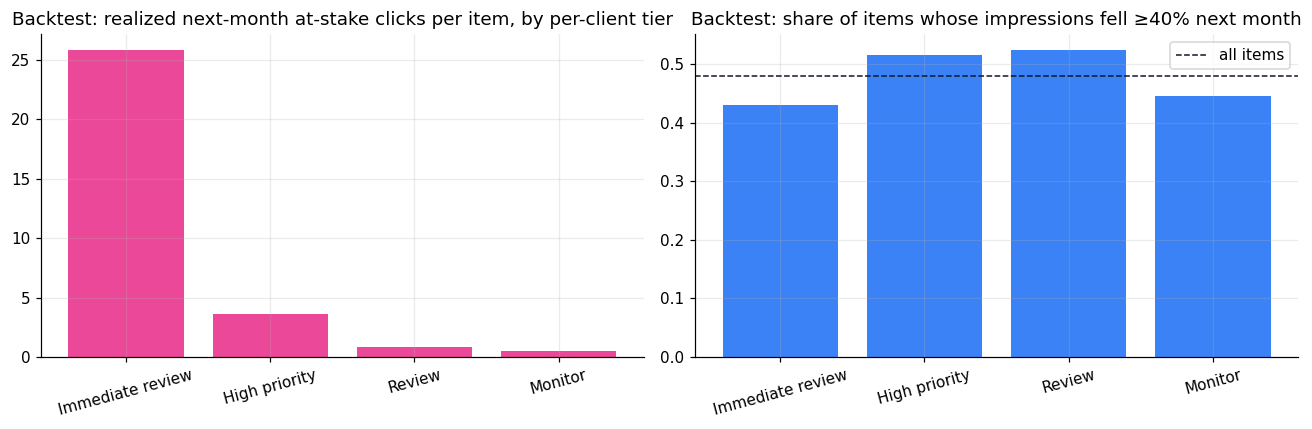

In [40]:
FIT_COLS = list(dict.fromkeys(FEATURES + ["y_delta", "impressions", "client_hash_id", "month_idx"]))
lab_all = pd.concat([D[s][FIT_COLS] for s in SPLITS], ignore_index=True)
final_model = refit_model(SELECTED, lab_all[FEATURES], lab_all["y_delta"])

live = panel[panel["is_last_month"] & panel["cur_ok"]].reset_index(drop=True)
live["arch_id"] = assign_archetypes(live)
live["archetype"] = live["arch_id"].map(names)
d_vt = pd.concat([D["validation"], D["test"]], ignore_index=True)
pred_vt = np.concatenate([preds["validation"][SELECTED], preds["test"][SELECTED]])
last3 = sorted(d_vt["month"].astype(str).unique())[-3:]
sel3 = d_vt["month"].astype(str).isin(last3).to_numpy()
CTX_VT = make_context(D["train"], pred_vt)
Q_VT = score_queue(d_vt[sel3].reset_index(drop=True), pred_vt[sel3], CTX_VT)
cv_vt = code_validation(Q_VT, d_vt[sel3].reset_index(drop=True))
cv_vt_m = code_validation_by_month(Q_VT, d_vt[sel3].reset_index(drop=True))
ROUTE_DECLINE_LIVE, gate_dec_live = routing_gate(cv_vt, cv_vt_m, "PREDICTED_DECLINE")
ROUTE_GROWTH_LIVE, gate_gro_live = routing_gate(cv_vt, cv_vt_m, "PREDICTED_GROWTH")
for tag, ok, g in (("PREDICTED_DECLINE", ROUTE_DECLINE_LIVE, gate_dec_live), ("PREDICTED_GROWTH", ROUTE_GROWTH_LIVE, gate_gro_live)):
    print(f"Rolling gate for the LIVE queue (months {last3[0]} … {last3[-1]}) — {tag}: pooled lift {g['pooled_lift']:.2f}×; monthly lifts "
          f"{[round(x, 2) for x in g['monthly_lifts']]}; latest {g['last_month_lift']:.2f}× → {'ROUTES actions' if ok else 'flag only; actions use the OBSERVED counterpart'}.")
RESULTS["queue"]["route_pred_decline_live"], RESULTS["queue"]["route_pred_growth_live"] = ROUTE_DECLINE_LIVE, ROUTE_GROWTH_LIVE
RESULTS["queue"]["gate_live"] = {"months": last3, "PREDICTED_DECLINE": gate_dec_live, "PREDICTED_GROWTH": gate_gro_live}
CTX_LIVE = make_context(lab_all, preds["test"][SELECTED], ROUTE_DECLINE_LIVE, ROUTE_GROWTH_LIVE)
del lab_all
gc.collect()
live_pred = predict_fitted(SELECTED, final_model, live[FEATURES])
Q_LIVE = score_queue(live, live_pred, CTX_LIVE)
live_actions = Q_LIVE["recommended_action"].value_counts()
RESULTS["queue"]["dead_action_branches_live"] = [a for a in ACTIONS if live_actions.get(a, 0) == 0]
print(f"Scored {len(Q_LIVE):,} items for {LAST_MONTH} across {Q_LIVE['client_hash_id'].nunique()} clients.  "
      f"Unreachable actions: {RESULTS['queue']['dead_action_branches_live'] or 'none'}")

client_size = Q_LIVE["client_hash_id"].value_counts()
client_no = {cid: i + 1 for i, cid in enumerate(client_size.index)}            # 1 = client with the most items; anonymous labels
Q_LIVE["client_no"] = Q_LIVE["client_hash_id"].map(client_no)
Q_LIVE["client_label"] = "Client " + Q_LIVE["client_no"].astype(str)
Q_LIVE = Q_LIVE.sort_values(["client_no", "priority_rank_in_client"]).reset_index(drop=True)
Q_LIVE.to_parquet(PRIVATE_DIR / f"ranked_queue_{LAST_MONTH}_INTERNAL.parquet", index=False)
Q_LIVE[Q_LIVE["priority_rank_in_client"] <= 50].to_csv(PRIVATE_DIR / f"ranked_queue_{LAST_MONTH}_top50_per_client_INTERNAL.csv", index=False)
PUBLIC_COLS = ["client_label", "priority_rank_in_client", "tier", "archetype", "recommended_action", "reason_codes", "impressions", "clicks",
               "ctr", "avg_position", "pred_next_impr", "at_stake_clicks", "score"]
top_clients = list(client_size.index[:25])
pub = (Q_LIVE[Q_LIVE["client_hash_id"].isin(top_clients) & (Q_LIVE["priority_rank_in_client"] <= 3)][PUBLIC_COLS]
       .round({"ctr": 4, "avg_position": 1, "pred_next_impr": 0, "at_stake_clicks": 1, "score": 1}))
pub.to_csv(PUBLIC_DIR / "ranked_queue_sample_public.csv", index=False)

live_tier = (Q_LIVE.groupby("tier", observed=True)
             .agg(items=("score", "size"), median_impressions=("impressions", "median"), median_position=("avg_position", "median"),
                  at_stake_clicks=("at_stake_clicks", "sum"),
                  observed_decline_share=("reason_codes", lambda s: s.str.contains("OBSERVED_DECLINE").mean()))
             .loc[TIERS[::-1]].reset_index())
live_tier.to_csv(PUBLIC_DIR / "tier_summary_public.csv", index=False)
display(live_tier)

top_tiers = Q_LIVE[Q_LIVE["tier"].isin(["Immediate review", "High priority"])]
playbook = (top_tiers.groupby("recommended_action")
            .agg(items=("score", "size"), clients=("client_hash_id", "nunique"), at_stake_clicks=("at_stake_clicks", "sum"),
                 median_position=("avg_position", "median"), median_impressions=("impressions", "median"),
                 median_predicted_change=("pred_delta", "median"))
            .reindex(ACTIONS).dropna(how="all").reset_index())
playbook["share_of_tier_items"] = playbook["items"] / playbook["items"].sum()
display(playbook)
print("\nTop of three clients' queues (identifiers withheld; ranks are within each client):")
show(pub.head(9))
print(f"\nID-level queue written to {PRIVATE_DIR.name}/ (git-ignored). Public sample (top 3 items for each of the 25 largest clients): "
      f"{PUBLIC_DIR.name}/ranked_queue_sample_public.csv")

tot_stake = float(Q_LIVE["at_stake_clicks"].sum())
RESULTS["queue"]["live"] = {"month": LAST_MONTH, "items": int(len(Q_LIVE)), "clients": int(Q_LIVE["client_hash_id"].nunique()),
                            "tiers": live_tier.to_dict(orient="records"), "playbook": playbook.to_dict(orient="records"),
                            "total_at_stake_clicks": tot_stake,
                            "immediate_share_of_at_stake": float(Q_LIVE.loc[Q_LIVE["tier"] == "Immediate review", "at_stake_clicks"].sum() / max(tot_stake, 1e-9)),
                            "refit_on": "all labeled months (train+validation+test), hyperparameters fixed from §4.2",
                            "public_sample_rows": int(len(pub)), "queue_unit": "per-client tiers"}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(tier_df["tier"], tier_df["mean_realized_next_at_stake"], color=PALETTE["accent"])
ax[0].set_title("Backtest: realized next-month at-stake clicks per item, by per-client tier"); ax[0].tick_params(axis="x", rotation=15)
ax[1].bar(tier_df["tier"], tier_df["share_fell_40pct_next_month"], color=PALETTE["Ridge"])
ax[1].axhline(float((bt["y_delta"] <= np.log(0.6)).mean()), color=PALETTE["ink"], ls="--", lw=1, label="all items")
ax[1].set_title("Backtest: share of items whose impressions fell ≥40% next month"); ax[1].tick_params(axis="x", rotation=15); ax[1].legend()
plt.tight_layout()
savefig("fig11_tier_calibration")

In [41]:
VERB_EARLY = {"better": "lower error than", "worse": "higher error than", "indistinguishable": "error statistically indistinguishable from"}

def pct(x, nd=1):
    return "n/a" if (x is None or not np.isfinite(x)) else f"{x:.{nd}%}"

def num(x, nd=2):
    return "n/a" if (x is None or not np.isfinite(x)) else f"{x:.{nd}f}"

lim = []
L_ = RESULTS["ledger"]
# --- position field
pa = RESULTS["position_audit"]
if pa["code"] == "disagree":
    lim.append(f"The sum-based position disagreed with the warehouse's own average position (only {pct(pa['share_within_1_position'])} of rows within one position), so the impression-weighted "
               "warehouse average was used; position-based findings depend on that choice.")
elif pa["code"] == "sparse":
    lim.append(f"The warehouse's own average-position field covers only {pct(pa['weighted_field_coverage'])} of rows, so the two position fields could not be fully cross-checked; the sum-based field was used.")
else:
    lim.append(f"The sum-based position and the warehouse's own average position agree ({pct(pa['share_within_1_position'])} of rows within one position), so the sum-based field was used.")
ib = L_["invalid_breakdown"]
cand = L_["observations"] + ib["any_reason"]
if ib["any_reason"] == 0:
    lim.append("No rows were dropped as implausible (clicks > impressions, missing or impossible position, non-finite values).")
else:
    lim.append(f"{ib['any_reason']:,} candidate rows ({ib['any_reason'] / max(cand, 1):.1%}) were dropped as implausible — no position reported: {ib['position_missing']:,}; impossible position between 0 and 1: "
               f"{ib['position_between_0_and_1']:,}; clicks > impressions: {ib['clicks_gt_impressions']:,}. Median impressions are {ib['median_impressions_dropped']:,.0f} for dropped rows versus "
               f"{ib['median_impressions_kept']:,.0f} for kept rows, so the filter removes {'smaller' if ib['median_impressions_dropped'] < ib['median_impressions_kept'] else 'larger'}-volume items.")
# --- benchmark
bm = RESULTS["benchmark"]
if bm["plausible"]:
    lim.append(f"The pooled CTR-by-position prior falls steeply with position (CTR@1 {bm['prior_at_positions'][1]:.1%}, {bm['ctr1_over_ctr10']:.1f}× CTR@10), as expected for web-search metrics; "
               "expected CTR is nevertheless peer-relative, so missed-click estimates remain screening estimates within a client.")
else:
    lim.append(f"The pooled CTR-by-position prior is NOT plausible for standard web-search metrics (CTR@1 {bm['prior_at_positions'][1]:.2%}; CTR@1 is {bm['ctr1_over_ctr10']:.1f}× CTR@10). "
               "Position or click fields may not behave like organic web-search data, so 'missed clicks' are peer-relative only and must not be read as clicks relative to a typical results page.")
# --- duplicates
du = RESULTS["duplicates"]
if du["flagged_rows"]:
    lim.append(f"{du['flagged_rows']:,} observations ({du['share_of_observations']:.2%}) sit in duplicated metric blocks across {du['clients_affected']} client(s) (exact rule {du['exact_rows']:,}; caught only by the "
               f"near-duplicate rule {du['near_only_rows']:,}; largest block {du['largest_block_items']} items) and were {'excluded' if du['excluded'] else 'kept'}; zero next-month labels occur in "
               f"{pct(du['zero_label_share_in_blocks'])} of those rows versus {pct(du['zero_label_share_elsewhere'])} elsewhere. Replicated blocks outside both rules, if any, would remain.")
# --- zero labels
zt = {r["split"]: r for r in RESULTS["zero_targets"]}
lim.append(f"Zero next-month impressions are {pct(zt['train']['zero_label_share'])} of training labels, {pct(zt['validation']['zero_label_share'])} of validation and {pct(zt['test']['zero_label_share'])} of test "
           f"labels (present-but-zero share in test: {pct(zt['test']['of_which_present_but_zero'])}). A zero can reflect lost demand or an item-level data gap, which this release cannot separate; results excluding zeros are in §4.9.")
# --- regime
rg = {r["split"]: r for r in RESULTS["regime"]["by_split"]}
bias = RESULTS["error_analysis"]["overall"]["mean_signed_error"]
lim.append(f"The market moved differently across periods: on average {pct(rg['train']['mean_share_fell'], 0)} of items fell month-over-month in training months versus {pct(rg['test']['mean_share_fell'], 0)} in test months"
           f"{' (a regime shift)' if RESULTS['regime']['shift_flag'] else ''}; the mean signed error of {SELECTED} on test is {bias:+.2f} log units. A model trained in one regime carries a bias into the next.")
# --- GA4 coverage and time proxy
tc = RESULTS["train_composition"]
lim.append(f"GA4 coverage differs sharply across time: {tc['share_train_rows_with_ga4']:.1%} of training rows carry any GA4 data versus {tc['share_test_rows_with_ga4']:.1%} of test rows, and "
           f"Spearman(has_ga4, calendar month) in training is {RESULTS['importance']['ga4_time_proxy_rho']:.2f}; GA4 features can therefore act partly as time indicators, and GA4 findings describe this release, not GA4.")
# --- models vs persistence + disclosure
pv = RESULTS["paired_vs_persistence"]
better = [r["model"] for r in pv if r["verdict vs persistence"] == "better"]
worse = [r["model"] for r in pv if r["verdict vs persistence"] == "worse"]
lim.append("Paired with persistence on the test months: " + (f"lower error — {', '.join(better)}. " if better else "no model or baseline shows reliably lower error. ")
           + (f"Higher error — {', '.join(worse)}. " if worse else "") + "All other comparisons are statistically indistinguishable.")
pt = RESULTS["paired_vs_trend"]
better_t = [r["model"] for r in pt if r["verdict vs trend baseline"] == "better"]
worse_t = [r["model"] for r in pt if r["verdict vs trend baseline"] == "worse"]
lim.append("Paired with the model-free trailing-market baseline on the test months: " + (f"lower error — {', '.join(better_t)}. " if better_t else "no model or baseline shows reliably lower error. ")
           + (f"Higher error — {', '.join(worse_t)}. " if worse_t else "") + "All other comparisons are statistically indistinguishable.")
lim.append(RESULTS["selection"]["disclosure"])
_w = {r["model"]: r for r in RESULTS["weighted"]["rows"]}[SELECTED]
lim.append(f"Volume view for {SELECTED}: {RESULTS['weighted']['share_rows_ge_100']:.0%} of test rows (carrying {RESULTS['weighted']['share_impressions_ge_100']:.0%} of impressions) have at least 100 impressions; "
           f"impression-weighted ΔMAE versus persistence {_w['weighted Δ vs persistence']} and versus the trend baseline {_w['weighted Δ vs trend']}; on items with ≥ 100 impressions "
           f"{_w['≥100 Δ vs persistence']} and {_w['≥100 Δ vs trend']}, respectively. Row-weighted MAE alone is dominated by very small items.")
_wf = {r["method"]: r for r in RESULTS["walk_forward"]["test_table"]}
_vw = {"better": "better than", "worse": "worse than", "indistinguishable": "indistinguishable from"}
lim.append("Walk-forward retraining (a post-hoc protocol added after the first test evaluation; hyperparameters not re-tuned) on the test months: "
           f"{WF_LEVEL} is {_vw[_wf[WF_LEVEL]['verdict vs persistence']]} persistence and {_vw[_wf[WF_LEVEL]['verdict vs trend']]} the trend baseline; "
           f"{WF_RESID} is {_vw[_wf[WF_RESID]['verdict vs persistence']]} persistence and {_vw[_wf[WF_RESID]['verdict vs trend']]} the trend baseline. It is reported alongside, not instead of, the pre-registered single-split result.")
auc = RESULTS["drift"]["adversarial_auc"]
lim.append(f"Training and test rows are {'clearly' if auc > 0.7 else 'only modestly'} distinguishable (adversarial AUC {auc:.2f}); validation→test MAE grew "
           f"{RESULTS['val_to_test_mae_ratio'][SELECTED]:.2f}× for {SELECTED} versus {RESULTS['val_to_test_mae_ratio'][PERSIST]:.2f}× for persistence, so accuracy should be read as period-specific.")
new_cl = [r for r in RESULTS["segments"] if r["segment"].startswith("new clients")]
if new_cl:
    lim.append(f"For clients not seen in training ({new_cl[0]['rows']:,} test rows) the paired ΔMAE versus persistence is {new_cl[0]['ΔMAE_vs_persistence [95% CI]']} ({new_cl[0]['verdict']}).")
# --- archetypes
av = RESULTS["archetypes"]["validation"]
if not av["validated"]:
    lim.append(f"Archetypes did not pass the outcome-separation gate (η² = {av['eta_squared']:.3f}; permutation p = {av['permutation_p']:.3f}; archetype-median forecast versus persistence: "
               f"{av['vs_persistence']['verdict']}), so they are descriptive only and the action map is a review heuristic, not a validated policy.")
if RESULTS["archetypes"]["caveat"]:
    lim.append(RESULTS["archetypes"]["caveat"])
# --- queue versus controls and reason codes
_bt = {r["ordering"]: r for r in RESULTS["queue"]["backtest"]}
other_m = RESULTS["selection"]["other_model"]
for oname, why in [("Naive: current impressions", "ranking by current impressions"),
                   ("Score, no model (persistence: Δ = 0)", "the same score computed with no model"),
                   ("Score, market trend only (no item model)", "the same score driven by a market-wide trend only"),
                   (f"Score using {other_m} predictions", f"the same score using {other_m} predictions")]:
    v = _bt[oname]["next_at_stake: verdict (score vs this)"]
    if v != "score better":
        lim.append(f"On realized next-month at-stake clicks the opportunity score is not demonstrably better than {why} (paired verdict: {v})"
                   + ("; the item-level forecast therefore adds no demonstrated value to the queue." if "no model" in oname or "trend" in oname else "."))
cvt = {r["reason_code"]: r for r in RESULTS["queue"]["code_validation_test"]}
_rq = RESULTS["queue"]
_r = lambda x: "routes" if x else "does not route"
lim.append("Reason-code lifts on the test months (flagged ÷ unflagged realized rate): "
           + ", ".join(f"{k} {num(cvt[k]['lift'])}×" for k in ("PREDICTED_DECLINE", "OBSERVED_DECLINE", "PREDICTED_GROWTH", "OBSERVED_GROWTH", "LOW_CTR_FOR_POSITION") if k in cvt)
           + ". A lift near 1 means the code is a label, not evidence; a lift below 1 means the opposite of the code's implication happened more often among flagged items (mean reversion). "
           f"Rolling-gate routing — backtest (validation months): predicted decline {_r(_rq['route_pred_decline'])} actions, predicted growth {_r(_rq['route_pred_growth'])} actions; "
           f"live queue (last three labeled months): predicted decline {_r(_rq['route_pred_decline_live'])} actions, predicted growth {_r(_rq['route_pred_growth_live'])} actions.")
if _rq["non_selective_codes"]:
    lim.append(f"Reason codes flagging more than 35% of items on validation (non-selective, so weak as triage signals): {', '.join(_rq['non_selective_codes'])}.")
cc = RESULTS["queue"]["concentration"]
lim.append(f"The GLOBAL ranking is concentrated (largest client holds {cc['top1_share_immediate']:.1%} of the global Immediate tier; {cc['clients_in_immediate_tier']} clients appear), "
           "which is why the queue is built per client.")
if RESULTS["queue"]["dead_action_branches"] or RESULTS["queue"]["dead_action_branches_live"]:
    lim.append(f"Unreachable action labels — backtest: {RESULTS['queue']['dead_action_branches']}; current queue: {RESULTS['queue']['dead_action_branches_live']}.")
RESULTS["limitations_dynamic"] = lim
for i, t in enumerate(lim, 1):
    print(f"{i}. {t}\n")

1. The sum-based position and the warehouse's own average position agree (100.0% of rows within one position), so the sum-based field was used.

2. 57,253 candidate rows (3.7%) were dropped as implausible — no position reported: 45,431; impossible position between 0 and 1: 11,822; clicks > impressions: 0. Median impressions are 1 for dropped rows versus 118 for kept rows, so the filter removes smaller-volume items.

3. The pooled CTR-by-position prior is NOT plausible for standard web-search metrics (CTR@1 0.58%; CTR@1 is 1.7× CTR@10). Position or click fields may not behave like organic web-search data, so 'missed clicks' are peer-relative only and must not be read as clicks relative to a typical results page.

4. 6,122 observations (0.41%) sit in duplicated metric blocks across 8 client(s) (exact rule 5,424; caught only by the near-duplicate rule 698; largest block 833 items) and were excluded; zero next-month labels occur in 4.0% of those rows versus 9.2% elsewhere. Replicated block

# 8. Recommendations

The following recommendations are tied to the experiment design and its predeclared decision rules. The numerical model ranking and all pass/fail statements are generated from the current run in `RESULTS`; they must be read only after the upgraded notebook has been executed top-to-bottom.

### 8.1 Forecast model adoption

Select the model with the lowest validation MAE, but do not equate validation rank with deployment readiness. Require the untouched test result to be compared with both persistence and trailing-market change using the paired client-clustered intervals and the complementary Holm-adjusted client-level sign-flip results. If no candidate shows a credible and operationally meaningful improvement over the market-trend control, retain the transparent baseline rather than deploying complexity for its own sake.

### 8.2 Signal interpretation and monitoring

Use the ablation, permutation and SHAP views as complementary diagnostics. Correlated GSC features share information, and the GA4 coverage shift can make engagement features behave partly as calendar proxies. Monitor source completeness, feature drift and performance by month, volume band and client cohort before reusing model conclusions in a later period.

### 8.3 Evidence threshold for archetype use

Treat K-means as the primary continuity result and GMM as a challenger. Use cluster names as interpretable summaries only when the profile is supported by training medians. Promote archetypes beyond descriptive review context only when the prespecified stability, minimum-size, held-out silhouette, within-client-month permutation, effect-size and baseline-forecast criteria all pass. A cluster-augmented forecast is post-hoc and should be prospectively repeated on a future untouched period before it influences operational model choice.

### 8.4 Human-in-the-loop prioritization

Use the per-client queue to organize investigation, not to automate page changes. Read reason codes and the page/query context before deciding whether to protect, monitor, improve or rewrite content. Tier labels are triage ranks, not calibrated probabilities of future decline or guaranteed click gains. Archetype labels provide supporting context and do not, by themselves, authorize an edit.

### 8.5 Prospective validation and governance

Extend the study with additional untouched months and repeated walk-forward evaluations. Freeze feature definitions, split policy, model-selection rules, cluster criteria and decision thresholds before each new test window. Record model versions, data-release versions, package locks, drift diagnostics and baseline comparisons. Any change to scoring weights or archetype definitions should be evaluated prospectively.

### 8.6 Overall recommendation

The defensible deliverable is an auditable, time-aware forecast comparison plus an outcome-tested segmentation framework and a human-reviewed queue. The main deployment decision should follow observed out-of-time evidence, not the algorithm with the most sophisticated name or the most attractive cluster visualization.

# 9. Conclusion

This capstone studies whether observable GSC, history and GA4 signals improve forecasts of next-month search-performance change, and whether structured content archetypes add stable, interpretable information to human-review prioritization. The original panel construction, data-quality decisions, 2025/2026 chronological split, target, feature set and baseline definitions are retained. The main forecasting comparison now includes XGBoost, Random Forest, CatBoost and LightGBM, with selection based only on validation MAE and common held-out test evaluation.

The forecast conclusion must be taken from the generated candidate comparison and paired test intervals after the upgraded notebook is rerun. The most important benchmark remains the trailing-market baseline: an advanced model is useful only when it adds credible out-of-time information beyond both persistence and recent market movement. The equal-client sign-flip results complement the pooled client-clustered bootstrap intervals and make the weighting distinction explicit.

The second pillar retains training-defined K-means archetypes and adds a GMM challenger. Cluster geometry, stability, within-client outcome association and training-median cluster forecasts are evaluated separately. A further post-hoc experiment asks whether archetype indicators improve continuous-feature XGBoost. None of these tests guarantees that archetypes will transfer to a new release; if the complete gate is not passed, the groups remain descriptive review context.

The integrated queue is a human-in-the-loop application, evaluated against simple no-model and current-impression controls. It should be used to focus review effort, with reason codes and source context inspected before action. This study does not infer Google's proprietary ranking algorithm or the causal effect of content changes.

### Future research directions

The next validation step is to repeat the frozen forecasting and archetype protocol on additional untouched months. Better temporal coverage of GA4, page-text and query-level features (where authorized), explicit seasonality controls, and prospectively evaluated review interventions would strengthen generalizability. Continued monitoring of distribution shift, calibration of decision thresholds and reproducibility records should precede broader operational use.

# 10. Reproducibility and references

* **Data:** gated Hugging Face release (read token in `HF_TOKEN` / Colab Secrets); never committed. ID-level artifacts remain in `outputs_private/` (git-ignored).
* **Determinism:** global seed 42; the original client-clustered bootstrap remains at 1,000 replicates; the added client sign-flip and within-client-month permutation tests use fixed seeds and record their replicate counts.
* **Environment:** exact package versions, including CatBoost and LightGBM, are written to `outputs_public/requirements-lock.txt`; a run record records timestamps, split configuration, package versions and selected model.
* **Reproduction:** run every cell from top to bottom in the intended Colab environment with authorized access to the warehouse. The new advanced cells are deliberately unexecuted in this delivered copy; the full downstream outputs are cleared to prevent stale baseline-only results from being mistaken for upgraded results.

## References

1. FlyRank. *FlyRank Internship — Pseudonymized Warehouse Release (v20260703).* Hugging Face Datasets. <https://huggingface.co/datasets/FlyRank/internship-warehouse>.
2. Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5–32. <https://doi.org/10.1023/A:1010933404324>.
3. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794. <https://doi.org/10.1145/2939672.2939785>.
4. Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: Unbiased Boosting with Categorical Features. *Advances in Neural Information Processing Systems 31*, 6638–6648. <https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html>.
5. Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *Advances in Neural Information Processing Systems 30*. <https://papers.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html>.
6. Rousseeuw, P. J. (1987). Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster Analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65. <https://doi.org/10.1016/0377-0427(87)90125-7>.
7. Hubert, L., & Arabie, P. (1985). Comparing Partitions. *Journal of Classification*, 2, 193–218. <https://doi.org/10.1007/BF01908075>.
8. Dempster, A. P., Laird, N. M., & Rubin, D. B. (1977). Maximum likelihood from incomplete data via the EM algorithm. *Journal of the Royal Statistical Society: Series B*, 39(1), 1–38. <https://doi.org/10.1111/j.2517-6161.1977.tb01600.x>.
9. MacQueen, J. (1967). Some Methods for Classification and Analysis of Multivariate Observations. In *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability*, Vol. 1, 281–297.
10. Schwarz, G. (1978). Estimating the Dimension of a Model. *The Annals of Statistics*, 6(2), 461–464. <https://doi.org/10.1214/aos/1176344136>.
11. Holm, S. (1979). A Simple Sequentially Rejective Multiple Test Procedure. *Scandinavian Journal of Statistics*, 6, 65–70.
12. Lundberg, S. M., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *Advances in Neural Information Processing Systems 30*.
13. Davison, A. C., & Hinkley, D. V. (1997). *Bootstrap Methods and Their Application.* Cambridge University Press. <https://doi.org/10.1017/CBO9780511802843>.

All cited methods should be interpreted in the specific way they are applied here: a high silhouette does not establish outcome usefulness, BIC is a model-fit criterion rather than a policy validation, and an adjusted permutation result does not establish causality.

In [42]:
import subprocess
from datetime import datetime, timezone

def git_commit():
    try:
        return subprocess.run(["git", "rev-parse", "HEAD"], cwd=REPO_ROOT, capture_output=True, text=True, timeout=5).stdout.strip() or None
    except Exception:
        return None

KEY_PKGS = ["duckdb", "pandas", "numpy", "scikit-learn", "xgboost", "shap", "pyarrow", "matplotlib", "scipy", "catboost", "lightgbm"]
versions = {p: metadata.version(p) for p in KEY_PKGS}
RUN_RECORD = {"finished_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "python": platform.python_version(),
              "packages": versions, "seed": SEED, "release": RESULTS["data"]["release"],
              "min_client_coverage": MIN_CLIENT_COVERAGE, "position_source": POS_CHOICE, "exclude_duplicate_blocks": EXCLUDE_DUPLICATE_BLOCKS,
              "splits": SPLITS, "selected_model": SELECTED, "git_commit": git_commit()}
(PUBLIC_DIR / "requirements-lock.txt").write_text("\n".join(f"{p}=={v}" for p, v in versions.items()) + "\n")
(PUBLIC_DIR / "run_record.json").write_text(json.dumps(to_jsonable(RUN_RECORD), indent=2))
print(json.dumps(to_jsonable(RUN_RECORD), indent=2))

{
  "finished_utc": "2026-11-15T18:15:51+00:00",
  "python": "3.13.18",
  "packages": {
    "duckdb": "1.3.2",
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "xgboost": "3.4.1",
    "shap": "0.54.1",
    "pyarrow": "23.0.1",
    "matplotlib": "3.10.0",
    "scipy": "1.16.3",
    "catboost": "1.2.10",
    "lightgbm": "4.6.0"
  },
  "seed": 42,
  "release": "FlyRank ML Internship warehouse (Hugging Face: FlyRank/internship-warehouse)",
  "min_client_coverage": 0.85,
  "position_source": "sum",
  "exclude_duplicate_blocks": true,
  "splits": {
    "train": [
      "2025-01",
      "2025-02",
      "2025-03",
      "2025-04",
      "2025-05",
      "2025-06",
      "2025-07",
      "2025-08",
      "2025-09",
      "2025-10",
      "2025-11",
      "2025-12"
    ],
    "validation": [
      "2026-01",
      "2026-02",
      "2026-03"
    ],
    "test": [
      "2026-04",
      "2026-05"
    ]
  },
  "selected_model": "XGBoost",
  "git_commit": null
}



# 11. Acknowledgments

I, Priyanka Goswami, the author of this research paper, sincerely thank the FlyRank AI's team for providing access to the pseudonymized internship warehouse dataset and the Machine Learning Internship capstone framework. The opportunity to work with a large-scale, structured search-performance dataset made this research and its practical experimentation possible.

I also acknowledge the role of the internship framework in providing a foundation for exploring machine-learning engineering, predictive analytics, statistical validation and data-driven decision support.


# 12. Paper assets

Everything below is generated from `RESULTS`; nothing is typed by hand.

### 12.1 Results file and the abstract (exactly five sentences: question → method → result)

In [43]:
(PUBLIC_DIR / "results_summary.json").write_text(json.dumps(to_jsonable(RESULTS), indent=2))

VERB = {"better": "lower error than", "worse": "higher error than", "indistinguishable": "error statistically indistinguishable from"}

def sentences(text):
    return [s for s in re.split(r"(?<=[.!?])\s+(?=[A-Z])", text.strip()) if s]

def join_and(items):
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]

def build_abstract():
    L, M = RESULTS["ledger"], RESULTS["models"]
    sel, oth = RESULTS["selection"]["selected"], RESULTS["selection"]["other_model"]
    pv = {r["model"]: r for r in RESULTS["paired_vs_persistence"]}
    t_sel, t_per, t_oth = M[sel]["test"], M[PERSIST]["test"], M[oth]["test"]
    test_span = f"{min(SPLITS['test'])} to {max(SPLITS['test'])}"
    abl = {r["step"]: r for r in RESULTS["ablation"]["rows"]}
    label = {"A. level only": "level-only features", "B. + GSC signals": "adding GSC click, CTR and position features",
             "C. + lag / history": "adding month-over-month history", "D. + GA4 / traffic (full)": "the full feature set"}
    better = [label[k] for k in label if abl[k]["verdict vs persistence"] == "better"]
    worse = [label[k] for k in label if abl[k]["verdict vs persistence"] == "worse"]
    ga4s = RESULTS["ablation"]["ga4_subset"]
    q = {r["ordering"]: r for r in RESULTS["queue"]["backtest"]}
    cap = RESULTS["queue"]["backtest_capture"]
    cap_s, cap_n = cap["Opportunity score|next_at_stake"], cap["Naive: current impressions|next_at_stake"]
    v_n = q["Naive: current impressions"]["next_at_stake: verdict (score vs this)"]
    key_v = "next_at_stake: verdict (score vs this)"
    v_pers, v_trend = q["Score, no model (persistence: Δ = 0)"][key_v], q["Score, market trend only (no item model)"][key_v]
    # the model only "adds value" if it beats BOTH no-model controls; the market-trend control is the harder one
    v_c = "score better" if (v_pers == "score better" and v_trend == "score better") else ("score worse" if "score worse" in (v_pers, v_trend) else "indistinguishable")
    referent = ("the same score driven by a market-wide trend alone" if v_trend == "score worse" else
                "the same score computed with no model" if v_pers == "score worse" else
                "the same score computed with no item-level model (persistence or a market-wide trend)")
    v_phrase = {"score better": "favours the score", "score worse": "favours ranking by current impressions", "indistinguishable": "is statistically indistinguishable"}[v_n]
    c_phrase = {"score better": "the item-level forecast improves on", "score worse": "the item-level forecast is worse than",
                "indistinguishable": "the item-level forecast adds nothing distinguishable to"}[v_c]

    s1 = ("This study tests whether observable GSC, history and GA4 signals improve out-of-time forecasts of next-month impression change beyond persistence and market-trend baselines, "
          "and whether training-derived content archetypes add stable, interpretable information for human review.")
    s2 = (f"Daily FlyRank warehouse records from {RESULTS['data']['first_date']} to {RESULTS['data']['last_date']} are audited for feed health, position consistency, duplicated blocks "
          f"and market-wide regime shifts and aggregated to {L['labeled_rows']:,} labeled item-month observations; ranking-signal feature groups are evaluated against baselines, and training-defined archetypes are clustered and tested "
          "alongside Random Forest, XGBoost, CatBoost and LightGBM comparisons with persistence, trailing-market, constant, decile and Ridge baselines under a chronological split with client-clustered bootstrap intervals, K-means/GMM outcome tests and a post-hoc walk-forward retraining check.")
    pvt = {r["model"]: r for r in RESULTS["paired_vs_trend"]}
    t_trd = M[TREND]["test"]
    s3 = (f"On the held-out test months {test_span}, the pre-selected {sel} reaches an MAE of {t_sel['MAE']:.3f} (95% CI {t_sel['MAE_lo']:.3f} to {t_sel['MAE_hi']:.3f}) against {t_per['MAE']:.3f} "
          f"for persistence and {t_trd['MAE']:.3f} for a model-free trailing-market baseline (which itself shows {VERB[pv[TREND]['verdict vs persistence']]} persistence), with {sel} showing "
          f"{VERB[pv[sel]['verdict vs persistence']]} persistence and {VERB[pvt[sel]['verdict vs trend baseline']]} the trend baseline, while {oth} reaches {t_oth['MAE']:.3f} "
          f"({VERB[pv[oth]['verdict vs persistence']]} persistence; {VERB[pvt[oth]['verdict vs trend baseline']]} the trend baseline).")
    head = (f"Directionally, {join_and(better)} give a distinguishable out-of-time improvement over persistence" if better
            else "Directionally, no feature group gives a distinguishable out-of-time improvement over persistence")
    tail = (f" ({join_and(worse)} {'is' if len(worse) == 1 else 'are'} worse)" if worse else "")
    ga4 = (", although GA4 features reduce error on the rows where GA4 data exist" if ga4s and ga4s["verdict"] == "better" else "")
    reg = ", in a test period whose market-wide direction differs sharply from training" if RESULTS["regime"]["shift_flag"] else ""
    wf_rows = {r["method"]: r for r in RESULTS["walk_forward"]["test_table"]}
    wf_name = RESULTS["walk_forward"]["best_walk_forward_on_test"]
    wf_clause = (f"; with monthly walk-forward retraining (a post-hoc protocol) the better variant, {wf_name}, shows {VERB[wf_rows[wf_name]['verdict vs trend']]} the trend baseline "
                 f"and {VERB[wf_rows[wf_name]['verdict vs persistence']]} persistence")
    s4 = head + tail + ga4 + reg + wf_clause + "."
    s5 = (f"The resulting reason-coded per-client review queue captures {cap_s:.0%} of realized next-month at-stake clicks in its top decile ({cap_s / 0.10:.1f} times a random ordering) "
          f"versus {cap_n:.0%} when ranking by current impressions (a paired comparison that {v_phrase}), and {c_phrase} {referent}, "
          "so it is offered as observational decision support, not as a claim about Google's algorithm or the effect of refreshing pages.")
    text = " ".join([s1, s2, s3, s4, s5])
    assert len(sentences(text)) == 5, f"abstract has {len(sentences(text))} sentences"
    return text

ABSTRACT = build_abstract()
RESULTS["abstract"] = ABSTRACT
print(textwrap.fill(ABSTRACT, 110))
print(f"\nSentences: {len(sentences(ABSTRACT))}")

This study tests whether observable GSC, history and GA4 signals improve out-of-time forecasts of next-month
impression change beyond persistence and market-trend baselines, and whether training-derived content
archetypes add stable, interpretable information for human review. Daily FlyRank warehouse records from
2025-01-27 to 2026-06-30 are audited for feed health, position consistency, duplicated blocks and market-wide
regime shifts and aggregated to 1,208,682 labeled item-month observations; ranking-signal feature groups are
evaluated against baselines, and training-defined archetypes are clustered and tested alongside Random Forest,
XGBoost, CatBoost and LightGBM comparisons with persistence, trailing-market, constant, decile and Ridge
baselines under a chronological split with client-clustered bootstrap intervals, K-means/GMM outcome tests and
a post-hoc walk-forward retraining check. On the held-out test months 2026-04 to 2026-05, the pre-selected
XGBoost reaches an MAE of 0.942 

### 12.2 Build the deployed paper (`docs/index.html`)

A single self-contained HTML research paper with figures embedded. The paper is generated only after the upgraded forecast, inference, clustering and queue cells have run successfully. The references include the original methods plus the CatBoost, LightGBM and cluster-validation sources.

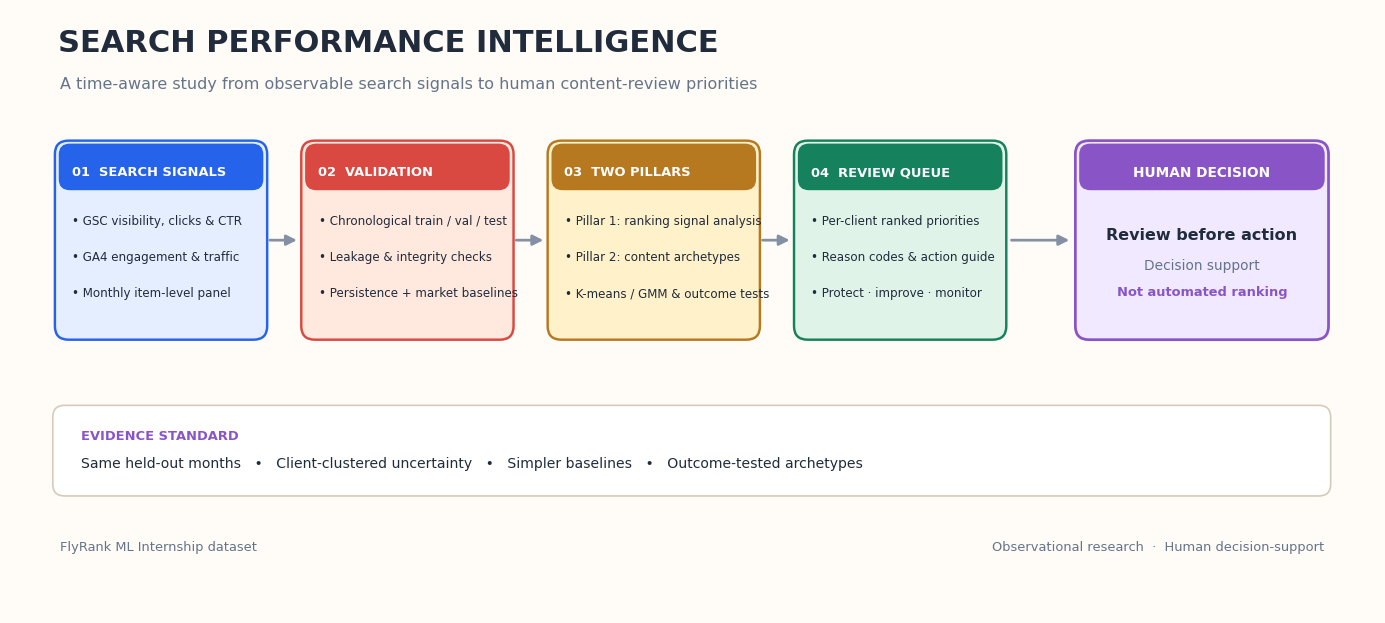

Saved redesigned graphical abstract: /content/docs/figures/fig00_graphical_abstract.png


In [44]:


# Figure 00 — redesigned graphical abstract
# Warm, vibrant, publication-quality research overview.

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle

fig, ax = plt.subplots(figsize=(16, 7.1))

BG = "#FFFCF7"
INK = "#202B3C"
MUTED = "#64748B"

fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
ax.set_xlim(0, 16)
ax.set_ylim(0, 7.1)
ax.axis("off")

# Main title
ax.text(
    0.55, 6.62,
    "SEARCH PERFORMANCE INTELLIGENCE",
    fontsize=20, fontweight="bold", color=INK
)

ax.text(
    0.57, 6.18,
    "A time-aware study from observable search signals to human content-review priorities",
    fontsize=10.5, color=MUTED
)

# Four compact research-stage cards
cards = [
    {
        "x": 0.55,
        "title": "01  SEARCH SIGNALS",
        "lines": [
            "GSC visibility, clicks & CTR",
            "GA4 engagement & traffic",
            "Monthly item-level panel",
        ],
        "face": "#E5EEFF",
        "edge": "#2563EB",
    },
    {
        "x": 3.44,
        "title": "02  VALIDATION",
        "lines": [
            "Chronological train / val / test",
            "Leakage & integrity checks",
            "Persistence + market baselines",
        ],
        "face": "#FFE9DE",
        "edge": "#D94841",
    },
    {
        "x": 6.33,
        "title": "03  TWO PILLARS",
        "lines": [
            "Pillar 1: ranking signal analysis",
            "Pillar 2: content archetypes",
            "K-means / GMM & outcome tests",
        ],
        "face": "#FFF1C9",
        "edge": "#B7791F",
    },
    {
        "x": 9.22,
        "title": "04  REVIEW QUEUE",
        "lines": [
            "Per-client ranked priorities",
            "Reason codes & action guide",
            "Protect · improve · monitor",
        ],
        "face": "#E0F3E8",
        "edge": "#16815D",
    },
]

card_y = 3.25
card_w = 2.42
card_h = 2.28
header_h = 0.52

for card in cards:

    x = card["x"]
    edge = card["edge"]

    # Main rounded card
    ax.add_patch(
        FancyBboxPatch(
            (x, card_y),
            card_w,
            card_h,
            boxstyle="round,pad=0.035,rounding_size=0.16",
            linewidth=1.6,
            edgecolor=edge,
            facecolor=card["face"],
            zorder=1,
        )
    )

    # Colored header
    ax.add_patch(
        FancyBboxPatch(
            (x + 0.025, card_y + card_h - header_h - 0.015),
            card_w - 0.05,
            header_h,
            boxstyle="round,pad=0.015,rounding_size=0.13",
            linewidth=0,
            facecolor=edge,
            zorder=2,
        )
    )

    # Header title
    ax.text(
        x + 0.16,
        card_y + card_h - 0.34,
        card["title"],
        fontsize=8.5,
        fontweight="bold",
        color="#FFFFFF",
        va="center",
        zorder=3,
    )

    # Card content
    for j, line in enumerate(card["lines"]):
        ax.text(
            x + 0.17,
            card_y + card_h - 0.91 - j * 0.43,
            "• " + line,
            fontsize=7.8,
            color=INK,
            va="center",
            zorder=3,
        )

# Directional arrows between stages
for x1, x2 in [(3.00, 3.39), (5.89, 6.28), (8.78, 9.17)]:

    ax.add_patch(
        FancyArrowPatch(
            (x1, card_y + card_h / 2),
            (x2, card_y + card_h / 2),
            arrowstyle="-|>",
            mutation_scale=14,
            linewidth=1.8,
            color="#8491A4",
            zorder=4,
        )
    )

# Final human-decision panel
decision_x = 12.52
decision_y = card_y

ax.add_patch(
    FancyBboxPatch(
        (decision_x, decision_y),
        2.90,
        card_h,
        boxstyle="round,pad=0.035,rounding_size=0.16",
        linewidth=1.8,
        edgecolor="#8954C6",
        facecolor="#F0E9FF",
        zorder=1,
    )
)

ax.add_patch(
    FancyBboxPatch(
        (decision_x + 0.025, decision_y + card_h - header_h - 0.015),
        2.85,
        header_h,
        boxstyle="round,pad=0.015,rounding_size=0.13",
        linewidth=0,
        facecolor="#8954C6",
        zorder=2,
    )
)

ax.text(
    decision_x + 1.45,
    decision_y + card_h - 0.34,
    "HUMAN DECISION",
    fontsize=9,
    fontweight="bold",
    color="white",
    ha="center",
    va="center",
)

ax.text(
    decision_x + 1.45,
    decision_y + 1.15,
    "Review before action",
    fontsize=10.5,
    fontweight="bold",
    color=INK,
    ha="center",
)

ax.text(
    decision_x + 1.45,
    decision_y + 0.79,
    "Decision support",
    fontsize=9,
    color=MUTED,
    ha="center",
)

ax.text(
    decision_x + 1.45,
    decision_y + 0.48,
    "Not automated ranking",
    fontsize=8.5,
    fontweight="bold",
    color="#8954C6",
    ha="center",
)

# Arrow to the decision panel
ax.add_patch(
    FancyArrowPatch(
        (11.70, card_y + card_h / 2),
        (12.45, card_y + card_h / 2),
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=1.8,
        color="#8491A4",
        zorder=4,
    )
)

# Evidence-standard footer
ax.add_patch(
    FancyBboxPatch(
        (0.55, 1.43),
        14.87,
        0.95,
        boxstyle="round,pad=0.06,rounding_size=0.14",
        linewidth=1.1,
        edgecolor="#D6CBB9",
        facecolor="#FFFFFF",
    )
)

ax.text(
    0.82, 2.04,
    "EVIDENCE STANDARD",
    fontsize=8.5,
    fontweight="bold",
    color="#8954C6",
)

ax.text(
    0.82, 1.70,
    "Same held-out months   •   Client-clustered uncertainty   •   Simpler baselines   •   Outcome-tested archetypes",
    fontsize=9.2,
    color=INK,
)

# Footer
ax.text(
    0.57, 0.73,
    "FlyRank ML Internship dataset",
    fontsize=8.5,
    color=MUTED,
)

ax.text(
    15.40, 0.73,
    "Observational research  ·  Human decision-support",
    fontsize=8.5,
    color=MUTED,
    ha="right",
)

fig.savefig(
    FIG_DIR / "fig00_graphical_abstract.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
)

plt.show()
plt.close(fig)

print("Saved redesigned graphical abstract:",
      FIG_DIR / "fig00_graphical_abstract.png")


In [45]:
# REFINED RESEARCH-PAPER HTML GENERATION CELL
# Preserves the notebook's green / mint / teal / gold palette and all research outputs.
# Rebuilds fig00_graphical_abstract.png in FIG_DIR before writing the self-contained HTML.

PAPER_CSS = """
:root{
  --ink:#092D29;
  --muted:#607873;
  --soft:#F0F8F4;
  --paper:#FFFFFF;
  --line:#D7E9E1;
  --green:#0D8060;
  --green-dark:#075A47;
  --green-deep:#042D29;
  --mint:#51E2A4;
  --mint-soft:#E7F8EF;
  --mint-pale:#F1FBF6;
  --teal:#0F8278;
  --gold:#B7791F;
  --shadow:0 15px 38px rgba(5,75,58,.085),0 0 26px rgba(62,211,151,.07);
  --shadow-hover:0 20px 44px rgba(5,75,58,.13),0 0 32px rgba(62,211,151,.12);
  --max:1100px;
}
*{box-sizing:border-box}
html{scroll-behavior:smooth;scroll-padding-top:84px}
body{
  margin:0;
  background:
    radial-gradient(circle at 4% 8%,rgba(81,226,164,.105),transparent 25%),
    radial-gradient(circle at 96% 22%,rgba(183,121,31,.055),transparent 22%),
    #F6FAF8;
  color:var(--ink);
  font:16px/1.72 Inter,ui-sans-serif,system-ui,-apple-system,"Segoe UI",Roboto,Arial,sans-serif;
}
a{color:var(--green);text-decoration:none}
a:hover{color:var(--green-dark);text-decoration:underline;text-underline-offset:3px}
main{width:100%;margin:0;padding:0 0 78px}
.hero{
  position:relative;isolation:isolate;overflow:hidden;
  padding:76px 24px 49px;color:#fff;text-align:left;
  background:
    radial-gradient(circle at 88% 15%,rgba(183,121,31,.18),transparent 25%),
    radial-gradient(circle at 5% 95%,rgba(81,226,164,.22),transparent 31%),
    linear-gradient(132deg,#032824 0%,#064237 54%,#0A5948 100%);
}
.hero:before{
  content:"";position:absolute;z-index:-1;right:-7%;top:-68%;width:610px;height:610px;
  border:1px solid rgba(174,255,220,.16);border-radius:50%;
  box-shadow:0 0 0 34px rgba(174,255,220,.035),0 0 0 76px rgba(174,255,220,.025),0 0 0 124px rgba(174,255,220,.018);
  pointer-events:none;
}
.hero:after{
  content:"";position:absolute;z-index:-1;left:28%;bottom:-90%;width:680px;height:430px;
  border-radius:50%;background:radial-gradient(ellipse,rgba(81,226,164,.16),rgba(183,121,31,.035) 38%,transparent 72%);
  filter:blur(12px);pointer-events:none;
}
.hero-inner{position:relative;z-index:1;width:min(100%,var(--max));margin:0 auto;text-align:left}
.paper-label{
  display:inline-flex;align-items:center;gap:10px;padding:7px 14px;
  border:1px solid rgba(177,255,220,.34);border-radius:999px;
  background:linear-gradient(110deg,rgba(225,255,241,.11),rgba(255,245,226,.07));
  color:#DDFCEF;font-size:.72rem;font-weight:850;letter-spacing:.14em;text-transform:uppercase;
  box-shadow:0 0 22px rgba(81,226,164,.10),inset 0 1px rgba(255,255,255,.08);
}
.paper-label:before{content:"";width:7px;height:7px;border-radius:50%;background:var(--mint);box-shadow:0 0 13px rgba(81,226,164,.98)}
.hero h1{
  max-width:960px;margin:24px 0 17px;font-size:clamp(2.45rem,5.7vw,4.65rem);
  font-weight:880;line-height:1.035;letter-spacing:-.052em;text-wrap:balance;
  text-shadow:0 3px 28px rgba(0,0,0,.13);
}
.hero .subtitle{max-width:800px;margin:0;color:#D5F0E5;font-size:clamp(1.02rem,1.8vw,1.2rem);line-height:1.62}
.byline{display:flex;justify-content:flex-start;align-items:center;flex-wrap:wrap;gap:9px 24px;margin:27px 0 0;color:#E7F7F0;font-size:.91rem}
.byline strong{color:#fff}
.byline-note{max-width:820px;margin:10px 0 0;color:#B8D8CC;font-size:.83rem;line-height:1.62}
.hero-facts{
  display:flex;justify-content:flex-start;align-items:flex-start;flex-wrap:wrap;gap:17px 34px;
  margin:34px 0 0;padding-top:22px;border-top:1px solid rgba(219,255,238,.19);
  color:#C5E2D6;font-size:.82rem;
}
.hero-facts span{display:block;min-width:145px}
.hero-facts b{display:block;margin-bottom:3px;color:#F7FFFB;font-size:.69rem;letter-spacing:.10em;text-transform:uppercase}
.hero-facts a{color:#8AF0BD;text-decoration:underline;text-underline-offset:3px}
.toc{
  position:sticky;top:0;z-index:30;background:rgba(250,255,252,.94);
  backdrop-filter:blur(16px);border-bottom:1px solid var(--line);
  box-shadow:0 5px 20px rgba(5,75,58,.06);
}
.toc-inner{
  display:flex;align-items:center;justify-content:flex-start;gap:4px;overflow-x:auto;white-space:nowrap;
  width:min(100% - 40px,var(--max));margin:0 auto;padding:0 2px;scrollbar-width:thin;
}
.toc a{
  display:inline-flex;align-items:center;min-height:58px;padding:0 13px;
  border-bottom:2px solid transparent;border-radius:7px 7px 0 0;
  color:#55716A;font-size:.77rem;font-weight:780;letter-spacing:.01em;
  transition:color .18s ease,border-color .18s ease,background .18s ease;
}
.toc a:hover{color:var(--green-dark);border-bottom-color:var(--mint);background:rgba(81,226,164,.075);text-decoration:none}
section{
  width:min(calc(100% - 48px),var(--max));margin:0 auto;padding:48px 0 53px;
  border-bottom:1px solid var(--line);scroll-margin-top:82px;
}
section:last-of-type{border-bottom:0}
section h2{
  display:flex;align-items:center;justify-content:flex-start;gap:14px;margin:0 0 23px;padding:0 0 15px;
  border-bottom:1px solid rgba(13,128,96,.16);
  font-size:clamp(1.62rem,3.2vw,2.28rem);line-height:1.18;font-weight:850;letter-spacing:-.04em;
  text-align:left;color:var(--ink);
}
.sec-no{
  display:inline-flex;flex:0 0 auto;align-items:center;justify-content:center;min-width:36px;height:29px;padding:0 9px;
  border:1px solid rgba(13,128,96,.18);border-radius:8px;
  background:linear-gradient(135deg,#E7F8EF,#F8FCF9);color:var(--green-dark);
  box-shadow:0 3px 12px rgba(13,128,96,.08);font-size:.72rem;font-weight:950;letter-spacing:.08em;
}
section h3{margin:33px 0 12px;font-size:1.18rem;line-height:1.36;letter-spacing:-.02em;font-weight:820;color:#103D34}
section h4{margin:25px 0 9px;font-size:1rem;color:#174B40}
p{margin:0 0 17px;text-align:justify;text-justify:inter-word;hyphens:auto;color:#304B45}
.lede{max-width:850px;margin:0 0 25px;color:#607873;font-size:1.02rem;line-height:1.72;text-align:left}
.meta,.note,figcaption{color:var(--muted);font-size:.84rem}
.abstract{
  max-width:100%;margin:0;padding:28px 31px;
  background:linear-gradient(125deg,#FFFFFF 0%,#F7FCF9 68%,#FFFDF8 100%);
  border:1px solid #D7E9E1;border-left:5px solid var(--green);border-radius:15px;
  box-shadow:var(--shadow),0 0 22px rgba(81,226,164,.075);
  font-size:1.01rem;line-height:1.88;text-align:justify;text-justify:inter-word;
}
.callout{
  margin:23px 0;padding:20px 23px;
  background:linear-gradient(112deg,#EAF9F1 0%,#F7FCF9 72%,#FFF9EF 100%);
  border:1px solid #D0EBDD;border-left:4px solid var(--green);border-radius:13px;
  color:#355A4F;box-shadow:0 8px 22px rgba(5,100,72,.055),0 0 20px rgba(81,226,164,.065);
}
.callout strong{display:block;color:var(--green-dark);margin-bottom:5px}
.tag{display:inline-block;margin-left:5px;padding:3px 8px;border:1px solid #CDEBDD;border-radius:999px;background:#EAF9F1;color:#176D50;font-size:.66rem;font-weight:850;letter-spacing:.04em;vertical-align:middle;text-transform:uppercase}
.metric-grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(185px,1fr));gap:15px;margin:25px 0 29px}
.metric{
  position:relative;min-width:0;overflow:hidden;padding:21px 21px 18px;
  background:linear-gradient(145deg,#FFFFFF 0%,#F7FCF9 73%,#FFFDF8 100%);
  border:1px solid #D9EAE2;border-radius:15px;
  box-shadow:0 7px 22px rgba(5,75,58,.065),0 0 19px rgba(81,226,164,.055);
  transition:transform .2s ease,box-shadow .2s ease,border-color .2s ease;
}
.metric:before{content:"";position:absolute;left:0;top:0;width:100%;height:3px;background:linear-gradient(90deg,var(--green),var(--mint),rgba(183,121,31,.55))}
.metric:hover{transform:translateY(-4px);border-color:#A9DEC4;box-shadow:var(--shadow-hover)}
.metric-label{display:block;color:#637C75;font-size:.70rem;font-weight:880;letter-spacing:.09em;text-transform:uppercase}
.metric-value{display:block;margin:7px 0 5px;color:var(--green-dark);font-size:1.72rem;font-weight:900;line-height:1.16;letter-spacing:-.04em;overflow-wrap:anywhere;text-shadow:0 4px 18px rgba(13,128,96,.08)}
.metric-note{display:block;color:#6B817B;font-size:.78rem;line-height:1.5}
.verdict{
  margin:22px 0;padding:19px 23px;
  background:linear-gradient(115deg,#E7F7EF 0%,#F6FCF8 72%,#FFF8EC 100%);
  border:1px solid #D0E9DB;border-left:4px solid var(--teal);border-radius:13px;
  box-shadow:0 7px 20px rgba(9,104,87,.055),0 0 18px rgba(81,226,164,.055);
}
.verdict strong{color:#0B695A}
.tblwrap{overflow-x:auto;margin:20px 0 26px;border:1px solid #DCEAE3;border-radius:13px;background:#fff;box-shadow:0 7px 23px rgba(5,75,58,.055),0 0 18px rgba(81,226,164,.035)}
.tbl{width:100%;border-collapse:separate;border-spacing:0;min-width:560px;font-size:.83rem}
.tbl th,.tbl td{padding:12px 14px;border-bottom:1px solid #E6F0EA;text-align:left;vertical-align:top}
.tbl th{position:sticky;top:0;background:linear-gradient(100deg,#EAF7F0,#F4FAF6);color:#315D50;font-size:.69rem;font-weight:920;letter-spacing:.065em;text-transform:uppercase}
.tbl td{color:#38544B}
.tbl tbody tr:nth-child(even){background:#F7FBF8}
.tbl tbody tr:hover{background:#EEF9F3}
.tbl tr:last-child td{border-bottom:0}
figure{
  width:100%;margin:27px auto 34px;padding:16px 17px 13px;
  background:linear-gradient(145deg,#FFFFFF 0%,#FBFEFC 72%,#FFFDF8 100%);
  border:1px solid #DCEAE3;border-radius:15px;
  box-shadow:0 9px 28px rgba(5,75,58,.065),0 0 22px rgba(81,226,164,.055);
  text-align:center;transition:box-shadow .2s ease,border-color .2s ease;
}
figure:hover{border-color:#B7E0CA;box-shadow:var(--shadow-hover)}
figure img{display:block;width:100%;height:auto;max-height:700px;object-fit:contain;object-position:center;margin:0 auto;border-radius:9px;background:#fff}
figcaption{max-width:960px;margin:0 auto;padding:14px 8px 2px;line-height:1.6;text-align:center}
.graphical-frame{width:100%;display:flex;justify-content:center;align-items:center;margin:17px auto 0}
#graphical-abstract figure{
  width:min(100%,1080px);margin:0 auto;padding:12px;
  border:1px solid #CFE5D9;border-radius:17px;
  background:linear-gradient(145deg,#FFFFFF,#F8FCF9 70%,#FFF9EF);
  box-shadow:0 13px 36px rgba(5,75,58,.09),0 0 30px rgba(81,226,164,.09);
}
#graphical-abstract figure img{width:100%;max-height:none;object-fit:contain;object-position:center;background:transparent}
ul,ol{padding-left:24px}
li{margin:0 0 10px;padding-left:3px;color:#304B45}
li::marker{color:var(--green)}
.limit-list{display:grid;grid-template-columns:1fr 1fr;gap:12px 24px;padding:0;list-style:none}
.limit-list li{position:relative;margin:0;padding:15px 16px 15px 40px;background:linear-gradient(145deg,#FFFFFF,#F7FCF9 78%,#FFFDF8);border:1px solid #DCEAE3;border-radius:12px;color:#4C665D;font-size:.9rem;box-shadow:0 5px 16px rgba(5,75,58,.04)}
.limit-list li:before{content:"!";position:absolute;left:14px;top:15px;display:grid;place-items:center;width:18px;height:18px;border-radius:50%;background:#E5F7ED;color:#13744F;font-size:.7rem;font-weight:950;box-shadow:0 0 12px rgba(81,226,164,.14)}
.limit-list b{color:var(--ink)}
code{padding:2px 5px;border-radius:5px;background:#EAF5EF;color:#17634C;font-size:.87em;overflow-wrap:anywhere}
pre{overflow-x:auto;padding:19px 21px;background:linear-gradient(130deg,#042D29,#075A47);color:#E8FFF4;border:1px solid rgba(81,226,164,.24);border-radius:13px;box-shadow:0 10px 26px rgba(5,75,58,.14),0 0 20px rgba(81,226,164,.06);font-size:.82rem}
pre code{padding:0;background:transparent;color:inherit}
section a{font-weight:730}
.references{padding-left:23px}
.references li{padding-left:6px;margin-bottom:14px}
.footer{position:relative;overflow:hidden;padding:32px 22px;background:linear-gradient(125deg,#032824 0%,#07513F 70%,#0A5948 100%);color:#CDE8DC;text-align:center;font-size:.82rem}
.footer:before{content:"";position:absolute;left:50%;top:-100px;width:440px;height:220px;transform:translateX(-50%);background:radial-gradient(ellipse,rgba(81,226,164,.17),rgba(183,121,31,.04) 45%,transparent 72%);filter:blur(20px);pointer-events:none}
.footer-inner{position:relative;z-index:1;display:flex;justify-content:space-between;align-items:center;gap:12px 24px;flex-wrap:wrap;width:min(100%,var(--max));margin:0 auto}
.footer a{color:#8CF0BD}
@media(max-width:800px){
  .hero{padding:58px 20px 40px}.hero h1{font-size:clamp(2.3rem,8vw,3.45rem)}
  .hero-facts{gap:14px 22px}.toc-inner{width:calc(100% - 24px)}.toc a{padding:0 10px;font-size:.74rem}
  section{width:min(calc(100% - 32px),var(--max));padding:38px 0 43px}
  .abstract{padding:22px;font-size:.97rem}.limit-list{grid-template-columns:1fr}
  .metric-grid{grid-template-columns:repeat(2,minmax(0,1fr))}
}
@media(max-width:480px){
  .hero{padding:47px 17px 34px}.hero h1{font-size:2.35rem}.byline{gap:8px 13px}
  .hero-facts{flex-direction:column;gap:12px}.toc-inner{width:calc(100% - 14px);padding:0}.toc a{padding:0 9px}
  section{width:calc(100% - 28px);padding:33px 0 38px}section h2{gap:10px;font-size:1.55rem}
  .abstract{padding:19px;font-size:.94rem}.metric-grid{grid-template-columns:1fr}
  figure{padding:10px}.footer-inner{justify-content:center;text-align:center}
}
@media(prefers-reduced-motion:reduce){html{scroll-behavior:auto}*,*:before,*:after{transition:none!important;animation:none!important}}
@media print{
  body{background:#fff;color:#111}.toc{position:static;box-shadow:none}
  .hero,.footer{background:#064237!important;-webkit-print-color-adjust:exact;print-color-adjust:exact}
  section{break-inside:auto}.metric,.tblwrap,.callout,.abstract,figure,.verdict{break-inside:avoid;box-shadow:none}
  a{color:inherit;text-decoration:none}
}
"""

def esc(x):
    return html.escape(str(x))

def _num(v, nd=3):
    a = abs(v)
    if a >= 1000:
        return f"{v:,.0f}"
    if a >= 100:
        return f"{v:,.1f}"
    return f"{v:,.{nd}f}"

def tbl(df, rename=None, nd=3):
    d = df.copy()
    d = d.drop(columns=[c for c in d.columns if c in ID_COLS or str(c).startswith("_")])
    if rename:
        d = d.rename(columns=rename)
    d.columns = [str(c).replace("_", " ") for c in d.columns]
    return '<div class="tblwrap">' + d.to_html(index=False, border=0, classes="tbl", na_rep="–", float_format=lambda v: _num(v, nd)) + "</div>"

def fig_html(name, caption):
    p = FIG_DIR / f"{name}.png"
    if not p.exists():
        return f'<p class="note">[figure {esc(name)} missing]</p>'
    b64 = base64.b64encode(p.read_bytes()).decode()
    return f'<figure><img alt="{esc(caption)}" src="data:image/png;base64,{b64}"><figcaption>{esc(caption)}</figcaption></figure>'



def build_graphical_abstract():
    """Create the paper's graphical abstract in the retained green–mint–gold theme."""
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib import patheffects as pe
    from matplotlib.colors import LinearSegmentedColormap
    from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

    FIG_DIR.mkdir(parents=True, exist_ok=True)

    fig, ax = plt.subplots(figsize=(17.8, 8.0), dpi=220)
    fig.patch.set_facecolor("#F6FAF8")
    ax.set_facecolor("#F6FAF8")
    ax.set_xlim(0, 17.8)
    ax.set_ylim(0, 8.0)
    ax.axis("off")

    # Quiet horizontal wash: cool mint on the left, a subtle warm paper tone on the right.
    wash = np.tile(np.linspace(0, 1, 1200), (420, 1))
    cmap = LinearSegmentedColormap.from_list(
        "paper_mint_warmth", ["#F3FAF6", "#FBFDFB", "#FFFDF8"]
    )
    ax.imshow(wash, extent=(0, 17.8, 0, 8.0), origin="lower", aspect="auto",
              cmap=cmap, interpolation="bicubic", zorder=-20)

    # Heading and restrained context label.
    ax.text(0.48, 7.48, "FROM SEARCH SIGNALS TO AN EVIDENCE-LED REVIEW QUEUE",
            ha="left", va="center", fontsize=15.2, fontweight="bold",
            color="#092D29", zorder=5)
    ax.text(0.50, 7.02,
            "A data-quality-aware, time-aware workflow for content decision support",
            ha="left", va="center", fontsize=9.5, color="#607873", zorder=5)
    ax.text(17.28, 7.34, "FLYRANK  /  ML CAPSTONE",
            ha="right", va="center", fontsize=7.7, fontweight="bold",
            color="#075A47",
            bbox=dict(boxstyle="round,pad=0.55,rounding_size=0.35",
                      facecolor="#E7F8EF", edgecolor="#CBE7D8", linewidth=0.9),
            zorder=5)

    cards = [
        {
            "number": "01", "kicker": "INPUT  /  MONTHLY PANEL",
            "title": "Search\nsignals",
            "detail": "GSC impressions, clicks,\nCTR and position\nGA4 traffic features",
            "tag": "OBSERVABLE DATA", "accent": "#0D8060",
        },
        {
            "number": "02", "kicker": "AUDIT  /  TIME ORDER",
            "title": "Data quality\n& validation",
            "detail": "Feed coverage and invalid rows\nPosition and duplicate audits\nChronological holdout splits",
            "tag": "LEAKAGE-AWARE", "accent": "#0F8278",
        },
        {
            "number": "03", "kicker": "FORECAST  /  EXPLAIN",
            "title": "Model future\nchange",
            "detail": "Next-month log-impression change\nModel and baseline comparisons\nAblation + SHAP analysis",
            "tag": "OUT-OF-TIME TEST", "accent": "#075A47",
        },
        {
            "number": "04", "kicker": "PROFILE  /  INTERPRET",
            "title": "Content\narchetypes",
            "detail": "Training-defined groups\nK-means and GMM challengers\nHeld-out descriptive checks",
            "tag": "CAUTIOUS EVIDENCE", "accent": "#B7791F",
        },
        {
            "number": "05", "kicker": "PRIORITIZE  /  REVIEW",
            "title": "Human review\nqueue",
            "detail": "Per-client opportunity score\nReason codes and priority tiers\nInspect before taking action",
            "tag": "DECISION SUPPORT", "accent": "#0D8060",
        },
    ]

    card_x = [0.42 + i * 3.48 for i in range(5)]
    card_y, card_w, card_h = 2.05, 3.00, 3.72
    card_mid_y = card_y + card_h / 2

    # Soft ambient glows sit behind each card, keeping the diagram bright and legible.
    for i, x in enumerate(card_x):
        ax.add_patch(Circle((x + card_w / 2, card_mid_y), 1.62,
                            facecolor=cards[i]["accent"], edgecolor="none",
                            alpha=0.055, zorder=-2))

    # Directional arrows sit between the cards, not over the text.
    for i in range(4):
        x1 = card_x[i] + card_w + 0.07
        x2 = card_x[i + 1] - 0.08
        ax.add_patch(FancyArrowPatch(
            (x1, card_mid_y), (x2, card_mid_y), arrowstyle="-|>",
            mutation_scale=16, linewidth=1.7, color="#0D8060",
            alpha=0.82, zorder=1,
        ))
        ax.add_patch(Circle(((x1 + x2) / 2, card_mid_y), 0.045,
                            facecolor="#B7791F", edgecolor="none", alpha=0.78, zorder=2))

    for i, item in enumerate(cards):
        x = card_x[i]
        card = FancyBboxPatch(
            (x, card_y), card_w, card_h,
            boxstyle="round,pad=0.025,rounding_size=0.18",
            facecolor="#FFFFFF", edgecolor="#D7E9E1", linewidth=1.15,
            zorder=3,
        )
        card.set_path_effects([
            pe.SimplePatchShadow(offset=(0, -2.4), alpha=0.13, rho=0.96),
            pe.Normal(),
        ])
        ax.add_patch(card)

        # Fine accent rail and numbered marker.
        ax.add_patch(FancyBboxPatch(
            (x + 0.18, card_y + card_h - 0.16), card_w - 0.36, 0.055,
            boxstyle="round,pad=0.01,rounding_size=0.025",
            facecolor=item["accent"], edgecolor="none", alpha=0.9, zorder=4,
        ))
        ax.add_patch(Circle((x + 0.39, card_y + card_h - 0.60), 0.205,
                            facecolor=item["accent"], edgecolor="none", alpha=0.12, zorder=4))
        ax.text(x + 0.39, card_y + card_h - 0.60, item["number"],
                ha="center", va="center", fontsize=8.0, fontweight="bold",
                color=item["accent"], zorder=5)
        ax.text(x + 0.72, card_y + card_h - 0.60, item["kicker"],
                ha="left", va="center", fontsize=6.8, fontweight="bold",
                color="#607873", zorder=5)

        ax.text(x + 0.25, card_y + 2.43, item["title"],
                ha="left", va="top", fontsize=16.0, fontweight="bold",
                linespacing=1.12, color="#092D29", zorder=5)
        ax.text(x + 0.26, card_y + 1.26, item["detail"],
                ha="left", va="top", fontsize=8.55, linespacing=1.55,
                color="#4C665D", zorder=5)

        tag_w = 1.72 if i != 1 else 1.62
        ax.add_patch(FancyBboxPatch(
            (x + 0.24, card_y + 0.22), tag_w, 0.34,
            boxstyle="round,pad=0.03,rounding_size=0.12",
            facecolor="#F1FBF6" if i != 3 else "#FFF7EA",
            edgecolor="#D7E9E1" if i != 3 else "#E8D6B6",
            linewidth=0.7, zorder=4,
        ))
        ax.text(x + 0.24 + tag_w / 2, card_y + 0.39, item["tag"],
                ha="center", va="center", fontsize=6.25, fontweight="bold",
                color=item["accent"], zorder=5)

    # Closing statement makes the intended, non-causal use explicit.
    ribbon = FancyBboxPatch(
        (0.42, 0.48), 16.92, 1.02,
        boxstyle="round,pad=0.035,rounding_size=0.18",
        facecolor="#042D29", edgecolor="#0D8060", linewidth=0.95,
        zorder=3,
    )
    ribbon.set_path_effects([pe.SimplePatchShadow(offset=(0, -2), alpha=0.12), pe.Normal()])
    ax.add_patch(ribbon)
    ax.add_patch(Circle((0.83, 0.99), 0.105, facecolor="#51E2A4",
                        edgecolor="none", alpha=0.95, zorder=4))
    ax.add_patch(Circle((0.83, 0.99), 0.22, facecolor="#51E2A4",
                        edgecolor="none", alpha=0.12, zorder=3.5))
    ax.text(1.18, 1.10, "EVIDENCE-LED DECISION SUPPORT — NOT A CAUSAL SEO EXPERIMENT",
            ha="left", va="center", fontsize=10.3, fontweight="bold",
            color="#F5FFF9", zorder=5)
    ax.text(1.18, 0.77,
            "Prioritize what to inspect; do not infer guaranteed traffic recovery or Google's internal ranking logic.",
            ha="left", va="center", fontsize=8.2, color="#BDE4D2", zorder=5)
    ax.text(17.02, 0.98, "HUMAN\nIN THE LOOP", ha="right", va="center",
            fontsize=6.6, fontweight="bold", linespacing=1.25,
            color="#F6DDB3", zorder=5)

    out = FIG_DIR / "fig00_graphical_abstract.png"
    fig.savefig(out, dpi=220, bbox_inches="tight", facecolor=fig.get_facecolor(),
                pad_inches=0.12)
    plt.close(fig)
    return out


def ul(items):
    return "<ul>" + "".join(f"<li>{esc(i)}</li>" for i in items) + "</ul>"

def build_paper_html():
    M, Cmp = RESULTS["models"], RESULTS["comparisons"]
    sel, oth = RESULTS["selection"]["selected"], RESULTS["selection"]["other_model"]
    t_sel, t_per = M[sel]["test"], M[PERSIST]["test"]
    sp = Cmp["selected_vs_persistence"]
    rel = (t_per["MAE"] - t_sel["MAE"]) / t_per["MAE"]
    model_vs_persistence = {"better": "lower than", "worse": "higher than", "indistinguishable": "statistically indistinguishable from"}[sp["verdict"]]
    test_span = f"{min(SPLITS['test'])} → {max(SPLITS['test'])}"
    pa, du, bm, rgm = RESULTS["position_audit"], RESULTS["duplicates"], RESULTS["benchmark"], RESULTS["regime"]
    av, qv = RESULTS["archetypes"]["validation"], RESULTS["queue"]

    res_tbl = results_df[["model", "val_MAE", "test_MAE_CI", "test_RMSE", "R2_change", "macro_MAE_per_client", "Spearman", "typical_×error"]]
    paired_tbl = paired_df[["model", "test_MAE", "ΔMAE vs persistence [95% CI]", "verdict vs persistence"]]
    imp_tbl = imp.head(8).reset_index().rename(columns={"index": "feature"})
    prof_tbl = prof[["archetype", "share_of_test_rows", "median_impressions", "median_position", "median_ctr_vs_peers", "median_actual_change", "share_fell_40pct", "action"]]
    bt_cols = (["ordering"] + [f"{o} capture@10% [95% CI]" for o in ("next_at_stake", "next_decline_exposure", "next_clicks")]
               + ["per-client macro capture@10% (at-stake)", "per-client macro capture@10% [95% client-bootstrap CI]",
                  "per-client macro Δ (score − this) [95% client-bootstrap CI]", "per-client macro verdict"])
    play = pd.DataFrame(qv["live"]["playbook"]).sort_values("at_stake_clicks", ascending=False)
    cv_tbl = cv_test[["reason_code", "items_flagged", "outcome", "rate_flagged", "rate_unflagged", "lift"]]
    code_defs = pd.DataFrame([
        ("LOW_CTR_FOR_POSITION", "CTR below half the peer expectation on items with at least median volume, or below 80% of it on top-decile-volume items"),
        ("STRIKING_DISTANCE", "average position between 4 and 20"), ("BURIED_BUT_VISIBLE", "position beyond 20 on an item in the top volume quartile"),
        ("OBSERVED_DECLINE / OBSERVED_GROWTH", "month-over-month change in log1p(impressions) is ≤ −0.5 or ≥ +0.5, with at least 100 current impressions (approximately −39% / +65% at large volumes)"),
        ("PREDICTED_DECLINE / PREDICTED_GROWTH", "predicted next-month change in the bottom / top decile of the preceding period's out-of-time predictions"),
        ("RECOVERY_SIGNAL", "impressions fell at least ~22% last month and the predicted change is in the top quartile"), ("HIGH_VISIBILITY", "top-decile impressions")],
        columns=["reason code", "definition"])
    bt_v = {r["ordering"]: r["next_at_stake: verdict (score vs this)"] for r in qv["backtest"] if r["ordering"] != SCORE}
    macro = qv["per_client_macro_capture"]
    ga4 = RESULTS["ablation"]["ga4_subset"]
    arch_tag = "directional" if av["validated"] else "descriptive"
    inv = L_["invalid_breakdown"]
    inv_tbl = pd.DataFrame({"reason (non-exclusive)": ["clicks > impressions", "no position reported (numerator 0)", "impossible position (between 0 and 1)",
                                                         "non-finite / negative", "any reason (exclusive total)"],
                            "rows": [inv["clicks_gt_impressions"], inv["position_missing"], inv["position_between_0_and_1"], inv["non_finite_or_negative"], inv["any_reason"]]})
    dup_tbl = by_m.loc[by_m["flagged_rows"] > 0, ["flagged_rows", "share_of_rows", "share_of_impressions"]].reset_index()
    pos_tbl = pd.DataFrame({"statistic": ["rows audited", "rows with no position reported", "rows with an impossible position (0–1)", "warehouse-average field coverage",
                                          "median |difference| (positions)", "rows within 1 position", "rank correlation"],
                            "value": [f"{pa['rows']:,}", pct(pa["share_sum_based_zero"], 2), pct(pa["share_sum_based_between_0_and_1"], 2), pct(pa["weighted_field_coverage"]),
                                      num(pa["median_abs_diff"], 4), pct(pa["share_within_1_position"]), num(pa["rank_corr"], 3)]})
    trend_tbl = trend_df[["model", "test_MAE", "ΔMAE vs trend baseline [95% CI]", "verdict vs trend baseline"]]
    weighted_tbl = weighted_df[[c for c in weighted_df.columns if not c.startswith("_")]]
    wf_test_tbl = wf_test[[c for c in wf_test.columns if not c.startswith("_")]]
    wf_all_tbl = wf_all[[c for c in wf_all.columns if not c.startswith("_")]]
    pv_all = {r["model"]: r for r in RESULTS["paired_vs_persistence"]}
    pvt = {r["model"]: r for r in RESULTS["paired_vs_trend"]}
    wd = RESULTS["weighted"]
    route_txt = (f"Predicted-change codes route actions only through a rolling evidence gate (lift of at least 1.15 pooled, above 1.05 in most months, and above 1 in the latest month). "
                 f"Applied to the last three labeled months, predicted decline {'routes' if qv['route_pred_decline_live'] else 'does not route'} actions and predicted growth "
                 f"{'routes' if qv['route_pred_growth_live'] else 'does not route'} them; otherwise the action relies on the observed month-over-month change. ")
    monitor_txt = ("<i>Monitor</i> inside a top tier means a large estimated volume at stake without a specific reason code (typically high-volume page-one items with a modest CTR gap or "
                   "a modest predicted decline): watch them rather than edit them.")
    sections = []

    sections.append(f"""<header class="hero"><div class="hero-inner">
<span class="paper-label">Research paper · FlyRank ML internship capstone</span>
<h1>Search Performance Intelligence <span style="color:#83F0B8;text-shadow:0 0 18px rgba(81,226,164,.28)">&amp;</span> Content Archetypes</h1>
<p class="subtitle">A practical study of search signals, month-ahead performance patterns and content groups — designed to help teams decide what deserves a closer human review.</p>
<div class="byline"><span><strong>Author</strong> · {esc(AUTHOR_NAME)}</span><span><strong>Track</strong> · Machine Learning</span><span><strong>Lane</strong> · Freestyle</span></div>
<p class="byline-note">Machine Learning applies data analysis and predictive models to practical questions. The freestyle lane brings together two connected studies: which search signals help explain performance, and which content patterns can guide review.</p>
<div class="hero-facts">
<span><b>Dataset coverage</b>{esc(RESULTS['data']['first_date'])} – {esc(RESULTS['data']['last_date'])} · full release window</span>
<span><b>Held-out evaluation</b>{esc(test_span)} · final months kept aside for testing</span>
<span><b>Generated</b>{esc(RUN_RECORD['finished_utc'][:10])}</span>
<span><b>Project repository</b><a href="{esc(REPO_URL)}" target="_blank" rel="noopener noreferrer">Open project on GitHub ↗</a></span>
</div>
</div></header>
<nav class="toc"><div class="hero-inner toc-inner">{''.join(f'<a href="#{i}">{t}</a>' for i, t in [('abstract','Abstract'),('graphical-abstract','01 Overview'),('introduction','02 Question'),('data','03 Data'),('methodology','04 Testing'),('results','05 Results'),('archetypes','06 Archetypes'),('recommendations','07 Queue'),('limitations','08 Limits'),('reproducibility','09 Reproduce'),('references','10 References')])}</div></nav>
<section class="paper-section" id="abstract"><h2>Abstract</h2><p class="abstract">{esc(ABSTRACT)}</p></section>""")

    sections.append(f"""<section class="paper-section" id="graphical-abstract"><h2><span class="sec-no">01</span> The study at a glance</h2>
<p class="lede">From monthly search data to evidence checks, content patterns and a ranked list for human review.</p>
<div class="graphical-frame">{fig_html("fig00_graphical_abstract", "Study workflow: search signals, time-aware testing, content archetypes and a human review queue.")}</div></section>""")

    sections.append("""<section class="paper-section" id="introduction"><h2><span class="sec-no">02</span> The question</h2>
<p class="lede">Search teams often have more pages to review than time. This study asks how data can help make that review more focused — without pretending to know Google's ranking system.</p>
<h3>Main research question</h3>
<p>To what extent can a time-aware, data-quality-aware framework using observable search-performance signals improve out-of-time forecasts of next-month impression change beyond persistence and market-trend baselines, and do training-derived content archetypes add stable, interpretable information for prioritizing human review?</p>
<h3>Research sub-questions</h3>
<p><b>RQ1 — Forecast.</b> Which model achieves the best validation performance, and does it add statistically credible skill over persistence and trailing-market change on the untouched chronological test months?</p>
<p><b>RQ2 — Signals.</b> Which GSC, lag/history and GA4 feature groups contribute incremental out-of-time information, and how sensitive are findings to coverage shift and market regime changes?</p>
<p><b>RQ3 — Archetypes.</b> Are training-derived groups stable and interpretable, do they separate held-out outcomes under a client-month-preserving permutation null, and can training-only cluster medians forecast better than transparent baselines?</p>
<p><b>RQ4 — Incremental utility.</b> Do archetype indicators add forecast value beyond the continuous features, and does the integrated review queue concentrate future at-stake outcomes beyond simple ranking controls?</p>
<div class="callout"><strong>What this paper is for:</strong> a decision-support workflow that helps people choose which items to inspect first. It is not an explanation of Google's proprietary algorithm and does not measure the causal effect of editing a page.</div>
<p><b>Why predict change?</b> Search visibility is often similar from one month to the next. A model that simply repeats the latest value can look accurate. This study therefore focuses on month-to-month movement and compares models with simple forecasts.</p></section>""")

    sections.append(f"""<section class="paper-section" id="data"><h2><span class="sec-no">03</span> The data</h2>
<p class="lede">The analysis uses monthly page-level records built from the FlyRank internship warehouse release. The published paper contains summaries and charts, not raw client or page identifiers.</p>
<p><b>Source and coverage.</b> {esc(RESULTS['data']['release'])}; table <code>{esc(RESULTS['data']['table'])}</code>. The source contains {RESULTS['data']['daily_rows']:,} daily records spanning {esc(RESULTS['data']['first_date'])} to {esc(RESULTS['data']['last_date'])}. The analysis unit is one client × content item × month. Identifiers are pseudonymous and used only to connect records inside the analysis.</p>
<p><b>Feed completeness.</b> A client-month is included only when the Search Console feed is present for at least {MIN_CLIENT_COVERAGE:.0%} of calendar days. This reduces the risk of treating missing reporting days as a real fall in demand.</p>
<h3>Checks before analysis</h3>
<p><b>Search position.</b> Two available position fields were compared. {pct(pa['share_within_1_position'])} of audited rows agree within one position (rank correlation {num(pa['rank_corr'], 3)}). The <i>{esc(pa['decision'])}</i> field is used because {esc(pa['reason'])}.</p>{tbl(pos_tbl)}
<p><b>Invalid or implausible records.</b> Rows with impossible values were identified and excluded according to the fixed checks below.</p>{tbl(inv_tbl, nd=0)}
<p><b>Repeated metric blocks.</b> The audit found {du['flagged_rows']:,} flagged observations ({du['share_of_observations']:.2%}) across {du['clients_affected']} client(s). These can make repeated measurements look like independent evidence. The notebook's pre-set duplicate rule was {'applied to exclude' if du['excluded'] else 'used to identify, but not exclude'} these blocks.</p>{tbl(dup_tbl) if len(dup_tbl) else ''}
<p><b>Zero outcomes and peer benchmarks.</b> Missing next-month rows and present rows with zero impressions are retained as real outcomes. Expected click-through rate is compared with other items from the same client, month and position group; it is a peer benchmark, not a universal Google benchmark.</p>{tbl(zero_df)}{tbl(bench_tbl)}
<p><b>Changing conditions.</b> The share of items that fell month over month was {pct(reg_split.loc['train', 'mean_share_fell'], 0)} in training, {pct(reg_split.loc['validation', 'mean_share_fell'], 0)} in validation and {pct(reg_split.loc['test', 'mean_share_fell'], 0)} in the held-out test period.</p>{tbl(reg_split.reset_index())}
<h3>What was retained and when it was tested</h3>{tbl(ledger_df, nd=0)}{tbl(split_table)}
{fig_html('fig01_coverage', 'Client counts, feed health and GA4 presence by month.')}{fig_html('fig02_split_composition', 'Rows by month and split; GA4 coverage is lower in training months than later months.')}{fig_html('fig12_ctr_benchmark', 'CTR by position: individual clients versus the pooled median-across-clients prior (log scale).')}{fig_html('fig13_regime', 'Portfolio change of the same items month to month, and the share of items that fell.')}</section>""")

    sections.append(f"""<section class="paper-section" id="methodology"><h2><span class="sec-no">04</span> How we tested</h2>
<p class="lede">The key safeguard was time order: models learn from earlier months and are judged on later months they did not see during fitting.</p>
<h3>What the model predicts</h3>
<p>The target is the change in log impressions from one month to the next: <code>log1p(next-month impressions) − log1p(current-month impressions)</code>. A prediction of zero means “no change” — the persistence baseline.</p>
<h3>What information goes in</h3>
<p>The feature set contains {len(FEATURES)} signals: {len(G_GSC)} Search Console measures, {len(G_LAGS)} history features and {len(G_GA4)} GA4 / traffic-source features. Only information available by the end of the current month is used. Feature groups are also tested separately to see what they add.</p>
<h3>Models and fair comparisons</h3>
<p>Random Forest, XGBoost, CatBoost and LightGBM are compared with simple alternatives: repeat the latest level, predict no change, use the recent market-wide change, or use a regularized linear model. The model is selected using validation MAE only. All four candidate models and the original baselines are evaluated on the same held-out rows; the paper reports paired client-clustered intervals and a Holm-adjusted client-level sign-flip check.</p>
<h3>Time-based evaluation</h3>
<p>Training: {esc(min(SPLITS['train']))}–{esc(max(SPLITS['train']))}. Validation: {esc(min(SPLITS['validation']))}–{esc(max(SPLITS['validation']))}. Final test: {esc(min(SPLITS['test']))}–{esc(max(SPLITS['test']))}. Training labels are resolved before each validation forecast. Uncertainty intervals use 1,000 client-clustered bootstrap resamples; model comparisons are paired.</p>
<h3>Leakage and integrity safeguards</h3>
<p>Features are restricted to information available at prediction time; chronological splits prevent later months from informing earlier predictions. The checks below record the notebook's explicit leakage and integrity tests.</p>{tbl(leak_df)}</section>""")

    sections.append(f"""<section class="paper-section" id="results"><h2><span class="sec-no">05</span> Predictive performance &amp; signal analysis</h2>
<p class="lede">The central result is not simply which model has the lowest error. It is whether a more complex model reliably improves on straightforward forecasts when tested on later months.</p>
<div class="metric-grid">
<div class="metric"><span class="metric-label">Selected model</span><strong class="metric-value">{esc(sel)}</strong><span class="metric-note">Chosen using validation months</span></div>
<div class="metric"><span class="metric-label">Model test error</span><strong class="metric-value">{t_sel['MAE']:.3f}</strong><span class="metric-note">Average prediction error; lower is better</span></div>
<div class="metric"><span class="metric-label">Simple baseline error</span><strong class="metric-value">{t_per['MAE']:.3f}</strong><span class="metric-note">Persistence: assume no month-to-month change</span></div>
<div class="metric"><span class="metric-label">Change vs baseline</span><strong class="metric-value">{rel:+.1%}</strong><span class="metric-note">Positive means lower error; negative means higher error</span></div>
</div>
<div class="verdict"><strong>How to read this:</strong> The selected model's error is {model_vs_persistence} the simple persistence forecast on the held-out test ({esc(test_span)}). Its test MAE is {t_sel['MAE']:.3f} (95% interval {t_sel['MAE_lo']:.3f}–{t_sel['MAE_hi']:.3f}); persistence is {t_per['MAE']:.3f}. The paired difference is {sp['diff']:.3f} (95% interval {sp['lo']:.3f} to {sp['hi']:.3f}).</div>
<p><b>Selection disclosure.</b> {esc(RESULTS['selection']['disclosure'])}</p>
{tbl(paired_tbl)}{tbl(res_tbl)}<h3>Complementary client-level inference</h3><p>The client sign-flip test operates on each client's mean paired MAE difference; Holm adjustment controls family-wise error across the planned model-versus-persistence and model-versus-trend comparisons.</p>{tbl(pd.DataFrame(RESULTS['model_inference']))}{fig_html('fig03_model_comparison', 'Test prediction error with 95% client-clustered intervals; unusually large baseline values are listed in the footnote.')}{fig_html('fig19_paired_difference_forest', 'Paired test error differences against persistence and the trailing-market baseline; negative values favour the named method.')}{fig_html('fig04_pred_vs_actual', 'Predicted versus actual next-month log change on the test months.')}
<h3>Does a market-wide trend work better?</h3>
<p>The trailing-market baseline uses the previous month's median change, without an item-level model. It is {VERB[pv_all[TREND]['verdict vs persistence']]} persistence (difference {pv_all[TREND]['diff']:.3f}, 95% interval {pv_all[TREND]['lo']:.3f} to {pv_all[TREND]['hi']:.3f}). {esc(sel)} is {VERB[pvt[sel]['verdict vs trend baseline']]} this market-trend baseline; {esc(oth)} is {VERB[pvt[oth]['verdict vs trend baseline']]} it.</p>{tbl(trend_tbl)}
<h3>Does it matter which pages carry the most traffic?</h3>
<p>{wd['share_rows_ge_100']:.0%} of test rows account for {wd['share_impressions_ge_100']:.0%} of impressions and have at least 100 impressions. The volume-weighted results below give more influence to pages with more impressions.</p>{tbl(weighted_tbl)}
<h3>Where does performance differ?</h3>{tbl(rank_df)}{tbl(seg_df)}
<p>A separate drift check distinguishes training rows from test rows with AUC {RESULTS['drift']['adversarial_auc']:.2f}; 0.50 would indicate that the two groups are hard to distinguish using the tested features.</p>
<h3>Which signals add information?</h3>
<p>Feature ablation adds groups of information step by step. This helps show whether Search Console history or GA4 features improve the forecast beyond the simpler feature sets. The GA4 block is interpreted cautiously because its coverage changes over time.</p>{tbl(abl_df[['step','n_features','test_MAE [95% CI]','ΔMAE vs persistence','verdict vs persistence','ΔMAE vs previous step','incremental verdict']])}
{('<p>For the GA4-covered test subset ({0:,} rows), adding the GA4 block changes MAE by {1:.4f} (95% interval {2:.4f} to {3:.4f}): {4}. Training coverage is low, so this is specific to this release.</p>'.format(ga4['rows'],ga4['diff'],ga4['lo'],ga4['hi'],esc(ga4['verdict']))) if ga4 else ''}
{fig_html('fig05_signal_ablation', 'Test error by feature group, with persistence for reference.')}
<h3>Which features matter most?</h3>
<p>Three importance methods provide different views of feature contribution. Their rank agreement is {RESULTS['importance']['rank_agreement']['native_vs_permutation']:.2f} (native vs permutation), {RESULTS['importance']['rank_agreement']['native_vs_shap']:.2f} (native vs SHAP) and {RESULTS['importance']['rank_agreement']['permutation_vs_shap']:.2f} (permutation vs SHAP). GA4 features account for {RESULTS['importance']['ga4_importance_share']['shap']:.1f}% of mean absolute SHAP importance, but GA4 availability also tracks calendar month (rank correlation {RESULTS['importance']['ga4_time_proxy_rho']:.2f}). Importance is not proof of cause.</p>
{tbl(imp_tbl)}{fig_html('fig06_shap_beeswarm', 'SHAP summary for a fixed test sample.')}{fig_html('fig07_importance_agreement', 'Comparison of three feature-importance methods.')}
<h3>Where are the largest mistakes?</h3>{tbl(band_df)}
<p>Among the worst 1% of errors, {RESULTS['error_analysis']['worst1pct_zero_label_share']:.1%} have zero next-month impressions (compared with {RESULTS['error_analysis']['all_zero_label_share']:.1%} of all test rows); {RESULTS['error_analysis']['worst1pct_overprediction_share']:.1%} are over-predictions.</p>{fig_html('fig08_error_by_band', 'Prediction error and signed bias by current-impression group.')}
<h3>Does the pattern hold under other checks?</h3>{tbl(rob_df)}
<p><b>Walk-forward check.</b> A later analysis retrains the model as each month becomes available. This was added after the first test comparison, so it is labelled post-hoc and treated as supporting evidence, not as a replacement for the original held-out test.</p>{tbl(wf_test_tbl)}{tbl(wf_all_tbl)}{fig_html('fig14_walk_forward', 'Monthly error under walk-forward retraining versus the baselines.')}</section>""")

    sections.append(f"""<section class="paper-section" id="archetypes"><h2><span class="sec-no">06</span> Content archetypes</h2>
<p class="lede">Pages can look different even when their total traffic is similar. Grouping them by observable performance patterns can make review conversations easier — but a group name is not a prediction guarantee.</p>
<div class="metric-grid">
<div class="metric"><span class="metric-label">Groups tested</span><strong class="metric-value">{RESULTS['archetypes']['k']}</strong><span class="metric-note">Training-defined archetypes</span></div>
<div class="metric"><span class="metric-label">Outcome separation</span><strong class="metric-value">{av['eta_squared']:.3f}</strong><span class="metric-note">Eta-squared: share of variation described</span></div>
<div class="metric"><span class="metric-label">Permutation check</span><strong class="metric-value">{av['permutation_p']:.3f}</strong><span class="metric-note">A statistical separation check, not proof of usefulness</span></div>
<div class="metric"><span class="metric-label">Forecast vs persistence</span><strong class="metric-value">{av['vs_persistence']['diff']:+.3f}</strong><span class="metric-note">Difference in error; lower is better</span></div>
</div>
<p>The primary K-means grouping uses {RESULTS['archetypes']['k']} clusters chosen with a pre-set stability and minimum-size rule; a diagonal-covariance GMM challenger uses {RESULTS['archetypes']['gmm']['k']} components chosen from training-only diagnostics. Names are based on training-set medians, not page meaning. Items below {CLUSTER_MIN_IMPR} impressions are kept in a separate micro-volume group and mapped to <i>Monitor</i>.</p>
<div class="verdict"><strong>Validation result:</strong> {VERB[av['vs_persistence']['verdict']]} persistence (difference {av['vs_persistence']['diff']:.3f}, 95% interval {av['vs_persistence']['lo']:.3f} to {av['vs_persistence']['hi']:.3f}). The validation gate {'passed' if av['validated'] else 'did not pass'}. {'The groups showed enough evidence under the pre-set validation rule to be used as a cautious supporting signal.' if av['validated'] else 'The groups should be treated as descriptive labels only; their action map is a review heuristic, not a validated policy.'}</div>
{tbl(gate)}{tbl(prof_tbl)}{fig_html('fig09_archetypes', 'Archetype profiles and their observed action mapping.')}
<h3>Does clustering add predictive information?</h3>
<p>The GMM challenger is evaluated with the same within-client-month permutation and cluster-median forecast protocol. A separate post-hoc experiment appends training-derived cluster indicators to the continuous-feature XGBoost model; it is reported as exploratory and does not alter primary model selection or the live queue.</p>{tbl(pd.DataFrame(RESULTS['archetypes']['comparison']))}{tbl(pd.DataFrame(RESULTS['archetypes']['augmented_forecasts']['models']))}{fig_html('fig22_cluster_median_forecast', 'Cluster-median forecast paired against persistence; cluster medians are learned from training outcomes only.')}{fig_html('fig23_cluster_quality_outcomes', 'Held-out cluster geometry and next-month outcome separation for K-means and GMM.')}{fig_html('fig24_archetype_incremental_forecast', 'Post-hoc test of cluster indicators added to continuous-feature XGBoost.')}
<h3>What do the groups look like?</h3>
{fig_html('fig15_archetype_pca', 'A two-dimensional view of held-out items using a projection fitted on training data. Colours show training-defined groups; micro-volume items are shown for context only.')}
{fig_html('fig21_archetype_profile_heatmap', 'Relative feature profiles for each held-out archetype; colours are standardized within each feature.')}
{fig_html('fig16_archetype_radar', 'Comparison of held-out archetype medians across the clustering features. Higher numerical position means a lower search position.')}
{fig_html('fig17_archetype_prevalence', 'Share of held-out test rows in each archetype.')}
{fig_html('fig18_archetype_outcomes', 'Observed next-month impression changes by archetype; descriptive, not causal.')}</section>""")

    pb_lines = "".join(f"<li><b>{esc(r['recommended_action'])}</b> — {int(r['items']):,} items across {int(r['clients'])} clients in the top two per-client tiers; about {r['at_stake_clicks']:,.0f} clicks per month at stake (screening estimate); median position {r['median_position']:.1f}.</li>"
                       for _, r in play.iterrows())
    sections.append(f"""<section class="paper-section" id="recommendations"><h2><span class="sec-no">07</span> Ranked content-review queue</h2>
<p class="lede">The queue turns the analysis into a practical order for human review. It is a triage aid, not an instruction to edit every flagged page.</p>
<div class="metric-grid">
<div class="metric"><span class="metric-label">Items scored</span><strong class="metric-value">{qv['live']['items']:,}</strong><span class="metric-note">In the latest scored month</span></div>
<div class="metric"><span class="metric-label">Clients covered</span><strong class="metric-value">{qv['live']['clients']:,}</strong><span class="metric-note">Priorities ranked within each client</span></div>
<div class="metric"><span class="metric-label">Immediate review</span><strong class="metric-value">Top 5%</strong><span class="metric-note">Highest-priority items per client</span></div>
<div class="metric"><span class="metric-label">High priority</span><strong class="metric-value">Next 15%</strong><span class="metric-note">Second review tier per client</span></div>
</div>
<p><b>Scored month:</b> {esc(LAST_MONTH)}. Each client's items are ranked separately. The top 5% are labelled <i>Immediate review</i>, the next 15% <i>High priority</i>, the next 30% <i>Review</i>, and the remainder <i>Monitor</i>. The score estimates clicks that may be at stake using a peer CTR comparison and predicted movement. Because the pooled CTR prior is not a universal search benchmark, these values are relative screening estimates within a client — not promises of recoverable traffic.</p>
<h3>Did the reason codes help identify outcomes?</h3>
<p>Reason codes explain why an item entered the queue. A lift close to 1 means flagged items did not differ much from unflagged items on that outcome. Predicted-change codes are allowed to route actions only when they pass a rolling evidence check. For the latest live queue, predicted decline {'does' if qv['route_pred_decline_live'] else 'does not'} route primary actions and predicted growth {'does' if qv['route_pred_growth_live'] else 'does not'} route them; otherwise the workflow relies on observed month-to-month movement.</p>{tbl(cv_tbl)}
<h3>Did the queue outperform simpler rankings?</h3>
<p>Items are ranked at month t and judged on what happened in month t+1. Capture@10% measures how much of the next-month outcome is found in the top 10% of a ranking; 10% is the random reference. The score is compared with no item-level model, a market-trend-only forecast, the other model and current impressions. On at-stake clicks, the score is {esc(bt_v['Score, no model (persistence: Δ = 0)'])} versus no model, {esc(bt_v['Score, market trend only (no item model)'])} versus market trend, {esc(bt_v[f'Score using {oth} predictions'])} versus the other model, and {esc(bt_v['Naive: current impressions'])} versus current impressions. Per-client macro capture is {macro[SCORE]:.2f} for the score and {macro['Naive: current impressions']:.2f} for current impressions; its paired score-minus-control intervals are shown in the table.</p>
{tbl(bt_df[bt_cols])}{fig_html('fig20_queue_capture_dotplot', 'Top-decile capture of next-month at-stake clicks for the score and simpler controls, with client-clustered intervals.')}{fig_html('fig10_backtest_gain', 'Share of the realized next-month outcome captured as more items are reviewed.')}{tbl(tier_df)}{fig_html('fig11_tier_calibration', 'Observed next-month outcomes by per-client priority tier.')}
<h3>Recommended actions</h3>
<p>The following actions are ordered by estimated clicks per month at stake within the two highest-priority tiers. These are prompts for inspection, not guaranteed gains.</p><ol>{pb_lines}</ol>
<h3>How to use the queue</h3><ol><li>Start with one client's <i>Immediate review</i> tier and follow its within-client priority rank.</li><li>Read the reason codes and inspect the page before deciding what to change.</li><li>Re-score monthly; tiers are triage ranks, not probabilities of success.</li></ol>
{tbl(live_tier)}{tbl(playbook)}<h3>Reason-code guide</h3>{tbl(code_defs)}
<p class="note">Item-level queues contain identifiers and remain private. Only an identifier-free sample is included in the public repository.</p>
<p><b>Scoring sensitivity.</b> Across 100 random combinations of the score weights, top-5% overlap with the default queue has a mean of {qv['sensitivity']['random_summary']['top5_overlap_with_default']['mean']:.2f} and a minimum of {qv['sensitivity']['random_summary']['top5_overlap_with_default']['min']:.2f}.</p></section>""")

    limit_items = [
        "This is an observational study, not a test of Google's ranking algorithm. It cannot show that a page change caused a later traffic change.",
        f"The selected model is {VERB[sp['verdict']]} the no-change persistence baseline on the untouched test period. A more complex model should not be treated as an automatic improvement.",
        f"Search conditions changed across time: the share of items that fell was {pct(reg_split.loc['train', 'mean_share_fell'], 0)} in training and {pct(reg_split.loc['test', 'mean_share_fell'], 0)} in the test period. A model trained in one period may not transfer to another.",
        "Low-volume items and pages with zero next-month impressions are difficult to forecast; large errors can be concentrated in these cases.",
        "The CTR benchmark is peer-relative within a client. Estimated missed clicks and clicks at stake are screening signals, not universal traffic forecasts or guaranteed gains.",
        "Monthly aggregates do not include page text, query-level wording, backlinks, competitor activity or reliable page-freshness information.",
        "GA4 coverage varies over time and may partly act as a calendar indicator. Its importance should not be read as evidence that engagement caused search changes.",
        "The analysis covers one warehouse release and the clients represented in it. Results may not generalize to other websites, sectors or future periods.",
        "Validation months were used for tuning and model selection. The held-out test is the primary untouched estimate; walk-forward analysis is labelled post-hoc."
    ]
    sections.append(f"""<section class="paper-section" id="limitations"><h2><span class="sec-no">08</span> Limitations &amp; honest framing</h2>
<p class="lede">These limits define the safe use of the findings. They are part of the result, not small-print disclaimers.</p>
<ul class="limit-list">{''.join(f'<li>{esc(x)}</li>' for x in limit_items)}</ul>
<div class="callout"><strong>Defensible use:</strong> help a person decide where to look first, then inspect the page and its context. The evidence does not support automated editorial decisions, guaranteed traffic recovery or claims about Google's internal ranking factors.</div>
<p><b>Evidence labels.</b> “Observed” describes this dataset; “directional” means an association or model signal that may not transfer; “descriptive” means a group profile without validated predictive value; “decision-support” means a ranking for human review.</p></section>""")

    nb_url = REPO_URL.rstrip("/") + "/blob/main/" + NOTEBOOK_PATH_IN_REPO
    sections.append(f"""<section class="paper-section" id="reproducibility"><h2><span class="sec-no">09</span> Reproducibility</h2>
<p class="lede">The notebook is the source of the tables, charts, scores and this HTML paper. Re-running it regenerates the public artifacts from the same analysis workflow.</p>
<ol>
<li><b>Open the project.</b> <a href="{esc(REPO_URL)}" target="_blank" rel="noopener noreferrer">Project repository ↗</a>. The capstone notebook is <a href="{esc(nb_url)}" target="_blank" rel="noopener noreferrer"><code>{esc(NOTEBOOK_PATH_IN_REPO)}</code></a>; assignment notebooks are stored under <code>work/</code>.</li>
<li><b>Access the data.</b> The FlyRank Hugging Face release is gated and requires an authorized read token. Raw exports and identifying records are not published.</li>
<li><b>Re-run the analysis.</b> Execute the notebook from top to bottom in a compatible Python environment. The notebook fixes the random seed at {SEED}; package versions are recorded in <code>outputs_public/requirements-lock.txt</code>.</li>
<li><b>Check the run artifacts.</b> <code>outputs_public/run_record.json</code> records run details and commit metadata; <code>outputs_public/results_summary.json</code> stores the generated summary values. This page is written to <code>docs/index.html</code>.</li>
<li><b>Publish.</b> Enable GitHub Pages for the repository's <code>/docs</code> folder to publish the self-contained page. The notebook embeds its figures in the HTML output.</li>
</ol>
<div class="callout"><strong>Run record:</strong> Git commit <code>{esc(RUN_RECORD.get('git_commit') or 'not recorded')}</code> · generated {esc(RUN_RECORD['finished_utc'][:10])}. Results on this page are produced by the notebook run; the paper does not replace or alter the underlying data release.</div>
</section>""")

    sections.append("""<section class="paper-section" id="references"><h2><span class="sec-no">10</span> References &amp; data credit</h2>
<p class="lede">The project-specific results come from the FlyRank internship dataset and the analysis recorded in the linked notebook. The references below identify the dataset and core methods used.</p>
<h3>Data source and acknowledgment</h3>
<p><a href="https://flyrank.ai" target="_blank" rel="noopener noreferrer">Built on the FlyRank ML Internship dataset ↗</a>. This project was completed as part of the FlyRank AI Machine Learning Internship. Thanks to the FlyRank team for access to the warehouse release and the capstone framework.</p>
<ol class="references">
<li>FlyRank. <i>FlyRank Internship — Pseudonymized Warehouse Release (v20260703)</i>. Hugging Face Datasets. <a href="https://huggingface.co/datasets/FlyRank/internship-warehouse" target="_blank" rel="noopener noreferrer">Dataset card and data-use terms ↗</a>. Accessed 11 November 2026.</li>
<li>Breiman, L. (2001). Random Forests. <i>Machine Learning</i>, 45, 5–32. <a href="https://doi.org/10.1023/A:1010933404324" target="_blank" rel="noopener noreferrer">https://doi.org/10.1023/A:1010933404324</a>.</li>
<li>Chen, T., &amp; Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. In <i>Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining</i>, 785–794. <a href="https://doi.org/10.1145/2939672.2939785" target="_blank" rel="noopener noreferrer">https://doi.org/10.1145/2939672.2939785</a>.</li>
<li>Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., &amp; Gulin, A. (2018). CatBoost: Unbiased Boosting with Categorical Features. <i>Advances in Neural Information Processing Systems 31</i>. <a href="https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html" target="_blank" rel="noopener noreferrer">NeurIPS paper page ↗</a>.</li>
<li>Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., &amp; Liu, T.-Y. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. <i>Advances in Neural Information Processing Systems 30</i>. <a href="https://papers.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html" target="_blank" rel="noopener noreferrer">NeurIPS paper page ↗</a>.</li>
<li>Rousseeuw, P. J. (1987). Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster Analysis. <i>Journal of Computational and Applied Mathematics</i>, 20, 53–65. <a href="https://doi.org/10.1016/0377-0427(87)90125-7" target="_blank" rel="noopener noreferrer">doi:10.1016/0377-0427(87)90125-7</a>.</li>
<li>Hubert, L., &amp; Arabie, P. (1985). Comparing Partitions. <i>Journal of Classification</i>, 2, 193–218. <a href="https://doi.org/10.1007/BF01908075" target="_blank" rel="noopener noreferrer">doi:10.1007/BF01908075</a>.</li>
<li>Dempster, A. P., Laird, N. M., &amp; Rubin, D. B. (1977). Maximum likelihood from incomplete data via the EM algorithm. <i>Journal of the Royal Statistical Society: Series B</i>, 39(1), 1–38. <a href="https://doi.org/10.1111/j.2517-6161.1977.tb01600.x" target="_blank" rel="noopener noreferrer">doi:10.1111/j.2517-6161.1977.tb01600.x</a>.</li>
<li>MacQueen, J. (1967). Some Methods for Classification and Analysis of Multivariate Observations. In <i>Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability</i>, Vol. 1, 281–297.</li>
<li>Schwarz, G. (1978). Estimating the Dimension of a Model. <i>The Annals of Statistics</i>, 6(2), 461–464. <a href="https://doi.org/10.1214/aos/1176344136" target="_blank" rel="noopener noreferrer">doi:10.1214/aos/1176344136</a>.</li>
<li>Holm, S. (1979). A Simple Sequentially Rejective Multiple Test Procedure. <i>Scandinavian Journal of Statistics</i>, 6, 65–70.</li>
<li>Lundberg, S. M., &amp; Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. <i>Advances in Neural Information Processing Systems 30</i>. <a href="https://papers.neurips.cc/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html" target="_blank" rel="noopener noreferrer">NeurIPS paper page ↗</a>.</li>
</ol>
<p class="note">The dataset is used for anonymized research. The public paper excludes raw warehouse rows, client names, page URLs, private queries and private item-level queue identifiers.</p></section>""")

    return ('<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">'
            f'<title>Search Performance Intelligence: Ranking Signals &amp; Content Archetypes | Research Paper</title><meta name="description" content="{esc(ABSTRACT[:240])}">'
            f'<meta name="theme-color" content="#042D29"><style>{PAPER_CSS}</style></head><body><main class="paper-main">' + "\n".join(sections) + '</main>'
            '<footer class="footer"><div class="footer-inner"><span>Research paper · FlyRank ML Internship dataset</span>'
            '<span><a href="https://flyrank.ai" target="_blank" rel="noopener noreferrer">FlyRank AI</a></span>'
            '</div></footer></body></html>')

GRAPHICAL_ABSTRACT_PATH = build_graphical_abstract()
PAPER_HTML = build_paper_html()
PAPER_DIR.mkdir(parents=True, exist_ok=True)
(PAPER_DIR / "index.html").write_text(PAPER_HTML, encoding="utf-8")
(PAPER_DIR / ".nojekyll").write_text("")
placeholders = [n for n, v in {"AUTHOR_NAME": AUTHOR_NAME, "REPO_URL": REPO_URL, "PAPER_URL": PAPER_URL}.items() if ("<" in v or v == "Your Name")]
print(f"Wrote {PAPER_DIR / 'index.html'}  ({len(PAPER_HTML) / 1e6:.2f} MB)")
if placeholders:
    print(f"⚠ Placeholder metadata still set: {placeholders} — edit the config cell and re-run this cell before publishing.")

Wrote /content/docs/index.html  (11.23 MB)
⚠ Placeholder metadata still set: ['PAPER_URL'] — edit the config cell and re-run this cell before publishing.


### 12.3 `submission/paper_url.txt` (mandatory — exactly one line)

After enabling GitHub Pages, set `PAPER_URL` in the config cell to the **exact deployed URL** and re-run this cell. The file lives at the repository root in `submission/`.

In [46]:
def write_paper_url(url):
    url = url.strip()
    assert url.startswith("https://") and not any(ch in url for ch in "<> \n"), f"PAPER_URL is not a real URL yet: {url!r}"
    (SUBMISSION_DIR / "paper_url.txt").write_text(url + "\n")
    return url

try:
    print("paper_url.txt ->", write_paper_url(PAPER_URL))
except AssertionError as err:
    print("Not written yet:", err)

Not written yet: PAPER_URL is not a real URL yet: 'https://<your-username>.github.io/<your-repo>/'


### 12.3b Repo README and `requirements.txt`

The repository is part of the deliverable. This cell writes a `README.md` (abstract, layout, how to reproduce, data credit) and a `requirements.txt` from the run's package versions. An existing README is **never overwritten** unless its first line is the autogenerated marker.

In [47]:
README_MARK = "<!-- autogenerated by the capstone notebook (§9.3b); delete this line to keep your own edits -->"
readme_path = REPO_ROOT / "README.md"
readme = f"""{README_MARK}
# Search Performance Intelligence: Ranking Signals & Content Archetypes

**Lane:** Freestyle — Forecasting and Structured Content Archetype Validation (two co-primary research pillars).

FlyRank ML Internship — Google Search Ranking & Discoverability capstone (ML track) · {AUTHOR_NAME}

**Deployed paper:** {PAPER_URL}

## Abstract
{ABSTRACT}

## Repository layout
| Path | Contents |
|---|---|
| `work/` | every assignment notebook and the capstone notebook (`{NOTEBOOK_PATH_IN_REPO}`) |
| `docs/` | the deployed paper (`index.html`, figures); GitHub Pages serves this folder |
| `submission/paper_url.txt` | exactly one line: the deployed paper URL |
| `outputs_public/` | aggregate, shareable outputs: `results_summary.json`, `run_record.json`, `requirements-lock.txt`, an identifier-free queue sample |
| `outputs_private/` | **not committed** (git-ignored): identifier-level queue and the warehouse cache |

## Reproduce
1. Request access to the gated FlyRank warehouse release on Hugging Face and create a **read** token; add it as the Colab secret `HF_TOKEN` (or export `HF_TOKEN`).
2. Open `{NOTEBOOK_PATH_IN_REPO}` in Colab, fill in the three metadata fields in the config cell, and choose **Runtime → Run all** (about 20–40 minutes), then save.
3. Every number, figure and the paper page are generated from that run; nothing is typed by hand.

## Scope
Observational decision support. It does not reverse-engineer Google's ranking algorithm, estimate causal effects of refreshing pages, or publish client names, domains, URLs, private queries, credentials or raw exports.

## Data credit
[Built on the FlyRank ML Internship dataset](https://flyrank.ai).
"""
if (not readme_path.exists()) or readme_path.read_text(encoding="utf-8").startswith(README_MARK):
    readme_path.write_text(readme, encoding="utf-8")
    print(f"Wrote {readme_path}")
else:
    print("README.md already exists and was not generated by this notebook — left untouched.")
(REPO_ROOT / "requirements.txt").write_text("\n".join(f"{k}>={v}" for k, v in versions.items()) + "\n")
print("Wrote requirements.txt")

Wrote /content/README.md
Wrote requirements.txt
